# Titanic — Classification

Финальный проект по классическому машинному обучению и Deep Learning.

**Задача:** бинарная классификация пассажиров Titanic по признаку `Survived`.

В ноутбуке последовательно выполнены EDA, предобработка данных, feature engineering, сравнение классических ML-моделей и бустингов, Deep Learning, ансамблирование, анализ ошибок и подготовка воспроизводимого production pipeline.

Основная метрика локальной валидации — **Accuracy**. Для более надёжной оценки дополнительно используются ROC-AUC, repeated/nested cross-validation, holdout-проверки и анализ стабильности результатов.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("../Data/raw/train.csv")
test = pd.read_csv("../Data/raw/test.csv")

In [3]:
print(type(train))
print(train.shape)
print(test.shape)

<class 'pandas.DataFrame'>
(891, 12)
(418, 11)


In [4]:
#Шаг 1. Смотрю на сами данные

train.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
#Шаг 2. Проверяю колонки

print(train.columns.tolist())
print(test.columns.tolist())


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
#Шаг 3. Проверяю target явно

assert "Survived" in train.columns
assert "Survived" not in test.columns

In [7]:
#Шаг 4. Изучаю типы данных и пропуски

train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [8]:
#Шаг 5. Считаю пропуски явно

train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
#Шаг 6. Визуализирую % пропусков

missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
})


missing.sort_values("missing_percent", ascending = False)

,missing_count,missing_percent
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000


In [10]:
#Шаг 7. Проверяем дубликаты

train.duplicated().sum()

np.int64(0)

In [11]:
train["PassengerId"].duplicated().sum()

np.int64(0)

In [12]:
assert train["PassengerId"].is_unique
assert test["PassengerId"].is_unique

In [13]:
#Шаг 8. Проверяю target

train["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [14]:
train["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [15]:
assert set(train["Survived"].unique()) <= {0,1}

In [16]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [17]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [18]:
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
})   


missing.sort_values("missing_percent", ascending=False)

,missing_count,missing_percent
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000


In [19]:
train.duplicated().sum()

np.int64(0)

In [20]:
assert train["PassengerId"].is_unique
assert test["PassengerId"].is_unique

In [21]:
train["Survived"].value_counts(normalize=False)

Survived
0    549
1    342
Name: count, dtype: int64

In [22]:
#Шаг 9. Разбираюсь, что означает каждый признак

pd.set_option("display.max_columns", None)
train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [23]:
# Шаг 10 Смотрю числовую статистика

train.describe().T


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [24]:
# Шаг 11. Визуализирую категориальные признаки

categorical_features = ["Pclass", "Sex", "Embarked"]


for column in categorical_features:
    print(f"\n--- {column} ---")
    print(train[column].value_counts(dropna=False))


--- Pclass ---
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

--- Sex ---
Sex
male      577
female    314
Name: count, dtype: int64

--- Embarked ---
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


In [25]:
# Шаг 12. Смотрю связь признаков с таргетом

train.groupby("Sex")["Survived"].agg(["count", "mean"])

,count,mean
Sex,,
female,314,0.742038
male,577,0.188908


In [26]:
train.groupby("Pclass")["Survived"].agg(["count","mean"])

,count,mean
Pclass,,
1,216,0.629630
2,184,0.472826
3,491,0.242363


In [27]:
train.groupby("Embarked", dropna=False)["Survived"].agg(["count", "mean"])

,count,mean
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957
NaN,2,1.000000


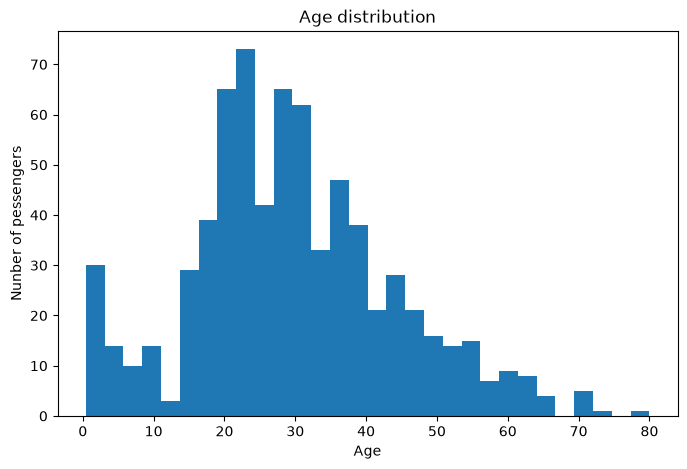

In [28]:
# Шаг 13. Делаю первые визуализации

plt.figure(figsize=(8,5))
plt.hist(train["Age"].dropna(), bins=30)


plt.xlabel("Age")
plt.ylabel("Nunber of pessengers")
plt.title("Age distribution")


plt.show()

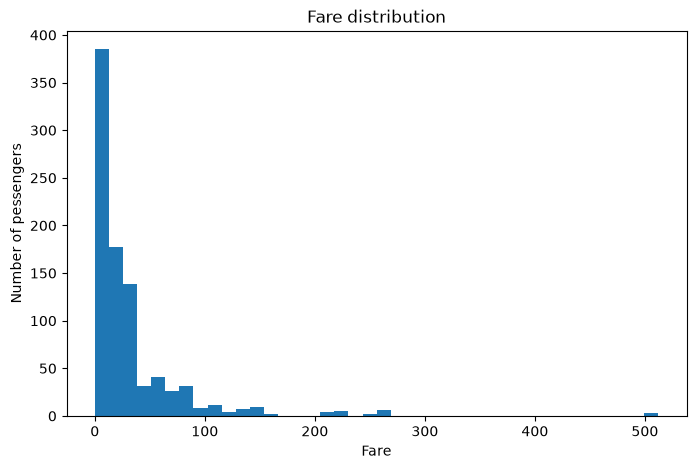

In [29]:
plt.figure(figsize=(8,5))
plt.hist(train["Fare"].dropna(), bins=40)


plt.xlabel("Fare")
plt.ylabel("Number of pessengers")
plt.title("Fare distribution") 


plt.show()

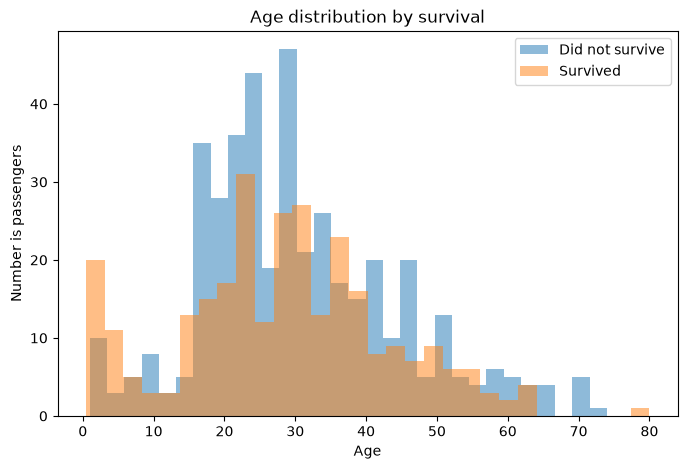

In [30]:
# Шаг 14. Смотрю на Age относительно target 

plt.figure(figsize=(8, 5))


plt.hist(
    train.loc[train["Survived"] == 0, "Age"].dropna(), #Это boolean indexing. Из train выбери строки, где Survived == 0, и из этих строк возьми колонку Age.
    bins=30,
    alpha=0.5,
    label="Did not survive"
)


plt.hist(
    train.loc[train["Survived"] == 1, "Age"].dropna(),
    bins=30,
    alpha=0.5,
    label="Survived"
)


plt.xlabel("Age")
plt.ylabel("Number is passengers")
plt.title("Age distribution by survival")
plt.legend()


plt.show()

In [31]:
## Этап 2. Basline

In [32]:
# Шаг 15 Отделяю признаки от target

X = train.drop(columns="Survived")
y = train["Survived"]

In [33]:
# Шаг 16. Первый baseline — DummyClassifier

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [34]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42 #фиксируем генератор случайных чисел
)

In [35]:
# Шаг 17. DummyClassifier Модель утанавливает нижнюю границу
# не использует признаки для принятия решения

dummy_model = DummyClassifier(
    strategy="most_frequent" #Всегда предсказывай самый распространённый класс в train.
)

In [36]:
#Шаг 18. Cross-validation baseline

dummy_scores = cross_val_score(
    dummy_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


In [37]:
# Смотрю результат

print("Fold scores:", dummy_scores)
print("Mean accuracy:", dummy_scores.mean()) #показывает среднее качество.
print("Std accuracy:", dummy_scores.std()) #показывает, насколько результат меняется между folds.

Fold scores: [0.61452514 0.61797753 0.61797753 0.61797753 0.61235955]
Mean accuracy: 0.6161634548992531
Std accuracy: 0.002324923639127706


In [38]:
#Этап 3. ML Pipeline

In [39]:
# Шаг 19. Создаю baseline на нескольких признаках


numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


In [40]:
#Шаг 20. Numeric preprocessing

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [41]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), #Есть пропуски в Age, ЛинРегу не нужен НАН, прост устойчив воспроизводим, менее чувствителен к выбросам чем mean
    ("scaler", StandardScaler())
])

In [42]:
# Шаг 21. Categorical preprocessing

from sklearn.preprocessing import OneHotEncoder

In [43]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")) #делает pipeline устойчивее к новым категориям.
])

In [44]:
# Шаг 22. ColumnTransformer. Теперь объединяем две ветки.

from sklearn.compose import ColumnTransformer

In [45]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [46]:
# Шаг 23. Добавляю LogisticRegression

from sklearn.linear_model import LogisticRegression

In [47]:
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42)
    )
])

In [48]:
# Шаг 24. Запуск LogisticRegression

logreg_scores = cross_val_score(
    logreg_pipeline,
    X,
    y,
    cv=cv,
    scoring = "accuracy",
)


print("Fold scores:", logreg_scores)
print("Mean accuracy:", logreg_scores.mean())
print("Std accuracy:", logreg_scores.std())

Fold scores: [0.78212291 0.80337079 0.79775281 0.78089888 0.82022472]
Mean accuracy: 0.7968740192078337
Std accuracy: 0.01456733331525481


In [49]:
## Experiment tracking

In [50]:
# Шаг 25. Реализация Experiment tracking

results = []


results.append({
    "experiment": "baseline_dummy",
    "model": "DommyClassifier",
    "features": "raw",
    "cv_folds": 5,
    "cv_mean": dummy_scores.mean(),
    "cv_std": dummy_scores.std(),
    "params": "strategy=most_frequent"
})


results.append({
    "experiment": "baseline_logreg",
    "model": "LogisticRegression",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": logreg_scores.mean(),
    "cv_std": logreg_scores.std(),
    "params": "max_iter=1000"
})


results_df = pd.DataFrame(results)

results_df.sort_values(
    "cv_mean",
    ascending=False
)

,experiment,model,features,cv_folds,cv_mean,cv_std,params
1,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000
0,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent


In [51]:
## Делаю честный benchmark классических моделей на тех же basic features и тех же 5 folds.

In [52]:
# Шаг 26. KNN

from sklearn.neighbors import KNeighborsClassifier

In [53]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=5)
    )
])

In [54]:
knn_scores = cross_val_score(
    knn_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", knn_scores)
print("Mean accuracy:", knn_scores.mean())
print("Std accuracy:", knn_scores.std())


results.append({
    "experiment": "baseline_knn",
    "model": "KneighborsClassifier",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": knn_scores.mean(),
    "cv_std": knn_scores.std(),
    "params": "n_neighbors=5"
})

Fold scores: [0.79888268 0.80337079 0.78651685 0.84269663 0.80337079]
Mean accuracy: 0.8069675475488042
Std accuracy: 0.018899929014766025


In [55]:
# Шаг 27. DecisionTree

from sklearn.tree import DecisionTreeClassifier

In [56]:
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42)
    )
])
    

In [57]:
tree_scores = cross_val_score(
    tree_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", tree_scores)
print("Mean accuracy:", tree_scores.mean())
print("Std accurecy:", tree_scores.std())


results.append({
    "experiment": "baseline_tree",
    "model": "DecisionTreeClassifier",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": tree_scores.mean(),
    "cv_std": tree_scores.std(),
    "params": "default"
})

Fold scores: [0.7877095  0.82022472 0.74719101 0.76404494 0.79775281]
Mean accuracy: 0.7833845960705543
Std accurecy: 0.025559118566769734


In [58]:
# Шаг 28. RandomForest

from sklearn.ensemble import RandomForestClassifier

In [59]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1)
    )
])

In [60]:
rf_scores = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_scores)
print("Mean accuracy:", rf_scores.mean())
print("Std accuracy:", rf_scores.std())


results.append({
    "experiment": "baseline_random_forest",
    "model": "RandomForestClassifier",
    "features": "basic",
    "cv_folds": 5,
    "cv_mean": rf_scores.mean(),
    "cv_std": rf_scores.std(),
    "params":"n_estimators=300"
})

Fold scores: [0.83798883 0.79213483 0.78089888 0.82022472 0.8258427 ]
Mean accuracy: 0.8114179900822297
Std accuracy: 0.02142380221058392


In [61]:
# Шаг 29. Обновляю таблицу экспериментов

results_df = pd.DataFrame(results)

results_df.sort_values(
    "cv_mean",
    ascending=False
).reset_index(drop=True)    

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
1,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5
2,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000
3,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default
4,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent


In [62]:
# Шаг 30. Добавляю еще полезную метрику (разницу относительно Dummy baseline)

dummy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df.sort_values(
    "cv_mean",
    ascending=False
).reset_index(drop=True)

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
2,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
3,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
4,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [63]:
## Feature Engineering


In [64]:
# Шаг 31. FamilySize

train["FamilySize"] = (train["SibSp"] + train["Parch"] +1)  #FamilySize = количество людей семейной группы, включая самого пассажира

In [65]:
train [["SibSp", "Parch", "FamilySize"]].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [66]:
# Шаг 32. Исследую FamilySize

train["FamilySize"].value_counts().sort_index()  #Выбираем колонку,считаем частоты, сортируем (по самому значению FamilySize)

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

In [67]:
# Шаг 33. Проверяею связь FamilySize с target

train.groupby("FamilySize")["Survived"].agg(["count", "mean"])

,count,mean
FamilySize,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


In [68]:
#Вывод: размер семьи связан с целевой переменной нелинейно.
#Пассажиры, путешествующие в одиночку, имеют более низкую долювыживших, чем пассажиры в семьях размером 2–4 человека.
#Для больших семей наблюдений существенно меньше, поэтому оценки для этих групп менее надежны.

#Гипотеза: признаки `FamilySize` и производный от него `IsAlone`могут улучшить качество модели. Эффект необходимо проверить на кросс-валидации.

In [69]:
# Шаг 34. Создаю IsAlone

train["IsAlone"] = (train["FamilySize"] ==1).astype(int)

In [70]:
train[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [71]:
# Шаг 35. Проверяю связь IsAlone с target

train.groupby("IsAlone")["Survived"].agg(["count", "mean"])

,count,mean
IsAlone,,
0,354,0.505650
1,537,0.303538


In [72]:
# Шаг 36. Ablation experiment: Family features

In [73]:
# Шаг 36.1. Создаём новый X

X_family = train.drop(columns="Survived")


print(X_family.shape)
print("FamilySize" in X_family.columns)
print("IsAlone" in X_family.columns)

(891, 13)
True
True


In [74]:
# Шаг 36.2. Обновляю список numeric features

numeric_features_family = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]


categorical_features_family = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [75]:
# Шаг 36.3. Создаю новый preprocessor. Не меняею старый preprocessor, потому что он относится к baseline.

preprocessor_family = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_family),
    ("cat", categorical_pipeline, categorical_features_family)
])

In [76]:
# Шаг 36.4. Создаю Random Forest

rf_family_pipeline = Pipeline ([
    ("preprocessor", preprocessor_family),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
    )
])

In [77]:
# Шаг 37. Запускаю ablation experiment

rf_family_scores = cross_val_score(
    rf_family_pipeline,
    X_family,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_family_scores)
print("Mean accuracy;", rf_family_scores.mean())
print("Std accuracy:", rf_family_scores.std())

Fold scores: [0.82681564 0.78089888 0.78089888 0.82022472 0.83707865]
Mean accuracy; 0.8091833532107213
Std accuracy: 0.02371067404450577


In [78]:
# Шаг 38. Анализирую ablation experiment

# Эксперимент показал: при текущем preprocessing, текущих параметрах Random Forest и данной 5-fold CV добавление FamilySize и IsAlone поверх basic features не улучшило средний CV score.

In [79]:
# Шаг 39. Записываю эксперимент в tracking

results.append({
    "experiment": "rf_family_features",
    "model": "RandomForestClassifier",
    "features": "basic+FAmilySize+IsAlone",
    "cv_folds": 5,
    "cv_mean": rf_family_scores.mean(),
    "cv_std": rf_family_scores.std(),
    "params": "n_estimators=300"
})

In [80]:
# Пересоздаю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))
results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
1,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300
2,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5
3,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000
4,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default
5,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent


In [81]:
# Шаг 40. Добавляю сравнение именно с RF baseline

rf_baseline_mean = rf_scores.mean()


print("RF baseline:", rf_baseline_mean)
print("RF = family:", rf_family_scores.mean())
print("Difference:", rf_family_scores.mean() - rf_baseline_mean)

RF baseline: 0.8114179900822297
RF = family: 0.8091833532107213
Difference: -0.0022346368715083775


In [82]:
# Шаг 41. Feature Engineering: Name -> Title

In [83]:
train["Name"].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: str

In [84]:
train["Name"].nunique()


891

In [85]:
# Шаг 41.1. Исследую структуру Name

train[["Name"]].head(20)

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"
5,"Moran, Mr. James"
6,"McCarthy, Mr. Timothy J"
7,"Palsson, Master. Gosta Leonard"
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)"
9,"Nasser, Mrs. Nicholas (Adele Achem)"


In [86]:
print("Rows:", len(train))          #Возвращает количество строк DataFrame
print("Unique names:", train["Name"].nunique())  #Считает количество уникальных значений

Rows: 891
Unique names: 891


In [87]:
# Шаг 41.2. Извлекаю Title

train["Title"] = (
    train["Name"]
    .str.extract(r",\s*([^.]*)\.", expand=False)
    .str.strip()
)

#.str.extract() извлекает из каждой строки часть, соотв-щего регуляр выражению
# , ищет запятую; \s означает whitespace — пробел, tab и тд; * ищет пробелы после запятой; ([^.]*) () создают capturing group, [^.] любой символ кроме запятой, * сколько угодно таких символов; \. означает буквальную точку
# expand=False говорит pandas вернуть Series, а не отдельный DataFrame

In [88]:
# Шаг 41.3. Проверяю извлечение

train[["Name","Title"]].head(20)

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [89]:
train["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [90]:
# Шаг 42. Объединяю редкие Title

In [91]:
# Шаг 42.1. Определяю основные категории

common_titles = [
    "Mr",
    "Miss",
    "Mrs",
    "Master"
]

In [92]:
# Шаг 42.2. Создаю TitleGrouped

train["TitleGrouped"] = (train["Title"].where(train["Title"].isin(common_titles), "Rare"))

In [93]:
# Шаг 42.3. Проверяю результат

train[["Name", "Title", "TitleGrouped"]].head(20)

train["TitleGrouped"].value_counts()

TitleGrouped
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

In [94]:
train["TitleGrouped"].value_counts().sum()

np.int64(891)

In [95]:
# Шаг 43. Исследую связь TitleGrouped с Survived

train.groupby("TitleGrouped")["Survived"].agg(["count", "mean"]).sort_values("mean", ascending=False)


,count,mean
TitleGrouped,,
Mrs,125,0.792000
Miss,182,0.697802
Master,40,0.575000
Rare,27,0.444444
Mr,517,0.156673


In [96]:
# Шаг 44. Анализирую TitleGrouped

#Гипотеза такая: TitleGrouped может дать модели дополнительную информацию поверх уже существующих Sex, Age, Pclass и других признаков.


In [97]:
# Шаг 45. Готовлю честный ablation experiment для TitleGrouped

In [98]:
# Шаг 45.1. Создаю отдельный X_title

numeric_features_title = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features_title = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGrouped"
]


In [99]:
# Шаг 45.2. Формирую X_title
title_features = (numeric_features_title + categorical_features_title)

X_title = train[title_features].copy()

In [100]:
# Шаг 45.3. Проверяю экспериментальный датасет

print(X_title.shape)
print(X_title.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'TitleGrouped']


In [101]:
assert "TitleGrouped" in X_title.columns
assert "FamilySize" not in X_title.columns
assert "IsAlone" not in X_title.columns
assert "Title" not in X_title.columns

In [102]:
# Шаг 45.4. Создаю preprocessing

preprocessor_title = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_title),
    ("cat", categorical_pipeline, categorical_features_title)
])


print(X_title.shape)
print(X_title.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'TitleGrouped']


In [103]:
# Шаг 46. Random Forest + TitleGrouped

rf_title_pipeline = Pipeline([
    ("preprocessor", preprocessor_title),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
        )
    )
])

In [104]:
# Шаг 47. Запускаю 5-fold CV

rf_title_scores = cross_val_score(
    rf_title_pipeline,
    X_title,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores", rf_title_scores)
print("Mean accuracy", rf_title_scores.mean())
print("Std accuracy", rf_title_scores.std())

Fold scores [0.82681564 0.79775281 0.78651685 0.80898876 0.8258427 ]
Mean accuracy 0.8091833532107213
Std accuracy 0.015702845238477328


In [105]:
# Шаг 48. Сравниваю с baseline

rf_baseline_mean = rf_scores.mean()
rf_title_mean = rf_title_scores.mean()


title_difference = (rf_title_mean - rf_baseline_mean)


print("RF baseline:", rf_baseline_mean)
print("RF + TitleGrouped:", rf_title_mean)
print("Difference:", title_difference)

RF baseline: 0.8114179900822297
RF + TitleGrouped: 0.8091833532107213
Difference: -0.0022346368715083775


In [106]:
# Шаг 49. Записываю эксперимент

results.append({
    "experiment": "rf_title_grouped",
    "model": "RandomForestClassifier",
    "features": "basic+TitleGrouped",
    "cv_folds": 5,
    "cv_mean": rf_title_scores.mean(),
    "cv_std": rf_title_scores.std(),
    "params": "n_estimators=300"
})

In [107]:
# Пересобираю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df["imrpovement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,imrpovement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
2,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
3,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
4,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
5,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
6,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [108]:
# Шаг 50. Следующая feature-гипотеза Cabin -> Deck

train["Cabin"].head(20)

0      NaN
1      C85
2      NaN
3     C123
4      NaN
5      NaN
6      E46
7      NaN
8      NaN
9      NaN
10      G6
11    C103
12     NaN
13     NaN
14     NaN
15     NaN
16     NaN
17     NaN
18     NaN
19     NaN
Name: Cabin, dtype: str

In [109]:
print("Missing Cabin:", train["Cabin"].isna().sum())
print("Missing rate:", train ["Cabin"].isna().mean())

Missing Cabin: 687
Missing rate: 0.7710437710437711


In [110]:
train["Cabin"].value_counts().head(20)

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
F2             3
D              3
C22 C26        3
C123           2
D33            2
C52            2
B28            2
C83            2
F G73          2
D26            2
B58 B60        2
C2             2
E33            2
F4             2
D36            2
Name: count, dtype: int64

In [111]:
# Шаг 51. Feature Engineering: Cabin -> Deck

In [112]:
# Шаг 51.1. Создаю Deck

train["Deck"] = (train["Cabin"].str[0].fillna("Unknown"))

In [113]:
# Шаг 51.2. Проверяю результат

train[["Cabin", "Deck"]].head(20)

,Cabin,Deck
0,NaN,Unknown
1,C85,C
2,NaN,Unknown
3,C123,C
4,NaN,Unknown
5,NaN,Unknown
6,E46,E
7,NaN,Unknown
8,NaN,Unknown
9,NaN,Unknown


In [114]:
train["Deck"].value_counts(dropna=False)

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [115]:
print("Missing Deck:", train["Deck"].isna().sum())

Missing Deck: 0


In [116]:
# Шаг 51.3. Проверяю связь Deck с target

train.groupby("Deck")["Survived"].agg(["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
Deck,,
D,33,0.757576
E,32,0.750000
B,47,0.744681
F,13,0.615385
C,59,0.593220
G,4,0.500000
A,15,0.466667
Unknown,687,0.299854
T,1,0.000000


In [117]:
pd.crosstab(train["Deck"], train["Pclass"], normalize="index").round(3)

Pclass,1,2,3
Deck,,,
A,1.000,0.000,0.000
B,1.000,0.000,0.000
C,1.000,0.000,0.000
D,0.879,0.121,0.000
E,0.781,0.125,0.094
F,0.000,0.615,0.385
G,0.000,0.000,1.000
T,1.000,0.000,0.000
Unknown,0.058,0.245,0.697


In [118]:
# Шаг 52. Проверяю информативность пропуска Cabin
# Даёт ли информация «каюта известна / неизвестна» дополнительный predictive signal поверх уже имеющегося Pclass?

In [119]:
# Шаг 52.1. Создаю CabinKnown

train["CabinKnown"] = (train["Cabin"].notna().astype(int))

In [120]:
# Шаг 52.2. Проверяю результат

train[["Cabin", "Deck", "CabinKnown"]].head(20)

,Cabin,Deck,CabinKnown
0,NaN,Unknown,0
1,C85,C,1
2,NaN,Unknown,0
3,C123,C,1
4,NaN,Unknown,0
5,NaN,Unknown,0
6,E46,E,1
7,NaN,Unknown,0
8,NaN,Unknown,0
9,NaN,Unknown,0


In [121]:
train["CabinKnown"].value_counts()

CabinKnown
0    687
1    204
Name: count, dtype: int64

In [122]:
# Проперяю пропуски

print("Missing CabinKnown:", train["CabinKnown"].isna().sum())

Missing CabinKnown: 0


In [123]:
# Шаг 52.3. Проверяю связь CabinKnown с Survived

train.groupby("CabinKnown")["Survived"].agg(["count", "mean"])

,count,mean
CabinKnown,,
0,687,0.299854
1,204,0.666667


In [124]:
# Шаг 52.4. Проверяю CabinKnown внутри каждого класса

train.groupby(["Pclass", "CabinKnown"])["Survived"].agg(["count", "mean"])

count      mean
Pclass CabinKnown                 
1      0              40  0.475000
       1             176  0.664773
2      0             168  0.440476
       1              16  0.812500
3      0             479  0.235908
       1              12  0.500000

In [125]:
# Шаг 53. Тестирую CabinKnown через CV 

In [126]:
# Шаг 53.1. Создаю признаки эксперимента

numeric_features_cabin_known = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "CabinKnown"
]


categorical_features_cabin_known = [
    "Pclass",
    "Sex",
    "Embarked"
]


cabin_known_features = (numeric_features_cabin_known + categorical_features_cabin_known)

In [127]:
X_cabin_known = train[cabin_known_features].copy()

In [128]:
# Шаг 53.2. Проверяю, что в эксперимент не попали лишние признаки

print(X_cabin_known.shape)
print(X_cabin_known.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'CabinKnown', 'Pclass', 'Sex', 'Embarked']


In [129]:
# Добавляю sanity checks:

assert "CabinKnown" in X_cabin_known.columns

assert "Deck" not in X_cabin_known.columns
assert "TitleGrouped" not in X_cabin_known.columns
assert "FamilySize" not in X_cabin_known.columns
assert "IsAlone" not in X_cabin_known.columns

In [130]:
# Шаг 53.3. Создаю отдельный preprocessing

preprocessor_cabin_known = ColumnTransformer ([
    ("num", numeric_pipeline, numeric_features_cabin_known),
    ("cat", categorical_pipeline, categorical_features_cabin_known)
])


In [131]:
# Шаг 53.4. Создаю тот же Random Forest

rf_cabin_known_pipeline = Pipeline([
    ("preprocessor", preprocessor_cabin_known),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    )
    )
])

In [132]:
# Шаг 53.5. Запускаю тот же 5-fold CV

rf_cabin_known_scores = cross_val_score(
    rf_cabin_known_pipeline,
    X_cabin_known,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_cabin_known_scores)
print("Mean accuracy:", rf_cabin_known_scores.mean())
print("Std accuracy:", rf_cabin_known_scores.std())

Fold scores: [0.84357542 0.80337079 0.76966292 0.81460674 0.82022472]
Mean accuracy: 0.8102881175067477
Std accuracy: 0.02418134419893537


In [133]:
# Шаг 53.6. Сразу сравниваю с baseline

rf_baseline_mean = rf_scores.mean()
rf_cabin_known_mean = rf_cabin_known_scores.mean()

cabin_known_difference = (rf_cabin_known_mean - rf_baseline_mean)


print("RF baseline:", rf_baseline_mean)
print("RF + CabinKnown:", rf_cabin_known_mean)
print("Difference:", cabin_known_difference)


RF baseline: 0.8114179900822297
RF + CabinKnown: 0.8102881175067477
Difference: -0.0011298725754820271


In [134]:
# Шаг 54. Фиксирую результат CabinKnown

In [135]:
# Шаг 54.1. Интерпретирую результат
# Сравниваю поностью
# ----------------------------------------------
#                         CV mean     CV std
# RF baseline              0.811418    0.021424
# RF + CabinKnown          0.810288    0.024181
#
# Difference              -0.001130
# ----------------------------------------------
# Вывод: Добавление CabinKnown к текущему набору baseline-признаков не улучшило среднюю 5-fold CV accuracy Random Forest.

In [136]:
# Шаг 54.2. Сохраняю эксперимент в tracking

results.append({
    "experiment": "rf_cabin_known",
    "model": "RandomForestClassifier",
    "features": "basic+CabinKnown",
    "cv_folds": 5,
    "cv_mean": rf_cabin_known_scores.mean(),
    "cv_std": rf_cabin_known_scores.std(),
    "params": "n_estimators=300"
})

In [137]:
# Пересобираю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
2,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
3,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
4,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
5,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
6,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
7,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [138]:
# Шаг 55. Тестирую Deck отдельно
# Теперь проверяю вторую гипотезу: Возможно, бинарного CabinKnown недостаточно, а модели полезна конкретная палуба.

In [139]:
# Шаг 55.1. Создаю набор признаков

numeric_features_deck = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features_deck = [  # Deck сюда, потому что числового расстояния у признака в постановке нет
    "Pclass",
    "Sex",
    "Embarked",
    "Deck"
]

In [140]:
# Шаг 55.2. Формирую X_deck

deck_features = (numeric_features_deck + categorical_features_deck)

X_deck = train[deck_features].copy()

In [141]:
# Шаг 55.3. Проверяю состав данных

print(X_deck.shape)
print(X_deck.columns.tolist())

(891, 8)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Deck']


In [142]:
# Добавляю проверки

assert "Deck" in X_deck.columns

assert "CabinKnown" not in X_deck.columns
assert "TitleGrouped" not in X_deck.columns
assert "FamilySize" not in X_deck.columns
assert "IsAlone" not in X_deck.columns

In [143]:
# Шаг 55.4. Создаю preprocessing

preprocessor_deck = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_deck),
    ("cat", categorical_pipeline, categorical_features_deck)
])

In [144]:
# Шаг 55.5. Создаю Random Forest pipeline

rf_deck_pipeline = Pipeline([
    ("preprocessor", preprocessor_deck),
    ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [145]:
# Шаг 55.6. Запускаю 5-fold CV

rf_deck_scores = cross_val_score(
    rf_deck_pipeline,
    X_deck,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_deck_scores)
print("Mean accuracy:", rf_deck_scores.mean())
print("Std accuracy:", rf_deck_scores.std())

Fold scores: [0.83798883 0.76966292 0.78651685 0.79775281 0.8258427 ]
Mean accuracy: 0.8035528215429038
Std accuracy: 0.025119978756975997


In [146]:
# Шаг 55.7. Сравниваю с baseline

rf_baseline_mean = rf_scores.mean()
rf_deck_mean = rf_deck_scores.mean()

deck_difference = (rf_deck_mean - rf_baseline_mean)

print("RF baseline:", rf_baseline_mean)
print("RF + Deck:", rf_deck_mean)
print("Difference:", deck_difference)

RF baseline: 0.8114179900822297
RF + Deck: 0.8035528215429038
Difference: -0.00786516853932595


In [147]:
# Шаг 56. Анализирую результат Deck

In [148]:
# Шаг 56.1. Сравниваю с baseline
# ----------------------------------------------
#                         CV mean     CV std
# RF baseline              0.811418    0.021424
# RF + Deck                0.803553    0.025120
# 
# Difference              -0.007865
# ----------------------------------------------
# Переведу разницу в процентные пункты
# То есть:
# -------------------------
# Baseline RF       81.14%
# RF + Deck         80.36%
# -------------------------
# Это самое заметное снижение среди последних feature-экспериментов. При этом std тоже вырос
# 
# По текущему CV Deck не даёт оснований заменять baseline.

In [149]:
# Шаг 56.2. Интерпретирую результат
# Вывод: Deck связан с Survived в EDA, но при добавлении к текущему baseline-набору признаков средняя 5-fold CV accuracy Random Forest снизилась с 0.8114 до 0.8036

In [150]:
# Шаг 56.3. Сохраняю эксперимент

results.append({
    "experiment": "rf_deck",
    "model": "RandomForestClassifier",
    "features": "basic+Deck",
    "cv_folds": 5,
    "cv_mean": rf_deck_scores.mean(),
    "cv_std": rf_deck_scores.std(),
    "params": "n_estimators=300"
})

In [151]:
# Пересобираю таблицу

results_df = pd.DataFrame(results)

dummy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
1,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
2,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
3,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
4,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
5,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300,0.187389
6,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
7,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
8,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [152]:
# Шаг 57. Подвожу промежуточный итог Feature Engineering

# Прежде чем генерировать следующие признаки, я останавливаюсь и сравниваю уже проведённые эксперименты:
# ----------------------------------------------------------
# Experiment                  CV mean      Δ vs RF baseline
# 
# RF baseline                 0.811418          —
# + CabinKnown                0.810288      -0.001130
# + FamilySize + IsAlone      0.809183      -0.002235
# + TitleGrouped              0.809183      -0.002235
# + Deck                      0.803553      -0.007865
# ----------------------------------------------------------
# Лучший RF остаётся: basic Random Forest → 0.811418

In [153]:
# Шаг 58. Исследую Ticket

In [154]:
# Шаг 58.1. Смотрю примеры Ticket

train[["Ticket", "Survived"]].head(20)

,Ticket,Survived
0,A/5 21171,0
1,PC 17599,1
2,STON/O2. 3101282,1
3,113803,1
4,373450,0
5,330877,0
6,17463,0
7,349909,0
8,347742,1
9,237736,1


In [155]:
# Шаг 58.2. Проверяю cardinality

print("Rows:", len(train))
print("Unique tickets:", train["Ticket"].nunique())
print("Ticket uniqueness ratio:", train["Ticket"].nunique() / len(train))

Rows: 891
Unique tickets: 681
Ticket uniqueness ratio: 0.7643097643097643


In [156]:
# Шаг 58.3. Проверяю, сколько пассажиров приходится на билет

ticket_counts = (train["Ticket"].value_counts())
ticket_counts.head(20)

Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
349909          4
347077          4
19950           4
W./C. 6608      4
4133            4
LINE            4
113781          4
17421           4
PC 17757        4
113760          4
2666            4
347742          3
Name: count, dtype: int64

In [157]:
# Шаг 58.4. Создаю гипотезу TicketGroupSize

ticket_counts.value_counts().sort_index()

count
1    547
2     94
3     21
4     11
5      2
6      3
7      3
Name: count, dtype: int64

In [158]:
# Шаг 59. Создаю TicketGroupSize

In [159]:
# Шаг 59.1. Создаю размер группы по билету

train["TicketGroupSize"] = (train["Ticket"].map(train["Ticket"].value_counts()))

In [160]:
# Шаг 59.2. Проверяю результат

train[["Ticket", "TicketGroupSize"]].head(20)

,Ticket,TicketGroupSize
0,A/5 21171,1
1,PC 17599,1
2,STON/O2. 3101282,1
3,113803,2
4,373450,1
5,330877,1
6,17463,1
7,349909,4
8,347742,3
9,237736,2


In [161]:
train["TicketGroupSize"].value_counts().sort_index()

TicketGroupSize
1    547
2    188
3     63
4     44
5     10
6     18
7     21
Name: count, dtype: int64

In [162]:
# Шаг 59.3. Проверяю корректность признака

print("Missing:", train["TicketGroupSize"].isna().sum())
print("Min:", train["TicketGroupSize"].min())
print("Max:", train["TicketGroupSize"].max())

Missing: 0
Min: 1
Max: 7


In [163]:
# Шаг 60. Проверяю связь TicketGroupSize с Survived

In [164]:
# Шаг 60.1. Считаю survival rate

train.groupby("TicketGroupSize")["Survived"].agg(["count", "mean"])

,count,mean
TicketGroupSize,,
1,547,0.297989
2,188,0.574468
3,63,0.698413
4,44,0.500000
5,10,0.000000
6,18,0.000000
7,21,0.238095


In [165]:
# Здесь проверяю гипотезу: Связано ли путешествие одному или в группе с вероятностью выживания?

In [166]:
# Шаг 60.2. Сравниваю TicketGroupSize и FamilySize

train [[
    "Ticket",
    "SibSp",
    "Parch",
    "FamilySize",
    "TicketGroupSize"
]].head(30)

,Ticket,SibSp,Parch,FamilySize,TicketGroupSize
0,A/5 21171,1,0,2,1
1,PC 17599,1,0,2,1
2,STON/O2. 3101282,0,0,1,1
3,113803,1,0,2,2
4,373450,0,0,1,1
5,330877,0,0,1,1
6,17463,0,0,1,1
7,349909,3,1,5,4
8,347742,0,2,3,3
9,237736,1,0,2,2


In [167]:
# Cчитаю корреляцию

train[[
    "FamilySize",
    "TicketGroupSize"
]].corr()

,FamilySize,TicketGroupSize
FamilySize,1.000000,0.748487
TicketGroupSize,0.748487,1.000000


In [168]:
# Шаг 61. Проверяю TicketGroupSize на data leakage

In [169]:
# Шаг 61.1. Разбираюсь, где потенциальная проблема
# Информация о наличии Passenger C из validation уже повлияла на feature в training (cross-validation leakage)
# Важно: это не target leakage — Survived мы не использовали. Но граница train/validation всё равно нарушена. 

In [170]:
# Шаг 61.2. Определяю правильную архитектуру
# 
# Мне нужна такая структура:
#
# FIT
# │
# ├── получаю training data
# ├── считаю Ticket frequencies
# └── сохраняю mapping
#        ↓
# TRANSFORM
# │
# ├── получаю новые данные
# ├── использую сохранённый mapping
# └── НЕ пересчитываю статистику
#
# Вывод: нужно сипользовать sklearn.Pipeline

In [171]:
# Шаг 62. Создаю sklearn-transformer для TicketGroupSize

In [172]:
# Шаг 62.1. Импортирую базовые классы sklearn

from sklearn.base import BaseEstimator, TransformerMixin

In [173]:
# BaseEstimator даёт нашему классу стандартное поведение sklearn estimator. Это важно для совместимости с Pipeline, cloning и работы с параметрами.
# TransformerMixin предоставляет стандартную transformer-семантику sklearn, в частности fit_transform() на основе реализованных нами fit() и transform().

In [187]:
# Шаг 62.2. Создаю класс

class TicketGroupSizeTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.ticket_counts_ = (X["Ticket"].value_counts())

        return self

    
    def transform(self,X):
        X = X.copy()
        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1).astype(int))

        return X

In [188]:
# Шаг 63. Проверяю transformer вручную

In [194]:
#Шаг 63.1. Создаю маленький искусственный train

ticket_train_example = pd.DataFrame({
    "Ticket": [
        "AAA",
        "AAA",
        "BBB",
        "CCC",
        "CCC",
        "CCC"
    ]
})
                                     

In [190]:
# Шаг 63.2. Создаю искусственный validation

ticket_valid_example = pd.DataFrame ({
    "Ticket": [
        "AAA",
        "BBB",
        "DDD"
    ]
})

In [196]:
# Шаг 63.3. Обучаю transformer только на train

ticket_transformer = TicketGroupSizeTransformer()
ticket_transformer.fit(ticket_train_example)

Name,Type,Value
ticket_counts_,"Series[int64](3,)","Ticket CCC ..., dtype: int64"


In [192]:
ticket_transformer.ticket_counts_

Ticket
CCC    3
AAA    1
BBB    1
Name: count, dtype: int64

In [195]:
ticket_train_example

,Ticket
0,AAA
1,AAA
2,BBB
3,CCC
4,CCC
5,CCC


In [197]:
ticket_transformer = TicketGroupSizeTransformer()

ticket_transformer.fit(ticket_train_example)

ticket_transformer.ticket_counts_

Ticket
CCC    3
AAA    2
BBB    1
Name: count, dtype: int64

In [198]:
# Шаг 63.4. Преобразую validation

ticket_transformer.transform(ticket_valid_example)

,Ticket,TicketGroupSize
0,AAA,2
1,BBB,1
2,DDD,1


In [199]:
# Шаг 64. Встраиваю TicketGroupSizeTransformer в ML pipeline

In [203]:
# Шаг 64.1. Создаю исходный набор признаков

ticket_input_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked",
    "Ticket"
]

X_ticket = train[ticket_input_features].copy()

In [204]:
# Шаг 64.2. Проверяю входные данные

print(X_ticket.shape)
print(X_ticket.columns.tolist)

(891, 8)
<bound method IndexOpsMixin.tolist of Index(['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket'], dtype='str')>


In [205]:
assert "Ticket" in X_ticket.columns
assert "TicketGroupSize" not in X_ticket.columns

In [206]:
# Шаг 64.3. Определяю признаки после transformer

numeric_features_ticket = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize"
]

In [207]:
categorical_features_ticket = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [209]:
# Шаг 64.4. Создаю preprocessing

preprocessor_ticket = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_ticket),
    ("cat", categorical_pipeline, categorical_features_ticket)
])

In [211]:
# Шаг 64.5. Собираю полный pipeline

rf_ticket_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", preprocessor_ticket),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=43,
        n_jobs=-1
        )
    )
])

In [212]:
# Шаг 64.6. Разбираю, что произойдёт внутри CV

cross_val_score(
    rf_ticket_pipeline,
    X_ticket,
    y,
    cv=cv,
    scoring="accuracy"
)

array([0.83798883, 0.79213483, 0.79775281, 0.79775281, 0.85393258])

In [213]:
# Шаг 64.7. Проверяю pipeline до CV

rf_ticket_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [214]:
# Шаг 65. Запускаю leakage-safe CV для TicketGroupSize

In [218]:
# Шаг 65.1. Запускаю 5-fold cross-validation

rf_ticket_scores = cross_val_score(
    rf_ticket_pipeline,
    X_ticket,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_ticket_scores)
print("Mean accuracy:", rf_ticket_scores.mean())
print("Std accuracy:", rf_ticket_scores.std())

Fold scores: [0.83798883 0.79213483 0.79775281 0.79775281 0.85393258]
Mean accuracy: 0.8159123721047015
Std accuracy: 0.025130926325444957


In [224]:
# Шаг 65.2. Сравниваю результат с baseline

rf_baseline_mean = rf_scores.mean()
rf_ticket_mean = rf_ticket_scores.mean()

ticket_difference = (rf_ticket_mean - rf_baseline_mean)

print("RF baseline:", rf_baseline_mean)
print("RF + TicketGroupSize:", rf_ticket_mean)
print("Difference:", ticket_difference)

RF baseline: 0.8114179900822297
RF + TicketGroupSize: 0.8159123721047015
Difference: 0.004494382022471766


In [225]:
# Шаг 66. Интерпретирую TicketGroupSize

In [226]:
# Шаг 66.1. Сравниваю результаты
# Вывод:
# Leakage-safe TicketGroupSize улучшил среднюю 5-fold CV accuracy Random Forest с 0.8114 до 0.8159. 
# Прирост составляет +0.0045, но он небольшой относительно межфолдового разброса, поэтому признак рассматриваю как перспективный и продолжаю проверять в следующих экспериментах.


In [228]:
# Шаг 66.2. Смотрю на отдельные folds
# Результаты между folds заметно различаются:
# min ≈ 0.792
# max ≈ 0.854

In [229]:
# Шаг 67. Фиксирую эксперимент

In [231]:
# Шаг 67.1. Добавляю результат в experiment tracking

results.append({
    "experiment": "rf_ticket_group_size",
    "model": "RandomForestClassifier",
    "features": "basic+TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": rf_ticket_scores.mean(),
    "cv_std": rf_ticket_scores.std(),
    "params": "n_estimators=300"
})

In [234]:
# Шаг 67.2. Пересобираю таблицу результатов

results_df = pd.DataFrame(results)

dimmy_mean = dummy_scores.mean()

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_mean)

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,5,0.815912,0.025131,n_estimators=300,0.199749
1,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
2,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
3,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
4,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
5,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
6,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300,0.187389
7,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
8,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221
9,baseline_dummy,DommyClassifier,raw,5,0.616163,0.002325,strategy=most_frequent,0.000000


In [ ]:
# Шаг 68. Сравниваю все engineered features
#
# По  результатам:
# ----------------------------------------------------------
# Эксперимент	              CV accuracy    Δ к RF baseline
# RF + TicketGroupSize	       0.815912	       +0.004494
# RF baseline	               0.811418	         —
# RF + CabinKnown	           0.810288	       −0.001130
# RF + FamilySize + IsAlone	   0.809183	       −0.002235
# RF + TitleGrouped	           0.809183	       −0.002235
# RF + Deck	                   0.803553	       −0.0078653

In [235]:
# Шаг 69. Проверяю комбинацию лучших признаков
# Самая интересная пара: FamilySize + TicketGroupSize

In [236]:
# Шаг 70. Создаю единый FeatureEngineeringTransformer

In [238]:
# Шаг 70.1. Создаю новый transformer

class FeatureEngineeringTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.ticket_counts_ = (X["Ticket"].value_counts())

        return self


    def transform(self, X):
        X = X.copy()
        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)
        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1).astype(int))

        return X

In [240]:
# Шаг 71. Проверяю новый transformer отдельно

In [249]:
# Шаг 71.1. Создаю небольшой пример

feature_train_example = pd.DataFrame({
    "SibSp": [1,0,2,0],
    "Parch": [2,0,1,0],
    "Ticket": [
        "AAA",
        "AAA",
        "BBB",
        "CCC"
    ]
})

In [250]:
# Шаг 71.2. Создаю transformer

feature_transformer = (FeatureEngineeringTransformer())

In [251]:
# Шаг 71.3. Обучаю его

feature_transformer.fit(feature_train_example)

Name,Type,Value
ticket_counts_,"Series[int64](3,)","Ticket AAA ..., dtype: int64"


In [252]:
# Шаг 71.4. Преобразую данные

feature_train_transformed = (feature_transformer.transform(feature_train_example))

feature_train_transformed

,SibSp,Parch,Ticket,FamilySize,TicketGroupSize
0,1,2,AAA,4,2
1,0,0,AAA,1,2
2,2,1,BBB,4,1
3,0,0,CCC,1,1


In [254]:
# Шаг 71.5. Добавляю автоматические sanity checks

assert (feature_train_transformed.loc[0, "FamilySize"] == 4)
assert (feature_train_transformed.loc[0, "TicketGroupSize"] == 2)
assert (feature_train_transformed.loc[2, "FamilySize"] == 4)
assert (feature_train_transformed.loc[2, "TicketGroupSize"] == 1)

In [255]:
# Шаг 72. Собираю эксперимент FamilySize + TicketGroupSize

In [256]:
# Шаг 72.1. Формирую raw input

family_ticket_input_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked",
    "Ticket"
]

X_family_ticket = train[family_ticket_input_features].copy()

In [258]:
assert "FamilySize" not in X_family_ticket.columns
assert "TicketGroupSize" not in X_family_ticket.columns

In [259]:
# Шаг 72.2 Определяю features

numeric_features_family_ticket = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "TicketGroupSize"
]


categorical_features_family_ticket = [
    "Pclass",
    "Sex",
    "Embarked"
]

In [260]:
# Шаг 72.3. Создаю preprocessing

preprocessor_family_ticket = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_family_ticket),
    ("cat", categorical_pipeline, categorical_features_family_ticket)
])

In [261]:
# Шаг 72.4. Собираю полный pipeline

rf_family_ticket_pipeline = Pipeline([
    ("feature_engineering", FeatureEngineeringTransformer()),
    ("preprocessor", preprocessor_family_ticket),
    ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [262]:
# Шаг 72.5. Проверяю структуру

rf_family_ticket_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

In [263]:
# Шаг 73. Тестирую FamilySize + TicketGroupSize на 5-fold CV

In [266]:
# Шаг 73.1. Запускаю cross-validation

rf_family_ticket_scores = cross_val_score(
    rf_family_ticket_pipeline,
    X_family_ticket,
    y,
    cv=cv,
    scoring="accuracy"
)


print("Fold scores:", rf_family_ticket_scores)
print("Mean accuracy:",  rf_family_ticket_scores.mean())
print("Std accuracy:",  rf_family_ticket_scores.std())

Fold scores: [0.82681564 0.78651685 0.79213483 0.80337079 0.84831461]
Mean accuracy: 0.8114305442219573
Std accuracy: 0.02304392112793486


In [268]:
# Шаг 73.2. Сравниваю сразу три эксперимента

print("RF baseline:", rf_scores.mean())
print("RF + TicketGroupSize:", rf_ticket_scores.mean())
print("RF + FamilySize + TicketGroupSize:", rf_family_ticket_scores.mean())

RF baseline: 0.8114179900822297
RF + TicketGroupSize: 0.8159123721047015
RF + FamilySize + TicketGroupSize: 0.8114305442219573


In [271]:
#Cчитаю две разные дельты:

difference_vs_baseline = (rf_family_ticket_scores.mean() - rf_scores.mean()) #Лучше ли FamilySize + TicketGroupSize, чем модель вообще без этих engineered features?

difference_vs_ticket = (rf_family_ticket_scores.mean() - rf_ticket_scores.mean()) #Добавляет ли FamilySize новую полезную информацию поверх TicketGroupSize? 

print("Difference vs baseline:", difference_vs_baseline,)
print("Difference vs TicketGroupSize:", difference_vs_ticket)

Difference vs baseline: 1.2554139727560809e-05
Difference vs TicketGroupSize: -0.004481827882744205


In [272]:
# Шаг 73.3. Сравниваю результаты fold-to-fold

fold_comparison = pd.DataFrame({
    "baseline": rf_scores,
    "ticket": rf_ticket_scores,
    "family_ticket": rf_family_ticket_scores
})

fold_comparison

,baseline,ticket,family_ticket
0,0.837989,0.837989,0.826816
1,0.792135,0.792135,0.786517
2,0.780899,0.797753,0.792135
3,0.820225,0.797753,0.803371
4,0.825843,0.853933,0.848315


In [273]:
#Ищу скрытую нестабильность в среднем

fold_comparison["delta_vs_baseline"] = (fold_comparison["family_ticket"] - fold_comparison["baseline"])

fold_comparison["delta_vs_ticket"] = (fold_comparison["family_ticket"] - fold_comparison["ticket"])

fold_comparison

,baseline,ticket,family_ticket,delta_vs_baseline,delta_vs_ticket
0,0.837989,0.837989,0.826816,-0.011173,-0.011173
1,0.792135,0.792135,0.786517,-0.005618,-0.005618
2,0.780899,0.797753,0.792135,0.011236,-0.005618
3,0.820225,0.797753,0.803371,-0.016854,0.005618
4,0.825843,0.853933,0.848315,0.022472,-0.005618


In [274]:
# Шаг 73.4. Считаю количество выигранных folds

wins_vs_ticket = (fold_comparison["delta_vs_ticket"] > 0).sum()

ties_vs_ticket = (fold_comparison["delta_vs_ticket"] == 0).sum()

losses_vs_ticket = (fold_comparison["delta_vs_ticket"] < 0).sum()


print("Wins vs TicketGroupSize:", wins_vs_ticket)
print("Ties vs TicketGroupSize:", ties_vs_ticket)
print("Losses vs TicketGroupSize:", losses_vs_ticket)

Wins vs TicketGroupSize: 1
Ties vs TicketGroupSize: 0
Losses vs TicketGroupSize: 4


In [275]:
# Шаг 74. Интерпретирую эксперимент FamilySize + TicketGroupSize
# Вывод: для текущего Random Forest, текущего preprocessing и текущей CV-схемы FamilySize не даёт дополнительного качества поверх TicketGroupSize.

In [276]:
# Шаг 74.1. Оставляю TicketGroupSize текущим кандидатом

In [277]:
# Шаг 74.1. Оставляю TicketGroupSize текущим кандидатом

results.append({
    "experiment": "rf_family_ticket",
    "model": "RandomForestClassifier",
    "features": "basic+FamilySize+TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": rf_family_ticket_scores.mean(),
    "cv_std": rf_family_ticket_scores.std(),
    "params": "n_estimators=300"
})

In [278]:
# Шаг 74.3. Обновляю таблицу экспериментов

results_df = pd.DataFrame(results)

results_df["improvement_vs_dummy"] = (results_df["cv_mean"] - dummy_scores.mean())

results_df = (results_df.sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params,improvement_vs_dummy
0,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,5,0.815912,0.025131,n_estimators=300,0.199749
1,rf_family_ticket,RandomForestClassifier,basic+FamilySize+TicketGroupSize,5,0.811431,0.023044,n_estimators=300,0.195267
2,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300,0.195255
3,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300,0.194125
4,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300,0.193020
5,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300,0.193020
6,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5,0.190804
7,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300,0.187389
8,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000,0.180711
9,baseline_tree,DecisionTreeClassifier,basic,5,0.783385,0.025559,default,0.167221


In [279]:
# Шаг 75. Перехожу от feature engineering к подбору Random Forest
# Я до сих пор использую практически произвольный RandomForestClassifier(n_estimators=300). А насколько хорошо вообще настроена сама модель?

In [281]:
# Шаг 75.1. Определяю параметры, которые буду оптимизировать
# Шаг 75.2. Определяю способ подора гиперпараметров  

In [282]:
# Шаг 75.3. Импортирую RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV

In [283]:
# Шаг 76. Создаю пространство гиперпараметров Random Forest

In [284]:
# Шаг 76.1. Смотрю параметры текущей модели

rf_ticket_pipeline.get_params()["model"]

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",43
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [285]:
rf_ticket_pipeline.get_params()["model"].get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 300,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 43,
 'verbose': 0,
 'warm_start': False}

In [287]:
# Шаг 76.2. Создаю пространство поиска

rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 500, 800],
    "model__max_depth": [None, 3, 5, 7, 10, 15],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", None],
    "model__class_weight": [None, "balanced"]
}

In [288]:
# Шаг 76.3. Проверяю размер полного пространства

from math import prod

n_combinations = prod(len(values) for values in rf_param_distributions.values())

print("Total combinations:", n_combinations)

Total combinations: 2880


In [295]:
# Шаг 77. Создаю RandomizedSearchCV

rf_random_search = RandomizedSearchCV(
    estimator=rf_ticket_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=50,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

In [294]:
rf_random_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=43))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [None, 3, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpe

In [298]:
# Шаг 78. Запускаю подбор гиперпараметров

In [299]:
# Шаг 78.1. Запускаю .fit()

rf_random_search.fit(X_ticket, y)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=43))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [None, 3, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpe

In [300]:
# Шаг 78.2. Смотрю лучший CV score

print("Best CV accuracy:", rf_random_search.best_score_)

Best CV accuracy: 0.8473542150524136


In [301]:
# Шаг 78.3. Смотрю лучшие гиперпараметры

rf_random_search.best_params_

{'model__n_estimators': 500,
 'model__min_samples_split': 5,
 'model__min_samples_leaf': 1,
 'model__max_features': None,
 'model__max_depth': 10,
 'model__class_weight': None}

In [302]:
# Шаг 78.4. Смотрю train score лучшей конфигурации

best_index = rf_random_search.best_index_

In [303]:
best_train_score = (rf_random_search.cv_results_["mean_train_score"][best_index])
best_valid_score = (rf_random_search.cv_results_["mean_test_score"][best_index])

print("Train accuracy:", best_train_score)
print("Validation accuracy:", best_valid_score)
print("Train-validation gap:", best_train_score - best_valid_score)

Train accuracy: 0.9309753061128007
Validation accuracy: 0.8473542150524136
Train-validation gap: 0.08362109106038706


In [304]:
# Шаг 78.5. Сравниваю tuned RF с исходным RF

baseline_rf_mean = rf_scores.mean()
ticket_rf_mean = rf_ticket_scores.mean()
tuned_rf_mean = rf_random_search.best_score_


print("RF baseline:", baseline_rf_mean)
print("RF + TicketGroupSize:", ticket_rf_mean)
print("Tuned RF + TicketGroupSize:", tuned_rf_mean)

print("Improvement tuning vs TicketGroupSize:", tuned_rf_mean - ticket_rf_mean)

print("Total improvement vs baseline:", tuned_rf_mean - baseline_rf_mean)

RF baseline: 0.8114179900822297
RF + TicketGroupSize: 0.8159123721047015
Tuned RF + TicketGroupSize: 0.8473542150524136
Improvement tuning vs TicketGroupSize: 0.03144184294771213
Total improvement vs baseline: 0.035936224970183894


In [305]:
# Вывод: 
# Tuned Random Forest сохраняет заметный train-validation gap, но демонстрирует существенно более высокую CV accuracy.
# => регуляризация улучшила generalization, хотя признаки переобучения не исчезли.

In [306]:
# Шаг 80. Проверяю устойчивость результата

best_index = rf_random_search.best_index_

best_fold_scores = [rf_random_search.cv_results_[f"split{i}_test_score"][best_index] for i in range(5)]

print("Best model fold scores:", best_fold_scores)
print("Mean:", np.mean(best_fold_scores))
print("Std:", np.std(best_fold_scores))

Best model fold scores: [np.float64(0.8547486033519553), np.float64(0.8651685393258427), np.float64(0.8258426966292135), np.float64(0.8314606741573034), np.float64(0.8595505617977528)]
Mean: 0.8473542150524136
Std: 0.01572340973600859


In [307]:
# Шаг 81. Фиксирую tuned Random Forest как отдельный эксперимент

In [308]:
# Шаг 81.1. Добавляю эксперимент

results.append({
    "experiment": "rf_ticket_tuned",
    "model": "RandomForestClassifier",
    "features": "basic + TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": rf_random_search.best_score_,
    "cv_std": np.std(best_fold_scores),
    "params": rf_random_search.best_params_
})

In [309]:
# Шаг 81.2. Обновляю таблицу экспериментов

results_df = (pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True))
results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,rf_ticket_tuned,RandomForestClassifier,basic + TicketGroupSize,5,0.847354,0.015723,"{'model__n_estimators': 500, 'model__min_sampl..."
1,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,5,0.815912,0.025131,n_estimators=300
2,rf_family_ticket,RandomForestClassifier,basic+FamilySize+TicketGroupSize,5,0.811431,0.023044,n_estimators=300
3,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
4,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300
5,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300
6,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300
7,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5
8,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300
9,baseline_logreg,LogisticRegression,basic,5,0.796874,0.014567,max_iter=1000


In [310]:
# Шаг 81.3. Проверяю, нет ли случайного дубликата

results_df[results_df["experiment"] == "rf_ticket_tuned"]

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,rf_ticket_tuned,RandomForestClassifier,basic + TicketGroupSize,5,0.847354,0.015723,"{'model__n_estimators': 500, 'model__min_sampl..."


In [311]:
# Шаг 82. Получаю лучшую модель из RandomizedSearchCV

best_rf_pipeline = rf_random_search.best_estimator_
best_rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
Name,Type,Value
ticket_counts_,"Series[int64](681,)","Ticket 347082..., dtype: int64"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remai

In [312]:
# Шаг 82.1. Проверяю параметры модели

best_rf_pipeline.named_steps["model"]

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",43
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total num

In [313]:
best_rf_pipeline.named_steps["model"].get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 10,
 'max_features': None,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 5,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 500,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 43,
 'verbose': 0,
 'warm_start': False}

In [314]:
# Шаг 83. Начинаю работу с градиентным бустингом

In [389]:
import catboost

print(catboost.__version__)

1.2.10


In [390]:
import sys

print(sys.executable)

/Users/mozek/ML/Titanic/.venv/bin/python


In [391]:
import sys

!{sys.executable} -m pip install catboost


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [392]:
import catboost

print("CatBoost version:", catboost.__version__)


CatBoost version: 1.2.10


In [393]:
# Шаг 84. Подготавливаю данные для CatBoost

In [394]:
from catboost import CatBoostClassifier

In [395]:
print(X_ticket.columns.tolist())

['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket']


In [396]:
X_ticket.head()

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket
0,22.0,1,0,7.2500,3,male,S,A/5 21171
1,38.0,1,0,71.2833,1,female,C,PC 17599
2,26.0,0,0,7.9250,3,female,S,STON/O2. 3101282
3,35.0,1,0,53.1000,1,female,S,113803
4,35.0,0,0,8.0500,3,male,S,373450


In [397]:
X_ticket.dtypes

Age         float64
SibSp         int64
Parch         int64
Fare        float64
Pclass        int64
Sex             str
Embarked        str
Ticket          str
dtype: object

In [398]:
X_ticket.isna().sum().sort_values(ascending=False)

Age         177
Embarked      2
SibSp         0
Parch         0
Fare          0
Pclass        0
Sex           0
Ticket        0
dtype: int64

In [399]:
# Шаг 85. Готовлю preprocessing для CatBoost

In [400]:
# Шаг 85.1. Определяю признаки

numeric_features_catboost = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "TicketGroupSize"
]

categorical_features_catboost = [
    "Sex",
    "Embarked"
]

In [401]:
# Шаг 85.2. Создаю transformer для подготовки DataFrame

from sklearn.base import BaseEstimator, TransformerMixin

In [402]:
class CatBoostPreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self, numeric_features, categorical_features):
        self.numeric_features = numeric_features
        self.categorical_features = categorical_features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X = X[self.numeric_features + self.categorical_features]

        X[self.categorical_features] = (X[self.categorical_features].fillna("Missing").astype(str))

        return X

In [403]:
# Шаг 85.3. Создаю preprocessor

catboost_preprocessor = CatBoostPreprocessor(
    numeric_features=numeric_features_catboost,
    categorical_features=categorical_features_catboost
)

In [404]:
# Шаг 85.4. Проверяю его отдельно до Pipeline

X_catboost_test = X_ticket.head(10).copy()

In [405]:
ticket_test_transformer = TicketGroupSizeTransformer()

X_catboost_test = ticket_test_transformer.fit_transform(X_catboost_test)

In [406]:
X_catboost_test.columns.tolist()

['Age',
 'SibSp',
 'Parch',
 'Fare',
 'Pclass',
 'Sex',
 'Embarked',
 'Ticket',
 'TicketGroupSize']

In [407]:
X_catboost_test = catboost_preprocessor.fit_transform(X_catboost_test)
X_catboost_test

,Age,SibSp,Parch,Fare,Pclass,TicketGroupSize,Sex,Embarked
0,22.0,1,0,7.2500,3,1,male,S
1,38.0,1,0,71.2833,1,1,female,C
2,26.0,0,0,7.9250,3,1,female,S
3,35.0,1,0,53.1000,1,1,female,S
4,35.0,0,0,8.0500,3,1,male,S
5,NaN,0,0,8.4583,3,1,male,Q
6,54.0,0,0,51.8625,1,1,male,S
7,2.0,3,1,21.0750,3,1,male,S
8,27.0,0,2,11.1333,3,1,female,S
9,14.0,1,0,30.0708,2,1,female,C


In [408]:
# Шаг 85.5. Проверяю итоговую схему

print(X_catboost_test.dtypes)
print()
print(X_catboost_test.isna().sum())

Age                float64
SibSp                int64
Parch                int64
Fare               float64
Pclass               int64
TicketGroupSize      int64
Sex                    str
Embarked               str
dtype: object

Age                1
SibSp              0
Parch              0
Fare               0
Pclass             0
TicketGroupSize    0
Sex                0
Embarked           0
dtype: int64


In [409]:
# Шаг 86. Собираю baseline CatBoost

In [410]:
# Шаг 86.1. Создаю CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="Accuracy",
    cat_features=catboost_cat_features,
    random_seed=42,
    verbose=False,
    thread_count=1
)

In [411]:
# Шаг 86.2. Собираю полный Pipeline

catboost_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", CatBoostPreprocessor(numeric_features=numeric_features_catboost, categorical_features=categorical_features_catboost)),
    ("model", catboost_model)
])

In [412]:
# Шаг 86.3. Проверяю Pipeline до обучения

catboost_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,numeric_features,"['Age', 'SibSp', ...]"
,categorical_features,"['Sex', 'Embarked']"


In [413]:
# Шаг 86.4. Запускаю 5-fold CV

from sklearn.model_selection import cross_validate

In [416]:
catboost_cv_results = cross_validate(
    estimator=catboost_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1
)

In [418]:
# Шаг 86.5. Достаю результаты

catboost_train_scores = catboost_cv_results["train_score"]
catboost_valid_scores = catboost_cv_results["test_score"]

print("Train fold scores:", catboost_train_scores)
print("Validation fold scores:", catboost_valid_scores)

print()
print("Mean train accuracy:", catboost_train_scores.mean())
print("Mean validation accuracy:", catboost_valid_scores.mean())
print("Validation std:", catboost_valid_scores.std())

print("Train-validation gap:", catboost_train_scores.mean() - catboost_valid_scores.mean())

Train fold scores: [0.92977528 0.94530154 0.93969144 0.94389902 0.92987377]
Validation fold scores: [0.83798883 0.8258427  0.80337079 0.81460674 0.86516854]

Mean train accuracy: 0.9377082118599998
Mean validation accuracy: 0.8293955181721172
Validation std: 0.02127050120636353
Train-validation gap: 0.10831269368788254


In [419]:
# Шаг 86.6. Сравниваю с tuned Random Forest

print("Tuned Random Forest:", rf_random_search.best_score_)
print("CatBoost baseline:", catboost_valid_scores.mean())
print("Difference:", catboost_valid_scores.mean() - rf_random_search.best_score_)

Tuned Random Forest: 0.8473542150524136
CatBoost baseline: 0.8293955181721172
Difference: -0.017958696880296388


In [420]:
# Шаг 87. Фиксирую CatBoost baseline в experiment tracking

results.append({
    "experiment": "catboost_initial",
    "model": "CatBoostClassifier",
    "features": "basic + TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": catboost_valid_scores.mean(),
    "cv_std": catboost_valid_scores.std(),
    "params": "iterations=500, learning_rate=0.05, depth=6"
})

In [421]:
# Шаг 87.1. Проверяю таблицу экспериментов

results_df = (pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True))
results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,rf_ticket_tuned,RandomForestClassifier,basic + TicketGroupSize,5,0.847354,0.015723,"{'model__n_estimators': 500, 'model__min_sampl..."
1,catboost_initial,CatBoostClassifier,basic + TicketGroupSize,5,0.829396,0.021271,"iterations=500, learning_rate=0.05, depth=6"
2,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,5,0.815912,0.025131,n_estimators=300
3,rf_family_ticket,RandomForestClassifier,basic+FamilySize+TicketGroupSize,5,0.811431,0.023044,n_estimators=300
4,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
5,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300
6,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300
7,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300
8,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5
9,rf_deck,RandomForestClassifier,basic+Deck,5,0.803553,0.025120,n_estimators=300


In [422]:
# Шаг 88. Начинаю tuning CatBoost

In [423]:
# Шаг 88.1. Определяю параметры для поиска

catboost_param_distributions = {
    "model__iterations": [200, 300, 500, 700, 1000],
    "model__depth": [4, 5, 6, 7, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__l2_leaf_reg": [1, 3, 5, 7, 10],
    "model__random_strength": [0.5, 1, 2, 5],
}

In [424]:
# Шаг 88.2. Проверяю, что Pipeline видит эти параметры

pipeline_params = catboost_pipeline.get_params()

for param in catboost_param_distributions:
    print(param, "->", param in pipeline_params)

model__iterations -> True
model__depth -> True
model__learning_rate -> True
model__l2_leaf_reg -> False
model__random_strength -> False


In [425]:
# Шаг 88.3. Добавляю тюнимые параметры в CatBoost

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    random_strength=1,
    loss_function="Logloss",
    eval_metric="Accuracy",
    cat_features=catboost_cat_features,
    random_seed=42,
    verbose=False,
    thread_count=1
)

In [426]:
# Шаг 88.4. Пересобираю Pipeline

catboost_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", CatBoostPreprocessor(numeric_features=numeric_features_catboost, categorical_features=categorical_features_catboost)),
    ("model", catboost_model)
])

In [427]:
pipeline_params = catboost_pipeline.get_params()

for param in catboost_param_distributions:
    print(param, "->", param in pipeline_params)

model__iterations -> True
model__depth -> True
model__learning_rate -> True
model__l2_leaf_reg -> True
model__random_strength -> True


In [429]:
# Шаг 88.5. Считаю стоимость поиска

n_iter = 40
n_folds = 5

total_fits = n_iter * n_folds

print("Random configurations:", n_iter)
print("CV folds:", n_folds)
print("Total model fits:", total_fits)

Random configurations: 40
CV folds: 5
Total model fits: 200


In [430]:
# Шаг 88.7. Создаю RandomizedSearchCV

from sklearn.model_selection import RandomizedSearchCV

In [431]:
catboost_random_search = RandomizedSearchCV(
    estimator=catboost_pipeline,
    param_distributions=catboost_param_distributions,
    n_iter=40,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

In [432]:
catboost_random_search

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...bose=False))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__depth': [4, 5, ...], 'model__iterations': [200, 300, ...], 'model__l2_leaf_reg': [1, 3, ...], 'model__learning_rate': [0.01, 0.03, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not str

In [433]:
# Шаг 88.8. Запускаю tuning CatBoost

catboost_random_search.fit(X_ticket, y)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...bose=False))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__depth': [4, 5, ...], 'model__iterations': [200, 300, ...], 'model__l2_leaf_reg': [1, 3, ...], 'model__learning_rate': [0.01, 0.03, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not str

In [434]:
# Шаг 88.9 Проверяю лучший CV score

print("Best CV accuracy:", catboost_random_search.best_score_)

Best CV accuracy: 0.8372418555018518


In [435]:
# Шаг 88.10. Смотрю лучшие гиперпараметры

catboost_random_search.best_params_

{'model__random_strength': 1,
 'model__learning_rate': 0.1,
 'model__l2_leaf_reg': 3,
 'model__iterations': 200,
 'model__depth': 4}

In [437]:
# Шаг 88.11. Достаю лучшую модель

best_catboost_pipeline = catboost_random_search.best_estimator_
best_catboost_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
Name,Type,Value
ticket_counts_,"Series[int64](681,)","Ticket 347082..., dtype: int64"
,numeric_features,"['Age', 'SibSp', ...]"
,categorical_features,"['Sex', 'Embarked']"


In [439]:
# Шаг 88.12. Смотрю train-validation gap лучшей конфигурации

best_index = catboost_random_search.best_index_

best_catboost_train_score = (catboost_random_search.cv_results_["mean_train_score"][best_index])
best_catboost_valid_score = (catboost_random_search.cv_results_["mean_test_score"][best_index])
best_catboost_gap = (best_catboost_train_score - best_catboost_valid_score)


print("Best train accuracy:", best_catboost_train_score)
print("Best validation accuracy:", best_catboost_valid_score)
print("Train-validation gap:", best_catboost_gap)

Best train accuracy: 0.9045991773957167
Best validation accuracy: 0.8372418555018518
Train-validation gap: 0.0673573218938649


In [440]:
# Шаг 89. Анализирую tuned CatBoost по folds

In [443]:
# Шаг 89.1. Достаю validation scores лучшей конфигурации

best_index = catboost_random_search.best_index_
best_catboost_fold_scores = [catboost_random_search.cv_results_[f"split{i}_test_score"][best_index] for i in range(5)]

print("Best CatBoost fold scores:", best_catboost_fold_scores)

Best CatBoost fold scores: [np.float64(0.8547486033519553), np.float64(0.8314606741573034), np.float64(0.8146067415730337), np.float64(0.8314606741573034), np.float64(0.8539325842696629)]


In [445]:
# Шаг 89.2. Считаю mean и std

best_catboost_fold_scores = np.array(best_catboost_fold_scores)

print("Mean:", best_catboost_fold_scores.mean())

print("Std:", best_catboost_fold_scores.std())

Mean: 0.8372418555018518
Std: 0.015259483249018796


In [448]:
# Шаг 89.3. Сравниваю tuned RF и tuned CatBoost (лучшие модели)

rf_mean = rf_random_search.best_score_
rf_best_index = rf_random_search.best_index_
rf_std = rf_random_search.cv_results_["std_test_score"][rf_best_index]

catboost_mean = best_catboost_fold_scores.mean()
catboost_std = best_catboost_fold_scores.std()


print("Tuned Random Forest:", rf_mean, "+/-", rf_std)
print("Tuned CatBoost:", catboost_mean, "+/-", catboost_std)
print()
print("Difference:", catboost_mean - rf_mean)

Tuned Random Forest: 0.8473542150524136 +/- 0.01572340973600859
Tuned CatBoost: 0.8372418555018518 +/- 0.015259483249018796

Difference: -0.010112359550561778


In [449]:
# Шаг 90. Фиксирую tuned CatBoost в experiment tracking

results.append({
    "experiment": "catboost_tuned",
    "model": "CatBoostClassifier",
    "features": "basic + TicketGroupSize",
    "cv_folds": 5,
    "cv_mean": catboost_random_search.best_score_,
    "cv_std": catboost_std,
    "params": catboost_random_search.best_params_
})


In [450]:
# Шаг 90.1. Обновляю таблицу экспериментов

results_df = (pd.DataFrame(results).sort_values("cv_mean", ascending=False).reset_index(drop=True))

results_df

,experiment,model,features,cv_folds,cv_mean,cv_std,params
0,rf_ticket_tuned,RandomForestClassifier,basic + TicketGroupSize,5,0.847354,0.015723,"{'model__n_estimators': 500, 'model__min_sampl..."
1,catboost_tuned,CatBoostClassifier,basic + TicketGroupSize,5,0.837242,0.015259,"{'model__random_strength': 1, 'model__learning..."
2,catboost_initial,CatBoostClassifier,basic + TicketGroupSize,5,0.829396,0.021271,"iterations=500, learning_rate=0.05, depth=6"
3,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,5,0.815912,0.025131,n_estimators=300
4,rf_family_ticket,RandomForestClassifier,basic+FamilySize+TicketGroupSize,5,0.811431,0.023044,n_estimators=300
5,baseline_random_forest,RandomForestClassifier,basic,5,0.811418,0.021424,n_estimators=300
6,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,5,0.810288,0.024181,n_estimators=300
7,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,5,0.809183,0.023711,n_estimators=300
8,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,5,0.809183,0.015703,n_estimators=300
9,baseline_knn,KneighborsClassifier,basic,5,0.806968,0.018900,n_neighbors=5


In [451]:
#Шаг 91. Перехожу от одной accuracy к качеству классификации

In [452]:
# Шаг 91.1. Импортирую инструмент для OOF-предсказаний

from sklearn.model_selection import cross_val_predict

In [453]:
# Шаг 91.2. Получаю лучшую конфигурацию Random Forest

best_rf_pipeline = rf_random_search.best_estimator_

best_rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
Name,Type,Value
ticket_counts_,"Series[int64](681,)","Ticket 347082..., dtype: int64"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remai

In [454]:
# Шаг 91.3. Получаю OOF-предсказания Random Forest

rf_oof_pred = cross_val_predict(  # cross_val_predict - что модель предсказала для каждого конкретного объекта, когда этот объект находился вне train fold?
    estimator=best_rf_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict",
    n_jobs=-1
)

In [455]:
# Шаг 91.4. Проверяю OOF-предсказания Random Forest

print("Number of predictions:", len(rf_oof_pred))
print("Number of targets:", len(y))

print()
print("First 20 predictions:")
print(rf_oof_pred[:20])

print()
print("Unique predictions:")
print(np.unique(rf_oof_pred))

Number of predictions: 891
Number of targets: 891

First 20 predictions:
[0 1 0 1 0 0 0 0 1 1 1 1 0 0 1 1 0 0 1 1]

Unique predictions:
[0 1]


In [456]:
# Шаг 91.5. Получаю OOF-предсказания tuned CatBoost

best_catboost_pipeline = (catboost_random_search.best_estimator_)

catboost_oof_pred = cross_val_predict(
    estimator=best_catboost_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict",
    n_jobs=-1
)

In [457]:
# Шаг 91.6. Проверяю OOF-предсказания CatBoost

print("Number of predictions:", len(catboost_oof_pred))

print("Number of targets:", len(y))

print()
print("First 20 predictions:")
print(catboost_oof_pred[:20])

print()
print("Unique predictions:")
print(np.unique(catboost_oof_pred))

Number of predictions: 891
Number of targets: 891

First 20 predictions:
[0 1 1 1 0 0 0 0 1 1 1 1 0 0 1 1 0 0 1 1]

Unique predictions:
[0 1]


In [458]:
# Шаг 92. Анализирую ошибки моделей через Confusion Matrix

In [459]:
# Шаг 92.1. Импортирую confusion matrix

from sklearn.metrics import confusion_matrix

In [460]:
# Шаг 92.2. Строю confusion matrix для Random Forest

rf_conf_matrix = confusion_matrix(y, rf_oof_pred)

print(rf_conf_matrix)

[[503  46]
 [ 90 252]]


In [478]:
# Шаг 92.3. Распаковываю confusion matrix Random Forest

rf_tn, rf_fp, rf_fn, rf_tp = (rf_conf_matrix.ravel()) # ravel превращает 2мерный массив в одномерный  


print("True Negative:", rf_tn)
print("False Positive:", rf_fp)
print("False Negative:", rf_fn)
print("True Positive:", rf_tp)

True Negative: 503
False Positive: 46
False Negative: 90
True Positive: 252


In [479]:
# Шаг 92.4. Проверяю accuracy через confusion matrix

rf_accuracy_manual = ((rf_tp + rf_tn) / (rf_tp + rf_tn + rf_fp + rf_fn))

print("RF accuracy from confusion matrix:", rf_accuracy_manual)

RF accuracy from confusion matrix: 0.8473625140291807


In [480]:
# Шаг 92.5. Строю confusion matrix для CatBoost

catboost_conf_matrix = confusion_matrix(y, catboost_oof_pred)

print(catboost_conf_matrix)

[[496  53]
 [ 92 250]]


In [481]:
# Шаг 92.6. Распаковываю confusion matrix CatBoost

cb_tn, cb_fp, cb_fn, cb_tp = (catboost_conf_matrix.ravel())


print("True Negative:", cb_tn)
print("False Positive:", cb_fp)
print("False Negative:", cb_fn)
print("True Positive:", cb_tp)

True Negative: 496
False Positive: 53
False Negative: 92
True Positive: 250


In [482]:
# Шаг 92.7. Сравниваю типы ошибок

print("Random Forest")
print("False Positive:", rf_fp)
print("False Negative:", rf_fn)

print()

print("CatBoost")
print("False Positive:", cb_fp)
print("False Negative:", cb_fn)

print()

print("Difference in FP:", cb_fp - rf_fp)
print("Difference in FN:", cb_fn - rf_fn)

Random Forest
False Positive: 46
False Negative: 90

CatBoost
False Positive: 53
False Negative: 92

Difference in FP: 7
Difference in FN: 2


In [483]:
# Шаг 93. Считаю Precision, Recall и F1

In [484]:
# Шаг 93.1. Импортирую дополнительные метрики классификации

from sklearn.metrics import (precision_score, recall_score, f1_score)

In [485]:
# Шаг 93.2. Считаю Precision, Recall и F1 для Random Forest

rf_precision = precision_score(y, rf_oof_pred)
rf_recall = recall_score(y, rf_oof_pred)
rf_f1 = f1_score(y, rf_oof_pred)


print("Random Forest")
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1:", rf_f1)

Random Forest
Precision: 0.8456375838926175
Recall: 0.7368421052631579
F1: 0.7875


In [486]:
# Шаг 93.3. Считаю Precision, Recall и F1 для CatBoost

catboost_precision = precision_score(y, catboost_oof_pred)

catboost_recall = recall_score(y, catboost_oof_pred)

catboost_f1 = f1_score(y, catboost_oof_pred)


print("CatBoost")
print("Precision:", catboost_precision)
print("Recall:", catboost_recall)
print("F1:", catboost_f1)

CatBoost
Precision: 0.8250825082508251
Recall: 0.7309941520467836
F1: 0.7751937984496124


In [487]:
# Шаг 93.4. Сравниваю метрики двух моделей

model_metrics = pd.DataFrame({
    "Random Forest": {
        "Accuracy": rf_mean,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1
    },
    "CatBoost": {
        "Accuracy": catboost_mean,
        "Precision": catboost_precision,
        "Recall": catboost_recall,
        "F1": catboost_f1
    }
}).T

model_metrics

,Accuracy,Precision,Recall,F1
Random Forest,0.847354,0.845638,0.736842,0.787500
CatBoost,0.837242,0.825083,0.730994,0.775194


In [488]:
# Шаг 94. Анализирую вероятности и ROC-AUC

In [489]:
# Шаг 94.1. Получаю OOF-вероятности Random Forest

rf_oof_proba = cross_val_predict(
    estimator=best_rf_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)


print("Shape:", rf_oof_proba.shape)
print()
print(rf_oof_proba[:5])

Shape: (891, 2)

[[0.96911834 0.03088166]
 [0.0341     0.9659    ]
 [0.57100768 0.42899232]
 [0.         1.        ]
 [0.91386428 0.08613572]]


In [490]:
# Шаг 94.2. Оставляю вероятность положительного класса

rf_oof_proba_positive = rf_oof_proba[:, 1]

print(rf_oof_proba_positive[:20])

[0.03088166 0.9659     0.42899232 1.         0.08613572 0.12001034
 0.0552677  0.4077     0.55865726 0.91755556 0.69546735 0.62934841
 0.18286498 0.1318454  0.78557604 0.75998497 0.33654033 0.03727716
 0.8796904  0.72132111]


In [491]:
# Шаг 94.3. Проверяю OOF-вероятности Random Forest

print("Number of probabilities:", len(rf_oof_proba_positive))
print("Min probability:", rf_oof_proba_positive.min())
print("Max probability:", rf_oof_proba_positive.max())

Number of probabilities: 891
Min probability: 0.0037222989760682646
Max probability: 1.0


In [492]:
# Шаг 94.4. Получаю OOF-вероятности CatBoost

catboost_oof_proba = cross_val_predict(
    estimator=best_catboost_pipeline,
    X=X_ticket,
    y=y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

catboost_oof_proba_positive = (catboost_oof_proba[:, 1])


print("Shape:", catboost_oof_proba.shape)
print()
print(catboost_oof_proba_positive[:20])

Shape: (891, 2)

[0.05554125 0.98505774 0.52054794 0.98772813 0.1408467  0.12945416
 0.1294905  0.22435429 0.70485436 0.96658952 0.81743314 0.90773068
 0.1293501  0.09788735 0.70481516 0.76303787 0.16244981 0.12539507
 0.70580421 0.75829725]


In [493]:
# Шаг 94.5. Считаю ROC-AUC

from sklearn.metrics import roc_auc_score

rf_roc_auc = roc_auc_score(y, rf_oof_proba_positive)

catboost_roc_auc = roc_auc_score(y, catboost_oof_proba_positive)


print("Random Forest ROC-AUC:", rf_roc_auc)
print("CatBoost ROC-AUC:", catboost_roc_auc)

Random Forest ROC-AUC: 0.8814457972496511
CatBoost ROC-AUC: 0.8783114434538076


In [494]:
# Шаг 95. Исследую ROC-кривую и threshold

In [495]:
# Шаг 95.1. Проверяю стандартный threshold 0.5

rf_pred_threshold_05 = (rf_oof_proba_positive >= 0.5).astype(int)

print("Same predictions:", np.array_equal(rf_pred_threshold_05, rf_oof_pred))

Same predictions: True


In [496]:
# Шаг 95.2. Снижаю threshold до 0.4

rf_pred_threshold_04 = (rf_oof_proba_positive >= 0.4).astype(int)

print("Predicted survived with threshold 0.5:", rf_pred_threshold_05.sum())

print("Predicted survived with threshold 0.4:", rf_pred_threshold_04.sum())

Predicted survived with threshold 0.5: 298
Predicted survived with threshold 0.4: 349


In [497]:
# Шаг 95.3. Сравниваю threshold 0.5 и 0.4

for threshold, predictions in [
    (0.5, rf_pred_threshold_05),
    (0.4, rf_pred_threshold_04)
]:
    print("Threshold:", threshold)
    print("Precision:", precision_score(y, predictions))
    print("Recall:", recall_score(y, predictions))
    print("F1:", f1_score(y, predictions))
    print()

Threshold: 0.5
Precision: 0.8456375838926175
Recall: 0.7368421052631579
F1: 0.7875

Threshold: 0.4
Precision: 0.7765042979942693
Recall: 0.7923976608187134
F1: 0.784370477568741



In [498]:
# Шаг 95.4. Получаю ROC-кривую Random Forest

from sklearn.metrics import roc_curve

rf_fpr, rf_tpr, rf_thresholds = roc_curve(y, rf_oof_proba_positive)

print("Number of thresholds:", len(rf_thresholds))

print()
print("First FPR values:") #Какую долю реально отрицательных объектов мы ошибочно признали положительными?
print(rf_fpr[:10])

print()
print("First TPR values:")
print(rf_tpr[:10])

print()
print("First thresholds:")
print(rf_thresholds[:10])

Number of thresholds: 279

First FPR values:
[0.         0.00182149 0.00182149 0.00182149 0.00364299 0.00364299
 0.00364299 0.00364299 0.00364299 0.00364299]

First TPR values:
[0.         0.11695906 0.11988304 0.1374269  0.1374269  0.14035088
 0.14619883 0.14912281 0.15497076 0.15789474]

First thresholds:
[       inf 1.         0.99938462 0.99933333 0.99921429 0.99916667
 0.999      0.9987     0.99853333 0.9985    ]


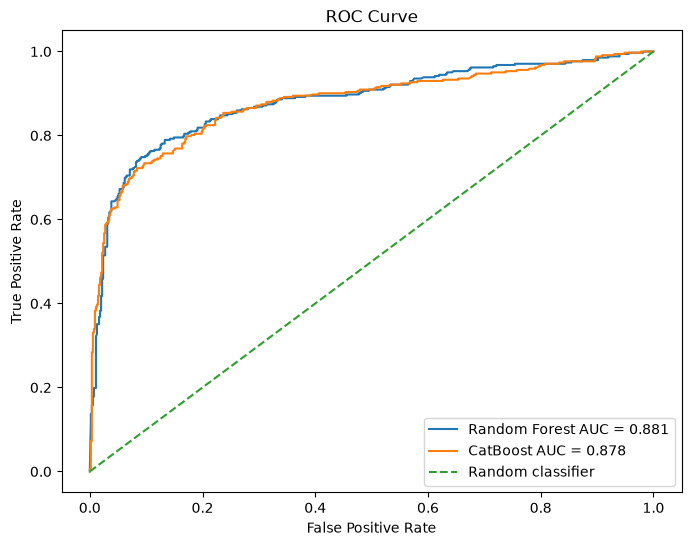

In [499]:
# Шаг 95.5. Строю ROC-кривые двух моделей

import matplotlib.pyplot as plt

catboost_fpr, catboost_tpr, _ = roc_curve(y, catboost_oof_proba_positive)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest AUC = {rf_roc_auc:.3f}"
)

plt.plot(
    catboost_fpr,
    catboost_tpr,
    label=f"CatBoost AUC = {catboost_roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [501]:
# Шаг 96. Исследую Precision–Recall Curve и выбираю threshold
# Что происходит с Precision и Recall при изменении threshold?

In [502]:
# Шаг 96.1. Получаю Precision-Recall curve

from sklearn.metrics import precision_recall_curve

rf_precision_curve, rf_recall_curve, rf_thresholds_pr = (precision_recall_curve(y, rf_oof_proba_positive))


print("Precision values:", len(rf_precision_curve))
print("Recall values:", len(rf_recall_curve))
print("Threshold values:", len(rf_thresholds_pr))

Precision values: 781
Recall values: 781
Threshold values: 780


In [503]:
# N+1 потому что precision_recall_curve добавляет дополнительную конечную точку кривой, для которой отдельного threshold уже нет.

In [504]:
# Шаг 96.2. Смотрю несколько threshold

for i in range(0, len(rf_thresholds_pr), 100):
    print(
        "Threshold:", round(rf_thresholds_pr[i], 3),
        "| Precision:", round(rf_precision_curve[i], 3),
        "| Recall:", round(rf_recall_curve[i], 3)
    )

Threshold: 0.004 | Precision: 0.384 | Recall: 1.0
Threshold: 0.043 | Precision: 0.427 | Recall: 0.971
Threshold: 0.083 | Precision: 0.489 | Recall: 0.942
Threshold: 0.138 | Precision: 0.556 | Recall: 0.895
Threshold: 0.246 | Precision: 0.666 | Recall: 0.863
Threshold: 0.417 | Precision: 0.787 | Recall: 0.789
Threshold: 0.686 | Precision: 0.912 | Recall: 0.637
Threshold: 0.928 | Precision: 0.933 | Recall: 0.365


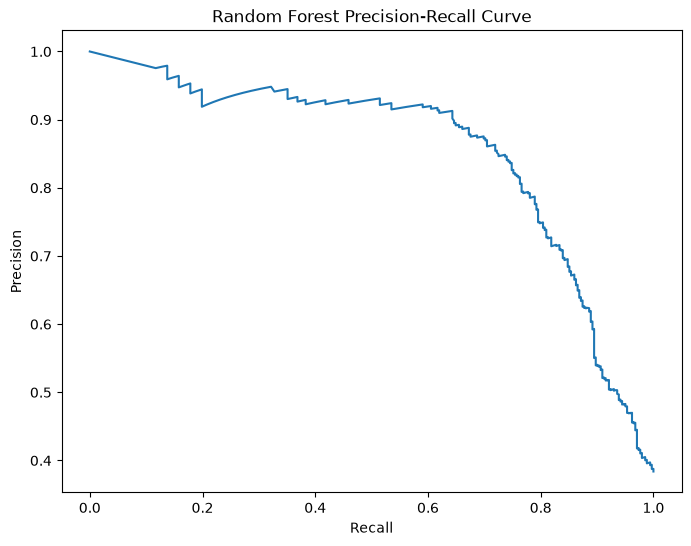

In [506]:
# Шаг 96.3. Строю Precision-Recall curve

plt.figure(figsize=(8, 6))

plt.plot(rf_recall_curve, rf_precision_curve)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")

plt.show()

In [507]:
# Шаг 96.4. Считаю F1 для каждого threshold

rf_f1_curve = (2 * rf_precision_curve[:-1] * rf_recall_curve[:-1] # Почему :-1 см объяснение шага 96.1
               / (rf_precision_curve[:-1] + rf_recall_curve[:-1] + 1e-10)) # 1e-10 добавлено для численной безопасности, чтобы случайно не получить деление на ноль

print("Number of F1 values:", len(rf_f1_curve))

Number of F1 values: 780


In [508]:
# Шаг 96.5. Нахожу threshold с максимальным F1

best_f1_index = np.argmax(rf_f1_curve)          #argmax возвращает индекс максимального значения, а не само значение

best_f1_threshold = (rf_thresholds_pr[best_f1_index])

best_f1 = (rf_f1_curve[best_f1_index])

best_precision = (rf_precision_curve[best_f1_index])

best_recall = (rf_recall_curve[best_f1_index])


print("Best threshold:", best_f1_threshold)
print("Best F1:", best_f1)
print("Precision:", best_precision)
print("Recall:", best_recall)

Best threshold: 0.489084955420826
Best F1: 0.7901234567402776
Precision: 0.8366013071895425
Recall: 0.7485380116959064


In [511]:
# Шаг 96.6. Проверяю найденный threshold

from sklearn.metrics import accuracy_score

In [512]:
rf_pred_best_f1 = (rf_oof_proba_positive >= best_f1_threshold).astype(int)


print("Accuracy:", accuracy_score(y, rf_pred_best_f1))
print("Precision:", precision_score(y, rf_pred_best_f1))
print("Recall:", recall_score(y, rf_pred_best_f1))
print("F1:", f1_score(y, rf_pred_best_f1))

Accuracy: 0.8473625140291807
Precision: 0.8366013071895425
Recall: 0.7485380116959064
F1: 0.7901234567901234


In [513]:
# Шаг 97. Проверяю, как выбирать threshold под бизнес-задачу

In [514]:
# Шаг 97.1. Создаю таблицу метрик для разных threshold

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    predictions = (rf_oof_proba_positive >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "f1": f1_score(y, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,threshold,accuracy,precision,recall,f1
0,0.30,0.797980,0.696602,0.839181,0.761273
1,0.35,0.818182,0.741935,0.807018,0.773109
2,0.40,0.832772,0.776504,0.792398,0.784370
3,0.45,0.840629,0.810559,0.763158,0.786145
4,0.50,0.847363,0.845638,0.736842,0.787500
5,0.55,0.845118,0.861702,0.710526,0.778846
6,0.60,0.846240,0.875458,0.698830,0.777236
7,0.65,0.841751,0.888031,0.672515,0.765391
8,0.70,0.830527,0.909871,0.619883,0.737391


In [515]:
# Шаг 97.2. Оставляю thresholds с Recall >= 0.80

high_recall_candidates = threshold_df[threshold_df["recall"] >= 0.80]

high_recall_candidates

,threshold,accuracy,precision,recall,f1
0,0.30,0.797980,0.696602,0.839181,0.761273
1,0.35,0.818182,0.741935,0.807018,0.773109


In [516]:
# Шаг 97.3. Выбираю лучший Precision при Recall >= 0.80

best_high_recall = (high_recall_candidates.sort_values("precision", ascending=False).head(1))

best_high_recall

,threshold,accuracy,precision,recall,f1
1,0.35,0.818182,0.741935,0.807018,0.773109


In [517]:
# Шаг 97.4. Оставляю thresholds с Precision >= 0.90

high_precision_candidates = threshold_df[threshold_df["precision"] >= 0.90]

high_precision_candidates

,threshold,accuracy,precision,recall,f1
8,0.7,0.830527,0.909871,0.619883,0.737391


In [518]:
# Шаг 97.5. Максимизирую Recall при Precision >= 0.90

best_high_precision = (high_precision_candidates.sort_values("recall", ascending=False).head(1))

best_high_precision

,threshold,accuracy,precision,recall,f1
8,0.7,0.830527,0.909871,0.619883,0.737391


In [519]:
# Шаг 98. Проверяю калибровку вероятностей

In [520]:
# Шаг 98.1. Считаю Brier Score

from sklearn.metrics import brier_score_loss

rf_brier = brier_score_loss(y, rf_oof_proba_positive)

catboost_brier = brier_score_loss(y, catboost_oof_proba_positive)


print("Random Forest Brier Score:", rf_brier)
print("CatBoost Brier Score:", catboost_brier)

Random Forest Brier Score: 0.12197339145081573
CatBoost Brier Score: 0.12302114189370568


In [522]:
# Шаг 98.2. Получаю calibration curve Random Forest

from sklearn.calibration import calibration_curve

rf_prob_true, rf_prob_pred = calibration_curve(
    y,
    rf_oof_proba_positive,
    n_bins=10,                 #делю вероятности на 10 диапазонов
    strategy="uniform"         #означает, что интервалы имеют одинаковую ширину
)

print("Mean predicted probability:")
print(rf_prob_pred)

print()

print("Actual positive fraction:")
print(rf_prob_true)

Mean predicted probability:
[0.05260032 0.14494498 0.24517652 0.33942515 0.45065908 0.53912553
 0.65799767 0.75151457 0.85099216 0.97923482]

Actual positive fraction:
[0.09859155 0.11538462 0.18461538 0.25396825 0.37254902 0.52
 0.675      0.85714286 0.90909091 0.92517007]


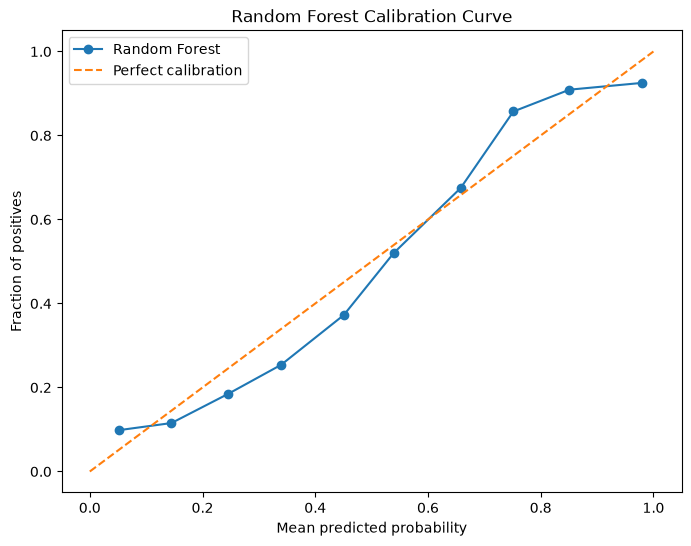

In [523]:
# Шаг 98.3. Строю calibration curve Random Forest

plt.figure(figsize=(8, 6))

plt.plot(
    rf_prob_pred,
    rf_prob_true,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Random Forest Calibration Curve")
plt.legend()

plt.show()

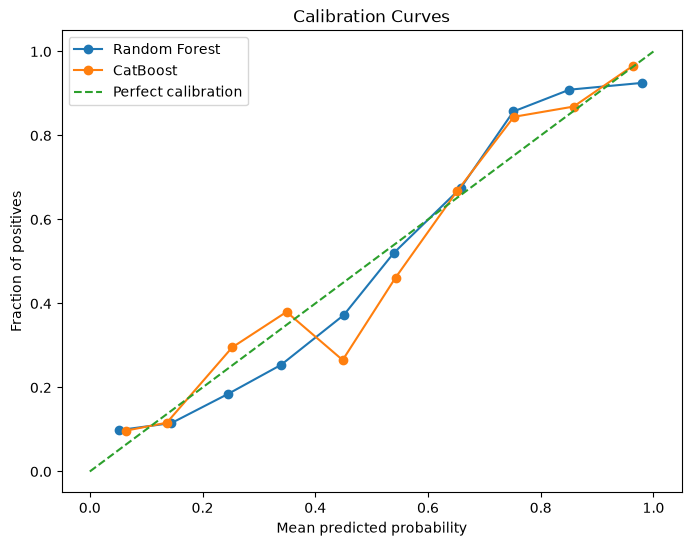

In [524]:
# Шаг 98.4. Получаю calibration curve CatBoost

catboost_prob_true, catboost_prob_pred = calibration_curve(
    y,
    catboost_oof_proba_positive,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_prob_pred,
    rf_prob_true,
    marker="o",
    label="Random Forest"
)

plt.plot(
    catboost_prob_pred,
    catboost_prob_true,
    marker="o",
    label="CatBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Curves")
plt.legend()

plt.show()

In [526]:
# Шаг 99. Тестирую реальную калибровку Random Forest

In [527]:
# Шаг 99.1. Создаю калиброванную версию Random Forest

from sklearn.calibration import CalibratedClassifierCV

rf_calibrated_sigmoid = CalibratedClassifierCV(
    estimator=rf_random_search.best_estimator_,
    method="sigmoid",
    cv=5
)

rf_calibrated_sigmoid

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...m_state=43))])
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to 

In [528]:
# Шаг 99.2. Получаю OOF probabilities калиброванной модели

from sklearn.model_selection import cross_val_predict

rf_calibrated_oof_proba = cross_val_predict(
    rf_calibrated_sigmoid,
    X_ticket,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

rf_calibrated_oof_proba.shape

(891, 2)

In [529]:
# Шаг 99.3. Забираю probability класса 1

rf_calibrated_oof_positive = rf_calibrated_oof_proba[:, 1]

print(rf_calibrated_oof_positive.shape)
print(rf_calibrated_oof_positive[:10])

(891,)
[0.10912716 0.90194966 0.39913698 0.9053049  0.12575045 0.14286354
 0.12667659 0.39889173 0.49022138 0.87587007]


In [533]:
# Шаг 99.4. Сравниваю Brier Score до и после calibration

rf_brier_before = brier_score_loss(y, rf_oof_proba_positive)
rf_brier_after = brier_score_loss(y, rf_calibrated_oof_positive)


print("Before calibration:", rf_brier_before)
print("After calibration:", rf_brier_after)
print("Difference:", rf_brier_after - rf_brier_before)

Before calibration: 0.12197339145081573
After calibration: 0.1209932970884397
Difference: -0.0009800943623760328


In [532]:
# Шаг 99.5. Сравниваю ROC-AUC

from sklearn.metrics import roc_auc_score

roc_auc_before = roc_auc_score(y, rf_oof_proba_positive)
roc_auc_after = roc_auc_score(y, rf_calibrated_oof_positive)


print("ROC-AUC before:", roc_auc_before)
print("ROC-AUC after:", roc_auc_after)
print("Difference:", roc_auc_after - roc_auc_before)

ROC-AUC before: 0.8814457972496511
ROC-AUC after: 0.8804178783327474
Difference: -0.0010279189169036806


In [534]:
# Шаг 100. Сравниваю sigmoid и isotonic calibration

In [536]:
# Шаг 100.1. Создаю isotonic-калибровку Random Forest

rf_calibrated_isotonic = CalibratedClassifierCV(
    estimator=rf_random_search.best_estimator_,
    method="isotonic",                              #монотонная кусочно-постоянная функция, которую алгоритм подбирает по данным
    cv=5
)

rf_calibrated_isotonic

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...m_state=43))])
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to

In [537]:
# Шаг 100.2. Получаю OOF probabilities после isotonic calibration

rf_isotonic_oof_proba = cross_val_predict(
    rf_calibrated_isotonic,
    X_ticket,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

rf_isotonic_oof_positive = rf_isotonic_oof_proba[:, 1]


print(rf_isotonic_oof_positive.shape)
print(rf_isotonic_oof_positive[:10])

(891,)
[0.07111111 0.96149291 0.40067227 1.         0.10443685 0.14332011
 0.09139393 0.43456356 0.54006211 0.89373135]


In [538]:
# Шаг 100.3. Сравниваю Brier Score

rf_brier_isotonic = brier_score_loss(y, rf_isotonic_oof_positive)


print("Original RF:", rf_brier_before)
print("Sigmoid:", rf_brier_after)
print("Isotonic:", rf_brier_isotonic)

Original RF: 0.12197339145081573
Sigmoid: 0.1209932970884397
Isotonic: 0.12207320729499362


In [539]:
# Шаг 100.4. Сравниваю ROC-AUC

rf_auc_isotonic = roc_auc_score(y, rf_isotonic_oof_positive)


print("Original RF:", roc_auc_before)
print("Sigmoid:", roc_auc_after)
print("Isotonic:", rf_auc_isotonic)

Original RF: 0.8814457972496511
Sigmoid: 0.8804178783327474
Isotonic: 0.8771557004228848


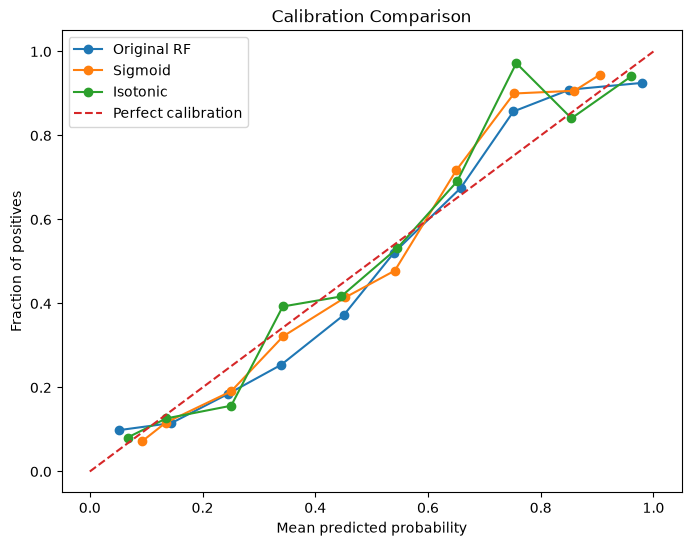

In [540]:
# Шаг 100.5. Сравниваю calibration curves

original_true, original_pred = calibration_curve(
    y,
    rf_oof_proba_positive,
    n_bins=10,
    strategy="uniform"
)

sigmoid_true, sigmoid_pred = calibration_curve(
    y,
    rf_calibrated_oof_positive,
    n_bins=10,
    strategy="uniform"
)

isotonic_true, isotonic_pred = calibration_curve(
    y,
    rf_isotonic_oof_positive,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    original_pred,
    original_true,
    marker="o",
    label="Original RF"
)

plt.plot(
    sigmoid_pred,
    sigmoid_true,
    marker="o",
    label="Sigmoid"
)

plt.plot(
    isotonic_pred,
    isotonic_true,
    marker="o",
    label="Isotonic"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Comparison")
plt.legend()

plt.show()

In [541]:
# Шаг 101. Перехожу к интерпретации модели
# Почему Random Forest принимает такие решения?

In [542]:
# Шаг 101.1. Обучаю лучший Random Forest на всём train

best_rf_pipeline = rf_random_search.best_estimator_

best_rf_pipeline.fit(X_ticket, y)

best_rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
Name,Type,Value
ticket_counts_,"Series[int64](681,)","Ticket 347082..., dtype: int64"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remai

In [543]:
# Шаг 101.2. Достаю обученный Random Forest

final_rf_model = best_rf_pipeline.named_steps["model"]

final_rf_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",43
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total num

In [544]:
# Шаг 101.3. Проверяю структуру Pipeline

best_rf_pipeline.named_steps

{'ticket_features': TicketGroupSizeTransformer(),
 'preprocessor': ColumnTransformer(transformers=[('num',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='median')),
                                                  ('scaler', StandardScaler())]),
                                  ['Age', 'SibSp', 'Parch', 'Fare',
                                   'TicketGroupSize']),
                                 ('cat',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='most_frequent')),
                                                  ('encoder',
                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                  ['Pclass', 'Sex', 'Embarked'])]),
 'model': RandomForestClassifier(max_depth=10, max_features=None, min_samples_split=5,
                        n_estima

In [545]:
# Шаг 101.4. Достаю feature importance Random Forest

rf_importances = final_rf_model.feature_importances_

print(rf_importances)

print()
print("Количество признаков:", len(rf_importances))

[0.1972559  0.03450713 0.02129897 0.18873389 0.03903647 0.02058848
 0.0031765  0.09426531 0.18467704 0.18958633 0.00922285 0.00507867
 0.01257246]

Количество признаков: 13


In [546]:
# Шаг 101.5. Получаю feature names после preprocessing

preprocessor = best_rf_pipeline.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

print(feature_names)

print()
print("Количество feature names:", len(feature_names))
print("Количество importances:", len(rf_importances))

['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'num__TicketGroupSize'
 'cat__Pclass_1' 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female'
 'cat__Sex_male' 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S']

Количество feature names: 13
Количество importances: 13


In [547]:
# Шаг 101.6. Создаю таблицу feature importance

rf_feature_importance = pd.DataFrame({"feature": feature_names, "importance": rf_importances})

rf_feature_importance = (rf_feature_importance.sort_values("importance", ascending=False).reset_index(drop=True))

rf_feature_importance

,feature,importance
0,num__Age,0.197256
1,cat__Sex_male,0.189586
2,num__Fare,0.188734
3,cat__Sex_female,0.184677
4,cat__Pclass_3,0.094265
5,num__TicketGroupSize,0.039036
6,num__SibSp,0.034507
7,num__Parch,0.021299
8,cat__Pclass_1,0.020588
9,cat__Embarked_S,0.012572


In [548]:
# Шаг 101.7. Проверяю сумму feature importances

print("Sum:", rf_feature_importance["importance"].sum())

Sum: 1.0


In [549]:
# Шаг 102. Проверяю Permutation Importance

In [550]:
# Шаг 102.1. Считаю baseline accuracy обученной модели

from sklearn.metrics import accuracy_score

rf_train_predictions = best_rf_pipeline.predict(X_ticket)

rf_train_accuracy = accuracy_score(y, rf_train_predictions)

print("Train accuracy:", rf_train_accuracy)

Train accuracy: 0.9270482603815937


In [552]:
# Шаг 102.2. Считаю permutation importance

from sklearn.inspection import permutation_importance

rf_permutation = permutation_importance(
    best_rf_pipeline,
    X_ticket,
    y,
    scoring="accuracy",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)


print(rf_permutation.importances_mean)
print()
print(rf_permutation.importances_std)
print()
print(rf_permutation.importances.shape)

[0.11380471 0.01537598 0.00791246 0.08681257 0.14236813 0.24062851
 0.02542088 0.00993266]

[0.0080886  0.00253707 0.00394377 0.00481787 0.00729323 0.00907912
 0.00288933 0.00251651]

(8, 20)


In [558]:
# Шаг 102.3. Создаю таблицу permutation importance

rf_permutation_df = pd.DataFrame({
    "feature": X_ticket.columns,
    "importance_mean": rf_permutation.importances_mean,
    "importance_std": rf_permutation.importances_std
})

rf_permutation_df = (rf_permutation_df.sort_values("importance_mean", ascending=False).reset_index(drop=True))
rf_permutation_df

,feature,importance_mean,importance_std
0,Sex,0.240629,0.009079
1,Pclass,0.142368,0.007293
2,Age,0.113805,0.008089
3,Fare,0.086813,0.004818
4,Embarked,0.025421,0.002889
5,SibSp,0.015376,0.002537
6,Ticket,0.009933,0.002517
7,Parch,0.007912,0.003944


In [557]:
# Шаг 102.4. Проверяю признаки с importance <= 0

rf_permutation_df[rf_permutation_df["importance_mean"] <= 0]

,feature,importance_mean,importance_std


In [559]:
# Шаг 103. Проверяю Permutation Importance честнее — через validation

In [560]:
# Шаг 103.1. Создаю train/validation split

from sklearn.model_selection import train_test_split

X_train_pi, X_valid_pi, y_train_pi, y_valid_pi = train_test_split(
    X_ticket,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)


print("Train:", X_train_pi.shape)
print("Validation:", X_valid_pi.shape)

Train: (712, 8)
Validation: (179, 8)


In [561]:
# Шаг 103.2. Клонирую лучший pipeline

from sklearn.base import clone

rf_pi_pipeline = clone(rf_random_search.best_estimator_)
rf_pi_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [562]:
# Шаг 103.3. Обучаю pipeline только на train

rf_pi_pipeline.fit(
    X_train_pi,
    y_train_pi
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('ticket_features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
Name,Type,Value
ticket_counts_,"Series[int64](571,)","Ticket 1601 ..., dtype: int64"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remain

In [563]:
# Шаг 103.4. Проверяю качество train и validation

train_accuracy_pi = rf_pi_pipeline.score(
    X_train_pi,
    y_train_pi
)

valid_accuracy_pi = rf_pi_pipeline.score(
    X_valid_pi,
    y_valid_pi
)


print("Train accuracy:", train_accuracy_pi)
print("Validation accuracy:", valid_accuracy_pi)
print("Gap:", train_accuracy_pi - valid_accuracy_pi)

Train accuracy: 0.9325842696629213
Validation accuracy: 0.8156424581005587
Gap: 0.11694181156236261


In [564]:
# Шаг 103.5. Считаю permutation importance на validation
# Насколько портится качество на невидимых данных, если разрушить информацию конкретного признака?

rf_permutation_valid = permutation_importance(
    rf_pi_pipeline,
    X_valid_pi,
    y_valid_pi,
    scoring="accuracy",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

In [565]:
# Шаг 103.6. Создаю validation permutation importance

rf_permutation_valid_df = pd.DataFrame({
    "feature": X_valid_pi.columns,
    "importance_mean": rf_permutation_valid.importances_mean,
    "importance_std": rf_permutation_valid.importances_std
})

rf_permutation_valid_df = (rf_permutation_valid_df.sort_values("importance_mean", ascending=False).reset_index(drop=True))
rf_permutation_valid_df

,feature,importance_mean,importance_std
0,Sex,0.183799,0.027268
1,Pclass,0.091620,0.023106
2,Age,0.057169,0.015107
3,Fare,0.033706,0.014459
4,Embarked,0.017132,0.010395
5,Ticket,0.012477,0.003998
6,Parch,0.010801,0.004546
7,SibSp,0.003352,0.006547


In [566]:
# Шаг 104. Перехожу к SHAP
# Почему модель сделала конкретное предсказание?

In [567]:
# Шаг 104.1. Проверяю SHAP

import shap

print("SHAP version:", shap.__version__)

ModuleNotFoundError: No module named 'shap'

In [568]:
import sys

!{sys.executable} -m pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 12.4 MB/s  0:00:03 12.9 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 13.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [shap]━━━━━━ 4/5 [shap]]te]

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [569]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [572]:
# Шаг 104.2. Достаю компоненты обученного pipeline

best_rf_pipeline = rf_random_search.best_estimator_

ticket_transformer = best_rf_pipeline.named_steps["ticket_features"]
preprocessor = best_rf_pipeline.named_steps["preprocessor"]
rf_model = best_rf_pipeline.named_steps["model"]

print(type(ticket_transformer))
print(type(preprocessor))
print(type(rf_model))

<class '__main__.TicketGroupSizeTransformer'>
<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [573]:
# Шаг 104.3. Применяю feature engineering

X_shap_engineered = ticket_transformer.transform(X_ticket)

print(X_shap_engineered.columns.tolist())
print()
X_shap_engineered.head()

['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'TicketGroupSize']



,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket,TicketGroupSize
0,22.0,1,0,7.2500,3,male,S,A/5 21171,1
1,38.0,1,0,71.2833,1,female,C,PC 17599,1
2,26.0,0,0,7.9250,3,female,S,STON/O2. 3101282,1
3,35.0,1,0,53.1000,1,female,S,113803,2
4,35.0,0,0,8.0500,3,male,S,373450,1


In [574]:
# Шаг 104.4. Применяю preprocessing

X_shap_transformed = preprocessor.transform(X_shap_engineered)

print("Shape:", X_shap_transformed.shape)
print("Type:", type(X_shap_transformed))

Shape: (891, 13)
Type: <class 'numpy.ndarray'>


In [575]:
# Шаг 104.5. Достаю имена преобразованных признаков

feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print()

for feature in feature_names:
    print(feature)

Number of features: 13

num__Age
num__SibSp
num__Parch
num__Fare
num__TicketGroupSize
cat__Pclass_1
cat__Pclass_2
cat__Pclass_3
cat__Sex_female
cat__Sex_male
cat__Embarked_C
cat__Embarked_Q
cat__Embarked_S


In [576]:
# Шаг 104.6. Проверяю соответствие размерностей

print("Columns after preprocessing:", X_shap_transformed.shape[1])

print("Feature names:", len(feature_names))

print("RF expects:", rf_model.n_features_in_)

Columns after preprocessing: 13
Feature names: 13
RF expects: 13


In [577]:
# Шаг 105. Создаю SHAP Explainer

In [578]:
# Шаг 105.1. Создаю SHAP TreeExplainer

explainer = shap.TreeExplainer(rf_model)

explainer

In [579]:
# Шаг 105.2. Создаю DataFrame для SHAP

X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=X_ticket.index
)

X_shap_df.head()

,num__Age,num__SibSp,num__Parch,num__Fare,num__TicketGroupSize,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,cat__Sex_male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S
0,-0.565736,0.432793,-0.473674,-0.502445,-0.579162,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1,0.663861,0.432793,-0.473674,0.786845,-0.579162,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.258337,-0.474545,-0.473674,-0.488854,-0.579162,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
3,0.433312,0.432793,-0.473674,0.420730,0.155928,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.433312,-0.474545,-0.473674,-0.486337,-0.579162,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [580]:
# Шаг 105.3. Считаю SHAP values

shap_values = explainer(X_shap_df)

In [581]:
# Шаг 105.4. Проверяю структуру SHAP values

print("Type:", type(shap_values))
print("Values shape:", shap_values.values.shape)
print("Base values shape:", shap_values.base_values.shape)

Type: <class 'shap._explanation.Explanation'>
Values shape: (891, 13, 2)
Base values shape: (891, 2)


In [582]:
# Шаг 105.5. Выделяю объяснения для класса Survived = 1

shap_values_survived = shap_values[:, :, 1]

print("Shape:", shap_values_survived.values.shape)
print("Base values shape:", shap_values_survived.base_values.shape)

Shape: (891, 13)
Base values shape: (891,)


In [583]:
# Шаг 105.6. Проверяю SHAP values одного пассажира

passenger_idx = 0

print("Passenger:")
display(X_ticket.iloc[[passenger_idx]])

print("SHAP values:")
display(pd.DataFrame({
        "feature": feature_names,
        "value": X_shap_df.iloc[passenger_idx].values,
        "shap_value": shap_values_survived.values[passenger_idx]
    }).sort_values(
        "shap_value", key=abs, ascending=False)
)

Passenger:


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket
0,22.0,1,0,7.25,3,male,S,A/5 21171


SHAP values:


,feature,value,shap_value
9,cat__Sex_male,1.000000,-0.109270
8,cat__Sex_female,0.000000,-0.105482
7,cat__Pclass_3,1.000000,-0.031165
3,num__Fare,-0.502445,-0.024464
0,num__Age,-0.565736,-0.022212
1,num__SibSp,0.432793,0.018566
5,cat__Pclass_1,0.000000,-0.016084
10,cat__Embarked_C,0.000000,-0.014155
12,cat__Embarked_S,1.000000,-0.005377
4,num__TicketGroupSize,-0.579162,0.001326


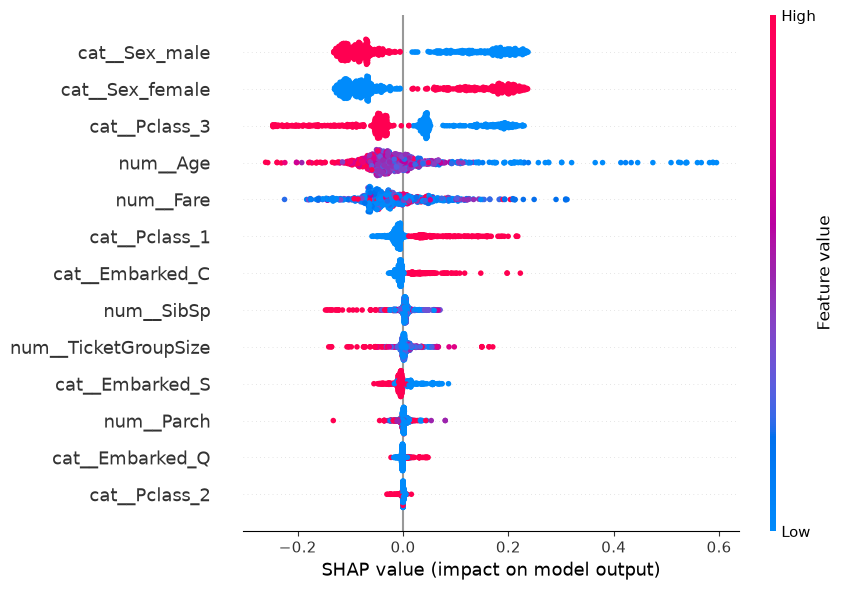

In [584]:
# Шаг 105.7. Строю SHAP beeswarm plot

shap.plots.beeswarm(
    shap_values_survived,
    max_display=13
)

In [585]:
# Шаг 106. Проверяю аддитивность SHAP на конкретном пассажире

In [590]:
# Шаг 106.1. Выбираю одного пассажира

passenger_idx = 0

passenger_shap = shap_values_survived[passenger_idx]


print("Base value:", passenger_shap.base_values)
print("Sum of SHAP values:", passenger_shap.values.sum())
print("Base + SHAP:", passenger_shap.base_values + passenger_shap.values.sum())

Base value: 0.3840763187429858
Sum of SHAP values: -0.30669215573380104
Base + SHAP: 0.07738416300918477


In [591]:
# Шаг 106.2. Сравниваю SHAP с predict_proba

passenger_proba = rf_model.predict_proba(X_shap_df.iloc[[passenger_idx]])[0, 1]

shap_output = (passenger_shap.base_values + passenger_shap.values.sum())


print("SHAP output:", shap_output)
print("Random Forest probability:", passenger_proba)
print("Difference:", shap_output - passenger_proba)

SHAP output: 0.07738416300918477
Random Forest probability: 0.07738416300918378
Difference: 9.853229343548264e-16


/Users/mozek/ML/Titanic/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


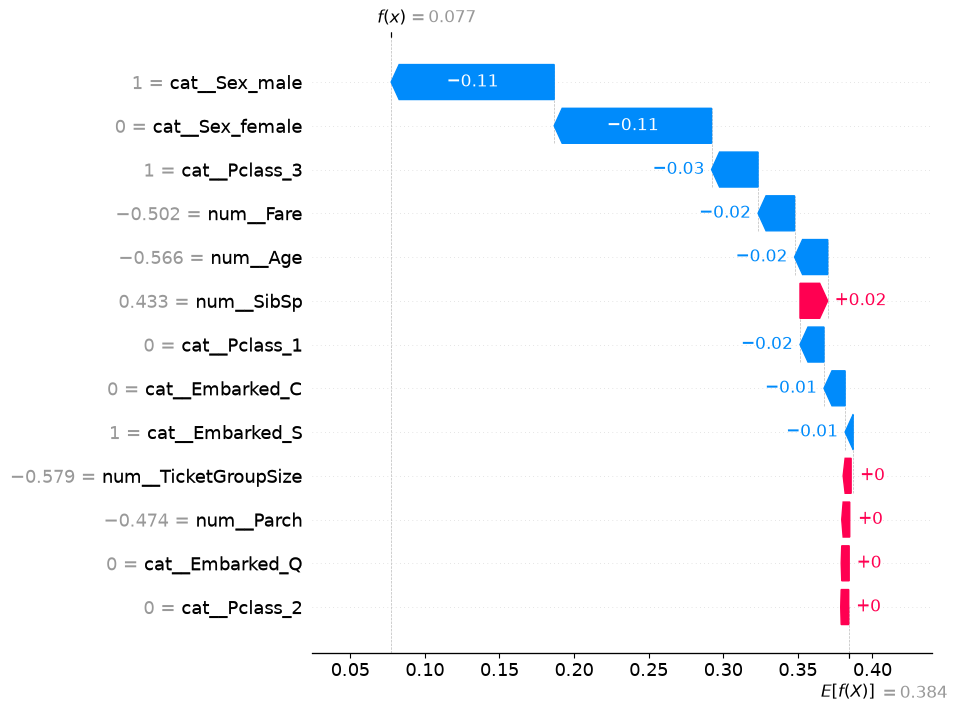

In [592]:
# Шаг 106.3. Строю SHAP waterfall для одного пассажира

shap.plots.waterfall(passenger_shap, max_display=13)

In [593]:
# Шаг 106.4. Нахожу пассажира с максимальной вероятностью выживания

all_probabilities = rf_model.predict_proba(X_shap_transformed)[:, 1]

highest_proba_idx = np.argmax(all_probabilities)


print("Passenger index:", highest_proba_idx)
print("Predicted survival probability:", all_probabilities[highest_proba_idx])

Passenger index: 3
Predicted survival probability: 1.0


In [594]:
 # Шаг 106.5. Достаю SHAP для пассажира с максимальной вероятностью

highest_proba_shap = shap_values_survived[highest_proba_idx]


print("Passenger index:", highest_proba_idx)
print("SHAP output:", highest_proba_shap.base_values + highest_proba_shap.values.sum())
print("Random Forest probability:", all_probabilities[highest_proba_idx])

Passenger index: 3
SHAP output: 0.9999999999999987
Random Forest probability: 1.0


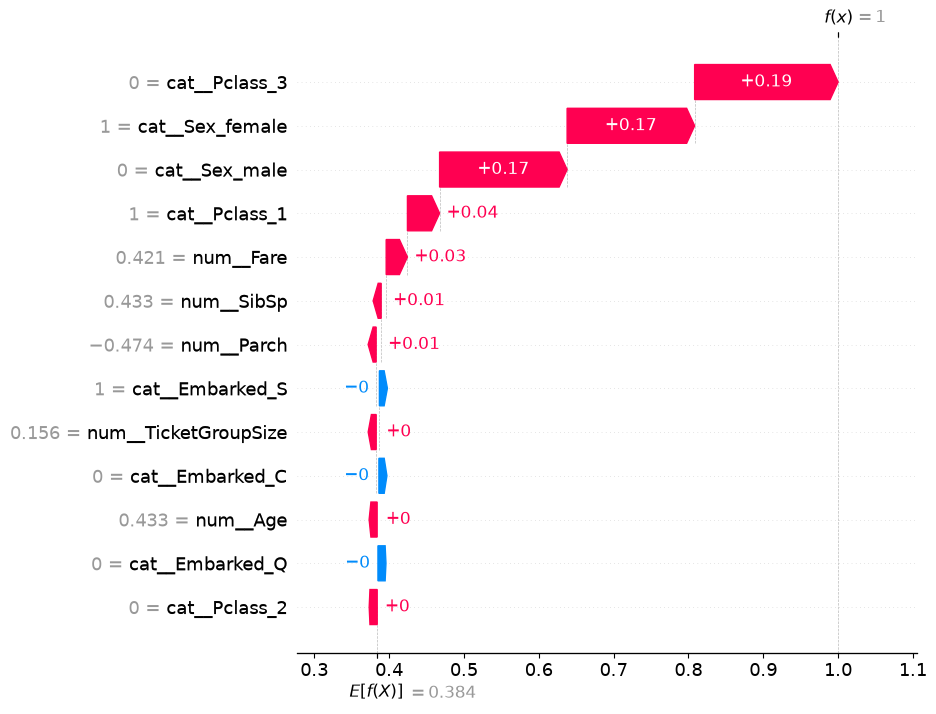

In [595]:
# Шаг 106.6. Строю waterfall для пассажира с максимальной вероятностью выживания

shap.plots.waterfall(highest_proba_shap, max_display=13)

In [596]:
# Шаг 107. Проверяю SHAP на здравый смысл

In [597]:
# Шаг 107.1. Сравниваю исходные данные двух пассажиров

comparison_passengers = train.loc[
    [0, highest_proba_idx],
    [
        "Survived",
        "Pclass",
        "Sex",
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Embarked",
        "Ticket"
    ]
]

comparison_passengers

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Ticket
0,0,3,male,22.0,1,0,7.25,S,A/5 21171
3,1,1,female,35.0,1,0,53.10,S,113803


In [599]:
# Шаг 107.2. Сравниваю SHAP-вклады двух пассажиров

shap_comparison = pd.DataFrame({
    "feature": feature_names,
    "low_probability_passenger": passenger_shap.values,
    "high_probability_passenger": highest_proba_shap.values
})

shap_comparison["difference"] = (shap_comparison["high_probability_passenger"] - shap_comparison["low_probability_passenger"])
shap_comparison = shap_comparison.sort_values("difference", ascending=False)
shap_comparison

,feature,low_probability_passenger,high_probability_passenger,difference
9,cat__Sex_male,-0.109270,0.170393,0.279663
8,cat__Sex_female,-0.105482,0.170411,0.275893
7,cat__Pclass_3,-0.031165,0.191735,0.222899
5,cat__Pclass_1,-0.016084,0.042989,0.059073
3,num__Fare,-0.024464,0.028394,0.052857
0,num__Age,-0.022212,0.002382,0.024594
10,cat__Embarked_C,-0.014155,-0.003653,0.010502
2,num__Parch,0.000943,0.006706,0.005763
4,num__TicketGroupSize,0.001326,0.004298,0.002971
12,cat__Embarked_S,-0.005377,-0.004372,0.001005


In [601]:
# Шаг 108. Перехожу к финальному inference pipeline
# Как превратить весь эксперимент в модель, которой можно безопасно передать совершенно новый test.csv?

In [602]:
# Шаг 108.1. Фиксирую финальную модель

final_model = rf_random_search.best_estimator_

print(final_model)

Pipeline(steps=[('ticket_features', TicketGroupSizeTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare', 'TicketGroupSize']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                    

In [603]:
# Шаг 108.2. Проверяю структуру финального Pipeline

print("Final model type:")
print(type(final_model))

print("\nPipeline steps:")
print(final_model.named_steps.keys())

Final model type:
<class 'sklearn.pipeline.Pipeline'>

Pipeline steps:
dict_keys(['ticket_features', 'preprocessor', 'model'])


In [604]:
# Шаг 108.3. Проверяю параметры финального Random Forest

final_rf = final_model.named_steps["model"]

print("Model type:", type(final_rf))
print("n_estimators:", final_rf.n_estimators)
print("max_depth:", final_rf.max_depth)
print("min_samples_split:", final_rf.min_samples_split)
print("min_samples_leaf:", final_rf.min_samples_leaf)
print("max_features:", final_rf.max_features)
print("class_weight:", final_rf.class_weight)

Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
n_estimators: 500
max_depth: 10
min_samples_split: 5
min_samples_leaf: 1
max_features: None
class_weight: None


In [605]:
# Шаг 109. Загружаю Kaggle test.csv

In [610]:
# Шаг 109.1. Загружаю test.csv

test = pd.read_csv("../Data/raw/test.csv")

print("Test shape:", test.shape)

test.head()

Test shape: (418, 11)


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [611]:
# Шаг 109.2. Проверяю структуру test

test.info()

print("\nMissing values:")
print(test.isna().sum().sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB

Missing values:
Cabin          327
Age             86
Fare             1
PassengerId      0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Embarked         0
dtype: int64


In [612]:
# Шаг 109.3. Сохраняю PassengerId и формирую X_test

test_passenger_ids = test["PassengerId"].copy()

X_test = test[
    [
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Pclass",
        "Sex",
        "Embarked",
        "Ticket"
    ]
].copy()


print("X_test shape:", X_test.shape)
print()
print("X_test columns:")
print(X_test.columns.tolist())

X_test shape: (418, 8)

X_test columns:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket']


In [613]:
# Шаг 109.4. Проверяю финальный pipeline на X_test

print("Pipeline steps:")
print(best_rf_pipeline.named_steps.keys())

print("\nX_test shape before pipeline:")
print(X_test.shape)

print("\nMissing values before pipeline:")
print(X_test.isna().sum())

Pipeline steps:
dict_keys(['ticket_features', 'preprocessor', 'model'])

X_test shape before pipeline:
(418, 8)

Missing values before pipeline:
Age         86
SibSp        0
Parch        0
Fare         1
Pclass       0
Sex          0
Embarked     0
Ticket       0
dtype: int64


In [614]:
# Шаг 109.5. Получаю предсказания на Kaggle test

test_predictions = best_rf_pipeline.predict(X_test)

print("Number of predictions:", len(test_predictions))
print("First 20 predictions:")
print(test_predictions[:20])

print("\nUnique predictions:")
print(np.unique(test_predictions, return_counts=True))

Number of predictions: 418
First 20 predictions:
[0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0]

Unique predictions:
(array([0, 1]), array([282, 136]))


In [615]:
# Шаг 110.1. Создаю DataFrame для submission

submission = pd.DataFrame({
    "PassengerId": test_passenger_ids,
    "Survived": test_predictions.astype(int)
})

print("Submission shape:", submission.shape)

submission.head(10)

Submission shape: (418, 2)


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


In [616]:
# Шаг 110.2. Проверяю submission перед сохранением

print("Shape:", submission.shape)
print()
print("Columns:", submission.columns.tolist())
print()
print("Missing values:")
print(submission.isna().sum())
print()
print("Duplicate PassengerId:", submission["PassengerId"].duplicated().sum())
print()
print("Survived values:")
print(submission["Survived"].value_counts().sort_index())
print()
print("Survived dtype:", submission["Survived"].dtype)

Shape: (418, 2)

Columns: ['PassengerId', 'Survived']

Missing values:
PassengerId    0
Survived       0
dtype: int64

Duplicate PassengerId: 0

Survived values:
Survived
0    282
1    136
Name: count, dtype: int64

Survived dtype: int64


In [617]:
# Шаг 110.3. Проверяю соответствие PassengerId исходному test

ids_match = submission["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))

print("PassengerId order matches test:", ids_match)

PassengerId order matches test: True


In [618]:
# Шаг 110.4. Сохраняю финальный submission

submission_path = "../Artifacts/submission.csv"

submission.to_csv(submission_path, index=False)

print("Submission saved to:", submission_path)

Submission saved to: ../Artifacts/submission.csv


In [619]:
# Шаг 110.5. Читаю сохранённый submission обратно

submission_check = pd.read_csv(submission_path)

print("Shape:", submission_check.shape)
print("Columns:", submission_check.columns.tolist())

submission_check.head(10)

Shape: (418, 2)
Columns: ['PassengerId', 'Survived']


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


In [620]:
# Шаг 110.6. Финальные sanity checks submission

assert submission_check.shape == (418, 2)
assert submission_check.columns.tolist() == [
    "PassengerId",
    "Survived"
]

assert submission_check.isna().sum().sum() == 0
assert submission_check["PassengerId"].is_unique
assert set(submission_check["Survived"].unique()).issubset({0, 1})
assert submission_check["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))

print("All submission checks passed!")

All submission checks passed!


In [621]:
# Шаг 110.7. Проверяю созданный артефакт

import os

print("File exists:", os.path.exists(submission_path))
print("File size:", os.path.getsize(submission_path), "bytes")

File exists: True
File size: 2839 bytes


In [622]:
# Шаг 111.1. Сохраняю финальный pipeline

import joblib

model_path = "../Artifacts/titanic_rf_pipeline.joblib"

joblib.dump(best_rf_pipeline, model_path)

print("Model saved to:", model_path)

Model saved to: ../Artifacts/titanic_rf_pipeline.joblib


In [623]:
# Шаг 111.2. Проверяю сохранённый артефакт модели

print("Model exists:", os.path.exists(model_path))
print("Model size:", os.path.getsize(model_path), "bytes")

Model exists: True
Model size: 6175499 bytes


In [624]:
# Шаг 111.3. Загружаю pipeline с диска

loaded_pipeline = joblib.load(model_path)

print(type(loaded_pipeline))
print(loaded_pipeline.named_steps.keys())

<class 'sklearn.pipeline.Pipeline'>
dict_keys(['ticket_features', 'preprocessor', 'model'])


In [631]:
# Шаг 111.4. Проверяю inference загруженной модели

loaded_predictions = loaded_pipeline.predict(X_test)

print("Number of predictions:", len(loaded_predictions))
print("First 20 predictions:")
print(loaded_predictions[:20])

Number of predictions: 418
First 20 predictions:
[0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0]


In [632]:
# Шаг 111.5. Проверяю идентичность предсказаний

predictions_match = np.array_equal(test_predictions, loaded_predictions)

print("Predictions identical:", predictions_match)

Predictions identical: True


In [633]:
# Шаг 112.1. Формирую metadata финальной модели

model_metadata = {
    "model": "RandomForestClassifier",
    "cv_folds": 5,
    "cv_accuracy": float(rf_random_search.best_score_),
    "roc_auc_oof": float(rf_roc_auc),
    "best_threshold_f1": float(best_threshold),
    "best_f1": float(best_f1),
    "best_params": rf_random_search.best_params_,
    "features": [
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Pclass",
        "Sex",
        "Embarked",
        "Ticket"
    ]
}

model_metadata

{'model': 'RandomForestClassifier',
 'cv_folds': 5,
 'cv_accuracy': 0.8473542150524136,
 'roc_auc_oof': 0.8814457972496511,
 'best_threshold_f1': 0.489084955420826,
 'best_f1': 0.7901234567402776,
 'best_params': {'model__n_estimators': 500,
  'model__min_samples_split': 5,
  'model__min_samples_leaf': 1,
  'model__max_features': None,
  'model__max_depth': 10,
  'model__class_weight': None},
 'features': ['Age',
  'SibSp',
  'Parch',
  'Fare',
  'Pclass',
  'Sex',
  'Embarked',
  'Ticket']}

In [634]:
# Шаг 113.1. Создаю inference-функцию

def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result

In [635]:
# Шаг 113.2. Запускаю inference через сохранённую модель

inference_submission = predict_survival(
    data=X_test,
    passenger_ids=test["PassengerId"],
    model=loaded_pipeline
)

inference_submission.head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


In [636]:
# Шаг 113.3. Проверяю результат inference

print("Shape:", inference_submission.shape)

print("\nMissing values:")
print(inference_submission.isna().sum())

print("\nPrediction distribution:")
print(inference_submission["Survived"].value_counts())

Shape: (418, 2)

Missing values:
PassengerId    0
Survived       0
dtype: int64

Prediction distribution:
Survived
0    282
1    136
Name: count, dtype: int64


In [637]:
# Шаг 113.4. Проверяю полный inference round-trip

submission_matches = submission.equals(inference_submission)

print("Submission identical:", submission_matches)

Submission identical: True


In [638]:
# Шаг 113.5. Проверяю inference для одного пассажира

one_passenger = X_test.iloc[[0]]

one_passenger

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket
0,34.5,0,0,7.8292,3,male,Q,330911


In [639]:
# Шаг 113.6. Получаю prediction одного пассажира

one_prediction = loaded_pipeline.predict(one_passenger)
one_probability = loaded_pipeline.predict_proba(one_passenger)


print("Prediction:", one_prediction)
print("Probabilities:", one_probability)

Prediction: [0]
Probabilities: [[0.91170123 0.08829877]]


In [640]:
# Шаг 113.7. Проверяю вероятности

print("P(not survived):", one_probability[0, 0])
print("P(survived):", one_probability[0, 1])
print("Sum:", one_probability.sum())

P(not survived): 0.9117012318050102
P(survived): 0.08829876819498961
Sum: 0.9999999999999998


In [641]:
# Шаг 114.1. Проверяю содержимое папки src

import os

src_path = "../src"

print("Files in src:")
print(os.listdir(src_path))

Files in src:
[]


In [643]:
# Шаг 114.2. Проверяю текущий main.py

main_path = "../main.py"

with open(main_path, "r") as file:
    main_content = file.read()

print(main_content)

In [644]:
# Шаг 114.3. Создаю модуль inference.py

inference_code = '''
import pandas as pd


def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result
'''

inference_path = "../src/inference.py"

with open(inference_path, "w") as file:
    file.write(inference_code)

print("Created:", inference_path)

Created: ../src/inference.py


In [645]:
# Шаг 114.4. Проверяю содержимое inference.py

print(os.listdir("../src"))

with open("../src/inference.py", "r") as file:
    print(file.read())

['inference.py']

import pandas as pd


def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result



In [646]:
# Шаг 114.5. Импортирую функцию из src

import sys

project_root = ".."

if project_root not in sys.path:
    sys.path.append(project_root)

from src.inference import predict_survival

In [647]:
# Шаг 114.6. Проверяю inference через функцию из src

src_submission = predict_survival(
    data=X_test,
    passenger_ids=test["PassengerId"],
    model=loaded_pipeline
)

src_submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [649]:
# Шаг 114.7. Проверяю идентичность результата

print("src inference identical:", submission.equals(src_submission))

src inference identical: True


In [660]:
# Шаг 115.1. Создаю рабочий main.py

main_code = '''
from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


# Корень проекта Titanic
PROJECT_ROOT = Path(__file__).resolve().parent

# Пути к данным и артефактам
TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main():
    # Загружаю test
    test = pd.read_csv(TEST_PATH)

    # Сохраняю PassengerId отдельно
    passenger_ids = test["PassengerId"]

    # Оставляю признаки, которые ожидает pipeline
    X_test = test[
        [
            "Age",
            "SibSp",
            "Parch",
            "Fare",
            "Pclass",
            "Sex",
            "Embarked",
            "Ticket"
        ]
    ].copy()

    # Загружаю обученный pipeline
    model = joblib.load(MODEL_PATH)

    # Получаю предсказания
    submission = predict_survival(
        data=X_test,
        passenger_ids=passenger_ids,
        model=model
    )

    # Сохраняю submission
    submission.to_csv(SUBMISSION_PATH, index=False)

    print("Predictions created:", len(submission))
    print("Submission saved to:", SUBMISSION_PATH)


if __name__ == "__main__":
    main()
'''

with open("../main.py", "w") as file:
    file.write(main_code)

print("main.py created")

main.py created


In [661]:
# Шаг 115.2. Проверяю main.py

with open("../main.py", "r") as file:
    print(file.read())


from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


# Корень проекта Titanic
PROJECT_ROOT = Path(__file__).resolve().parent

# Пути к данным и артефактам
TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main():
    # Загружаю test
    test = pd.read_csv(TEST_PATH)

    # Сохраняю PassengerId отдельно
    passenger_ids = test["PassengerId"]

    # Оставляю признаки, которые ожидает pipeline
    X_test = test[
        [
            "Age",
            "SibSp",
            "Parch",
            "Fare",
            "Pclass",
            "Sex",
            "Embarked",
            "Ticket"
        ]
    ].copy()

    # Загружаю обученный pipeline
    model = joblib.load(MODEL_PATH)

    # Получаю предсказания
    submission = predict_survival(
        data=X_test,
        passenger_ids

In [662]:
# Шаг 115.3. Запускаю main.py как отдельную программ

!cd .. && .venv/bin/python main.py

Traceback (most recent call last):
  File "/Users/mozek/ML/Titanic/main.py", line 58, in <module>
    main()
    ~~~~^^
  File "/Users/mozek/ML/Titanic/main.py", line 41, in main
    model = joblib.load(MODEL_PATH)
  File "/Users/mozek/ML/Titanic/.venv/lib/python3.13/site-packages/joblib/numpy_pickle.py", line 755, in load
    obj = _unpickle(
        fobj,
    ...<2 lines>...
        mmap_mode=validated_mmap_mode,
    )
  File "/Users/mozek/ML/Titanic/.venv/lib/python3.13/site-packages/joblib/numpy_pickle.py", line 632, in _unpickle
    obj = unpickler.load()
  File "/opt/miniconda3/lib/python3.13/pickle.py", line 1256, in load
    dispatch[key[0]](self)
    ~~~~~~~~~~~~~~~~^^^^^^
  File "/opt/miniconda3/lib/python3.13/pickle.py", line 1581, in load_stack_global
    self.append(self.find_class(module, name))
                ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "/opt/miniconda3/lib/python3.13/pickle.py", line 1624, in find_class
    return _getattribute(sys.modules[module], name)[0]
  

In [663]:
# Исправляю проблему сериализации кастомного трансформера

transformers_code = '''
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


class TicketGroupSizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        ticket_counts = X["Ticket"].value_counts()

        X["TicketGroupSize"] = X["Ticket"].map(ticket_counts)

        return X
'''

with open("../src/transformers.py", "w") as file:
    file.write(transformers_code)

print("transformers.py created")

transformers.py created


In [664]:
from src.transformers import TicketGroupSizeTransformer

print(TicketGroupSizeTransformer)
print(TicketGroupSizeTransformer.__module__)

<class 'src.transformers.TicketGroupSizeTransformer'>
src.transformers


In [677]:
# Шаг 115.4. Пересобираю pipeline с импортируемым TicketGroupSizeTransformer

from sklearn.pipeline import Pipeline
from src.transformers import TicketGroupSizeTransformer

production_rf_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", best_rf_pipeline.named_steps["model"])
])

print(production_rf_pipeline)

Pipeline(steps=[('ticket_features', TicketGroupSizeTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare', 'TicketGroupSize']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                    

In [683]:
# Шаг 115.5. Проверяю идентичность predictions после пересборки pipeline

old_predictions = best_rf_pipeline.predict(X_test)

new_predictions = production_rf_pipeline.predict(X_test)

predictions_identical = np.array_equal(old_predictions, new_predictions)

print("Predictions identical:", predictions_identical)
print("Different predictions:", np.sum(old_predictions != new_predictions))

Predictions identical: True
Different predictions: 0


In [679]:
# Исправление: создаю новый transformer и переношу обученное состояние

old_ticket_transformer = best_rf_pipeline.named_steps["ticket_features"]

new_ticket_transformer = TicketGroupSizeTransformer()

new_ticket_transformer.ticket_counts_ = (old_ticket_transformer.ticket_counts_.copy())

print("Old has ticket_counts_:", hasattr(old_ticket_transformer, "ticket_counts_"))
print("New has ticket_counts_:", hasattr(new_ticket_transformer, "ticket_counts_"))
print("Counts identical:", old_ticket_transformer.ticket_counts_.equals(new_ticket_transformer.ticket_counts_))

Old has ticket_counts_: True
New has ticket_counts_: True
Counts identical: True


In [680]:
from sklearn.pipeline import Pipeline

production_rf_pipeline = Pipeline([
    ("ticket_features", new_ticket_transformer),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", best_rf_pipeline.named_steps["model"])
])

In [684]:
print("Production transformer has ticket_counts_:", hasattr(production_rf_pipeline.named_steps["ticket_features"], "ticket_counts_"))

print(production_rf_pipeline.named_steps["ticket_features"].ticket_counts_.head())

Production transformer has ticket_counts_: True
Ticket
347082      7
1601        7
CA. 2343    7
3101295     6
CA 2144     6
Name: count, dtype: int64


In [685]:
old_predictions = best_rf_pipeline.predict(X_test)

new_predictions = production_rf_pipeline.predict(X_test)

predictions_identical = np.array_equal(old_predictions, new_predictions)

print("Predictions identical:", predictions_identical)

print("Different predictions:", np.sum(old_predictions != new_predictions))

Predictions identical: True
Different predictions: 0


In [686]:
# Шаг 115.6. Сохраняю production pipeline

import joblib
import os

production_model_path = "../Artifacts/titanic_rf_pipeline.joblib"

joblib.dump(production_rf_pipeline, production_model_path)

print("Model saved:", production_model_path)
print("File exists:", os.path.exists(production_model_path))
print("File size:", os.path.getsize(production_model_path), "bytes")

Model saved: ../Artifacts/titanic_rf_pipeline.joblib
File exists: True
File size: 6175515 bytes


In [687]:
# Шаг 115.7. Загружаю сохранённый production pipeline

loaded_production_pipeline = joblib.load(production_model_path)

print("Loaded pipeline:")
print(loaded_production_pipeline)

print("\nTransformer class:", type(loaded_production_pipeline.named_steps["ticket_features"]))

Loaded pipeline:
Pipeline(steps=[('ticket_features', TicketGroupSizeTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare', 'TicketGroupSize']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
   

In [688]:
# Шаг 115.8. Проверяю predictions после сохранения и загрузки

predictions_before_save = production_rf_pipeline.predict(X_test)

predictions_after_load = loaded_production_pipeline.predict(X_test)

predictions_identical = np.array_equal(predictions_before_save, predictions_after_load)

print("Predictions identical:", predictions_identical)

print("Different predictions:", np.sum(predictions_before_save != predictions_after_load))

Predictions identical: True
Different predictions: 0


In [689]:
# Шаг 115.9. Запускаю main.py как отдельную программу

!cd .. && .venv/bin/python main.py

Predictions created: 418
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv


In [690]:
# Шаг 115.10. Сравниваю submission из main.py с notebook

submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

print("Shape:", submission_from_main.shape)
print("\nColumns:", submission_from_main.columns.tolist())

submission_from_main.head()

Shape: (418, 2)

Columns: ['PassengerId', 'Survived']


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [691]:
# Шаг 115.11. Проверяю идентичность predictions notebook и main.py

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(predictions_after_load, main_predictions)

print("Predictions identical:", predictions_identical)
print("Different predictions:", np.sum(predictions_after_load != main_predictions))

Predictions identical: True
Different predictions: 0


In [692]:
# Шаг 116.1. Финальная проверка submission из main.py

final_submission = pd.read_csv("../Artifacts/submission_from_main.csv")

print("Shape:", final_submission.shape)
print("Columns:", final_submission.columns.tolist())

print("\nMissing values:")
print(final_submission.isna().sum())

print("\nUnique Survived values:")
print(final_submission["Survived"].value_counts().sort_index())

print("\nPassengerId range:")
print(final_submission["PassengerId"].min(), "-", final_submission["PassengerId"].max())

final_submission.head(10)

Shape: (418, 2)
Columns: ['PassengerId', 'Survived']

Missing values:
PassengerId    0
Survived       0
dtype: int64

Unique Survived values:
Survived
0    282
1    136
Name: count, dtype: int64

PassengerId range:
892 - 1309


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


In [693]:
# Шаг 116.2. Проверяю соответствие submission исходному test

same_length = len(final_submission) == len(test)

same_passenger_ids = final_submission["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))

unique_ids = final_submission["PassengerId"].is_unique

valid_target = set(final_submission["Survived"].unique()).issubset({0, 1})


print("Same number of rows:", same_length)
print("PassengerIds identical and ordered:", same_passenger_ids)
print("PassengerIds unique:", unique_ids)
print("Target contains only 0/1:", valid_target)

Same number of rows: True
PassengerIds identical and ordered: True
PassengerIds unique: True
Target contains only 0/1: True


In [694]:
# Шаг 116.3. Фиксирую финальную конфигурацию модели

final_model = loaded_production_pipeline.named_steps["model"]

print("Final model:")
print(final_model)

print("\nFinal model parameters:")
print("n_estimators:", final_model.n_estimators)
print("max_depth:", final_model.max_depth)
print("min_samples_split:", final_model.min_samples_split)
print("max_features:", final_model.max_features)
print("random_state:", final_model.random_state)

print("\nPipeline steps:")
print(list(loaded_production_pipeline.named_steps.keys()))

Final model:
RandomForestClassifier(max_depth=10, max_features=None, min_samples_split=5,
                       n_estimators=500, n_jobs=-1, random_state=43)

Final model parameters:
n_estimators: 500
max_depth: 10
min_samples_split: 5
max_features: None
random_state: 43

Pipeline steps:
['ticket_features', 'preprocessor', 'model']


In [703]:
# Шаг 117.1. Проверяю доступные итоговые метрики

metric_variables = [
    "best_cv_score",
    "train_accuracy",
    "validation_accuracy",
    "rf_brier",
    "rf_auc",
    "best_threshold"
]

for variable in metric_variables:
    if variable in globals():
        print(f"{variable}: {globals()[variable]}")
    else:
        print(f"{variable}: NOT FOUND")

best_cv_score: NOT FOUND
train_accuracy: 0.9325842696629213
validation_accuracy: 0.9050279329608939
rf_brier: 0.12197339145081573
rf_auc: NOT FOUND
best_threshold: 0.489084955420826


In [713]:
# Шаг 117.2. Пересчитываю финальные validation-метрики

from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss

val_predictions = best_rf_pipeline.predict(X_valid_pi)

val_probabilities = best_rf_pipeline.predict_proba(X_valid_pi)[:, 1]

train_accuracy = accuracy_score(y_train_pi, best_rf_pipeline.predict(X_train_pi))
validation_accuracy = accuracy_score(y_valid_pi, val_predictions)

validation_auc = roc_auc_score(y_valid_pi, val_probabilities)

validation_brier = brier_score_loss(y_valid_pi, val_probabilities)

accuracy_gap = train_accuracy - validation_accuracy

print("Train accuracy:", train_accuracy)
print("Validation accuracy:", validation_accuracy)
print("Accuracy gap:", accuracy_gap)
print("Validation ROC-AUC:", validation_auc)
print("Validation Brier score:", validation_brier)
print("Best threshold:", best_threshold)

Train accuracy: 0.9325842696629213
Validation accuracy: 0.9050279329608939
Accuracy gap: 0.027556336702027395
Validation ROC-AUC: 0.9790513833992094
Validation Brier score: 0.06328793609326214
Best threshold: 0.489084955420826


In [714]:
# Шаг 117.3. Сравниваю threshold 0.5 и оптимизированный threshold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

pred_threshold_05 = (val_probabilities >= 0.5).astype(int)
pred_threshold_best = (val_probabilities >= best_threshold).astype(int)

print("Threshold 0.5:")
print("Accuracy:", accuracy_score(y_valid_pi, pred_threshold_05))
print("Precision:", precision_score(y_valid_pi, pred_threshold_05))
print("Recall:", recall_score(y_valid_pi, pred_threshold_05))
print("F1:", f1_score(y_valid_pi, pred_threshold_05))

print("\nBest threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_valid_pi, pred_threshold_best))
print("Precision:", precision_score(y_valid_pi, pred_threshold_best))
print("Recall:", recall_score(y_valid_pi, pred_threshold_best))
print("F1:", f1_score(y_valid_pi, pred_threshold_best))

print("\nChanged predictions:", np.sum(pred_threshold_05 != pred_threshold_best))

Threshold 0.5:
Accuracy: 0.9050279329608939
Precision: 0.90625
Recall: 0.8405797101449275
F1: 0.8721804511278195

Best threshold: 0.489084955420826
Accuracy: 0.9050279329608939
Precision: 0.90625
Recall: 0.8405797101449275
F1: 0.8721804511278195

Changed predictions: 0


In [715]:
# Шаг 117.4. Проверяю состояние TicketGroupSizeTransformer

ticket_transformer = best_rf_pipeline.named_steps["ticket_features"]

print("Transformer:")
print(ticket_transformer)

print("\nTransformer class:")
print(type(ticket_transformer))

print("\nStored attributes:")
print(ticket_transformer.__dict__.keys())

print("\nNumber of known tickets:")
print(len(ticket_transformer.ticket_counts_))

print("\nFirst 10 ticket counts:")
print(ticket_transformer.ticket_counts_.head(10))

Transformer:
TicketGroupSizeTransformer()

Transformer class:
<class '__main__.TicketGroupSizeTransformer'>

Stored attributes:
dict_keys(['ticket_counts_'])

Number of known tickets:
681

First 10 ticket counts:
Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
349909          4
347077          4
Name: count, dtype: int64


In [716]:
# Шаг 117.5. Проверяю, на каких данных обучен текущий pipeline

print("Full train rows:", len(train))
print("X_train_pi rows:", len(X_train_pi))
print("X_valid_pi rows:", len(X_valid_pi))

print("\nUnique tickets:")
print("Full train:", train["Ticket"].nunique())
print("X_train_pi:", X_train_pi["Ticket"].nunique())
print("X_valid_pi:", X_valid_pi["Ticket"].nunique())

print("\nTickets stored inside best_rf_pipeline:")
print(len(best_rf_pipeline.named_steps["ticket_features"].ticket_counts_))

Full train rows: 891
X_train_pi rows: 712
X_valid_pi rows: 179

Unique tickets:
Full train: 681
X_train_pi: 571
X_valid_pi: 171

Tickets stored inside best_rf_pipeline:
681


In [717]:
# Шаг 117.6. Создаю честный validation pipeline

from sklearn.base import clone

validation_rf_pipeline = clone(best_rf_pipeline)

validation_rf_pipeline.fit(X_train_pi, y_train_pi)

print("Validation pipeline trained")

print("Tickets stored:", len(validation_rf_pipeline.named_steps["ticket_features"].ticket_counts_))

print("Expected unique tickets:", X_train_pi["Ticket"].nunique())

Validation pipeline trained
Tickets stored: 571
Expected unique tickets: 571


In [718]:
# Шаг 117.7. Считаю честные метрики без leakage

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    brier_score_loss
)


train_predictions_clean = validation_rf_pipeline.predict(X_train_pi)
valid_predictions_clean = validation_rf_pipeline.predict(X_valid_pi)

valid_probabilities_clean = validation_rf_pipeline.predict_proba(X_valid_pi)[:, 1]

train_accuracy_clean = accuracy_score(y_train_pi, train_predictions_clean)
valid_accuracy_clean = accuracy_score(y_valid_pi, valid_predictions_clean)

valid_auc_clean = roc_auc_score(y_valid_pi, valid_probabilities_clean)

valid_brier_clean = brier_score_loss(y_valid_pi, valid_probabilities_clean)

accuracy_gap_clean = (train_accuracy_clean - valid_accuracy_clean)

print("Train accuracy:", train_accuracy_clean)
print("Validation accuracy:", valid_accuracy_clean)
print("Accuracy gap:", accuracy_gap_clean)
print("Validation ROC-AUC:", valid_auc_clean)
print("Validation Brier score:", valid_brier_clean)

Train accuracy: 0.9325842696629213
Validation accuracy: 0.8156424581005587
Accuracy gap: 0.11694181156236261
Validation ROC-AUC: 0.8346508563899868
Validation Brier score: 0.14922879268784706


In [719]:
# Шаг 117.8. Проверяю clean pipeline через Stratified CV

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_clean = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

clean_cv_scores = cross_val_score(
    validation_rf_pipeline,
    X,
    y,
    cv=cv_clean,
    scoring="accuracy",
    n_jobs=-1
)

print("Fold scores:", clean_cv_scores)

print("Mean CV accuracy:", clean_cv_scores.mean())

print("CV std:", clean_cv_scores.std())

Fold scores: [0.84357542 0.80337079 0.83146067 0.84269663 0.82022472]
Mean CV accuracy: 0.8282656455966354
CV std: 0.015081519582939426


In [720]:
# Шаг 117.9. Сравниваю train и validation score по CV

from sklearn.model_selection import cross_validate

cv_results_clean = cross_validate(
    validation_rf_pipeline,
    X,
    y,
    cv=cv_clean,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1
)

train_scores_clean = cv_results_clean["train_score"]
valid_scores_clean = cv_results_clean["test_score"]

print("Train scores:")
print(train_scores_clean)

print("\nValidation scores:")
print(valid_scores_clean)

print("\nMean train accuracy:", train_scores_clean.mean())
print("Mean validation accuracy:", valid_scores_clean.mean())

print("Mean train-validation gap:", train_scores_clean.mean() - valid_scores_clean.mean())

Train scores:
[0.93960674 0.93408135 0.9312763  0.92987377 0.93548387]

Validation scores:
[0.84357542 0.80337079 0.83146067 0.84269663 0.82022472]

Mean train accuracy: 0.934064405818113
Mean validation accuracy: 0.8282656455966354
Mean train-validation gap: 0.1057987602214776


In [721]:
# Шаг 118.1. Проверяю влияние регуляризации Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

rf_experiments = [
    {
        "name": "current",
        "max_depth": 10,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_8",
        "max_depth": 8,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_7_leaf_2",
        "max_depth": 7,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": None
    },
    {
        "name": "depth_6_leaf_2",
        "max_depth": 6,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": None
    }
]

results = []

for params in rf_experiments:

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=43,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("ticket_features", TicketGroupSizeTransformer()),
        ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_clean,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    mean_train = scores["train_score"].mean()
    mean_valid = scores["test_score"].mean()

    results.append({
        "model": params["name"],
        "train_accuracy": mean_train,
        "cv_accuracy": mean_valid,
        "gap": mean_train - mean_valid,
        "cv_std": scores["test_score"].std()
    })

rf_regularization_results = pd.DataFrame(results)

rf_regularization_results.sort_values("cv_accuracy", ascending=False)

,model,train_accuracy,cv_accuracy,gap,cv_std
1,depth_8,0.920032,0.829396,0.090637,0.009947
2,depth_7_leaf_2,0.898988,0.828272,0.070716,0.014594
0,current,0.934064,0.828266,0.105799,0.015082
3,depth_6_leaf_2,0.888326,0.821543,0.066783,0.009763


In [723]:
# Шаг 118.2. Сравниваю варианты Random Forest по Accuracy и ROC-AUC

from sklearn.model_selection import cross_validate

results_multi = []

for params in rf_experiments:

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=43,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("ticket_features", TicketGroupSizeTransformer()),
        ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv_clean,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    mean_train_accuracy = scores["train_accuracy"].mean()
    mean_cv_accuracy = scores["test_accuracy"].mean()

    results_multi.append({
        "model": params["name"],
        "train_accuracy": mean_train_accuracy,
        "cv_accuracy": mean_cv_accuracy,
        "gap": mean_train_accuracy - mean_cv_accuracy,
        "cv_roc_auc": scores["test_roc_auc"].mean(),
        "cv_std": scores["test_accuracy"].std()
    })

rf_multi_results = pd.DataFrame(results_multi)

rf_multi_results.sort_values("cv_accuracy", ascending=False)

,model,train_accuracy,cv_accuracy,gap,cv_roc_auc,cv_std
1,depth_8,0.920032,0.829396,0.090637,0.871635,0.009947
2,depth_7_leaf_2,0.898988,0.828272,0.070716,0.872834,0.014594
0,current,0.934064,0.828266,0.105799,0.869937,0.015082
3,depth_6_leaf_2,0.888326,0.821543,0.066783,0.872705,0.009763


In [724]:
# Шаг 118.3. Проверяю стабильность лучших RF через Repeated Stratified CV

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=43
)

candidate_experiments = [
    {
        "name": "current",
        "max_depth": 10,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_8",
        "max_depth": 8,
        "min_samples_split": 5,
        "min_samples_leaf": 1,
        "max_features": None
    },
    {
        "name": "depth_7_leaf_2",
        "max_depth": 7,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": None
    }
]

repeated_results = []

for params in candidate_experiments:

    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        random_state=43,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("ticket_features", TicketGroupSizeTransformer()),
        ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=repeated_cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    train_acc = scores["train_accuracy"]
    valid_acc = scores["test_accuracy"]
    valid_auc = scores["test_roc_auc"]

    repeated_results.append({
        "model": params["name"],
        "train_accuracy": train_acc.mean(),
        "cv_accuracy": valid_acc.mean(),
        "accuracy_std": valid_acc.std(),
        "gap": train_acc.mean() - valid_acc.mean(),
        "cv_roc_auc": valid_auc.mean(),
        "roc_auc_std": valid_auc.std()
    })

rf_repeated_results = pd.DataFrame(repeated_results)

rf_repeated_results.sort_values("cv_accuracy", ascending=False)

,model,train_accuracy,cv_accuracy,accuracy_std,gap,cv_roc_auc,roc_auc_std
1,depth_8,0.918069,0.829632,0.022548,0.088437,0.876863,0.027110
0,current,0.931818,0.829623,0.023922,0.102195,0.875929,0.026049
2,depth_7_leaf_2,0.898202,0.827392,0.020717,0.070811,0.876622,0.027063


In [725]:
# Шаг 118.4. Обучаю RF-кандидата с max_depth=8 на полном train

final_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)

final_rf_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", final_rf_model)
])

final_rf_pipeline.fit(X, y)

print("Final RF pipeline trained!")
print(final_rf_pipeline)

Final RF pipeline trained!
Pipeline(steps=[('ticket_features', TicketGroupSizeTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare', 'TicketGroupSize']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('enc

In [726]:
# Шаг 118.5. Проверяю TicketGroupSizeTransformer финального pipeline

final_ticket_transformer = final_rf_pipeline.named_steps["ticket_features"]

print("Transformer:")
print(final_ticket_transformer)

print("\nTransformer class:")
print(type(final_ticket_transformer))

print("\nStored attributes:")
print(final_ticket_transformer.__dict__.keys())

print("\nNumber of known tickets:")
print(len(final_ticket_transformer.ticket_counts_))

print("\nExpected unique tickets:")
print(X["Ticket"].nunique())

print("\nCounts match:", len(final_ticket_transformer.ticket_counts_) == X["Ticket"].nunique())

print("\nFirst 10 ticket counts:")
print(final_ticket_transformer.ticket_counts_.head(10))

Transformer:
TicketGroupSizeTransformer()

Transformer class:
<class 'src.transformers.TicketGroupSizeTransformer'>

Stored attributes:
dict_keys(['ticket_counts_'])

Number of known tickets:
681

Expected unique tickets:
681

Counts match: True

First 10 ticket counts:
Ticket
347082          7
1601            7
CA. 2343        7
3101295         6
CA 2144         6
347088          6
382652          5
S.O.C. 14879    5
349909          4
347077          4
Name: count, dtype: int64


In [727]:
# Шаг 118.6. Сравниваю predictions текущего и нового Random Forest

old_test_predictions = production_rf_pipeline.predict(X_test)
new_test_predictions = final_rf_pipeline.predict(X_test)

predictions_identical = np.array_equal(old_test_predictions, new_test_predictions)

different_predictions = np.sum(old_test_predictions != new_test_predictions)

print("Predictions identical:", predictions_identical)
print("Different predictions:", different_predictions)

print("\nOld prediction distribution:")
print(pd.Series(old_test_predictions).value_counts().sort_index())

print("\nNew prediction distribution:")
print(pd.Series(new_test_predictions).value_counts().sort_index())

Predictions identical: False
Different predictions: 5

Old prediction distribution:
0    282
1    136
Name: count, dtype: int64

New prediction distribution:
0    283
1    135
Name: count, dtype: int64


In [728]:
# Шаг 118.7. Анализирую пассажиров с изменившимися predictions

different_idx = np.where(old_test_predictions != new_test_predictions)[0]

old_probabilities = production_rf_pipeline.predict_proba(X_test)[:, 1]
new_probabilities = final_rf_pipeline.predict_proba(X_test)[:, 1]

changed_predictions = X_test.iloc[different_idx].copy()

changed_predictions["old_probability"] = old_probabilities[different_idx]
changed_predictions["new_probability"] = new_probabilities[different_idx]

changed_predictions["probability_change"] = (changed_predictions["new_probability"] - changed_predictions["old_probability"])

changed_predictions["old_prediction"] = old_test_predictions[different_idx]
changed_predictions["new_prediction"] = new_test_predictions[different_idx]

changed_predictions

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket,old_probability,new_probability,probability_change,old_prediction,new_prediction
34,30.0,1,0,57.7500,1,male,C,13236,0.505232,0.469830,-0.035402,1,0
64,13.0,2,2,262.3750,1,male,C,PC 17608,0.502943,0.490581,-0.012362,1,0
197,18.0,0,0,7.7750,3,female,S,347066,0.493049,0.541589,0.048540,0,1
383,19.0,1,0,16.1000,3,female,S,376566,0.486708,0.512816,0.026108,0,1
417,NaN,1,1,22.3583,3,male,C,2668,0.523604,0.467325,-0.056279,1,0


In [729]:
# Шаг 118.8. Получаю OOF probabilities для новой RF

from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    final_rf_pipeline,
    X,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF probabilities shape:", oof_probabilities.shape)

print("\nFirst 10 probabilities:")
print(oof_probabilities[:10])

print("\nProbability range:")
print("Min:", oof_probabilities.min())
print("Max:", oof_probabilities.max())

OOF probabilities shape: (891,)

First 10 probabilities:
[0.04862687 0.96473333 0.39526027 1.         0.11237046 0.12111603
 0.07109098 0.37951131 0.5120535  0.91640994]

Probability range:
Min: 0.006693288733851347
Max: 1.0


In [730]:
# Шаг 118.9. Сравниваю thresholds на OOF predictions

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [
    0.40,
    0.45,
    0.47,
    0.48,
    0.49,
    0.50,
    0.51,
    0.52,
    0.53,
    0.55,
    0.60
]

threshold_results = []

for threshold in thresholds_to_test:
    oof_predictions = (oof_probabilities >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, oof_predictions),
        "precision": precision_score(y, oof_predictions),
        "recall": recall_score(y, oof_predictions),
        "f1": f1_score(y, oof_predictions)
    })

threshold_results_df = pd.DataFrame(threshold_results)
threshold_results_df

,threshold,accuracy,precision,recall,f1
0,0.40,0.830527,0.783383,0.771930,0.777614
1,0.45,0.840629,0.820513,0.748538,0.782875
2,0.47,0.845118,0.833333,0.745614,0.787037
3,0.48,0.845118,0.840000,0.736842,0.785047
4,0.49,0.846240,0.852234,0.725146,0.783570
5,0.50,0.843996,0.853659,0.716374,0.779014
6,0.51,0.847363,0.862676,0.716374,0.782748
7,0.52,0.841751,0.860215,0.701754,0.772947
8,0.53,0.845118,0.869565,0.701754,0.776699
9,0.55,0.843996,0.871795,0.695906,0.773984


In [731]:
# Шаг 118.10. Ищу лучший threshold на OOF probabilities

thresholds = np.arange(0.40, 0.601, 0.001)

threshold_results = []

for threshold in thresholds:

    predictions = (oof_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "f1": f1_score(y, predictions)
    })

threshold_search_df = pd.DataFrame(threshold_results)

best_accuracy_row = threshold_search_df.loc[threshold_search_df["accuracy"].idxmax()]
best_f1_row = threshold_search_df.loc[threshold_search_df["f1"].idxmax()]

print("Best threshold by accuracy:")
print(best_accuracy_row)

print("\nBest threshold by F1:")
print(best_f1_row)

Best threshold by accuracy:
threshold    0.483000
accuracy     0.848485
precision    0.848485
recall       0.736842
f1           0.788732
Name: 83, dtype: float64

Best threshold by F1:
threshold    0.483000
accuracy     0.848485
precision    0.848485
recall       0.736842
f1           0.788732
Name: 83, dtype: float64


In [732]:
# Шаг 118.11. Проверяю устойчивость threshold около оптимума

threshold_neighborhood = threshold_search_df[
    threshold_search_df["threshold"].between(0.47, 0.50)
].copy()

threshold_neighborhood = threshold_neighborhood.sort_values("accuracy", ascending=False)

print("Top thresholds by accuracy:")
print(
    threshold_neighborhood[
        ["threshold", "accuracy", "precision", "recall", "f1"]
    ].head(15)
)

Top thresholds by accuracy:
    threshold  accuracy  precision    recall        f1
84      0.484  0.848485   0.848485  0.736842  0.788732
83      0.483  0.848485   0.848485  0.736842  0.788732
85      0.485  0.847363   0.847973  0.733918  0.786834
88      0.488  0.847363   0.852740  0.728070  0.785489
82      0.482  0.847363   0.845638  0.736842  0.787500
92      0.492  0.847363   0.855172  0.725146  0.784810
87      0.487  0.847363   0.850340  0.730994  0.786164
89      0.489  0.846240   0.852234  0.725146  0.783570
81      0.481  0.846240   0.842809  0.736842  0.786271
91      0.491  0.846240   0.852234  0.725146  0.783570
90      0.490  0.846240   0.852234  0.725146  0.783570
93      0.493  0.846240   0.854671  0.722222  0.782884
94      0.494  0.846240   0.854671  0.722222  0.782884
95      0.495  0.846240   0.854671  0.722222  0.782884
86      0.486  0.846240   0.847458  0.730994  0.784929


In [733]:
# Шаг 118.12. Сравниваю test predictions при threshold 0.5 и 0.484

final_threshold = 0.484

test_probabilities_final = final_rf_pipeline.predict_proba(X_test)[:, 1]

test_predictions_05 = (test_probabilities_final >= 0.5).astype(int)

test_predictions_0484 = (test_probabilities_final >= final_threshold).astype(int)

changed_mask = test_predictions_05 != test_predictions_0484
changed_indices = np.where(changed_mask)[0]

print("Threshold 0.5 distribution:")
print(pd.Series(test_predictions_05).value_counts().sort_index())

print("\nThreshold 0.484 distribution:")
print(pd.Series(test_predictions_0484).value_counts().sort_index())

print("\nChanged predictions:", changed_mask.sum())
print("Changed indices:", changed_indices)

Threshold 0.5 distribution:
0    283
1    135
Name: count, dtype: int64

Threshold 0.484 distribution:
0    281
1    137
Name: count, dtype: int64

Changed predictions: 2
Changed indices: [ 4 64]


In [734]:
# Шаг 118.13. Анализирую пассажиров, изменивших класс

changed_test = X_test.iloc[changed_indices].copy()

changed_test["probability"] = test_probabilities_final[changed_indices]
changed_test["prediction_05"] = test_predictions_05[changed_indices]
changed_test["prediction_0484"] = test_predictions_0484[changed_indices]


changed_test["PassengerId"] = (test.iloc[changed_indices]["PassengerId"].to_numpy())

changed_test

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket,probability,prediction_05,prediction_0484,PassengerId
4,22.0,1,1,12.2875,3,female,S,3101298,0.499144,0,1,896
64,13.0,2,2,262.3750,1,male,C,PC 17608,0.490581,0,1,956


In [735]:
# Шаг 118.14. Фиксирую финальный threshold

FINAL_THRESHOLD = 0.484

print("Final model:")
print(final_rf_pipeline.named_steps["model"])

print("\nFinal threshold:", FINAL_THRESHOLD)

print("\nOOF metrics at final threshold:")

final_oof_predictions = (oof_probabilities >= FINAL_THRESHOLD).astype(int)

print("Accuracy:", accuracy_score(y, final_oof_predictions))
print("Precision:", precision_score(y, final_oof_predictions))
print("Recall:", recall_score(y, final_oof_predictions))
print("F1:", f1_score(y, final_oof_predictions))

Final model:
RandomForestClassifier(max_depth=8, max_features=None, min_samples_split=5,
                       n_estimators=500, n_jobs=-1, random_state=43)

Final threshold: 0.484

OOF metrics at final threshold:
Accuracy: 0.8484848484848485
Precision: 0.8484848484848485
Recall: 0.7368421052631579
F1: 0.7887323943661971


In [736]:
# Шаг 118.15. Проверяю main.py перед добавлением threshold

main_path = "../main.py"

with open(main_path, "r") as file:
    main_content = file.read()

print(main_content)


from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


# Корень проекта Titanic
PROJECT_ROOT = Path(__file__).resolve().parent

# Пути к данным и артефактам
TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main():
    # Загружаю test
    test = pd.read_csv(TEST_PATH)

    # Сохраняю PassengerId отдельно
    passenger_ids = test["PassengerId"]

    # Оставляю признаки, которые ожидает pipeline
    X_test = test[
        [
            "Age",
            "SibSp",
            "Parch",
            "Fare",
            "Pclass",
            "Sex",
            "Embarked",
            "Ticket"
        ]
    ].copy()

    # Загружаю обученный pipeline
    model = joblib.load(MODEL_PATH)

    # Получаю предсказания
    submission = predict_survival(
        data=X_test,
        passenger_ids

In [737]:
# Шаг 118.16. Проверяю текущую inference-функцию

inference_path = "../src/inference.py"

with open(inference_path, "r") as file:
    inference_content = file.read()

print(inference_content)


import pandas as pd


def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result



In [738]:
# Шаг 118.17. Обновляю inference-функцию для работы с threshold

import pandas as pd


def predict_survival(
    data,
    passenger_ids,
    model,
    threshold=0.484
):
    probabilities = model.predict_proba(data)[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result

In [739]:
# Шаг 118.18. Запускаю main.py после обновления inference

!cd .. && .venv/bin/python main.py

Predictions created: 418
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv


In [740]:
# Шаг 118.19. Проверяю predictions из main.py против threshold 0.484

import pandas as pd
import numpy as np


submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(main_predictions, test_predictions_0484)

print("Predictions identical:", predictions_identical)
print("Different predictions:", np.sum(main_predictions != test_predictions_0484))
print("\nmain.py prediction distribution:")
print(submission_from_main["Survived"].value_counts().sort_index())

Predictions identical: False
Different predictions: 5

main.py prediction distribution:
Survived
0    282
1    136
Name: count, dtype: int64


In [743]:
# Шаг 118.20. Нахожу пассажиров, у которых notebook и main.py дают разные predictions

different_idx = np.where(main_predictions != test_predictions_0484)[0]

print("Different indices:", different_idx)
print("Number of differences:", len(different_idx))

comparison = X_test.iloc[different_idx].copy()
comparison["PassengerId"] = test.loc[different_idx, "PassengerId"].to_numpy()
comparison["notebook_probability"] = notebook_probabilities[different_idx]
comparison["notebook_prediction_0484"] = test_predictions_0484[different_idx]
comparison["main_prediction"] = main_predictions[different_idx]
comparison[
    [
        "PassengerId",
        "Age",
        "Pclass",
        "Sex",
        "Ticket",
        "notebook_probability",
        "notebook_prediction_0484",
        "main_prediction",
    ]
]

Different indices: [  4  34 197 383 417]
Number of differences: 5


,PassengerId,Age,Pclass,Sex,Ticket,notebook_probability,notebook_prediction_0484,main_prediction
4,896,22.0,3,female,3101298,0.499144,1,0
34,926,30.0,1,male,13236,0.469830,0,1
197,1089,18.0,3,female,347066,0.541589,1,0
383,1275,19.0,3,female,376566,0.512816,1,0
417,1309,NaN,3,male,2668,0.467325,0,1


In [744]:
# Шаг 118.21. Сравниваю final_rf_pipeline и сохранённый pipeline

import joblib

saved_rf_pipeline = joblib.load("../Artifacts/titanic_rf_pipeline.joblib")

current_model = final_rf_pipeline.named_steps["model"]
saved_model = saved_rf_pipeline.named_steps["model"]

print("CURRENT MODEL:")
print(current_model)

print("\nSAVED MODEL:")
print(saved_model)

print("\nCurrent max_depth:", current_model.max_depth)
print("Saved max_depth:", saved_model.max_depth)

print("\nCurrent min_samples_split:", current_model.min_samples_split)
print("Saved min_samples_split:", saved_model.min_samples_split)

print("\nCurrent min_samples_leaf:", current_model.min_samples_leaf)
print("Saved min_samples_leaf:", saved_model.min_samples_leaf)

print("\nCurrent n_estimators:", current_model.n_estimators)
print("Saved n_estimators:", saved_model.n_estimators)

print("\nCurrent max_features:", current_model.max_features)
print("Saved max_features:", saved_model.max_features)

print("\nCurrent random_state:", current_model.random_state)
print("Saved random_state:", saved_model.random_state)

CURRENT MODEL:
RandomForestClassifier(max_depth=8, max_features=None, min_samples_split=5,
                       n_estimators=500, n_jobs=-1, random_state=43)

SAVED MODEL:
RandomForestClassifier(max_depth=10, max_features=None, min_samples_split=5,
                       n_estimators=500, n_jobs=-1, random_state=43)

Current max_depth: 8
Saved max_depth: 10

Current min_samples_split: 5
Saved min_samples_split: 5

Current min_samples_leaf: 1
Saved min_samples_leaf: 1

Current n_estimators: 500
Saved n_estimators: 500

Current max_features: None
Saved max_features: None

Current random_state: 43
Saved random_state: 43


In [745]:
# Шаг 118.22. Сохраняю актуальный final_rf_pipeline

import joblib

production_model_path = "../Artifacts/titanic_rf_pipeline.joblib"

joblib.dump(final_rf_pipeline, production_model_path)

print("Final pipeline saved to:")
print(production_model_path)

print("\nSaved max_depth:", final_rf_pipeline.named_steps["model"].max_depth)

Final pipeline saved to:
../Artifacts/titanic_rf_pipeline.joblib

Saved max_depth: 8


In [746]:
# Шаг 118.23. Запускаю main.py с обновлённым production pipeline

!cd .. && .venv/bin/python main.py

Predictions created: 418
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv


In [747]:
# Шаг 118.24. Проверяю predictions main.py после обновления модели

import pandas as pd
import numpy as np

submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(main_predictions, test_predictions_0484)

print("Predictions identical:", predictions_identical)

print("Different predictions:", np.sum(main_predictions != test_predictions_0484))

print("\nmain.py prediction distribution:")
print(submission_from_main["Survived"].value_counts().sort_index())

Predictions identical: False
Different predictions: 2

main.py prediction distribution:
Survived
0    283
1    135
Name: count, dtype: int64


In [748]:
# Шаг 118.25. Проверяю фактический код src/inference.py

from pathlib import Path

inference_path = Path("../src/inference.py")

print(inference_path.read_text())


import pandas as pd


def predict_survival(data, passenger_ids, model):
    predictions = model.predict(data)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result



In [749]:
# Шаг 118.26. Обновляю inference.py для использования threshold = 0.484

from pathlib import Path

inference_code = '''import pandas as pd


THRESHOLD = 0.484


def predict_survival(data, passenger_ids, model):
    probabilities = model.predict_proba(data)[:, 1]

    predictions = (probabilities >= THRESHOLD).astype(int)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result
'''

inference_path = Path("../src/inference.py")

inference_path.write_text(inference_code)

print(inference_path.read_text())

import pandas as pd


THRESHOLD = 0.484


def predict_survival(data, passenger_ids, model):
    probabilities = model.predict_proba(data)[:, 1]

    predictions = (probabilities >= THRESHOLD).astype(int)

    result = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions
    })

    return result



In [750]:
# Шаг 118.27. Запускаю main.py с threshold = 0.484

!cd .. && .venv/bin/python main.py

Predictions created: 418
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv


In [752]:
# Шаг 118.28. Финально проверяю идентичность notebook и main.py

import pandas as pd
import numpy as np

submission_from_main = pd.read_csv("../Artifacts/submission_from_main.csv")

main_predictions = submission_from_main["Survived"].to_numpy()

predictions_identical = np.array_equal(main_predictions, test_predictions_0484)

different_predictions = np.sum(main_predictions != test_predictions_0484)

print("Predictions identical:", predictions_identical)
print("Different predictions:", different_predictions)

print("\nmain.py prediction distribution:")
print(submission_from_main["Survived"].value_counts().sort_index())

Predictions identical: True
Different predictions: 0

main.py prediction distribution:
Survived
0    281
1    137
Name: count, dtype: int64


In [753]:
# Шаг 118.29. Проверяю финальный submission перед Kaggle

submission_path = "../Artifacts/submission_from_main.csv"

final_submission = pd.read_csv(submission_path)

print("Shape:", final_submission.shape)
print("Columns:", final_submission.columns.tolist())

print("\nMissing values:")
print(final_submission.isna().sum())

print("\nSurvived values:")
print(final_submission["Survived"].value_counts().sort_index())

print("\nPassengerId range:")
print(final_submission["PassengerId"].min(), "-", final_submission["PassengerId"].max())

print("\nPassengerId unique:")
print(final_submission["PassengerId"].is_unique)

print("\nFirst 10 rows:")
display(final_submission.head(10))

Shape: (418, 2)
Columns: ['PassengerId', 'Survived']

Missing values:
PassengerId    0
Survived       0
dtype: int64

Survived values:
Survived
0    281
1    137
Name: count, dtype: int64

PassengerId range:
892 - 1309

PassengerId unique:
True

First 10 rows:


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


In [754]:
# Шаг 118.30. Фиксирую конфигурацию финальной модели

final_model = final_rf_pipeline.named_steps["model"]

print("FINAL TITANIC MODEL")
print("-" * 50)

print("Algorithm: RandomForestClassifier")
print("n_estimators:", final_model.n_estimators)
print("max_depth:", final_model.max_depth)
print("min_samples_split:", final_model.min_samples_split)
print("min_samples_leaf:", final_model.min_samples_leaf)
print("max_features:", final_model.max_features)
print("random_state:", final_model.random_state)

print("\nDecision threshold:", 0.484)

print("\nPipeline steps:")
print(list(final_rf_pipeline.named_steps.keys()))

print("\nTraining rows:", len(X))
print("Test rows:", len(X_test))

print("\nFinal submission distribution:")
print(final_submission["Survived"].value_counts().sort_index())

FINAL TITANIC MODEL
--------------------------------------------------
Algorithm: RandomForestClassifier
n_estimators: 500
max_depth: 8
min_samples_split: 5
min_samples_leaf: 1
max_features: None
random_state: 43

Decision threshold: 0.484

Pipeline steps:
['ticket_features', 'preprocessor', 'model']

Training rows: 891
Test rows: 418

Final submission distribution:
Survived
0    281
1    137
Name: count, dtype: int64


In [755]:
# Шаг 118.31. Фиксирую результат финального RF на Kaggle

final_experiment = {
    "model": "RandomForest",
    "n_estimators": 500,
    "max_depth": 8,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
    "max_features": None,
    "threshold": 0.484,
    "cv_accuracy": 0.829632,
    "cv_roc_auc": 0.876863,
    "kaggle_score": 0.77751,
}

final_experiment

{'model': 'RandomForest',
 'n_estimators': 500,
 'max_depth': 8,
 'min_samples_split': 5,
 'min_samples_leaf': 1,
 'max_features': None,
 'threshold': 0.484,
 'cv_accuracy': 0.829632,
 'cv_roc_auc': 0.876863,
 'kaggle_score': 0.77751}

In [756]:
# Шаг 118.32. Сравниваю локальную CV-оценку с Kaggle

cv_score = final_experiment["cv_accuracy"]
kaggle_score = final_experiment["kaggle_score"]

absolute_gap = cv_score - kaggle_score
relative_drop = absolute_gap / cv_score

print("CV accuracy:", cv_score)
print("Kaggle score:", kaggle_score)

print("\nAbsolute gap:", absolute_gap)
print("Relative drop:", relative_drop)
print("Relative drop (%):", relative_drop * 100)

CV accuracy: 0.829632
Kaggle score: 0.77751

Absolute gap: 0.052122
Relative drop: 0.06282544549872715
Relative drop (%): 6.282544549872715


In [757]:
# Шаг 118.33. Проверяю стабильность RF между CV-фолдами

from sklearn.model_selection import cross_validate, StratifiedKFold

cv_diagnostic = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

cv_diagnostic_results = cross_validate(
    final_rf_pipeline,
    X,
    y,
    cv=cv_diagnostic,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

train_accuracy = cv_diagnostic_results["train_accuracy"]
valid_accuracy = cv_diagnostic_results["test_accuracy"]

train_roc_auc = cv_diagnostic_results["train_roc_auc"]
valid_roc_auc = cv_diagnostic_results["test_roc_auc"]

print("Train accuracy by fold:")
print(train_accuracy)

print("\nValidation accuracy by fold:")
print(valid_accuracy)

print("\nValidation ROC-AUC by fold:")
print(valid_roc_auc)

print("\nMean train accuracy:", train_accuracy.mean())
print("Mean validation accuracy:", valid_accuracy.mean())
print("Validation accuracy std:", valid_accuracy.std())

print("\nMean validation ROC-AUC:", valid_roc_auc.mean())
print("Validation ROC-AUC std:", valid_roc_auc.std())

print("\nMean train-validation gap:",
      train_accuracy.mean() - valid_accuracy.mean())

Train accuracy by fold:
[0.91573034 0.92286115 0.91725105 0.91865358 0.9256662 ]

Validation accuracy by fold:
[0.83798883 0.82022472 0.83707865 0.83707865 0.81460674]

Validation ROC-AUC by fold:
[0.87424242 0.86951872 0.89084225 0.8776738  0.84589815]

Mean train accuracy: 0.9200324629276517
Mean validation accuracy: 0.8293955181721172
Validation accuracy std: 0.009947034769283514

Mean validation ROC-AUC: 0.8716350670884447
Validation ROC-AUC std: 0.014690459727298015

Mean train-validation gap: 0.09063694475553452


In [758]:
# Шаг 118.34. Проверяю пересечение Ticket между train и validation

from sklearn.model_selection import StratifiedKFold
import pandas as pd

cv_ticket_check = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

ticket_overlap_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv_ticket_check.split(X, y),
    start=1
):
    X_fold_train = X.iloc[train_idx]
    X_fold_valid = X.iloc[valid_idx]

    train_tickets = set(X_fold_train["Ticket"])
    valid_tickets = set(X_fold_valid["Ticket"])

    overlapping_tickets = train_tickets.intersection(valid_tickets)

    valid_rows_with_seen_ticket = (X_fold_valid["Ticket"].isin(train_tickets)).sum()

    overlap_ratio = (valid_rows_with_seen_ticket / len(X_fold_valid))

    ticket_overlap_results.append({
        "fold": fold,
        "train_rows": len(X_fold_train),
        "valid_rows": len(X_fold_valid),
        "overlapping_unique_tickets": len(overlapping_tickets),
        "valid_rows_with_seen_ticket": valid_rows_with_seen_ticket,
        "overlap_ratio": overlap_ratio
    })

ticket_overlap_df = pd.DataFrame(ticket_overlap_results)

ticket_overlap_df

,fold,train_rows,valid_rows,overlapping_unique_tickets,valid_rows_with_seen_ticket,overlap_ratio
0,1,712,179,49,57,0.318436
1,2,713,178,51,58,0.325843
2,3,713,178,52,61,0.342697
3,4,713,178,44,49,0.275281
4,5,713,178,55,67,0.376404


In [759]:
# Шаг 118.35. Проверяю RF через StratifiedGroupKFold

from sklearn.model_selection import StratifiedGroupKFold, cross_validate

group_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

group_cv_results = cross_validate(
    final_rf_pipeline,
    X,
    y,
    groups=X["Ticket"],
    cv=group_cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

group_train_accuracy = group_cv_results["train_accuracy"]
group_valid_accuracy = group_cv_results["test_accuracy"]

group_valid_roc_auc = group_cv_results["test_roc_auc"]

print("Group CV train accuracy:")
print(group_train_accuracy)

print("\nGroup CV validation accuracy:")
print(group_valid_accuracy)

print("\nGroup CV validation ROC-AUC:")
print(group_valid_roc_auc)

print("\nMean train accuracy:", group_train_accuracy.mean())
print("Mean validation accuracy:", group_valid_accuracy.mean())
print("Validation accuracy std:", group_valid_accuracy.std())

print("\nMean validation ROC-AUC:", group_valid_roc_auc.mean())
print("Validation ROC-AUC std:", group_valid_roc_auc.std())

print("\nMean train-validation gap:", group_train_accuracy.mean() - group_valid_accuracy.mean())

Group CV train accuracy:
[0.91713483 0.92145863 0.92134831 0.92717087 0.90603086]

Group CV validation accuracy:
[0.83240223 0.80898876 0.86592179 0.78531073 0.82022472]

Group CV validation ROC-AUC:
[0.87048748 0.85093583 0.8773386  0.80747437 0.89425134]

Mean train accuracy: 0.9186286990961345
Mean validation accuracy: 0.8225696479911427
Validation accuracy std: 0.026661783570653533

Mean validation ROC-AUC: 0.8600975237250139
Validation ROC-AUC std: 0.02974835269717549

Mean train-validation gap: 0.0960590511049918


In [760]:
# Шаг 118.36. Проверяю реальную пользу TicketGroupSize

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


numeric_features_without_ticket = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_pipeline_without_ticket = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline_without_ticket = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_without_ticket = ColumnTransformer([
    ("num", numeric_pipeline_without_ticket, numeric_features_without_ticket),
    ("cat", categorical_pipeline_without_ticket, categorical_features)
])


rf_without_ticket = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)

# Pipeline БЕЗ TicketGroupSizeTransformer
pipeline_without_ticket = Pipeline([
    ("preprocessor", preprocessor_without_ticket),
    ("model", rf_without_ticket)
])

cv_ablation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

without_ticket_results = cross_validate(
    pipeline_without_ticket,
    X,
    y,
    cv=cv_ablation,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

print("WITHOUT TicketGroupSize")
print("-----------------------")

print("Mean train accuracy:", without_ticket_results["train_accuracy"].mean())

print("Mean validation accuracy:", without_ticket_results["test_accuracy"].mean())

print("Validation accuracy std:", without_ticket_results["test_accuracy"].std())

print("Mean validation ROC-AUC:", without_ticket_results["test_roc_auc"].mean())

print("Validation ROC-AUC std:", without_ticket_results["test_roc_auc"].std())

print("Train-validation gap:", without_ticket_results["train_accuracy"].mean() - without_ticket_results["test_accuracy"].mean())

WITHOUT TicketGroupSize
-----------------------
Mean train accuracy: 0.9169469089304568
Mean validation accuracy: 0.8327663046889711
Validation accuracy std: 0.005662863369867861
Mean validation ROC-AUC: 0.8664350051584618
Validation ROC-AUC std: 0.009996639750650387
Train-validation gap: 0.08418060424148577


In [761]:
# Шаг 118.37. Сравниваю модели на нескольких CV-разбиениях

import numpy as np
import pandas as pd

seeds = [13, 21, 43, 77, 101]

comparison_results = []

for seed in seeds:
    cv_repeat = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    # Модель С TicketGroupSize
    with_ticket_scores = cross_validate(
        final_rf_pipeline,
        X,
        y,
        cv=cv_repeat,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    # Модель БЕЗ TicketGroupSize
    without_ticket_scores = cross_validate(
        pipeline_without_ticket,
        X,
        y,
        cv=cv_repeat,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    comparison_results.append({
        "seed": seed,
        "with_ticket_accuracy":
        with_ticket_scores["test_accuracy"].mean(),
        "without_ticket_accuracy":
        without_ticket_scores["test_accuracy"].mean(),
        "with_ticket_roc_auc":
        with_ticket_scores["test_roc_auc"].mean(),
        "without_ticket_roc_auc":
        without_ticket_scores["test_roc_auc"].mean()
    })


repeated_cv_df = pd.DataFrame(comparison_results)
repeated_cv_df["accuracy_difference"] = (repeated_cv_df["with_ticket_accuracy"] - repeated_cv_df["without_ticket_accuracy"])
repeated_cv_df["roc_auc_difference"] = (repeated_cv_df["with_ticket_roc_auc"] - repeated_cv_df["without_ticket_roc_auc"])
repeated_cv_df

,seed,with_ticket_accuracy,without_ticket_accuracy,with_ticket_roc_auc,without_ticket_roc_auc,accuracy_difference,roc_auc_difference
0,13,0.833884,0.832791,0.866953,0.865579,0.001092,0.001375
1,21,0.829402,0.830532,0.873900,0.869005,-0.001130,0.004895
2,43,0.829396,0.832766,0.871635,0.866435,-0.003371,0.005200
3,77,0.834988,0.834995,0.883281,0.878254,-0.000006,0.005027
4,101,0.831649,0.837248,0.864124,0.859769,-0.005599,0.004355


In [762]:
# Шаг 118.38. Агрегирую результаты repeated-CV

summary_repeated_cv = pd.DataFrame({
    "metric": [
        "accuracy",
        "roc_auc"
    ],
    
    "with_ticket_mean": [repeated_cv_df["with_ticket_accuracy"].mean(), repeated_cv_df["with_ticket_roc_auc"].mean()],
    "without_ticket_mean": [repeated_cv_df["without_ticket_accuracy"].mean(), repeated_cv_df["without_ticket_roc_auc"].mean()],
    "mean_difference": [repeated_cv_df["accuracy_difference"].mean(), repeated_cv_df["roc_auc_difference"].mean()],
    "difference_std": [repeated_cv_df["accuracy_difference"].std(), repeated_cv_df["roc_auc_difference"].std()]
})

summary_repeated_cv

,metric,with_ticket_mean,without_ticket_mean,mean_difference,difference_std
0,accuracy,0.831864,0.833666,-0.001803,0.002689
1,roc_auc,0.871979,0.867808,0.004170,0.001594


In [763]:
# Шаг 118.39. Исследую FamilySize

family_analysis = train[["SibSp", "Parch", "Survived"]].copy()

family_analysis["FamilySize"] = (family_analysis["SibSp"] + family_analysis["Parch"] + 1)

family_survival = (
    family_analysis.groupby("FamilySize")
    .agg(
        passengers=("Survived", "size"),
        survived=("Survived", "sum"),
        survival_rate=("Survived", "mean")
    ).reset_index()
)

print("FamilySize distribution:")
print(family_analysis["FamilySize"].value_counts().sort_index())

print("\nSurvival by FamilySize:")
family_survival

FamilySize distribution:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

Survival by FamilySize:


,FamilySize,passengers,survived,survival_rate
0,1,537,163,0.303538
1,2,161,89,0.552795
2,3,102,59,0.578431
3,4,29,21,0.724138
4,5,15,3,0.200000
5,6,22,3,0.136364
6,7,12,4,0.333333
7,8,6,0,0.000000
8,11,7,0,0.000000


In [765]:
# Шаг 118.40. Проверяю пользу FamilySize поверх TicketGroupSize

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier


class FamilySizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)
        return X



class TicketAndFamilyTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()
        return self

    def transform(self, X):
        X = X.copy()
        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1))
        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)
        return X



# Baseline: текущая модель с TicketGroupSize

baseline_pipeline = Pipeline([
    ("ticket_features", TicketGroupSizeTransformer()),
    ("preprocessor", best_rf_pipeline.named_steps["preprocessor"]),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features=None,
            random_state=43,
            n_jobs=-1
        )
    )
])


# Preprocessor для TicketGroupSize + FamilySize

numeric_features_family = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize",
    "FamilySize"
]

categorical_features_family = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_pipeline_family = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline_family = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_family = ColumnTransformer([
    ("num", numeric_pipeline_family, numeric_features_family),
    ("cat", categorical_pipeline_family, categorical_features_family)
])



#Pipeline: TicketGroupSize + FamilySize

family_pipeline = Pipeline([
    ("feature_engineering", TicketAndFamilyTransformer()),
    ("preprocessor", preprocessor_family),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features=None,
            random_state=43,
            n_jobs=-1
        )
    )
])



seeds = [13, 21, 43, 77, 101]

family_results = []


for seed in seeds:

    cv_family = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    baseline_scores = cross_validate(
        baseline_pipeline,
        X,
        y,
        cv=cv_family,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    family_scores = cross_validate(
        family_pipeline,
        X,
        y,
        cv=cv_family,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    family_results.append({
        "seed": seed,
        "baseline_accuracy":
        baseline_scores["test_accuracy"].mean(),
        "with_family_accuracy":
        family_scores["test_accuracy"].mean(),
        "baseline_roc_auc":
        baseline_scores["test_roc_auc"].mean(),
        "with_family_roc_auc":
        family_scores["test_roc_auc"].mean()
    })


family_results_df = pd.DataFrame(family_results)



family_results_df["accuracy_difference"] = (family_results_df["with_family_accuracy"] - family_results_df["baseline_accuracy"])
family_results_df["roc_auc_difference"] = (family_results_df["with_family_roc_auc"] - family_results_df["baseline_roc_auc"])
family_results_df

,seed,baseline_accuracy,with_family_accuracy,baseline_roc_auc,with_family_roc_auc,accuracy_difference,roc_auc_difference
0,13,0.833884,0.836137,0.866953,0.867053,0.002253,0.000099
1,21,0.829402,0.829389,0.873900,0.871760,-0.000013,-0.002140
2,43,0.829396,0.826025,0.871635,0.873073,-0.003371,0.001438
3,77,0.834988,0.832735,0.883281,0.882132,-0.002253,-0.001149
4,101,0.831649,0.828278,0.864124,0.863838,-0.003371,-0.000286


In [766]:
# Здесь уже можно сделать вывод: сырой FamilySize оставлять в финальной модели пока не стоит.
# По пяти seeds прирост accuracy получился только на seed=13 (+0.00225), а на остальных четырёх — нулевой или отрицательный. 
# ROC-AUC тоже колеблется вокруг нуля. То есть сильная связь FamilySize с Survived, которую мы увидели в EDA, не превращается в устойчивый прирост качества модели. 
# Это хороший пример разницы между «признак связан с target» и «признак добавляет модели новую полезную информацию»: у RF уже есть SibSp и Parch, поэтому значительная часть этого сигнала ей доступна.
# Но есть ещё одна логичная гипотеза. В EDA зависимость явно не линейная: 1 → плохо, 2–4 → хорошо, 5+ → снова плохо. 
# Поэтому вместо числового FamilySize имеет смысл проверить категориальную агрегацию семей.

In [768]:
# Шаг 118.41. Проверяю категориальный FamilyGroup

import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier


class TicketAndFamilyGroupTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()    # Учим размеры ticket-групп только на train-части fold

        return self

    def transform(self, X):

        X = X.copy()

        X["TicketGroupSize"] = (X["Ticket"].map(self.ticket_counts_).fillna(1))
        

        family_size = (X["SibSp"] + X["Parch"] + 1)

        X["FamilyGroup"] = "Large"
        X.loc[family_size == 1, "FamilyGroup"] = "Alone"
        X.loc[family_size.between(2, 4), "FamilyGroup"] = "Small"

        return X


# Preprocessor

numeric_features_family_group = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize"
]

categorical_features_family_group = [
    "Pclass",
    "Sex",
    "Embarked",
    "FamilyGroup"
]


numeric_pipeline_family_group = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline_family_group = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_family_group = ColumnTransformer([
    ("num", numeric_pipeline_family_group, numeric_features_family_group),
    ("cat", categorical_pipeline_family_group, categorical_features_family_group)
])


# Pipeline с FamilyGroup

family_group_pipeline = Pipeline([
    ("feature_engineering", TicketAndFamilyGroupTransformer()),
    ("preprocessor", preprocessor_family_group),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=1,
            max_features=None,
            random_state=43,
            n_jobs=-1
        )
    )
])


# Сравнение на нескольких seeds

seeds = [13, 21, 43, 77, 101]

family_group_results = []


for seed in seeds:

    cv_group = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    baseline_scores = cross_validate(
        baseline_pipeline,
        X,
        y,
        cv=cv_group,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    group_scores = cross_validate(
        family_group_pipeline,
        X,
        y,
        cv=cv_group,
        scoring=["accuracy", "roc_auc"],
        n_jobs=-1
    )

    family_group_results.append({
        "seed": seed,
        "baseline_accuracy":
        baseline_scores["test_accuracy"].mean(),
        "with_family_group_accuracy":
        group_scores["test_accuracy"].mean(),
        "baseline_roc_auc":
        baseline_scores["test_roc_auc"].mean(),
        "with_family_group_roc_auc":
        group_scores["test_roc_auc"].mean()
    })


family_group_results_df = pd.DataFrame(family_group_results)
family_group_results_df["accuracy_difference"] = (family_group_results_df["with_family_group_accuracy"] - family_group_results_df["baseline_accuracy"])
family_group_results_df["roc_auc_difference"] = (family_group_results_df["with_family_group_roc_auc"] - family_group_results_df["baseline_roc_auc"])
family_group_results_df

,seed,baseline_accuracy,with_family_group_accuracy,baseline_roc_auc,with_family_group_roc_auc,accuracy_difference,roc_auc_difference
0,13,0.833884,0.837254,0.866953,0.868405,0.003371,0.001452
1,21,0.829402,0.829396,0.873900,0.872823,-0.000006,-0.001077
2,43,0.829396,0.830513,0.871635,0.873132,0.001117,0.001497
3,77,0.834988,0.831611,0.883281,0.883625,-0.003377,0.000345
4,101,0.831649,0.832773,0.864124,0.865311,0.001124,0.001187


In [769]:
# Шаг 118.42. Исследую титулы пассажиров из Name

import pandas as pd

title_analysis = train[["Name", "Survived"]].copy()

title_analysis["Title"] = (title_analysis["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip())

print("Title distribution:")
print(title_analysis["Title"].value_counts())

print("\nSurvival by Title:")

title_survival = (
    title_analysis.groupby("Title")["Survived"]
    .agg(
        passengers="count",
        survived="sum",
        survival_rate="mean"
    )
    .sort_values("passengers", ascending=False)
)

display(title_survival)

Title distribution:
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Survival by Title:


,passengers,survived,survival_rate
Title,,,
Mr,517,81,0.156673
Miss,182,127,0.697802
Mrs,125,99,0.792000
Master,40,23,0.575000
Dr,7,3,0.428571
Rev,6,0,0.000000
Major,2,1,0.500000
Col,2,1,0.500000
Mlle,2,2,1.000000


In [774]:
# Шаг 118.43. Создаю нормализованный признак Title

title_analysis["TitleGroup"] = title_analysis["Title"].replace({
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
})

common_titles = ["Mr", "Miss", "Mrs", "Master"]

title_analysis["TitleGroup"] = title_analysis["TitleGroup"].where(title_analysis["TitleGroup"].isin(common_titles), "Rare")

print("TitleGroup distribution:")
print(title_analysis["TitleGroup"].value_counts())

print("\nSurvival by TitleGroup:")

title_group_survival = (
    title_analysis.groupby("TitleGroup")["Survived"]
    .agg(
        passengers="count",
        survived="sum",
        survival_rate="mean"
    ).sort_values("passengers", ascending=False)
)

display(title_group_survival)

TitleGroup distribution:
TitleGroup
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

Survival by TitleGroup:


,passengers,survived,survival_rate
TitleGroup,,,
Mr,517,81,0.156673
Miss,185,130,0.702703
Mrs,126,100,0.793651
Master,40,23,0.575000
Rare,23,8,0.347826


In [771]:
# Шаг 119. Проверяю TitleGroup через cross-validation

In [772]:
# Шаг 119.1. Создаю transformer для признака TitleGroup

import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin


class TitleGroupTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Извлекаю обращение из Name: "Braund, Mr. Owen Harris" -> "Mr"
        X["TitleGroup"] = (X["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip())

    
        title_mapping = {
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        }

        X["TitleGroup"] = X["TitleGroup"].replace(title_mapping)

        main_titles = ["Mr", "Miss", "Mrs", "Master"]

        X.loc[~X["TitleGroup"].isin(main_titles), "TitleGroup"] = "Rare"

        return X

In [773]:
# Шаг 119.2. Проверяю работу TitleGroupTransformer

title_transformer = TitleGroupTransformer()

X_with_title = title_transformer.fit_transform(X)

print("Original shape:", X.shape)
print("Transformed shape:", X_with_title.shape)

print("\nTitleGroup distribution:")
print(X_with_title["TitleGroup"].value_counts())

print("\nFirst 10 rows:")
display(X_with_title[["Name", "Sex", "Age", "Pclass", "TitleGroup"]].head(10))

Original shape: (891, 11)
Transformed shape: (891, 12)

TitleGroup distribution:
TitleGroup
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

First 10 rows:


,Name,Sex,Age,Pclass,TitleGroup
0,"Braund, Mr. Owen Harris",male,22.0,3,Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,Mrs
2,"Heikkinen, Miss. Laina",female,26.0,3,Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,Mrs
4,"Allen, Mr. William Henry",male,35.0,3,Mr
5,"Moran, Mr. James",male,NaN,3,Mr
6,"McCarthy, Mr. Timothy J",male,54.0,1,Mr
7,"Palsson, Master. Gosta Leonard",male,2.0,3,Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,3,Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,2,Mrs


In [775]:
# Шаг 119.3. Создаю preprocessing и pipeline с TitleGroup

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier


numeric_features_title = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


categorical_features_title = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]


numeric_transformer_title = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer_title = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor_title = ColumnTransformer([
    ("num", numeric_transformer_title, numeric_features_title),
    ("cat", categorical_transformer_title, categorical_features_title)
])



rf_title = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)



pipeline_with_title = Pipeline([
    ("title_features", TitleGroupTransformer()),
    ("preprocessor", preprocessor_title),
    ("model", rf_title)
])


print(pipeline_with_title)

Pipeline(steps=[('title_features', TitleGroupTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                             

In [779]:
# Шаг 119.4. Сравниваю baseline и TitleGroup на нескольких CV-разбиениях

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


baseline_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

baseline_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


baseline_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


baseline_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


baseline_preprocessor = ColumnTransformer([
    ("num", baseline_numeric_transformer, baseline_numeric_features),
    ("cat", baseline_categorical_transformer, baseline_categorical_features)
])


baseline_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    random_state=43,
    n_jobs=-1
)


baseline_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", baseline_rf)
])


#  Multi-seed CV

seeds = [13, 21, 43, 77, 101]

results = []


for seed in seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    baseline_scores = cross_validate(
        baseline_pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    title_scores = cross_validate(
        pipeline_with_title,
        X,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    baseline_accuracy = baseline_scores["test_accuracy"].mean()
    title_accuracy = title_scores["test_accuracy"].mean()

    baseline_roc_auc = baseline_scores["test_roc_auc"].mean()
    title_roc_auc = title_scores["test_roc_auc"].mean()

    results.append({
        "seed": seed,
        "baseline_accuracy": baseline_accuracy,
        "with_title_accuracy": title_accuracy,
        "baseline_roc_auc": baseline_roc_auc,
        "with_title_roc_auc": title_roc_auc,
        "accuracy_difference": title_accuracy - baseline_accuracy,
        "roc_auc_difference": title_roc_auc - baseline_roc_auc
    })


title_comparison = pd.DataFrame(results)

display(title_comparison)

,seed,baseline_accuracy,with_title_accuracy,baseline_roc_auc,with_title_roc_auc,accuracy_difference,roc_auc_difference
0,13,0.832791,0.842885,0.865566,0.870224,0.010094,0.004659
1,21,0.830532,0.842879,0.869005,0.874590,0.012347,0.005584
2,43,0.832766,0.836150,0.866435,0.876990,0.003383,0.010555
3,77,0.834995,0.840625,0.878254,0.878175,0.005631,-0.000079
4,101,0.837248,0.847348,0.859769,0.863282,0.010100,0.003512


In [780]:
# Шаг 119.5. Подвожу итог эксперимента с TitleGroup

title_summary = pd.DataFrame({"metric": ["accuracy", "roc_auc"],

    "baseline_mean": [title_comparison["baseline_accuracy"].mean(), title_comparison["baseline_roc_auc"].mean()],

    "with_title_mean": [title_comparison["with_title_accuracy"].mean(), title_comparison["with_title_roc_auc"].mean()],

    "mean_difference": [title_comparison["accuracy_difference"].mean(), title_comparison["roc_auc_difference"].mean()],

    "difference_std": [title_comparison["accuracy_difference"].std(), title_comparison["roc_auc_difference"].std()],

    "wins": [(title_comparison["accuracy_difference"] > 0).sum(), (title_comparison["roc_auc_difference"] > 0).sum()]
})


display(title_summary)

,metric,baseline_mean,with_title_mean,mean_difference,difference_std,wins
0,accuracy,0.833666,0.841977,0.008311,0.003679,5
1,roc_auc,0.867806,0.872652,0.004846,0.003847,4


In [781]:
# Шаг 120.1. Фиксирую результаты feature engineering

feature_results = pd.DataFrame({
    "feature": [
        "TicketGroupSize",
        "FamilySize",
        "FamilyGroup",
        "TitleGroup"
    ],
    "decision": [
        "test_in_combination",
        "reject",
        "reject",
        "keep"
    ],
    "reason": [
        "Accuracy slightly worse, ROC-AUC slightly better",
        "No stable improvement over baseline",
        "No stable improvement over baseline",
        "Accuracy improved on 5/5 seeds; ROC-AUC improved on 4/5 seeds"
    ]
})

display(feature_results)

,feature,decision,reason
0,TicketGroupSize,test_in_combination,"Accuracy slightly worse, ROC-AUC slightly better"
1,FamilySize,reject,No stable improvement over baseline
2,FamilyGroup,reject,No stable improvement over baseline
3,TitleGroup,keep,Accuracy improved on 5/5 seeds; ROC-AUC improv...


In [782]:
# Шаг 120.2. Сравниваю комбинации TitleGroup и TicketGroupSize

In [783]:
# Шаг 120.2.1. Transformer для engineered features

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


# Шаг 120.2.2. Transformer для engineered features

class TitanicFeatureTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()


        
        title = X["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()

        title_mapping = {
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        }

        title = title.replace(title_mapping)

        common_titles = ["Mr", "Miss", "Mrs", "Master"]

        X["TitleGroup"] = title.where(title.isin(common_titles), "Rare")

        

        X["TicketGroupSize"] = (X.groupby("Ticket")["Ticket"].transform("size"))

        return X

In [784]:
# Шаг 120.2.2. Данные для эксперимента

X = train[
    [
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Pclass",
        "Sex",
        "Embarked",
        "Ticket",
        "Name"
    ]
].copy()

y = train["Survived"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nColumns:")
print(X.columns.tolist())

X shape: (891, 9)
y shape: (891,)

Columns:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name']


In [787]:
# Шаг 120.2.3. Функция для создания Pipeline

def build_pipeline(use_title=False, use_ticket=False):

    numeric_features = [
        "Age",
        "SibSp",
        "Parch",
        "Fare"
    ]

    
    categorical_features = [
        "Pclass",
        "Sex",
        "Embarked"
    ]

    if use_ticket:
        numeric_features.append("TicketGroupSize")

    if use_title:
        categorical_features.append("TitleGroup")

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

   
    pipeline = Pipeline([
        ("feature_engineering", TitanicFeatureTransformer()),
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=8,
                min_samples_split=5,
                min_samples_leaf=1,
                max_features=None,
                random_state=43,
                n_jobs=-1
            )
        )
    ])

    return pipeline


    
baseline_pipeline = build_pipeline()

title_pipeline = build_pipeline(use_title=True)

ticket_pipeline = build_pipeline(use_ticket=True)

title_ticket_pipeline = build_pipeline(use_title=True, use_ticket=True)

print("Pipelines created successfully")

Pipelines created successfully


In [788]:
# Шаг 120.2.5. Сравниваю 4 варианта feature engineering

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd


seeds = [13, 21, 43, 77, 101]

pipeline_variants = {
    "baseline": build_pipeline(),
    "title": build_pipeline(
        use_title=True
    ),
    "ticket": build_pipeline(
        use_ticket=True
    ),
    "title_ticket": build_pipeline(
        use_title=True,
        use_ticket=True
    )
}

results = []


for seed in seeds:

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for variant_name, pipeline in pipeline_variants.items():

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "roc_auc": "roc_auc"
            },
            n_jobs=-1
        )

        results.append({
            "seed": seed,
            "variant": variant_name,
            "accuracy": scores["test_accuracy"].mean(),
            "roc_auc": scores["test_roc_auc"].mean()
        })


comparison_results = pd.DataFrame(results)

comparison_results

,seed,variant,accuracy,roc_auc
0,13,baseline,0.832791,0.865566
1,13,title,0.842885,0.870224
2,13,ticket,0.829396,0.861394
3,13,title_ticket,0.837286,0.867462
4,21,baseline,0.830532,0.869005
5,21,title,0.842879,0.874590
6,21,ticket,0.826025,0.869308
7,21,title_ticket,0.831643,0.872269
8,43,baseline,0.832766,0.866435
9,43,title,0.836150,0.876990


In [791]:
# Шаг 120.2.6. Агрегирую результаты по всем seeds

summary = (
    comparison_results
    .groupby("variant")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std")
    ).sort_values(by="accuracy_mean", ascending=False)
)

summary


baseline = (comparison_results[comparison_results["variant"] == "baseline"].set_index("seed"))

comparison_to_baseline = []

for variant in ["title", "ticket", "title_ticket"]:
    current = (comparison_results[comparison_results["variant"] == variant].set_index("seed"))
    accuracy_difference = (current["accuracy"] - baseline["accuracy"])
    roc_auc_difference = (current["roc_auc"] - baseline["roc_auc"])

    comparison_to_baseline.append({
        "variant": variant,
        "accuracy_difference_mean":
        accuracy_difference.mean(),
        "accuracy_wins":
        (accuracy_difference > 0).sum(),
        "roc_auc_difference_mean":
        roc_auc_difference.mean(),
        "roc_auc_wins":
        (roc_auc_difference > 0).sum()
    })


comparison_to_baseline = pd.DataFrame(comparison_to_baseline)


print("\nComparison with baseline:")
display(comparison_to_baseline)


Comparison with baseline:


,variant,accuracy_difference_mean,accuracy_wins,roc_auc_difference_mean,roc_auc_wins
0,title,0.008311,5,0.004846,4
1,ticket,-0.005395,0,0.000622,4
2,title_ticket,0.000451,3,0.003570,5


In [792]:
# Шаг 120.2.7. Фиксирую лучший вариант feature engineering

selected_pipeline = build_pipeline(
    use_title=True,
    use_ticket=False
)

print(selected_pipeline)

Pipeline(steps=[('feature_engineering', TitanicFeatureTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                    

In [793]:
# Шаг 120.2.8. Проверяю выбранный Pipeline через 5-fold CV

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

selected_scores = cross_validate(
    selected_pipeline,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    return_train_score=True,
    n_jobs=-1
)

print("Train accuracy by fold:")
print(selected_scores["train_accuracy"])

print("\nValidation accuracy by fold:")
print(selected_scores["test_accuracy"])

print("\nValidation ROC-AUC by fold:")
print(selected_scores["test_roc_auc"])

print("\nMean train accuracy:")
print(selected_scores["train_accuracy"].mean())

print("\nMean validation accuracy:")
print(selected_scores["test_accuracy"].mean())

print("\nValidation accuracy std:")
print(selected_scores["test_accuracy"].std())

print("\nMean validation ROC-AUC:")
print(selected_scores["test_roc_auc"].mean())

print("\nValidation ROC-AUC std:")
print(selected_scores["test_roc_auc"].std())

print("\nTrain-validation gap:")
print(selected_scores["train_accuracy"].mean() - selected_scores["test_accuracy"].mean())

Train accuracy by fold:
[0.91853933 0.92286115 0.9200561  0.92286115 0.92426367]

Validation accuracy by fold:
[0.82681564 0.8258427  0.85393258 0.83146067 0.84269663]

Validation ROC-AUC by fold:
[0.87490119 0.87754011 0.89164439 0.8790107  0.86185348]

Mean train accuracy:
0.9217162803158043

Mean validation accuracy:
0.8361496453455526

Validation accuracy std:
0.010718574225091856

Mean validation ROC-AUC:
0.8769899699735572

Validation ROC-AUC std:
0.009514350242661333

Train-validation gap:
0.08556663497025174


# Deep Learning

После экспериментов с классическими ML-моделями перехожу к нейронным сетям.

Проверяю не только одну архитектуру, а последовательно исследую влияние глубины сети, Batch Normalization, Dropout, функций активации, оптимизаторов, scheduler, learning rate, batch size, количества эпох и loss function. Отдельно проверяю Embedding для категориальных признаков.

Цель этого блока — сравнить DL-подход с классическими моделями на одной и той же задаче, а не считать более сложную модель автоматически лучшей.


In [794]:
# Шаг 121. Начинаю DNN

In [795]:

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)
    print("TensorFlow is available")

except ImportError:
    print("TensorFlow is NOT installed")

TensorFlow is NOT installed


In [796]:
import sys

print("Python:", sys.executable)

!{sys.executable} -m pip install tensorflow

Python: /Users/mozek/ML/Titanic/.venv/bin/python
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.8/223.8 MB 7.4 MB/s  0:00:30 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 6.0 MB/s  0:00:02m 6.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 8.0 MB/s  0:00:008.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.5/565.5 kB 6.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 5.6 MB/s  0:00:00m 7.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 6.9 MB/s  0:00:03a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 7.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22/22 [tensorflow]0m 21/22 [tensorflow]]o]ols]

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [799]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow is available")

TensorFlow version: 2.21.0
TensorFlow is available


In [800]:
# Шаг 121.1. Разделяю данные на train и validation для DNN

from sklearn.model_selection import train_test_split

X_train_dnn, X_valid_dnn, y_train_dnn, y_valid_dnn = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=43,
    stratify=y
)


print("X_train_dnn shape:", X_train_dnn.shape)
print("X_valid_dnn shape:", X_valid_dnn.shape)

print("y_train_dnn shape:", y_train_dnn.shape)
print("y_valid_dnn shape:", y_valid_dnn.shape)

X_train_dnn shape: (712, 9)
X_valid_dnn shape: (179, 9)
y_train_dnn shape: (712,)
y_valid_dnn shape: (179,)


In [806]:
# Шаг 121.2. Создаю preprocessing для DNN

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


dnn_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

dnn_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]


dnn_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


dnn_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


dnn_preprocessor = ColumnTransformer([
    ("num", dnn_numeric_pipeline, dnn_numeric_features),
    ("cat", dnn_categorical_pipeline, dnn_categorical_features)
])

print(dnn_preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'SibSp', 'Parch', 'Fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Pclass', 'Sex', 'Embarked', 'TitleGroup'])])


In [808]:
# Шаг 121.3. Собираю полный preprocessing для DNN:

from sklearn.pipeline import Pipeline

dnn_pipeline_preprocessing = Pipeline([
    ("feature_engineering", TitanicFeatureTransformer()),
    ("preprocessor", dnn_preprocessor)
])

dnn_pipeline_preprocessing

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

In [810]:
# Шаг 121.4. Преобразую train и validation через полный preprocessing pipeline

X_train_dnn_processed = dnn_pipeline_preprocessing.fit_transform(X_train_dnn)

X_valid_dnn_processed = dnn_pipeline_preprocessing.transform(X_valid_dnn)

print("Train before:", X_train_dnn.shape)
print("Train after:", X_train_dnn_processed.shape)

print()

print("Validation before:", X_valid_dnn.shape)
print("Validation after:", X_valid_dnn_processed.shape)

print()

print("Type:", type(X_train_dnn_processed))

Train before: (712, 9)
Train after: (712, 17)

Validation before: (179, 9)
Validation after: (179, 17)

Type: <class 'numpy.ndarray'>


In [811]:
# Шаг 121.5. Проверяю данные перед передачей в DNN

import numpy as np

print("Train dtype:", X_train_dnn_processed.dtype)
print("Validation dtype:", X_valid_dnn_processed.dtype)

print()
print("NaN in train:", np.isnan(X_train_dnn_processed).sum())
print("NaN in validation:", np.isnan(X_valid_dnn_processed).sum())

print()
print("Inf in train:", np.isinf(X_train_dnn_processed).sum())
print("Inf in validation:", np.isinf(X_valid_dnn_processed).sum())

print()
print("Number of input features:", X_train_dnn_processed.shape[1])

print()
print("Target distribution in train:")
print(y_train_dnn.value_counts(normalize=True))

print()
print("Target distribution in validation:")
print(y_valid_dnn.value_counts(normalize=True))

Train dtype: float64
Validation dtype: float64

NaN in train: 0
NaN in validation: 0

Inf in train: 0
Inf in validation: 0

Number of input features: 17

Target distribution in train:
Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Target distribution in validation:
Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [812]:
# Шаг 122.1. Создаю первую простую MLP

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


tf.keras.utils.set_random_seed(43)


input_dim = X_train_dnn_processed.shape[1]


dnn_baseline = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])


dnn_baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609 (2.38 KB)

 Trainable params: 609 (2.38 KB)

 Non-trainable params: 0 (0.00 B)

In [813]:
# Шаг 122.2. Компилирую baseline DNN

dnn_baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy", 
        keras.metrics.AUC(name="roc_auc")]
)

print("Baseline DNN compiled successfully")

Baseline DNN compiled successfully


In [814]:
# Шаг 122.3. Обучаю baseline DNN

history_baseline = dnn_baseline.fit(X_train_dnn_processed, y_train_dnn,
                                    validation_data=(X_valid_dnn_processed, y_valid_dnn),
                                    epochs=50,
                                    batch_size=32,
                                    verbose=1
                                   )

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6657 - loss: 0.6360 - roc_auc: 0.6630 - val_accuracy: 0.6760 - val_loss: 0.5884 - val_roc_auc: 0.8113
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7107 - loss: 0.5778 - roc_auc: 0.8119 - val_accuracy: 0.7151 - val_loss: 0.5382 - val_roc_auc: 0.8497
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7360 - loss: 0.5369 - roc_auc: 0.8410 - val_accuracy: 0.7654 - val_loss: 0.5022 - val_roc_auc: 0.8574
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7725 - loss: 0.5073 - roc_auc: 0.8487 - val_accuracy: 0.8045 - val_loss: 0.4756 - val_roc_auc: 0.8592
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7978 - loss: 0.4852 - roc_auc: 0.8541 - val_accuracy: 0.8045 - val_loss: 0.4559 - val_roc_auc: 0.8634
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8132 - loss: 0.4688 - roc_auc: 0.8581 - val_accuracy: 0.8156 - val_loss: 0.4417 - val_roc_auc: 0.8639
Epoc

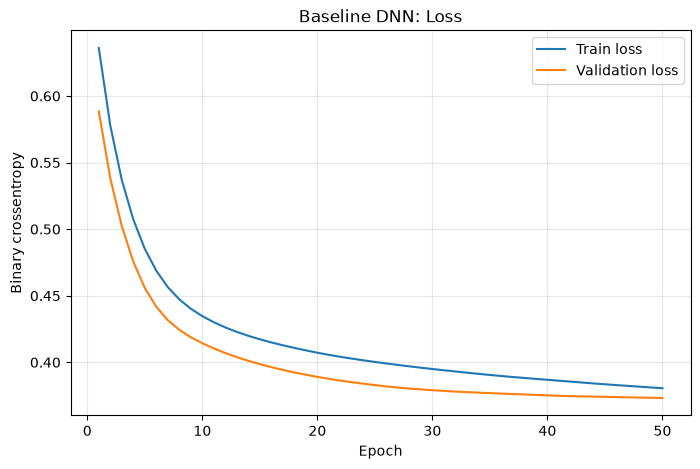

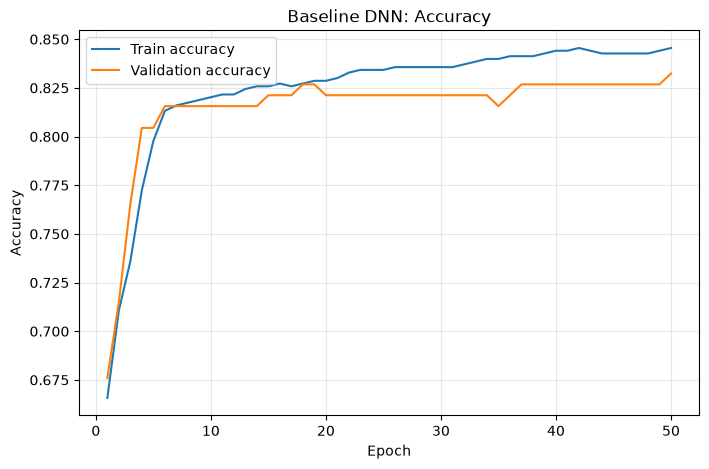

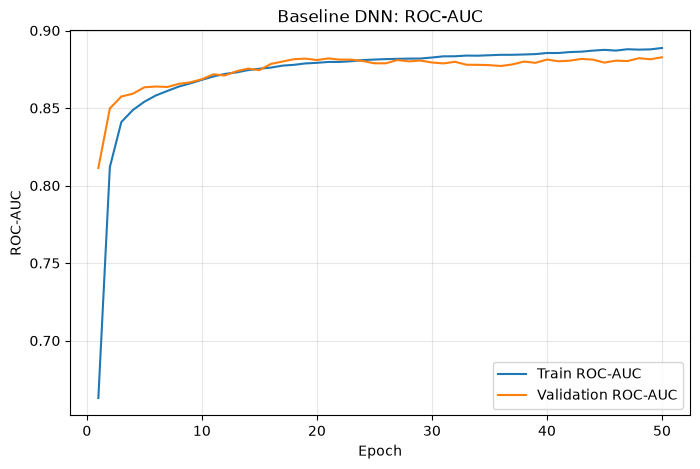

In [815]:
# Шаг 122.4. Строю learning curves baseline DNN

import matplotlib.pyplot as plt


epochs = range(1, len(history_baseline.history["loss"]) + 1)



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_baseline.history["loss"],
    label="Train loss"
)

plt.plot(
    epochs,
    history_baseline.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.title("Baseline DNN: Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_baseline.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    epochs,
    history_baseline.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline DNN: Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.show()



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history_baseline.history["roc_auc"],
    label="Train ROC-AUC"
)

plt.plot(
    epochs,
    history_baseline.history["val_roc_auc"],
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Baseline DNN: ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [816]:
# Шаг 123.1. Создаю более глубокую DNN

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# Для воспроизводимости эксперимента
tf.keras.utils.set_random_seed(43)

n_features = X_train_dnn_processed.shape[1]

deep_model = keras.Sequential([
    
    layers.Input(shape=(n_features,)),
    
    layers.Dense(64, activation="relu"),
    
    layers.Dense(32, activation="relu"),
    
    layers.Dense(16, activation="relu"),
    
    layers.Dense(1, activation="sigmoid")
])

deep_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="roc_auc")
    ]
)

deep_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,777 (14.75 KB)

 Trainable params: 3,777 (14.75 KB)

 Non-trainable params: 0 (0.00 B)

In [817]:
# Шаг 123.2. Обучаю более глубокую DNN

deep_history = deep_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5997 - loss: 0.6787 - roc_auc: 0.6845 - val_accuracy: 0.7765 - val_loss: 0.6270 - val_roc_auc: 0.8283
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7992 - loss: 0.5772 - roc_auc: 0.8294 - val_accuracy: 0.8268 - val_loss: 0.5127 - val_roc_auc: 0.8528
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8216 - loss: 0.4746 - roc_auc: 0.8486 - val_accuracy: 0.8324 - val_loss: 0.4234 - val_roc_auc: 0.8698
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8272 - loss: 0.4242 - roc_auc: 0.8644 - val_accuracy: 0.8380 - val_loss: 0.3948 - val_roc_auc: 0.8755
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8315 - loss: 0.4063 - roc_auc: 0.8726 - val_accuracy: 0.8324 - val_loss: 0.3826 - val_roc_auc: 0.8791
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8343 - loss: 0.3968 - roc_auc: 0.8775 - val_accuracy: 0.8380 - val_loss: 0.3771 - val_roc_auc: 0.8800
Epoc

In [821]:
# Шаг 123.3. Сравниваю baseline и Deep DNN по лучшим эпохам

import numpy as np
import pandas as pd


comparison_dnn = pd.DataFrame({
    "model": [
        "Baseline DNN",
        "Deep DNN"
    ],
    
    "best_val_accuracy": [
        max(history_baseline.history["val_accuracy"]),
        max(deep_history.history["val_accuracy"])
    ],
    
    "best_val_roc_auc": [
        max(history_baseline.history["val_roc_auc"]),
        max(deep_history.history["val_roc_auc"])
    ],
    
    "min_val_loss": [
        min(history_baseline.history["val_loss"]),
        min(deep_history.history["val_loss"])
    ],
    
    "best_roc_auc_epoch": [
        np.argmax(history_baseline.history["val_roc_auc"]) + 1,
        np.argmax(deep_history.history["val_roc_auc"]) + 1
    ]
})

comparison_dnn

,model,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch
0,Baseline DNN,0.832402,0.882740,0.373209,50
1,Deep DNN,0.843575,0.886166,0.371396,16


In [822]:
# Шаг 124.1. Создаю Deep DNN с Batch Normalization

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(43)

n_features = X_train_dnn_processed.shape[1]

batchnorm_model = keras.Sequential([
    
    layers.Input(shape=(n_features,)),
    
    layers.Dense(64),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    
    layers.Dense(32),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    
    layers.Dense(16),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    
    layers.Dense(1, activation="sigmoid")
])

batchnorm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="roc_auc")
    ]
)

batchnorm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,225 (16.50 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 224 (896.00 B)

In [823]:
# Шаг 124.2. Обучаю Deep DNN с Batch Normalization

batchnorm_history = batchnorm_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7416 - loss: 0.5751 - roc_auc: 0.7833 - val_accuracy: 0.7207 - val_loss: 0.6561 - val_roc_auc: 0.7675
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8146 - loss: 0.4517 - roc_auc: 0.8697 - val_accuracy: 0.8324 - val_loss: 0.5889 - val_roc_auc: 0.8416
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8399 - loss: 0.4115 - roc_auc: 0.8867 - val_accuracy: 0.8324 - val_loss: 0.5434 - val_roc_auc: 0.8494
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8455 - loss: 0.3875 - roc_auc: 0.8993 - val_accuracy: 0.8492 - val_loss: 0.5049 - val_roc_auc: 0.8555
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8497 - loss: 0.3704 - roc_auc: 0.9073 - val_accuracy: 0.8547 - val_loss: 0.4784 - val_roc_auc: 0.8616
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8596 - loss: 0.3566 - roc_auc: 0.9136 - val_accuracy: 0.8492 - val_loss: 0.4552 - val_roc_auc: 0.8632
Epoc

In [824]:
# Шаг 124.3. Сравниваю Deep DNN и Deep DNN + BatchNorm

import numpy as np
import pandas as pd

batchnorm_comparison = pd.DataFrame({
    "model": [
        "Deep DNN",
        "Deep DNN + BatchNorm"
    ],

    "best_val_accuracy": [
        max(deep_history.history["val_accuracy"]),
        max(batchnorm_history.history["val_accuracy"])
    ],

    "best_val_roc_auc": [
        max(deep_history.history["val_roc_auc"]),
        max(batchnorm_history.history["val_roc_auc"])
    ],

    "min_val_loss": [
        min(deep_history.history["val_loss"]),
        min(batchnorm_history.history["val_loss"])
    ],

    "best_roc_auc_epoch": [
        np.argmax(deep_history.history["val_roc_auc"]) + 1,
        np.argmax(batchnorm_history.history["val_roc_auc"]) + 1
    ]
})

batchnorm_comparison

,model,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch
0,Deep DNN,0.843575,0.886166,0.371396,16
1,Deep DNN + BatchNorm,0.860335,0.892556,0.372560,26


In [825]:
# Шаг 125. Проверяю разные значения Dropout

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import numpy as np


dropout_rates = [0.1, 0.3, 0.5]

dropout_results = []
dropout_histories = {}


for dropout_rate in dropout_rates:

    tf.keras.utils.set_random_seed(43)

    model = keras.Sequential([
        layers.Input(shape=(n_features,)),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(16),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    
    dropout_histories[dropout_rate] = history

    
    best_epoch_index = np.argmax(
        history.history["val_roc_auc"]
    )

    dropout_results.append({
        "dropout_rate": dropout_rate,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


dropout_comparison = pd.DataFrame(dropout_results)

dropout_comparison

,dropout_rate,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,0.1,0.854749,0.888011,0.373597,21,0.905225
1,0.3,0.843575,0.889065,0.373070,35,0.884261
2,0.5,0.837989,0.880962,0.385298,49,0.853976


In [826]:
# Шаг 126. Сравниваю размеры слоёв и функции активации

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd


architectures = [
    ("32-16_relu", [32, 16], "relu"),
    ("64-32-16_relu",[64, 32, 16], "relu"),
    ("128-64-32_relu",[128, 64, 32], "relu"),
    ("64-32-16_elu",[64, 32, 16], "elu"),
    ("64-32-16_tanh",[64, 32, 16], "tanh")
]


architecture_results = []
architecture_histories = {}


for experiment_name, hidden_units, activation_name in architectures:
    tf.keras.utils.set_random_seed(43)
    model = keras.Sequential()
    model.add(layers.Input(shape=(n_features,)))


    
    for units in hidden_units
        model.add(layers.Dense(units))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation_name))
        model.add(layers.Dropout(0.3))


    
    model.add(
        layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    architecture_histories[experiment_name] = history

    best_epoch_index = np.argmax(history.history["val_roc_auc"])

    architecture_results.append({
        "architecture": experiment_name,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


architecture_comparison = pd.DataFrame(
    architecture_results
)

architecture_comparison

,architecture,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,32-16_relu,0.843575,0.883663,0.371735,42,0.872099
1,64-32-16_relu,0.843575,0.889065,0.373070,35,0.884261
2,128-64-32_relu,0.854749,0.890184,0.362983,21,0.889200
3,64-32-16_elu,0.832402,0.885046,0.374877,32,0.865758
4,64-32-16_tanh,0.826816,0.885178,0.388469,31,0.862312


In [827]:
 # Шаг 127. Сравниваю разные оптимизаторы

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd


def build_optimizer_model(optimizer):

    model = keras.Sequential([
        layers.Input(shape=(n_features,)),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    return model


optimizers = {
    "Adam": keras.optimizers.Adam(),
    "RMSprop": keras.optimizers.RMSprop(),
    "SGD": keras.optimizers.SGD()
}


optimizer_results = []
optimizer_histories = {}


for optimizer_name, optimizer in optimizers.items():

    tf.keras.utils.set_random_seed(43)

    model = build_optimizer_model(optimizer)

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    optimizer_histories[optimizer_name] = history

    best_epoch_index = np.argmax(history.history["val_roc_auc"])

    optimizer_results.append({
        "optimizer": optimizer_name,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


optimizer_comparison = pd.DataFrame(optimizer_results)

optimizer_comparison

,optimizer,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,Adam,0.854749,0.890184,0.362983,21,0.889200
1,RMSprop,0.854749,0.892424,0.364588,27,0.886835
2,SGD,0.826816,0.884848,0.382901,26,0.849679


In [828]:
# Шаг 128.1. Добавляю CosineDecay scheduler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


steps_per_epoch = int(np.ceil(len(X_train_dnn_processed) / 32))

total_steps = steps_per_epoch * 50


print("Steps per epoch:", steps_per_epoch)
print("Total training steps:", total_steps)


cosine_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.001,
    decay_steps=total_steps,
    alpha=0.01
)

scheduled_optimizer = keras.optimizers.RMSprop(learning_rate=cosine_schedule)
tf.keras.utils.set_random_seed(43)
scheduler_model = build_optimizer_model(scheduled_optimizer)
scheduler_model.summary()

Steps per epoch: 23
Total training steps: 1150


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_53 (Dense)                │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_35 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_36 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_37 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,121 (51.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [829]:
# Шаг 128.2. Обучаю DNN с CosineDecay scheduler

scheduler_history = scheduler_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6587 - loss: 0.6807 - roc_auc: 0.7044 - val_accuracy: 0.8101 - val_loss: 0.6056 - val_roc_auc: 0.8744
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7346 - loss: 0.5418 - roc_auc: 0.8026 - val_accuracy: 0.8156 - val_loss: 0.5472 - val_roc_auc: 0.8826
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7781 - loss: 0.4996 - roc_auc: 0.8290 - val_accuracy: 0.8156 - val_loss: 0.5080 - val_roc_auc: 0.8773
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7949 - loss: 0.4940 - roc_auc: 0.8255 - val_accuracy: 0.8268 - val_loss: 0.4799 - val_roc_auc: 0.8787
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7851 - loss: 0.4798 - roc_auc: 0.8405 - val_accuracy: 0.8324 - val_loss: 0.4542 - val_roc_auc: 0.8780
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8132 - loss: 0.4516 - roc_auc: 0.8543 - val_accuracy: 0.8380 - val_loss: 0.4375 - val_roc_auc: 0.8831
Epoc

In [830]:
# Шаг 128.3. Оцениваю результат модели с CosineDecay

import numpy as np
import pandas as pd

best_epoch_index = np.argmax(scheduler_history.history["val_roc_auc"])

scheduler_result = pd.DataFrame({
    "model": [
        "RMSprop",
        "RMSprop + CosineDecay"
    ],

    "best_val_accuracy": [
        0.854749,
        max(scheduler_history.history["val_accuracy"])

    ],

    "best_val_roc_auc": [
        0.892424,
        scheduler_history.history["val_roc_auc"][best_epoch_index]
    ],

    "min_val_loss": [
        0.364588,
        min(scheduler_history.history["val_loss"])
    ],

    "best_roc_auc_epoch": [
        27,
        best_epoch_index + 1
    ],

    "train_roc_auc_at_best_epoch": [
        0.886835,
        scheduler_history.history["roc_auc"][best_epoch_index]
    ]
})

scheduler_result

,model,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,RMSprop,0.854749,0.892424,0.364588,27,0.886835
1,RMSprop + CosineDecay,0.854749,0.891041,0.366073,26,0.889651


In [832]:
# Шаг 129.1. Сравниваю разные значения learning rate

learning_rates = [
    0.0001,
    0.001,
    0.01
]

lr_results = []
lr_histories = {}


for lr in learning_rates:
    tf.keras.utils.set_random_seed(43)
    optimizer = keras.optimizers.RMSprop(learning_rate=lr)
    model = build_optimizer_model(optimizer)
    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=32,
        verbose=0
    )

    lr_histories[lr] = history
    best_epoch_index = np.argmax(history.history["val_roc_auc"])
    lr_results.append({
        "learning_rate": lr,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


lr_comparison = pd.DataFrame(lr_results)

lr_comparison

,learning_rate,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,0.0001,0.832402,0.887549,0.384740,50,0.859291
1,0.0010,0.854749,0.892424,0.364588,27,0.886835
2,0.0100,0.865922,0.888274,0.369382,8,0.891983


In [833]:
# Шаг 129.2. Сравниваю разные значения batch_size

batch_sizes = [16, 32, 64]

batch_results = []
batch_histories = {}


for batch_size in batch_sizes:
    tf.keras.utils.set_random_seed(43)
    optimizer = keras.optimizers.RMSprop(learning_rate=0.001)
    model = build_optimizer_model(optimizer)
    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=50,
        batch_size=batch_size,
        verbose=0
    )

    batch_histories[batch_size] = history
    best_epoch_index = np.argmax(history.history["val_roc_auc"])
    batch_results.append({
        "batch_size": 
        batch_size,
        "best_val_accuracy":
        max(history.history["val_accuracy"]),
        "best_val_roc_auc":
        history.history["val_roc_auc"][best_epoch_index],
        "min_val_loss":
        min(history.history["val_loss"]),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        history.history["roc_auc"][best_epoch_index]
    })


batch_comparison = pd.DataFrame(batch_results)

batch_comparison

,batch_size,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,16,0.854749,0.900066,0.358278,20,0.900974
1,32,0.854749,0.892424,0.364588,27,0.886835
2,64,0.854749,0.895059,0.368925,23,0.878278


In [834]:
# Шаг 129.3. Исследую влияние количества эпох

tf.keras.utils.set_random_seed(43)

optimizer = keras.optimizers.RMSprop(learning_rate=0.001)

epochs_model = build_optimizer_model(optimizer)

epochs_history = epochs_model.fit(
    X_train_dnn_processed,
    y_train_dnn,
    validation_data=(
        X_valid_dnn_processed,
        y_valid_dnn
    ),
    epochs=100,
    batch_size=16,
    verbose=0
)


epoch_limits = [25, 50, 100]

epochs_results = []


for epoch_limit in epoch_limits:

    val_roc_auc = np.array(epochs_history.history["val_roc_auc"][:epoch_limit])

    val_accuracy = np.array(epochs_history.history["val_accuracy"][:epoch_limit])

    val_loss = np.array(epochs_history.history["val_loss"][:epoch_limit])

    train_roc_auc = np.array(epochs_history.history["roc_auc"][:epoch_limit])

    best_epoch_index = np.argmax(val_roc_auc)

    epochs_results.append({
        "max_epochs":
        epoch_limit,
        "best_val_accuracy":    
        val_accuracy.max(),
        "best_val_roc_auc":
        val_roc_auc[best_epoch_index],
        "min_val_loss":
        val_loss.min(),
        "best_roc_auc_epoch":
        best_epoch_index + 1,
        "train_roc_auc_at_best_epoch":
        train_roc_auc[best_epoch_index]
    })


epochs_comparison = pd.DataFrame(epochs_results)

epochs_comparison

,max_epochs,best_val_accuracy,best_val_roc_auc,min_val_loss,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,25,0.849162,0.900066,0.358278,20,0.900974
1,50,0.854749,0.900066,0.358278,20,0.900974
2,100,0.871508,0.900066,0.358278,20,0.900974


In [835]:
# Шаг 129.4. Сравниваю разные loss functions

loss_functions = {
    "BinaryCrossentropy":
    keras.losses.BinaryCrossentropy(),

    "BinaryFocalCrossentropy":    
    keras.losses.BinaryFocalCrossentropy()
}

loss_results = []
loss_histories = {}


for loss_name, loss_function in loss_functions.items():

    tf.keras.utils.set_random_seed(43)

    optimizer = keras.optimizers.RMSprop(learning_rate=0.001)


    model = keras.Sequential([
        layers.Input(shape=(n_features,)),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.3),

        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=optimizer,
        loss=loss_function,
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="roc_auc")
        ]
    )

    history = model.fit(
        X_train_dnn_processed,
        y_train_dnn,
        validation_data=(
            X_valid_dnn_processed,
            y_valid_dnn
        ),
        epochs=25,
        batch_size=16,
        verbose=0
    )

    loss_histories[loss_name] = history

    best_epoch_index = np.argmax(history.history["val_roc_auc"])

    loss_results.append({
        "loss_function": loss_name,

        "best_val_accuracy":
            max(history.history["val_accuracy"]),

        "best_val_roc_auc":
            history.history["val_roc_auc"][best_epoch_index],

        "best_roc_auc_epoch":
            best_epoch_index + 1,

        "train_roc_auc_at_best_epoch":
            history.history["roc_auc"][best_epoch_index]
    })


loss_comparison = pd.DataFrame(loss_results)

loss_comparison

,loss_function,best_val_accuracy,best_val_roc_auc,best_roc_auc_epoch,train_roc_auc_at_best_epoch
0,BinaryCrossentropy,0.849162,0.900066,20,0.900974
1,BinaryFocalCrossentropy,0.860335,0.897365,4,0.807384


In [836]:
# Шаг 130.1. Проверяю категориальные признаки перед Embedding

X_embedding_check = TitanicFeatureTransformer().fit_transform(X.copy())

embedding_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]

for column in embedding_categorical_features:
    print(f"\n{column}")
    print("-" * 30)

    print(X_embedding_check[column].value_counts(dropna=False))

    print("Unique values:", X_embedding_check[column].nunique(dropna=False))


Pclass
------------------------------
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Unique values: 3

Sex
------------------------------
Sex
male      577
female    314
Name: count, dtype: int64
Unique values: 2

Embarked
------------------------------
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64
Unique values: 4

TitleGroup
------------------------------
TitleGroup
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64
Unique values: 5


In [837]:
# Шаг 130.2. Применяю feature engineering перед Embedding-моделью

embedding_feature_engineer = TitanicFeatureTransformer()

X_train_embedding = embedding_feature_engineer.fit_transform(X_train_dnn.copy())

X_valid_embedding = embedding_feature_engineer.transform(X_valid_dnn.copy())

print("Train shape:", X_train_embedding.shape)
print("Validation shape:", X_valid_embedding.shape)

print("\nTrain columns:")
print(X_train_embedding.columns.tolist())

print("\nMissing values:")
print(X_train_embedding[["Pclass", "Sex", "Embarked", "TitleGroup"]].isna().sum())

Train shape: (712, 11)
Validation shape: (179, 11)

Train columns:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name', 'TitleGroup', 'TicketGroupSize']

Missing values:
Pclass        0
Sex           0
Embarked      2
TitleGroup    0
dtype: int64


In [838]:
# Шаг 130.3. Заполняю пропуски в категориальных признаках

from sklearn.impute import SimpleImputer

embedding_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]

categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_embedding[embedding_categorical_features] = (categorical_imputer.fit_transform(X_train_embedding[embedding_categorical_features]))

X_valid_embedding[embedding_categorical_features] = (categorical_imputer.transform(X_valid_embedding[embedding_categorical_features]))

print("Missing categorical values in train:")
print(X_train_embedding[embedding_categorical_features].isna().sum())

print("\nMissing categorical values in validation:")
print(X_valid_embedding[embedding_categorical_features].isna().sum())

print("\nUnique categories in train:")

for column in embedding_categorical_features:
    print(f"\n{column}:")
    print(X_train_embedding[column].value_counts())

Missing categorical values in train:
Pclass        0
Sex           0
Embarked      0
TitleGroup    0
dtype: int64

Missing categorical values in validation:
Pclass        0
Sex           0
Embarked      0
TitleGroup    0
dtype: int64

Unique categories in train:

Pclass:
Pclass
3    391
1    171
2    150
Name: count, dtype: int64

Sex:
Sex
male      458
female    254
Name: count, dtype: int64

Embarked:
Embarked
S    504
C    144
Q     64
Name: count, dtype: int64

TitleGroup:
TitleGroup
Mr        414
Miss      148
Mrs       103
Master     30
Rare       17
Name: count, dtype: int64


In [839]:
# Шаг 130.4. Кодирую категориальные признаки в integer ID для Embedding

category_mappings = {}

for column in embedding_categorical_features:
    train_categories = X_train_embedding[column].unique()

    # Создаю словарь: категория -> integer ID
    # Начинаю с 1, потому что 0 резервирую для неизвестных категорий
    
    mapping = {
        category: index
        for index, category in enumerate(train_categories, start=1)
    }

    category_mappings[column] = mapping

    X_train_embedding[column] = (X_train_embedding[column].map(mapping).fillna(0).astype("int32"))
    X_valid_embedding[column] = (X_valid_embedding[column].map(mapping).fillna(0).astype("int32"))


for column, mapping in category_mappings.items():
    print(f"\n{column}:")
    print(mapping)


print("\nEncoded train:")
print(X_train_embedding[embedding_categorical_features].head())


print("\nEncoded validation:")
print(X_valid_embedding[embedding_categorical_features].head())


Pclass:
{2: 1, 3: 2, 1: 3}

Sex:
{'male': 1, 'female': 2}

Embarked:
{'S': 1, 'C': 2, 'Q': 3}

TitleGroup:
{'Mr': 1, 'Mrs': 2, 'Miss': 3, 'Master': 4, 'Rare': 5}

Encoded train:
     Pclass  Sex  Embarked  TitleGroup
234       1    1         1           1
874       1    2         2           2
744       2    1         1           1
90        2    1         1           1
32        2    2         3           3

Encoded validation:
     Pclass  Sex  Embarked  TitleGroup
876       2    1         1           1
449       3    1         1           5
117       1    1         1           1
461       2    1         1           1
372       2    1         1           1


In [840]:
# Шаг 130.5. Подготавливаю числовые признаки для Embedding-модели

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


embedding_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "TicketGroupSize"
]

embedding_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_numeric = embedding_numeric_pipeline.fit_transform(X_train_embedding[embedding_numeric_features])

X_valid_numeric = embedding_numeric_pipeline.transform(X_valid_embedding[embedding_numeric_features])

print("Train numeric shape:", X_train_numeric.shape)
print("Validation numeric shape:", X_valid_numeric.shape)

print("\nTrain dtype:", X_train_numeric.dtype)
print("Validation dtype:", X_valid_numeric.dtype)

print("\nNaN in train:", np.isnan(X_train_numeric).sum())
print("NaN in validation:", np.isnan(X_valid_numeric).sum())

print("\nFirst 3 processed train rows:")
print(X_train_numeric[:3])

Train numeric shape: (712, 5)
Validation numeric shape: (179, 5)

Train dtype: float64
Validation dtype: float64

NaN in train: 0
NaN in validation: 0

First 3 processed train rows:
[[-0.40453591 -0.48234947 -0.47780431 -0.42940947 -0.54418919]
 [-0.0947784   0.4310357  -0.47780431 -0.17088333  0.24333663]
 [ 0.13753973 -0.48234947 -0.47780431 -0.47872093 -0.54418919]]


In [841]:
# Шаг 130.6. Создаю отдельные categorical inputs для Embedding

X_train_categorical = {}
X_valid_categorical = {}

for column in embedding_categorical_features:

    X_train_categorical[column] = (X_train_embedding[column].to_numpy(dtype="int32").reshape(-1, 1))

    X_valid_categorical[column] = (X_valid_embedding[column].to_numpy(dtype="int32").reshape(-1, 1))


for column in embedding_categorical_features:

    print(f"\n{column}")
    print("Train shape:", X_train_categorical[column].shape)
    print("Validation shape:", X_valid_categorical[column].shape)
    print("Train dtype:", X_train_categorical[column].dtype)
    print("Train IDs:", np.unique(X_train_categorical[column]))


Pclass
Train shape: (712, 1)
Validation shape: (179, 1)
Train dtype: int32
Train IDs: [1 2 3]

Sex
Train shape: (712, 1)
Validation shape: (179, 1)
Train dtype: int32
Train IDs: [1 2]

Embarked
Train shape: (712, 1)
Validation shape: (179, 1)
Train dtype: int32
Train IDs: [1 2 3]

TitleGroup
Train shape: (712, 1)
Validation shape: (179, 1)
Train dtype: int32
Train IDs: [1 2 3 4 5]


In [842]:
# Шаг 130.7. Создаю отдельный Embedding-слой для TitleGroup

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


title_input = keras.Input(
    shape=(1,),
    dtype="int32",
    name="TitleGroup"
)

title_embedding = layers.Embedding(
    input_dim=6,
    output_dim=2,
    name="TitleGroup_embedding"
)(title_input)

title_embedding_flat = layers.Flatten(name="TitleGroup_flatten")(title_embedding)

title_embedding_model = keras.Model(inputs=title_input, outputs=title_embedding_flat)

title_embedding_model.summary()

Model: "functional_83"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ TitleGroup (InputLayer)         │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ TitleGroup_embedding            │ (None, 1, 2)           │            12 │
│ (Embedding)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ TitleGroup_flatten (Flatten)    │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12 (48.00 B)

 Trainable params: 12 (48.00 B)

 Non-trainable params: 0 (0.00 B)

In [843]:
# Шаг 130.8. Создаю Embedding-ветки для всех категориальных признаков

embedding_dims = {
    "Pclass": 2,
    "Sex": 2,
    "Embarked": 2,
    "TitleGroup": 2
}

categorical_inputs = {}
categorical_embeddings = []

for column in embedding_categorical_features:
    input_layer = keras.Input(
        shape=(1,),
        dtype="int32",
        name=column
    )

    categorical_inputs[column] = input_layer

    input_dim = len(category_mappings[column]) + 1

    embedding_layer = layers.Embedding(
        input_dim=input_dim,
        output_dim=embedding_dims[column],
        name=f"{column}_embedding"
    )(input_layer)

    
    flattened_embedding = layers.Flatten(name=f"{column}_flatten")(embedding_layer)

    categorical_embeddings.append(flattened_embedding)


print("Number of categorical inputs:", len(categorical_inputs))
print("Number of embedding outputs:", len(categorical_embeddings))

print("\nInput names:")
print(list(categorical_inputs.keys()))

print("\nEmbedding dimensions:")
for column in embedding_categorical_features:
    print(column, "->", embedding_dims[column])

Number of categorical inputs: 4
Number of embedding outputs: 4

Input names:
['Pclass', 'Sex', 'Embarked', 'TitleGroup']

Embedding dimensions:
Pclass -> 2
Sex -> 2
Embarked -> 2
TitleGroup -> 2


In [844]:
# Шаг 130.9. Объединяю numeric-признаки и Embedding-векторы

numeric_input = keras.Input(
    shape=(len(embedding_numeric_features),),
    dtype="float32",
    name="numeric"
)


combined_features = layers.Concatenate(name="combined_features")([numeric_input] + categorical_embeddings)


embedding_feature_model = keras.Model(
    inputs=[
        numeric_input,
        *categorical_inputs.values()
    ],
    outputs=combined_features,
    name="embedding_feature_model"
)

embedding_feature_model.summary()

Model: "embedding_feature_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Pclass (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sex (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embarked            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TitleGroup          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Pclass_embedding    │ (None, 1, 2)      │          8 │ Pclass[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sex_embedding       │ (None, 1, 2)      │          6 │ Sex[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embarked_embedding  │ (None, 1, 2)      │          8 │ Embarked[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TitleGroup_embeddi… │ (None, 1, 2)      │         12 │ TitleGroup[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Pclass_flatten      │ (None, 2)         │          0 │ Pclass_embedding… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sex_flatten         │ (None, 2)         │          0 │ Sex_embedding[0]… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embarked_flatten    │ (None, 2)         │          0 │ Embarked_embeddi… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TitleGroup_flatten  │ (None, 2)         │          0 │ TitleGroup_embed… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 13)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ Pclass_flatten[0… │
│                     │                   │            │ Sex_flatten[0][0… │
│                     │                   │            │ Embarked_flatten… │
│                     │                   │            │ TitleGroup_flatt… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 34 (136.00 B)

 Trainable params: 34 (136.00 B)

 Non-trainable params: 0 (0.00 B)

In [845]:
# Шаг 130.10. Строю DNN с Embedding для категориальных признаков

x = combined_features


x = layers.Dense(
    128,
    use_bias=False,
    name="dense_128"
)(x)

x = layers.BatchNormalization(name="batch_norm_128")(x)
x = layers.Activation("relu", name="relu_128")(x)
x = layers.Dropout(0.1, name="dropout_128")(x)


x = layers.Dense(
    64,
    use_bias=False,
    name="dense_64"
)(x)

x = layers.BatchNormalization(name="batch_norm_64")(x)
x = layers.Activation("relu", name="relu_64")(x)
x = layers.Dropout(0.1, name="dropout_64")(x)


x = layers.Dense(
    32,
    use_bias=False,
    name="dense_32"
)(x)

x = layers.BatchNormalization(name="batch_norm_32")(x)
x = layers.Activation("relu", name="relu_32")(x)
x = layers.Dropout(0.1, name="dropout_32")(x)


# Выход бинарной классификации
output = layers.Dense(
    1,
    activation="sigmoid",
    name="survival_probability"
)(x)


embedding_dnn = keras.Model(
    inputs=[
        numeric_input,
        *categorical_inputs.values()
    ],
    outputs=output,
    name="titanic_embedding_dnn"
)

embedding_dnn.summary()

Model: "titanic_embedding_dnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Pclass (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sex (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embarked            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TitleGroup          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Pclass_embedding    │ (None, 1, 2)      │          8 │ Pclass[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sex_embedding       │ (None, 1, 2)      │          6 │ Sex[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embarked_embedding  │ (None, 1, 2)      │          8 │ Embarked[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TitleGroup_embeddi… │ (None, 1, 2)      │         12 │ TitleGroup[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Pclass_flatten      │ (None, 2)         │          0 │ Pclass_embedding… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sex_flatten         │ (None, 2)         │          0 │ Sex_embedding[0]… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Embarked_flatten    │ (None, 2)         │          0 │ Embarked_embeddi… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TitleGroup_flatten  │ (None, 2)         │          0 │ TitleGroup_embed… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 13)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ Pclass_flatten[0… │
│                     │                   │            │ Sex_flatten[0][0… │
│                     │                   │            │ Embarked_flatten… │
│                     │                   │            │ TitleGroup_flatt… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │      1,664 │ combined_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_norm_128      │ (None, 128)       │        512 │ dense_128[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu_128            │ (None, 128)       │          0 │ batch_norm_128[0

 Total params: 12,867 (50.26 KB)

 Trainable params: 12,419 (48.51 KB)

 Non-trainable params: 448 (1.75 KB)

In [849]:
# Шаг 130.11. Собираю входные данные для Embedding DNN

X_train_embedding = {
    "numeric": X_train_numeric.astype("float32"),
    "Pclass": X_train_categorical["Pclass"].astype("int32"),
    "Sex": X_train_categorical["Sex"].astype("int32"),
    "Embarked": X_train_categorical["Embarked"].astype("int32"),
    "TitleGroup": X_train_categorical["TitleGroup"].astype("int32")
}

X_valid_embedding = {
    "numeric": X_valid_numeric.astype("float32"),
    "Pclass": X_valid_categorical["Pclass"].astype("int32"),
    "Sex": X_valid_categorical["Sex"].astype("int32"),
    "Embarked": X_valid_categorical["Embarked"].astype("int32"),
    "TitleGroup": X_valid_categorical["TitleGroup"].astype("int32")
}


print("TRAIN")
print("-" * 50)

for name, values in X_train_embedding.items():
    print(
        f"{name:12}"
        f"shape={values.shape},"
        f"dtype={values.dtype}"
    )


print("\nVALIDATION")
print("-" * 50)

for name, values in X_valid_embedding.items():
    print(
        f"{name:12}"
        f"shape={values.shape},"
        f"dtype={values.dtype}"
    )

TRAIN
--------------------------------------------------
numeric     shape=(712, 5),dtype=float32
Pclass      shape=(712, 1),dtype=int32
Sex         shape=(712, 1),dtype=int32
Embarked    shape=(712, 1),dtype=int32
TitleGroup  shape=(712, 1),dtype=int32

VALIDATION
--------------------------------------------------
numeric     shape=(179, 5),dtype=float32
Pclass      shape=(179, 1),dtype=int32
Sex         shape=(179, 1),dtype=int32
Embarked    shape=(179, 1),dtype=int32
TitleGroup  shape=(179, 1),dtype=int32


In [850]:
# Шаг 130.12. Проверяю диапазоны ID для Embedding

categorical_names = [
    "Pclass",
    "Sex",
    "Embarked",
    "TitleGroup"
]

for name in categorical_names:
    
    train_values = X_train_embedding[name]
    valid_values = X_valid_embedding[name]

    embedding_layer = embedding_dnn.get_layer(f"{name}_embedding")
    input_dim = embedding_layer.input_dim

    train_min = train_values.min()
    train_max = train_values.max()

    valid_min = valid_values.min()
    valid_max = valid_values.max()

    print(name)
    print("-" * 40)

    print(
        f"Train IDs:      min={train_min},"
        f"max={train_max}"
    )

    print(
        f"Validation IDs: min={valid_min},"
        f"max={valid_max}"
    )

    print(f"Embedding input_dim: {input_dim}")

    assert train_min >= 0
    assert valid_min >= 0

    assert train_max < input_dim
    assert valid_max < input_dim

    print("Status: OK\n")

Pclass
----------------------------------------
Train IDs:      min=1,max=3
Validation IDs: min=1,max=3
Embedding input_dim: 4
Status: OK

Sex
----------------------------------------
Train IDs:      min=1,max=2
Validation IDs: min=1,max=2
Embedding input_dim: 3
Status: OK

Embarked
----------------------------------------
Train IDs:      min=1,max=3
Validation IDs: min=1,max=3
Embedding input_dim: 4
Status: OK

TitleGroup
----------------------------------------
Train IDs:      min=1,max=5
Validation IDs: min=1,max=5
Embedding input_dim: 6
Status: OK



In [851]:
# Шаг 130.13. Компилирую Embedding DNN

import tensorflow as tf


embedding_dnn.compile(
    optimizer=tf.keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.AUC(
            name="roc_auc"
        )
    ]
)

print("Embedding DNN compiled successfully.")

Embedding DNN compiled successfully.


In [852]:
# Шаг 130.14. Настраиваю callbacks для Embedding DNN

early_stopping_embedding = tf.keras.callbacks.EarlyStopping(
    monitor="val_roc_auc",
    mode="max",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

embedding_callbacks = [early_stopping_embedding]


print("Callbacks configured successfully.")

Callbacks configured successfully.


In [859]:
# Шаг 130.15. Обучаю Embedding DNN

embedding_history = embedding_dnn.fit(
    X_train_embedding,
    y_train_dnn,
    validation_data=(X_valid_embedding, y_valid_dnn),
    epochs=100,
    batch_size=16,
    callbacks=embedding_callbacks,
    verbose=1
)

Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6728 - loss: 0.6134 - roc_auc: 0.6898 - val_accuracy: 0.7542 - val_loss: 0.6348 - val_roc_auc: 0.8013
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7079 - loss: 0.5536 - roc_auc: 0.7644 - val_accuracy: 0.7430 - val_loss: 0.5961 - val_roc_auc: 0.8287
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 951us/step - accuracy: 0.7654 - loss: 0.5087 - roc_auc: 0.8134 - val_accuracy: 0.7486 - val_loss: 0.5456 - val_roc_auc: 0.8494
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7963 - loss: 0.4747 - roc_auc: 0.8426 - val_accuracy: 0.7709 - val_loss: 0.5093 - val_roc_auc: 0.8569
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 914us/step - accuracy: 0.8020 - loss: 0.4516 - roc_auc: 0.8589 - val_accuracy: 0.8156 - val_loss: 0.4696 - val_roc_auc: 0.8613
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 953us/step - accuracy: 0.8076 - loss: 0.4409 - roc_auc: 0.8660 - val_accuracy: 0.7933 - val_loss: 0.4463 - val_roc_auc:

In [860]:
# Шаг 130.16. Анализирую лучшую эпоху Embedding DNN

best_epoch_idx = int(np.argmax(embedding_history.history["val_roc_auc"]))

best_epoch = best_epoch_idx + 1

embedding_result = {
    "model": "Embedding DNN",
    "best_val_accuracy": embedding_history.history["val_accuracy"][best_epoch_idx],
    "best_val_roc_auc": embedding_history.history["val_roc_auc"][best_epoch_idx],
    "val_loss_at_best_epoch": embedding_history.history["val_loss"][best_epoch_idx],
    "best_roc_auc_epoch": best_epoch,
    "train_roc_auc_at_best_epoch": embedding_history.history["roc_auc"][best_epoch_idx]
}

embedding_result

{'model': 'Embedding DNN',
 'best_val_accuracy': 0.7988826632499695,
 'best_val_roc_auc': 0.8739789128303528,
 'val_loss_at_best_epoch': 0.4177069067955017,
 'best_roc_auc_epoch': 16,
 'train_roc_auc_at_best_epoch': 0.9168940782546997}

In [861]:
# Шаг 130.17. Сравниваю Embedding DNN с предыдущим лучшим DNN-результатом

embedding_comparison = pd.DataFrame([
    {"model": "Best previous DNN",
     "best_val_accuracy": 0.854749,
     "best_val_roc_auc": 0.900066
    },
    {"model": embedding_result["model"],
     "best_val_accuracy": embedding_result["best_val_accuracy"],
     "best_val_roc_auc": embedding_result["best_val_roc_auc"]
    }
])

embedding_comparison["roc_auc_difference_vs_best_dnn"] = (embedding_comparison["best_val_roc_auc"] - 0.900066)

embedding_comparison

,model,best_val_accuracy,best_val_roc_auc,roc_auc_difference_vs_best_dnn
0,Best previous DNN,0.854749,0.900066,0.000000
1,Embedding DNN,0.798883,0.873979,-0.026087


In [864]:
# Шаг 130.18. Оцениваю Embedding DNN на validation

from sklearn.metrics import classification_report, confusion_matrix

embedding_valid_proba = embedding_dnn.predict(
    X_valid_embedding,
    verbose=0
).ravel()

embedding_valid_pred = (embedding_valid_proba >= 0.5).astype(int)

print(classification_report(
        y_valid_dnn,
        embedding_valid_pred,
        digits=4
    )
)

print("Confusion matrix:")
print(confusion_matrix(
        y_valid_dnn,
        embedding_valid_pred
    )
)

              precision    recall  f1-score   support

           0     0.8426    0.8273    0.8349       110
           1     0.7324    0.7536    0.7429        69

    accuracy                         0.7989       179
   macro avg     0.7875    0.7904    0.7889       179
weighted avg     0.8001    0.7989    0.7994       179

Confusion matrix:
[[91 19]
 [17 52]]


In [865]:
# Шаг 130.19. Фиксирую итог Embedding-эксперимента
# -------------------------------------------------
# Вывод: я проверил альтернативное представление категориальных признаков через обучаемые Embedding-слои. 
# Для Pclass, Sex, Embarked и TitleGroup были созданы отдельные embeddings размерности 2, которые затем объединялись с пятью числовыми признаками и передавались в DNN.
# Лучший validation ROC-AUC Embedding DNN составил 0.8740, accuracy — 0.7989. 
# Предыдущая DNN достигала ROC-AUC 0.9001, поэтому использование embeddings снизило ROC-AUC примерно на 0.0261.
# ------------------------------------------------
# Вероятная причина — низкая кардинальность категориальных признаков: Sex содержит 2 категории, Pclass и Embarked — по 3, TitleGroup — 5. 
# Для такого небольшого числа категорий обучаемые векторные представления не дали преимущества более простому кодированию.
# Поэтому Embedding DNN сохраняю как отдельный эксперимент, но не выбираю её в качестве основной нейросетевой модели.

In [866]:
# Шаг 131. Сравниваю финальные DNN-эксперименты

dnn_final_comparison = pd.DataFrame({
    "model": [
        "Deep DNN",
        "Deep DNN + BatchNorm",
        "Best tuned DNN",
        "Embedding DNN"
    ],
    
    "best_val_roc_auc": [
        0.886166,
        0.892556,
        0.900066,
        0.873979
    ],
    
    "best_val_accuracy": [
        0.843575,
        0.860335,
        0.854749,
        0.798883
    ]
})

dnn_final_comparison = (dnn_final_comparison.sort_values("best_val_roc_auc", ascending=False).reset_index(drop=True))

dnn_final_comparison

,model,best_val_roc_auc,best_val_accuracy
0,Best tuned DNN,0.900066,0.854749
1,Deep DNN + BatchNorm,0.892556,0.860335
2,Deep DNN,0.886166,0.843575
3,Embedding DNN,0.873979,0.798883


In [867]:
# Шаг 132. Фиксирую лучшую DNN-конфигурацию

best_dnn_config = {
    "architecture": [128, 64, 32],
    "activation": "relu",
    "batch_normalization": True,
    "dropout_rate": 0.3,
    "optimizer": "RMSprop",
    "learning_rate": 0.001,
    "batch_size": 16,
    "max_epochs": 100,
    "loss": "BinaryCrossentropy",
    "best_val_roc_auc": 0.900066
}

best_dnn_config

{'architecture': [128, 64, 32],
 'activation': 'relu',
 'batch_normalization': True,
 'dropout_rate': 0.3,
 'optimizer': 'RMSprop',
 'learning_rate': 0.001,
 'batch_size': 16,
 'max_epochs': 100,
 'loss': 'BinaryCrossentropy',
 'best_val_roc_auc': 0.900066}

In [868]:
# Шаг 133. Фиксирую результаты Classic ML и DNN

classic_ml_cv_results = {
    "Random Forest": {
        "cv_accuracy_mean": 0.8114,
        "cv_accuracy_std": 0.0214
    },
    "KNN": {
        "cv_accuracy_mean": 0.8070,
        "cv_accuracy_std": 0.0189
    },
    "Logistic Regression": {
        "cv_accuracy_mean": 0.7969,
        "cv_accuracy_std": 0.0146
    },
    "Decision Tree": {
        "cv_accuracy_mean": 0.783
    }
}

dnn_validation_results = {
    "Best tuned DNN": {
        "val_accuracy": 0.854749,
        "val_roc_auc": 0.900066
    }
}


print("Classic ML — 5-fold CV:")
for model_name, metrics in classic_ml_cv_results.items():
    print(model_name, metrics)

print("\nDNN — validation split:")
for model_name, metrics in dnn_validation_results.items():
    print(model_name, metrics)

Classic ML — 5-fold CV:
Random Forest {'cv_accuracy_mean': 0.8114, 'cv_accuracy_std': 0.0214}
KNN {'cv_accuracy_mean': 0.807, 'cv_accuracy_std': 0.0189}
Logistic Regression {'cv_accuracy_mean': 0.7969, 'cv_accuracy_std': 0.0146}
Decision Tree {'cv_accuracy_mean': 0.783}

DNN — validation split:
Best tuned DNN {'val_accuracy': 0.854749, 'val_roc_auc': 0.900066}


# Финализация классического ML и Kaggle submission

После DL-экспериментов возвращаюсь к лучшим классическим моделям и фиксирую кандидата для итогового решения.

На этом этапе проверяю параметры и признаки финального Random Forest, обучаю модель на полном `train`, формирую Kaggle submission и затем отдельно исследую устойчивость решения, возможный leakage и переносимость feature engineering.


In [869]:
# Шаг 134. Проверяю существующие обученные sklearn-модели

from sklearn.base import ClassifierMixin

existing_classifiers = {}

for name, obj in list(globals().items()):
    if isinstance(obj, ClassifierMixin):
        existing_classifiers[name] = type(obj).__name__

print("Найденные sklearn-классификаторы:")
print("-" * 60)

if existing_classifiers:
    for variable_name, model_type in existing_classifiers.items():
        print(f"{variable_name:<35} {model_type}")
else:
    print("Готовые sklearn-классификаторы не найдены.")

Найденные sklearn-классификаторы:
------------------------------------------------------------
dummy_model                         DummyClassifier
_284                                RandomForestClassifier
_312                                RandomForestClassifier
rf_calibrated_sigmoid               CalibratedClassifierCV
_527                                CalibratedClassifierCV
rf_calibrated_isotonic              CalibratedClassifierCV
_535                                CalibratedClassifierCV
_536                                CalibratedClassifierCV
final_rf_model                      RandomForestClassifier
_543                                RandomForestClassifier
rf_model                            RandomForestClassifier
final_model                         RandomForestClassifier
final_rf                            RandomForestClassifier
current_model                       RandomForestClassifier
saved_model                         RandomForestClassifier
rf_without_ticket          

In [870]:
# Шаг 135. Проверяю кандидатов на финальный Random Forest

rf_candidate_names = [
    "final_rf_model",
    "rf_model",
    "final_model",
    "final_rf",
    "current_model",
    "saved_model",
    "rf_without_ticket",
    "rf_title",
    "baseline_rf"
]

print("Кандидаты на финальный Random Forest:")
print("-" * 80)

for name in rf_candidate_names:
    if name not in globals():
        continue

    obj = globals()[name]

    print(f"\n{name}")
    print(f"  type: {type(obj).__name__}")

    if hasattr(obj, "n_estimators"):
        print(f"  n_estimators: {obj.n_estimators}")

    if hasattr(obj, "max_depth"):
        print(f"  max_depth: {obj.max_depth}")

    if hasattr(obj, "min_samples_split"):
        print(f"  min_samples_split: {obj.min_samples_split}")

    if hasattr(obj, "min_samples_leaf"):
        print(f"  min_samples_leaf: {obj.min_samples_leaf}")

    if hasattr(obj, "max_features"):
        print(f"  max_features: {obj.max_features}")

    if hasattr(obj, "n_features_in_"):
        print(f"  n_features_in_: {obj.n_features_in_}")

Кандидаты на финальный Random Forest:
--------------------------------------------------------------------------------

final_rf_model
  type: RandomForestClassifier
  n_estimators: 500
  max_depth: 8
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: None
  n_features_in_: 13

rf_model
  type: RandomForestClassifier
  n_estimators: 500
  max_depth: 10
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: None
  n_features_in_: 13

final_model
  type: RandomForestClassifier
  n_estimators: 500
  max_depth: 8
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: None
  n_features_in_: 13

final_rf
  type: RandomForestClassifier
  n_estimators: 500
  max_depth: 10
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: None
  n_features_in_: 13

current_model
  type: RandomForestClassifier
  n_estimators: 500
  max_depth: 8
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: None
  n_features_in_: 13

saved_model
  type: RandomForestClassifier
  n_es

In [871]:
# Шаг 136. Ищу сохранённые таблицы с результатами Random Forest

import pandas as pd

result_tables = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        columns = [str(col) for col in obj.columns]

        # Ищем таблицы, похожие на результаты ML-экспериментов
        keywords = [
            "accuracy",
            "roc",
            "auc",
            "score",
            "model",
            "mean",
            "std"
        ]

        if any(
            keyword in col.lower()
            for col in columns
            for keyword in keywords
        ):
            result_tables.append(
                {"variable": name,
                 "shape": obj.shape,
                 "columns": columns
                }
            )

print("Найденные таблицы с результатами экспериментов:")
print("-" * 80)

for table in result_tables:
    print(f"\n{table['variable']}")
    print(f"  shape: {table['shape']}")
    print(f"  columns: {table['columns']}")

Найденные таблицы с результатами экспериментов:
--------------------------------------------------------------------------------

__
  shape: (2, 4)
  columns: ['Accuracy', 'Precision', 'Recall', 'F1']

_23
  shape: (7, 8)
  columns: ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']

_25
  shape: (2, 2)
  columns: ['count', 'mean']

_26
  shape: (3, 2)
  columns: ['count', 'mean']

_27
  shape: (4, 2)
  columns: ['count', 'mean']

results_df
  shape: (14, 7)
  columns: ['experiment', 'model', 'features', 'cv_folds', 'cv_mean', 'cv_std', 'params']

_50
  shape: (2, 7)
  columns: ['experiment', 'model', 'features', 'cv_folds', 'cv_mean', 'cv_std', 'params']

_61
  shape: (5, 7)
  columns: ['experiment', 'model', 'features', 'cv_folds', 'cv_mean', 'cv_std', 'params']

_62
  shape: (5, 8)
  columns: ['experiment', 'model', 'features', 'cv_folds', 'cv_mean', 'cv_std', 'params', 'improvement_vs_dummy']

_67
  shape: (9, 2)
  columns: ['count', 'mean']

_71
  shape: (2, 2)
  columns

In [872]:
# Шаг 137. Смотрю результаты финальных экспериментов Random Forest

print("rf_repeated_results:")
print("-" * 80)

display(rf_repeated_results)

rf_repeated_results:
--------------------------------------------------------------------------------


,model,train_accuracy,cv_accuracy,accuracy_std,gap,cv_roc_auc,roc_auc_std
0,current,0.931818,0.829623,0.023922,0.102195,0.875929,0.026049
1,depth_8,0.918069,0.829632,0.022548,0.088437,0.876863,0.027110
2,depth_7_leaf_2,0.898202,0.827392,0.020717,0.070811,0.876622,0.027063


In [873]:
# Шаг 138. Смотрю результаты регуляризации Random Forest

print("rf_regularization_results:")
print("-" * 80)

display(rf_regularization_results)

rf_regularization_results:
--------------------------------------------------------------------------------


,model,train_accuracy,cv_accuracy,gap,cv_std
0,current,0.934064,0.828266,0.105799,0.015082
1,depth_8,0.920032,0.829396,0.090637,0.009947
2,depth_7_leaf_2,0.898988,0.828272,0.070716,0.014594
3,depth_6_leaf_2,0.888326,0.821543,0.066783,0.009763


In [874]:
# Шаг 139. Проверяю параметры существующих Random Forest моделей

rf_candidates = [
    "final_rf_model",
    "rf_model",
    "final_model",
    "final_rf",
    "current_model",
    "saved_model",
    "rf_without_ticket",
    "rf_title",
    "baseline_rf",
]

for name in rf_candidates:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "get_params"):
            params = obj.get_params()

            print(f"\n{name}")
            print("-" * 50)
            print("n_estimators     :", params.get("n_estimators"))
            print("max_depth        :", params.get("max_depth"))
            print("min_samples_split:", params.get("min_samples_split"))
            print("min_samples_leaf :", params.get("min_samples_leaf"))
            print("max_features     :", params.get("max_features"))
            print("class_weight     :", params.get("class_weight"))
            print("criterion        :", params.get("criterion"))
            print("random_state     :", params.get("random_state"))


final_rf_model
--------------------------------------------------
n_estimators     : 500
max_depth        : 8
min_samples_split: 5
min_samples_leaf : 1
max_features     : None
class_weight     : None
criterion        : gini
random_state     : 43

rf_model
--------------------------------------------------
n_estimators     : 500
max_depth        : 10
min_samples_split: 5
min_samples_leaf : 1
max_features     : None
class_weight     : None
criterion        : gini
random_state     : 43

final_model
--------------------------------------------------
n_estimators     : 500
max_depth        : 8
min_samples_split: 5
min_samples_leaf : 1
max_features     : None
class_weight     : None
criterion        : gini
random_state     : 43

final_rf
--------------------------------------------------
n_estimators     : 500
max_depth        : 10
min_samples_split: 5
min_samples_leaf : 1
max_features     : None
class_weight     : None
criterion        : gini
random_state     : 43

current_model
----------

In [875]:
# Шаг 140. Проверяю признаки, на которых обучен final_rf_model

print("Количество признаков:")
print(final_rf_model.n_features_in_)

print("\nНазвания признаков:")

if hasattr(final_rf_model, "feature_names_in_"):
    print(final_rf_model.feature_names_in_)
else:
    print("feature_names_in_ отсутствует")
    print("Модель была обучена на массиве без сохранённых названий признаков.")

Количество признаков:
13

Названия признаков:
feature_names_in_ отсутствует
Модель была обучена на массиве без сохранённых названий признаков.


In [878]:
# Шаг 141. Ищу существующие списки признаков, содержащие ровно 13 признаков

for name, obj in list(globals().items()):
    if isinstance(obj, list):
        if len(obj) == 13 and all(isinstance(x, str) for x in obj):
            print(f"\n{name}")
            print("-" * 60)
            print(obj)

In [879]:
# Шаг 142. Смотрю сохранённую историю Classic ML экспериментов

print("Размер results_df:", results_df.shape)
print()

display(results_df[["experiment", "model", "features", "cv_mean", "cv_std", "params"]])

Размер results_df: (14, 7)



,experiment,model,features,cv_mean,cv_std,params
0,rf_ticket_tuned,RandomForestClassifier,basic + TicketGroupSize,0.847354,0.015723,"{'model__n_estimators': 500, 'model__min_sampl..."
1,catboost_tuned,CatBoostClassifier,basic + TicketGroupSize,0.837242,0.015259,"{'model__random_strength': 1, 'model__learning..."
2,catboost_initial,CatBoostClassifier,basic + TicketGroupSize,0.829396,0.021271,"iterations=500, learning_rate=0.05, depth=6"
3,rf_ticket_group_size,RandomForestClassifier,basic+TicketGroupSize,0.815912,0.025131,n_estimators=300
4,rf_family_ticket,RandomForestClassifier,basic+FamilySize+TicketGroupSize,0.811431,0.023044,n_estimators=300
5,baseline_random_forest,RandomForestClassifier,basic,0.811418,0.021424,n_estimators=300
6,rf_cabin_known,RandomForestClassifier,basic+CabinKnown,0.810288,0.024181,n_estimators=300
7,rf_family_features,RandomForestClassifier,basic+FAmilySize+IsAlone,0.809183,0.023711,n_estimators=300
8,rf_title_grouped,RandomForestClassifier,basic+TitleGrouped,0.809183,0.015703,n_estimators=300
9,baseline_knn,KneighborsClassifier,basic,0.806968,0.018900,n_neighbors=5


In [880]:
# Шаг 143. Ищу существующие объекты лучшего RF-эксперимента

keywords = ("ticket", "tuned", "pipeline")

for name in sorted(globals()):
    if any(word in name.lower() for word in keywords):
        obj = globals()[name]

        print(
            f"{name:<40}"
            f"type={type(obj).__name__}"
        )

Pipeline                                type=ABCMeta
TicketAndFamilyGroupTransformer         type=type
TicketAndFamilyTransformer              type=type
TicketGroupSizeTramsformer              type=type
TicketGroupSizeTransformer              type=type
X_family_ticket                         type=DataFrame
X_ticket                                type=DataFrame
baseline_pipeline                       type=Pipeline
best_catboost_pipeline                  type=Pipeline
best_rf_pipeline                        type=Pipeline
build_pipeline                          type=function
catboost_pipeline                       type=Pipeline
catboost_pipeline_clone                 type=Pipeline
categorical_features_family_ticket      type=list
categorical_features_ticket             type=list
categorical_pipeline                    type=Pipeline
categorical_pipeline_family             type=Pipeline
categorical_pipeline_family_group       type=Pipeline
categorical_pipeline_without_ticket     type=Pipeli

In [881]:
# Шаг 144. Проверяю существующие RF pipeline

candidate_names = [
    "best_rf_pipeline",
    "final_rf_pipeline",
    "rf_ticket_pipeline",
    "ticket_pipeline",
    "production_rf_pipeline",
    "saved_rf_pipeline",
    "selected_pipeline",
    "validation_rf_pipeline",
]

for name in candidate_names:
    if name not in globals():
        continue

    obj = globals()[name]

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    print("Pipeline steps:", list(obj.named_steps.keys()))

    for step_name, step_obj in obj.named_steps.items():
        if hasattr(step_obj, "n_estimators"):
            print(f"RF step: {step_name}")
            print("n_estimators       =", step_obj.n_estimators)
            print("max_depth          =", step_obj.max_depth)
            print("min_samples_split  =", step_obj.min_samples_split)
            print("min_samples_leaf   =", step_obj.min_samples_leaf)
            print("max_features       =", step_obj.max_features)
            print("random_state       =", step_obj.random_state)


best_rf_pipeline
Pipeline steps: ['ticket_features', 'preprocessor', 'model']
RF step: model
n_estimators       = 500
max_depth          = 10
min_samples_split  = 5
min_samples_leaf   = 1
max_features       = None
random_state       = 43

final_rf_pipeline
Pipeline steps: ['ticket_features', 'preprocessor', 'model']
RF step: model
n_estimators       = 500
max_depth          = 8
min_samples_split  = 5
min_samples_leaf   = 1
max_features       = None
random_state       = 43

rf_ticket_pipeline
Pipeline steps: ['ticket_features', 'preprocessor', 'model']
RF step: model
n_estimators       = 300
max_depth          = None
min_samples_split  = 2
min_samples_leaf   = 1
max_features       = sqrt
random_state       = 43

ticket_pipeline
Pipeline steps: ['feature_engineering', 'preprocessor', 'model']
RF step: model
n_estimators       = 500
max_depth          = 8
min_samples_split  = 5
min_samples_leaf   = 1
max_features       = None
random_state       = 43

production_rf_pipeline
Pipeline steps

In [883]:
# Шаг 145. Смотрю точную запись лучшего RF в results_df

rf_ticket_tuned_row = results_df.loc[
    results_df["experiment"] == "rf_ticket_tuned"
]

print(rf_ticket_tuned_row.to_string(index=False))

print("\nТочные params:")
print(rf_ticket_tuned_row["params"].iloc[0])

     experiment                  model                features  cv_folds  cv_mean   cv_std                                                                                                                                                                      params
rf_ticket_tuned RandomForestClassifier basic + TicketGroupSize         5 0.847354 0.015723 {'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': 10, 'model__class_weight': None}

Точные params:
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': 10, 'model__class_weight': None}


In [884]:
# Шаг 146. Проверяю структуру pipeline лучшего RF

pipeline_names = [
    "best_rf_pipeline",
    "production_rf_pipeline",
    "saved_rf_pipeline",
    "validation_rf_pipeline",
]

for name in pipeline_names:
    pipe = globals()[name]

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    for step_name, step_obj in pipe.named_steps.items():
        print(f"\nSTEP: {step_name}")
        print(step_obj)


best_rf_pipeline

STEP: ticket_features
TicketGroupSizeTransformer()

STEP: preprocessor
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'SibSp', 'Parch', 'Fare',
                                  'TicketGroupSize']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Pclass', 'Sex', 'Embarked'])])

STEP: model
RandomForestClassifier(max_depth=10, max_features=None, min_samples_split=5,
                  

In [885]:
# Шаг 147. Проверяю полный train перед финальным обучением

for name in [
    "X",
    "y",
    "X_train",
    "X_ticket",
    "train",
    "train_df",
    "df"
]:
    if name in globals():
        obj = globals()[name]

        shape = getattr(obj, "shape", None)
        obj_type = type(obj).__name__

        print(
            f"{name:<15}"
            f"type={obj_type:<15}"
            f"shape={shape}"
        )

X              type=DataFrame      shape=(891, 9)
y              type=Series         shape=(891,)
X_ticket       type=DataFrame      shape=(891, 8)
train          type=DataFrame      shape=(891, 19)


In [886]:
# Шаг 148. Обучаю финальный Random Forest на всём train

from sklearn.base import clone


final_production_pipeline = clone(best_rf_pipeline)
final_production_pipeline.fit(X, y)


print("Финальная модель обучена.")
print("Количество объектов:", len(X))
print("Pipeline:", final_production_pipeline.named_steps.keys())

rf = final_production_pipeline.named_steps["model"]

print("\nПараметры Random Forest:")
print("n_estimators:", rf.n_estimators)
print("max_depth:", rf.max_depth)
print("min_samples_split:", rf.min_samples_split)
print("min_samples_leaf:", rf.min_samples_leaf)
print("max_features:", rf.max_features)

Финальная модель обучена.
Количество объектов: 891
Pipeline: dict_keys(['ticket_features', 'preprocessor', 'model'])

Параметры Random Forest:
n_estimators: 500
max_depth: 10
min_samples_split: 5
min_samples_leaf: 1
max_features: None


In [887]:
# Шаг 149. Проверяю работу финального pipeline

sample = X.head(5)

sample_predictions = final_production_pipeline.predict(sample)
sample_probabilities = final_production_pipeline.predict_proba(sample)[:, 1]

print("Размер входных данных:", sample.shape)
print("Предсказания:", sample_predictions)
print("Вероятности класса 1:", sample_probabilities)

Размер входных данных: (5, 9)
Предсказания: [0 1 1 1 0]
Вероятности класса 1: [0.07738416 0.9775     0.57283907 1.         0.0824167 ]


In [891]:
# Шаг 150. Загружаю тестовую выборку Kaggle

import pandas as pd

test = pd.read_csv("../Data/raw/test.csv")

print("Размер test:", test.shape)
print("\nКолонки test:")
print(test.columns.tolist())

test.head()

Размер test: (418, 11)

Колонки test:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [892]:
# Шаг 151. Формирую X_test с теми же входными признаками, что использовались при обучении

print("Признаки обучающего X:")
print(X.columns.tolist())

X_test = test[X.columns].copy()

print("\nРазмер X_test:", X_test.shape)

print("\nПризнаки X_test:")
print(X_test.columns.tolist())

X_test.head()

Признаки обучающего X:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name']

Размер X_test: (418, 9)

Признаки X_test:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name']


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Ticket,Name
0,34.5,0,0,7.8292,3,male,Q,330911,"Kelly, Mr. James"
1,47.0,1,0,7.0000,3,female,S,363272,"Wilkes, Mrs. James (Ellen Needs)"
2,62.0,0,0,9.6875,2,male,Q,240276,"Myles, Mr. Thomas Francis"
3,27.0,0,0,8.6625,3,male,S,315154,"Wirz, Mr. Albert"
4,22.0,1,1,12.2875,3,female,S,3101298,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)"


In [893]:
# Шаг 152. Получаю предсказания на тестовой выборке Kaggle

test_predictions = final_production_pipeline.predict(X_test)

print("Количество предсказаний:", len(test_predictions))
print("Первые 20 предсказаний:")
print(test_predictions[:20])

print("\nРаспределение предсказанных классов:")
print(pd.Series(test_predictions).value_counts().sort_index())

print("\nДоля предсказанного класса 1:")
print(test_predictions.mean())

Количество предсказаний: 418
Первые 20 предсказаний:
[0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 0 0]

Распределение предсказанных классов:
0    282
1    136
Name: count, dtype: int64

Доля предсказанного класса 1:
0.3253588516746411


In [894]:
# Шаг 153. Формирую submission для Kaggle

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

print("Размер submission:", submission.shape)

print("\nТипы данных:")
print(submission.dtypes)

print("\nРаспределение Survived:")
print(submission["Survived"].value_counts().sort_index())

submission.head(10)

Размер submission: (418, 2)

Типы данных:
PassengerId    int64
Survived       int64
dtype: object

Распределение Survived:
Survived
0    282
1    136
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


In [895]:
# Шаг 154. Проверяю submission по официальному шаблону Kaggle

gender_submission = pd.read_csv("../Data/raw/gender_submission.csv")

print("Размер официального шаблона:", gender_submission.shape)
print("Размер нашего submission:", submission.shape)

print("\nКолонки шаблона:")
print(gender_submission.columns.tolist())

print("\nКолонки нашего submission:")
print(submission.columns.tolist())

print("\nPassengerId полностью совпадают:")
print(submission["PassengerId"].equals(gender_submission["PassengerId"]))

print("\nПропуски в submission:")
print(submission.isna().sum())

print("\nУникальные значения Survived:")
print(sorted(submission["Survived"].unique()))

Размер официального шаблона: (418, 2)
Размер нашего submission: (418, 2)

Колонки шаблона:
['PassengerId', 'Survived']

Колонки нашего submission:
['PassengerId', 'Survived']

PassengerId полностью совпадают:
True

Пропуски в submission:
PassengerId    0
Survived       0
dtype: int64

Уникальные значения Survived:
[np.int64(0), np.int64(1)]


In [896]:
# Шаг 155. Сохраняю финальный submission для Kaggle

submission_path = "../Data/submission_rf_ticket.csv"

submission.to_csv(submission_path, index=False)

print("Submission сохранён:")
print(submission_path)

Submission сохранён:
../Data/submission_rf_ticket.csv


In [897]:
# Шаг 156. Проверяю сохранённый submission

saved_submission = pd.read_csv("../Data/submission_rf_ticket.csv")

print("Размер файла:", saved_submission.shape)

print("\nКолонки:")
print(saved_submission.columns.tolist())

print("\nТипы данных:")
print(saved_submission.dtypes)

print("\nПропуски:")
print(saved_submission.isna().sum())

print("\nПервые 10 строк:")
display(saved_submission.head(10))

print("\nПоследние 5 строк:")
display(saved_submission.tail())

Размер файла: (418, 2)

Колонки:
['PassengerId', 'Survived']

Типы данных:
PassengerId    int64
Survived       int64
dtype: object

Пропуски:
PassengerId    0
Survived       0
dtype: int64

Первые 10 строк:


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0



Последние 5 строк:


,PassengerId,Survived
413,1305,0
414,1306,1
415,1307,0
416,1308,0
417,1309,1


In [898]:
# Шаг 157. Отправляю модель на Kaggle

In [899]:
# Шаг 158. Фиксирую результат первого Kaggle submission

kaggle_rf_ticket = {
    "model": "Random Forest + TicketGroupSize",
    "cv_accuracy": 0.847354,
    "cv_std": 0.015723,
    "kaggle_score": 0.77751
}

kaggle_rf_ticket["cv_kaggle_gap"] = (kaggle_rf_ticket["cv_accuracy"] - kaggle_rf_ticket["kaggle_score"])

print("Результат первого Kaggle submission:")
print("=" * 50)

for key, value in kaggle_rf_ticket.items():
    print(f"{key}: {value}")

Результат первого Kaggle submission:
model: Random Forest + TicketGroupSize
cv_accuracy: 0.847354
cv_std: 0.015723
kaggle_score: 0.77751
cv_kaggle_gap: 0.06984400000000002


In [900]:
# Шаг 159. Проверяю реализацию TicketGroupSizeTransformer

import inspect

print(inspect.getsource(TicketGroupSizeTransformer))

class TicketGroupSizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.ticket_counts_ = X["Ticket"].value_counts()
        return self

    def transform(self, X):
        X = X.copy()

        X["TicketGroupSize"] = (
            X["Ticket"]
            .map(self.ticket_counts_)
            .fillna(1)
        )

        return X



In [901]:
# Шаг 160. Проверяю устойчивость финальной модели на нескольких разных разбиениях данных

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import numpy as np

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)

repeated_scores = cross_val_score(
    best_rf_pipeline,
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Количество оценок:", len(repeated_scores))
print("Средняя accuracy:", repeated_scores.mean())
print("STD:", repeated_scores.std())
print("Минимальная accuracy:", repeated_scores.min())
print("Максимальная accuracy:", repeated_scores.max())

print("\nСредние результаты по каждому повтору:")

scores_by_repeat = repeated_scores.reshape(10, 5)

for i, scores in enumerate(scores_by_repeat, start=1):
    print(
        f"Repeat {i:2}:"
        f"{scores.mean():.6f} ± {scores.std():.6f}"
    )

Количество оценок: 50
Средняя accuracy: 0.8346845772393447
STD: 0.026881123535664558
Минимальная accuracy: 0.7640449438202247
Максимальная accuracy: 0.8876404494382022

Средние результаты по каждому повтору:
Repeat  1:0.828266 ± 0.015082
Repeat  2:0.819289 ± 0.013190
Repeat  3:0.839520 ± 0.026872
Repeat  4:0.835001 ± 0.028196
Repeat  5:0.826037 ± 0.026354
Repeat  6:0.842935 ± 0.038416
Repeat  7:0.840625 ± 0.016155
Repeat  8:0.838409 ± 0.024265
Repeat  9:0.833890 ± 0.038055
Repeat 10:0.842872 ± 0.016669


In [902]:
# Шаг 161. Проверяю переносимость TicketGroupSize с train на Kaggle test

train_ticket_counts = X["Ticket"].value_counts()

test_ticket_seen = X_test["Ticket"].isin(train_ticket_counts.index)

print("Всего пассажиров в test:", len(X_test))
print("Билет встречался в train:", test_ticket_seen.sum())
print("Билет НЕ встречался в train:", (~test_ticket_seen).sum())

print("\nДоля test-пассажиров с билетом из train:", test_ticket_seen.mean())


test_ticket_group_size = (X_test["Ticket"].map(train_ticket_counts).fillna(1))

print("\nРаспределение TicketGroupSize в Kaggle test:")
print(test_ticket_group_size.value_counts().sort_index())

print("\nДоля TicketGroupSize = 1:", (test_ticket_group_size == 1).mean())

Всего пассажиров в test: 418
Билет встречался в train: 152
Билет НЕ встречался в train: 266

Доля test-пассажиров с билетом из train: 0.36363636363636365

Распределение TicketGroupSize в Kaggle test:
Ticket
1.0    346
2.0     45
3.0      5
4.0     11
5.0      3
6.0      3
7.0      5
Name: count, dtype: int64

Доля TicketGroupSize = 1: 0.8277511961722488


In [903]:
# Шаг 162. Сравниваю TicketGroupSize: только по train vs по полному набору train + test

import pandas as pd

# Берём Ticket из train и test
all_tickets = pd.concat(
    [train[["Ticket"]],
     test[["Ticket"]]
    ],
    axis=0,
    ignore_index=True
)


all_ticket_counts = all_tickets["Ticket"].value_counts()

test_group_size_full = (test["Ticket"].map(all_ticket_counts))

train_ticket_counts = train["Ticket"].value_counts()

test_group_size_train_only = (test["Ticket"].map(train_ticket_counts).fillna(1))

comparison = pd.DataFrame({
    "train_only": test_group_size_train_only,
    "train_plus_test": test_group_size_full
})

print("Распределение при train-only:")
print(comparison["train_only"].value_counts().sort_index())

print("\nРаспределение при train + test:")
print(comparison["train_plus_test"].value_counts().sort_index())

changed = (comparison["train_only"] != comparison["train_plus_test"])

print("\nКоличество изменившихся пассажиров:", changed.sum())
print("Доля изменившихся пассажиров:", changed.mean())

print("\nTicketGroupSize=1 при train-only:", (comparison["train_only"] == 1).mean())

print("TicketGroupSize=1 при train+test:", (comparison["train_plus_test"] == 1).mean())

comparison[changed].head(20)

Распределение при train-only:
train_only
1.0    346
2.0     45
3.0      5
4.0     11
5.0      3
6.0      3
7.0      5
Name: count, dtype: int64

Распределение при train + test:
train_plus_test
1     232
2      83
3      46
4      20
5      14
6       5
7      11
8       3
11      4
Name: count, dtype: int64

Количество изменившихся пассажиров: 186
Доля изменившихся пассажиров: 0.4449760765550239

TicketGroupSize=1 при train-only: 0.8277511961722488
TicketGroupSize=1 при train+test: 0.5550239234449761


,train_only,train_plus_test
4,1.0,2
7,2.0,3
9,2.0,3
12,1.0,2
13,1.0,2
14,1.0,2
15,1.0,2
20,1.0,2
23,1.0,2
24,2.0,7


In [904]:
# Шаг 163. Сравниваю две стратегии расчёта TicketGroupSize на одном fold без использования target validation

from sklearn.model_selection import StratifiedKFold
import pandas as pd

cv_check = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

train_idx, valid_idx = next(cv_check.split(X, y))

X_fold_train = X.iloc[train_idx].copy()
X_fold_valid = X.iloc[valid_idx].copy()

# Вариант A: train-only

counts_train_only = (X_fold_train["Ticket"].value_counts())

valid_tgs_train_only = (X_fold_valid["Ticket"].map(counts_train_only).fillna(1))


# Вариант B: train + validation

all_fold_tickets = pd.concat([
    X_fold_train["Ticket"],
    X_fold_valid["Ticket"]
])

counts_full = all_fold_tickets.value_counts()

valid_tgs_full = (X_fold_valid["Ticket"].map(counts_full))



comparison_cv = pd.DataFrame({
    "train_only": valid_tgs_train_only,
    "full_dataset": valid_tgs_full
})

changed = (comparison_cv["train_only"] != comparison_cv["full_dataset"])

print("Размер validation:", len(X_fold_valid))
print("\nИзменилось значений:", changed.sum())
print("Доля изменившихся:", changed.mean())
print("\nTicketGroupSize=1 при train-only:", (comparison_cv["train_only"] == 1).mean())
print("TicketGroupSize=1 при полном наборе:", (comparison_cv["full_dataset"] == 1).mean())
print("\nРаспределение train-only:")
print(comparison_cv["train_only"].value_counts().sort_index())
print("\nРаспределение полного варианта:")
print(comparison_cv["full_dataset"].value_counts().sort_index())

comparison_cv[changed].head(20)

Размер validation: 179

Изменилось значений: 69
Доля изменившихся: 0.3854748603351955

TicketGroupSize=1 при train-only: 0.8659217877094972
TicketGroupSize=1 при полном наборе: 0.6145251396648045

Распределение train-only:
train_only
1.0    155
2.0     13
3.0      2
4.0      7
5.0      2
Name: count, dtype: int64

Распределение полного варианта:
full_dataset
1    110
2     35
3     19
4      6
5      1
6      2
7      6
Name: count, dtype: int64


,train_only,full_dataset
3,1.0,2
8,1.0,3
49,1.0,2
58,1.0,3
93,1.0,2
114,1.0,2
140,1.0,2
142,1.0,2
180,4.0,7
249,1.0,2


In [906]:
# Шаг 164. Сравниваю две стратегии TicketGroupSize на 5 folds

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.base import clone


cv_compare = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

train_only_scores = []
full_structure_scores = []


for fold, (train_idx, valid_idx) in enumerate(
    cv_compare.split(X, y),
    start=1
):
    X_train_fold = X.iloc[train_idx].copy()
    X_valid_fold = X.iloc[valid_idx].copy()

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    
    # TicketGroupSize считается только по train fold


    model_train_only = clone(best_rf_pipeline)
    model_train_only.fit(X_train_fold, y_train_fold)

    pred_train_only = model_train_only.predict(X_valid_fold)

    score_train_only = accuracy_score(y_valid_fold, pred_train_only)

    train_only_scores.append(score_train_only)


    # Полная структура train + validation
    

    full_ticket_counts = pd.concat([X_train_fold["Ticket"], X_valid_fold["Ticket"]]).value_counts()

    X_train_full = X_train_fold.copy()
    X_valid_full = X_valid_fold.copy()

    X_train_full["TicketGroupSize"] = (X_train_full["Ticket"].map(full_ticket_counts))
    X_valid_full["TicketGroupSize"] = (X_valid_full["Ticket"].map(full_ticket_counts))

    # Берём pipeline БЕЗ ticket_features, потому что TicketGroupSize уже рассчитан вручную

    model_full = clone(best_rf_pipeline.named_steps["model"])

    preprocessor_full = clone(best_rf_pipeline.named_steps["preprocessor"])

    from sklearn.pipeline import Pipeline

    full_pipeline = Pipeline([
        ("preprocessor", preprocessor_full),
        ("model", model_full)
    ])

    full_pipeline.fit(X_train_full, y_train_fold)

    pred_full = full_pipeline.predict(X_valid_full)

    score_full = accuracy_score(y_valid_fold, pred_full)

    full_structure_scores.append(score_full)

    print(
        f"Fold {fold}: "
        f"train-only={score_train_only:.6f} | "
        f"full-structure={score_full:.6f} | "
        f"difference={score_full - score_train_only:+.6f}"
    )


print("\n" + "=" * 60)
print("Train-only CV:", np.mean(train_only_scores), "±", np.std(train_only_scores))
print("Full-structure CV:", np.mean(full_structure_scores), "±", np.std(full_structure_scores))
print("Средняя разница:", np.mean(full_structure_scores) - np.mean(train_only_scores))

Fold 1: train-only=0.843575 | full-structure=0.837989 | difference=-0.005587
Fold 2: train-only=0.803371 | full-structure=0.808989 | difference=+0.005618
Fold 3: train-only=0.831461 | full-structure=0.831461 | difference=+0.000000
Fold 4: train-only=0.842697 | full-structure=0.837079 | difference=-0.005618
Fold 5: train-only=0.820225 | full-structure=0.831461 | difference=+0.011236

Train-only CV: 0.8282656455966354 ± 0.015081519582939426
Full-structure CV: 0.8293955181721173 ± 0.010562583457837595
Средняя разница: 0.001129872575481916


# Robust validation и анализ обобщающей способности

Public Leaderboard не использую как единственный критерий выбора модели. Дополнительно проверяю distribution shift, Nested CV, Group CV и множество holdout-разбиений.

Это позволяет оценить, насколько результат зависит от конкретного разбиения данных и не является ли улучшение следствием подбора под один CV split.


In [907]:
# Шаг 165. Проверяю distribution shift между train и Kaggle test

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


shift_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked"
]


train_shift = train[shift_features].copy()
test_shift = test[shift_features].copy()


# 0 = train
# 1 = Kaggle test

train_shift["dataset"] = 0
test_shift["dataset"] = 1


shift_df = pd.concat(
    [train_shift, test_shift],
    ignore_index=True
)


X_shift = shift_df.drop(columns="dataset")
y_shift = shift_df["dataset"]


numeric_shift_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_shift_features = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_shift_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_shift_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


shift_preprocessor = ColumnTransformer([
    ("num", numeric_shift_pipeline, numeric_shift_features),
    ("cat", categorical_shift_pipeline, categorical_shift_features)
])


shift_model = Pipeline([
    ("preprocessor", shift_preprocessor),
    ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=5,
            random_state=43,
            n_jobs=-1
        )
    )
])


shift_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


shift_scores = cross_val_score(
    shift_model,
    X_shift,
    y_shift,
    cv=shift_cv,
    scoring="roc_auc",
    n_jobs=-1
)


print("ROC-AUC по folds:")
print(shift_scores)

print("\nСредний ROC-AUC:", shift_scores.mean())

print("STD:", shift_scores.std())

ROC-AUC по folds:
[0.4939086  0.52571562 0.52220439 0.56062734 0.55357385]

Средний ROC-AUC: 0.5312059585490829
STD: 0.023950805803685082


In [910]:
# Шаг 166. Nested CV для проверки оптимизма обычного GridSearchCV

import numpy as np

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)


# Берём наш pipeline с TicketGroupSize.
# ВАЖНО: исходный pipeline сам не меняем.

nested_pipeline = clone(rf_ticket_pipeline)


param_grid_nested = {
    "model__n_estimators": [300, 500],
    "model__max_depth": [8, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", None],
}


# INNER CV: здесь выбираются лучшие гиперпараметры

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


search_nested = GridSearchCV(
    estimator=nested_pipeline,
    param_grid=param_grid_nested,
    scoring="accuracy",
    cv=inner_cv,
    n_jobs=-1
)


# OUTER CV: здесь оценивается уже весь процесс выбора модели

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)


nested_scores = cross_val_score(
    estimator=search_nested,
    X=X,
    y=y,
    scoring="accuracy",
    cv=outer_cv,
    n_jobs=-1
)


print("Nested CV accuracy по folds:")
print(nested_scores)

print("\nNested CV mean:", nested_scores.mean())
print("Nested CV std:", nested_scores.std())
print("\nСтарый tuned CV:", 0.847354)
print("Разница:", 0.847354 - nested_scores.mean())

Nested CV accuracy по folds:
[0.80446927 0.84831461 0.84831461 0.8258427  0.83146067]

Nested CV mean: 0.831680371602536
Nested CV std: 0.01629703114130592

Старый tuned CV: 0.847354
Разница: 0.015673628397464


In [911]:
# Шаг 167. Nested CV для Random Forest БЕЗ TicketGroupSize

import numpy as np

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV


param_grid_base = {
    "model__n_estimators": [500],
    "model__max_depth": [8, 10],
    "model__min_samples_split": [5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": [None],
}


outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=43
)


base_nested_scores = []


for fold, (train_idx, valid_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print(f"\nЗапускаю outer fold {fold}/5...")

    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]


    search = GridSearchCV(
        estimator=clone(baseline_pipeline),
        param_grid=param_grid_base,
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1
    )


    search.fit(X_train_fold, y_train_fold)

    score = search.score(X_valid_fold, y_valid_fold)

    base_nested_scores.append(score)

    print(f"Fold {fold} accuracy: {score:.6f}")
    print("Лучшие параметры:")
    print(search.best_params_)


base_nested_scores = np.array(base_nested_scores)


print("\n" + "=" * 60)

print("Nested CV БЕЗ TicketGroupSize:")
print(base_nested_scores)

print(
    f"\nMean:"
    f"{base_nested_scores.mean():.6f}"
)

print(
    f"STD:"
    f"{base_nested_scores.std():.6f}"
)

print(
    f"\nNested CV С TicketGroupSize:"
    f"{nested_scores.mean():.6f}"
)

print(
    f"Разница TicketGroupSize - baseline:"
    f"{nested_scores.mean() - base_nested_scores.mean():+.6f}"
)


Запускаю outer fold 1/5...
Fold 1 accuracy: 0.798883
Лучшие параметры:
{'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 500}

Запускаю outer fold 2/5...
Fold 2 accuracy: 0.837079
Лучшие параметры:
{'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 500}

Запускаю outer fold 3/5...
Fold 3 accuracy: 0.859551
Лучшие параметры:
{'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 500}

Запускаю outer fold 4/5...
Fold 4 accuracy: 0.808989
Лучшие параметры:
{'model__max_depth': 8, 'model__max_features': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 500}

Запускаю outer fold 5/5...
Fold 5 accuracy: 0.853933
Лучшие параметры:
{'model__max_depth': 8, 'model__max_features': None, 'model__min_samp

In [912]:
# Шаг 168. Group CV по фамилии пассажира

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_score


surname_groups = (X["Name"].str.split(",").str[0].str.strip())


print("Количество пассажиров:", len(X))
print("Количество уникальных фамилий:", surname_groups.nunique())

print("\nСамые частые фамилии:")
print(surname_groups.value_counts().head(15))


group_cv = GroupKFold(n_splits=5)

group_scores = cross_val_score(
    estimator=clone(baseline_pipeline),
    X=X,
    y=y,
    groups=surname_groups,
    scoring="accuracy",
    cv=group_cv,
    n_jobs=-1
)


print("\nGroupKFold accuracy по folds:")
print(group_scores)

print("\nGroupKFold mean:", group_scores.mean())

print("GroupKFold std:", group_scores.std())
print("\nОбычный Nested CV:", base_nested_scores.mean())
print("Разница:", base_nested_scores.mean() - group_scores.mean())

Количество пассажиров: 891
Количество уникальных фамилий: 667

Самые частые фамилии:
Name
Andersson    9
Sage         7
Johnson      6
Panula       6
Goodwin      6
Skoog        6
Carter       6
Rice         5
Palsson      4
Williams     4
Asplund      4
Fortune      4
Harper       4
Harris       4
Ford         4
Name: count, dtype: int64

GroupKFold accuracy по folds:
[0.83240223 0.79213483 0.85955056 0.84269663 0.80898876]

GroupKFold mean: 0.827154604230745
GroupKFold std: 0.023979042794282635

Обычный Nested CV: 0.8316866486723997
Разница: 0.00453204444165467


In [913]:
# Шаг 169. Проверяю устойчивость модели на множестве holdout-разбиений

import numpy as np

from sklearn.base import clone
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score


holdout_cv = StratifiedShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=43
)


holdout_scores = []


for train_idx, valid_idx in holdout_cv.split(X, y):

    X_train_holdout = X.iloc[train_idx]
    X_valid_holdout = X.iloc[valid_idx]

    y_train_holdout = y.iloc[train_idx]
    y_valid_holdout = y.iloc[valid_idx]


    model = clone(baseline_pipeline)
    model.fit(X_train_holdout, y_train_holdout)

    predictions = model.predict(X_valid_holdout)

    score = accuracy_score(y_valid_holdout, predictions)

    holdout_scores.append(score)


holdout_scores = np.array(holdout_scores)


print("Количество разбиений:", len(holdout_scores))

print("\nMean:", holdout_scores.mean())

print("STD:", holdout_scores.std())

print("Min:", holdout_scores.min())
print("Max:", holdout_scores.max())

print("\n5-й перцентиль:", np.percentile(holdout_scores, 5))
print("25-й перцентиль:", np.percentile(holdout_scores, 25))
print("Median:", np.median(holdout_scores))
print("75-й перцентиль:", np.percentile(holdout_scores, 75))
print("95-й перцентиль:", np.percentile(holdout_scores, 95))


print("\nДоля holdout-разбиений с accuracy <= Kaggle 0.77751:")
print(np.mean(holdout_scores <= 0.77751))

Количество разбиений: 100

Mean: 0.8278770949720672
STD: 0.02428330391389836
Min: 0.7653631284916201
Max: 0.888268156424581

5-й перцентиль: 0.7821229050279329
25-й перцентиль: 0.8100558659217877
Median: 0.8268156424581006
75-й перцентиль: 0.8435754189944135
95-й перцентиль: 0.8659217877094972

Доля holdout-разбиений с accuracy <= Kaggle 0.77751:
0.03


In [914]:
# Шаг 170. Извлекаю Title из Name и исследую его

title_analysis = train[["Name", "Survived"]].copy()


title_analysis["Title"] = (
    title_analysis["Name"]
    .str.extract(r",\s*([^.]*)\.")
    [0]
    .str.strip()
)


print("Количество уникальных Title:")
print(title_analysis["Title"].nunique())


print("\nРаспределение Title:")
print(title_analysis["Title"].value_counts())


print("\nВыживаемость по Title:")
print(title_analysis.groupby("Title")["Survived"]
    .agg(passengers="count", 
         survived="sum",
         survival_rate="mean"
    ).sort_values("passengers", ascending=False)
)

Количество уникальных Title:
17

Распределение Title:
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Выживаемость по Title:
              passengers  survived  survival_rate
Title                                            
Mr                   517        81       0.156673
Miss                 182       127       0.697802
Mrs                  125        99       0.792000
Master                40        23       0.575000
Dr                     7         3       0.428571
Rev                    6         0       0.000000
Major                  2         1       0.500000
Col                    2         1       0.500000
Mlle                   2         2       1.000000


In [915]:
# Шаг 171. Проверяю Title в train и Kaggle test

train_titles = (
    train["Name"]
    .str.extract(r",\s*([^.]*)\.")[0]
    .str.strip()
)

test_titles = (
    test["Name"]
    .str.extract(r",\s*([^.]*)\.")[0]
    .str.strip()
)


train_unique_titles = set(train_titles.unique())
test_unique_titles = set(test_titles.unique())


print("Title в train:")
print(sorted(train_unique_titles))

print("\nTitle в test:")
print(sorted(test_unique_titles))


print("\nЕсть в test, но НЕТ в train:")
print(sorted(test_unique_titles - train_unique_titles))


print("\nЕсть в train, но НЕТ в test:")
print(sorted(train_unique_titles - test_unique_titles))


print("\nРаспределение Title в Kaggle test:")
print(test_titles.value_counts())

Title в train:
['Capt', 'Col', 'Don', 'Dr', 'Jonkheer', 'Lady', 'Major', 'Master', 'Miss', 'Mlle', 'Mme', 'Mr', 'Mrs', 'Ms', 'Rev', 'Sir', 'the Countess']

Title в test:
['Col', 'Dona', 'Dr', 'Master', 'Miss', 'Mr', 'Mrs', 'Ms', 'Rev']

Есть в test, но НЕТ в train:
['Dona']

Есть в train, но НЕТ в test:
['Capt', 'Don', 'Jonkheer', 'Lady', 'Major', 'Mlle', 'Mme', 'Sir', 'the Countess']

Распределение Title в Kaggle test:
0
Mr        240
Miss       78
Mrs        72
Master     21
Col         2
Rev         2
Ms          1
Dr          1
Dona        1
Name: count, dtype: int64


In [918]:
# Шаг 172. Нормализую Title

def extract_title(name):
    
    title = (
        name.str.extract(r",\s*([^.]*)\.")[0]
        .str
        .strip())


    
    title = title.replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })


    main_titles = [
        "Mr",
        "Mrs",
        "Miss",
        "Master"
    ]

    title = title.where(title.isin(main_titles), "Rare")

    return title


train_title_grouped = extract_title(train["Name"])
test_title_grouped = extract_title(test["Name"])


print("TRAIN:")
print(train_title_grouped.value_counts())

print("\nTEST:")
print(test_title_grouped.value_counts())


print("\nКатегории train:")
print(sorted(train_title_grouped.unique()))

print("\nКатегории test:")
print(sorted(test_title_grouped.unique()))

TRAIN:
0
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

TEST:
0
Mr        240
Miss       79
Mrs        72
Master     21
Rare        6
Name: count, dtype: int64

Категории train:
['Master', 'Miss', 'Mr', 'Mrs', 'Rare']

Категории test:
['Master', 'Miss', 'Mr', 'Mrs', 'Rare']


In [919]:
# Шаг 173. Создаю sklearn-трансформер для Title

from sklearn.base import BaseEstimator, TransformerMixin


class TitleTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        title = (
            X["Name"]
            .str.extract(r",\s*([^.]*)\.")[0]
            .str.strip()
        )

        title = title.replace({
            "Mlle": "Miss",
            "Ms": "Miss",
            "Mme": "Mrs"
        })

        main_titles = [
            "Mr",
            "Mrs",
            "Miss",
            "Master"
        ]

        X["Title"] = title.where(title.isin(main_titles), "Rare")

        return X

In [920]:
title_transformer = TitleTransformer()

X_title_check = title_transformer.fit_transform(X)


print("Было признаков:")
print(X.columns.tolist())

print("\nСтало признаков:")
print(X_title_check.columns.tolist())

print("\nРаспределение Title:")
print(X_title_check["Title"].value_counts())

print("\nПервые 10:")
print(X_title_check[["Name", "Sex", "Age", "Title"]].head(10))

Было признаков:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name']

Стало признаков:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name', 'Title']

Распределение Title:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

Первые 10:
                                                Name     Sex   Age   Title
0                            Braund, Mr. Owen Harris    male  22.0      Mr
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0     Mrs
2                             Heikkinen, Miss. Laina  female  26.0    Miss
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0     Mrs
4                           Allen, Mr. William Henry    male  35.0      Mr
5                                   Moran, Mr. James    male   NaN      Mr
6                            McCarthy, Mr. Timothy J    male  54.0      Mr
7                     Palsson, Master. Gosta Leonard    mal

In [921]:
# Шаг 174. Pipeline Random Forest + Title

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


numeric_features_title = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features_title = [
    "Pclass",
    "Sex",
    "Embarked",
    "Title"
]


numeric_transformer_title = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


categorical_transformer_title = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)


preprocessor_title = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_title, numeric_features_title),
        ("cat", categorical_transformer_title, categorical_features_title)
    ]
)


rf_title_pipeline = Pipeline(
    steps=[
        ("title_features", TitleTransformer()),
        ("preprocessor", preprocessor_title),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=1,               
            max_features=None,
            random_state=43,
            n_jobs=-1
            )
        )
    ]
)


cv_title = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


title_scores = cross_val_score(
    rf_title_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_title,
    n_jobs=-1
)


baseline_scores_same_cv = cross_val_score(
    baseline_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_title,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores_same_cv)

print(
    f"Mean: {baseline_scores_same_cv.mean():.6f}"
    f"± {baseline_scores_same_cv.std():.6f}"
)


print("\nRF + Title:")
print(title_scores)

print(
    f"Mean: {title_scores.mean():.6f}"
    f"± {title_scores.std():.6f}"
)


print("\nРазница Title - baseline:", title_scores.mean() - baseline_scores_same_cv.mean())
print("\nРазница по каждому fold:")
print(title_scores - baseline_scores_same_cv)

Baseline:
[0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
Mean: 0.832766± 0.005663

RF + Title:
[0.82681564 0.80898876 0.84269663 0.83707865 0.84269663]
Mean: 0.831655± 0.012731

Разница Title - baseline: -0.0011110413658902418

Разница по каждому fold:
[-0.01117318 -0.01685393  0.00561798  0.          0.01685393]


In [922]:
# Шаг 175. Исследую FamilySize

family_analysis = train[["SibSp", "Parch", "Survived"]].copy()

family_analysis["FamilySize"] = (family_analysis["SibSp"] + family_analysis["Parch"] + 1)


print("Распределение FamilySize:")
print(family_analysis["FamilySize"]
    .value_counts().sort_index()
)


print("\nВыживаемость по FamilySize:")
print(family_analysis.groupby("FamilySize")["Survived"]
    .agg(passengers="count",
         survived="sum",
         survival_rate="mean"
    )
)

Распределение FamilySize:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

Выживаемость по FamilySize:
            passengers  survived  survival_rate
FamilySize                                     
1                  537       163       0.303538
2                  161        89       0.552795
3                  102        59       0.578431
4                   29        21       0.724138
5                   15         3       0.200000
6                   22         3       0.136364
7                   12         4       0.333333
8                    6         0       0.000000
11                   7         0       0.000000


In [923]:
# Шаг 176. Проверяю FamilySize как новый признак

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


class FamilySizeTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        X["FamilySize"] = (X["SibSp"] + X["Parch"] + 1)

        return X


numeric_features_family = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

categorical_features_family = [
    "Pclass",
    "Sex",
    "Embarked"
]


preprocessor_family = ColumnTransformer(
    transformers=[
        ("num", Pipeline(
            steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
            
        ),
            numeric_features_family
        ),
        
        ("cat", Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            categorical_features_family
        )
    ]
)


rf_family_pipeline = Pipeline(
    steps=[
        ("family_features", FamilySizeTransformer()),
        ("preprocessor", preprocessor_family),
        ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=10,
                min_samples_split=5,
                min_samples_leaf=1,
                max_features=None,
                random_state=43,
                n_jobs=-1
            )
        )
    ]
)


cv_family = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


family_scores = cross_val_score(
    rf_family_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_family,
    n_jobs=-1
)


baseline_scores_family_cv = cross_val_score(
    baseline_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_family,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores_family_cv)

print(
    f"Mean: {baseline_scores_family_cv.mean():.6f}"
    f"± {baseline_scores_family_cv.std():.6f}"
)


print("\nRF + FamilySize:")
print(family_scores)

print(
    f"Mean: {family_scores.mean():.6f}"
    f"± {family_scores.std():.6f}"
)


print("\nРазница FamilySize - baseline:", family_scores.mean() - baseline_scores_family_cv.mean())
print("\nРазница по каждому fold:")
print(family_scores - baseline_scores_family_cv)

Baseline:
[0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
Mean: 0.832766± 0.005663

RF + FamilySize:
[0.83798883 0.80898876 0.82022472 0.84269663 0.83707865]
Mean: 0.829396± 0.012731

Разница FamilySize - baseline: -0.003370786516853741

Разница по каждому fold:
[ 0.         -0.01685393 -0.01685393  0.00561798  0.01123596]


# Error Analysis и дополнительные эксперименты

Здесь анализирую OOF-предсказания и ошибки модели: где Random Forest ошибается уверенно, какие группы пассажиров оказываются сложными и помогают ли дополнительные признаки или ансамбли.

Такой анализ нужен, чтобы feature engineering опирался на наблюдаемую структуру ошибок, а не только на перебор новых признаков.


In [924]:
# Шаг 177. Получаю OOF-предсказания baseline-модели

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


cv_oof = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



oof_proba = cross_val_predict(
    baseline_pipeline,
    X,
    y,
    cv=cv_oof,
    method="predict_proba",
    n_jobs=-1
)[:, 1]



oof_pred = (oof_proba >= 0.5).astype(int)


print("OOF accuracy:", accuracy_score(y, oof_pred))


print("\nConfusion matrix:")
print(confusion_matrix(y, oof_pred))


print("\nClassification report:")
print(
    classification_report(
        y,
        oof_pred,
        digits=3
    )
)

OOF accuracy: 0.8327721661054994

Confusion matrix:
[[500  49]
 [100 242]]

Classification report:
              precision    recall  f1-score   support

           0      0.833     0.911     0.870       549
           1      0.832     0.708     0.765       342

    accuracy                          0.833       891
   macro avg      0.832     0.809     0.817       891
weighted avg      0.833     0.833     0.830       891



In [925]:
# Шаг 178. Исследую ошибки OOF-модели

error_analysis = train[
    ["PassengerId",
     "Pclass",
     "Name",
     "Sex",
     "Age",
     "SibSp",
     "Parch",
     "Fare",
     "Embarked",
     "Survived"
    ]
].copy()


error_analysis["pred"] = oof_pred
error_analysis["proba_survived"] = oof_proba


error_analysis["error_type"] = "Correct"

error_analysis.loc[(error_analysis["Survived"] == 1) & (error_analysis["pred"] == 0), "error_type"] = "False Negative"
error_analysis.loc[(error_analysis["Survived"] == 0) & (error_analysis["pred"] == 1), "error_type"] = "False Positive"


print("Количество по типам:")
print(error_analysis["error_type"].value_counts())


print("\nОшибки по полу:")
print(pd.crosstab(error_analysis["Sex"], error_analysis["error_type"]))


print("\nОшибки по классу:")
print(pd.crosstab(error_analysis["Pclass"], error_analysis["error_type"]))


print("\nFalse Negative: пол × класс")
print(
    pd.crosstab(error_analysis.loc[error_analysis["error_type"] == "False Negative", "Sex"],
                error_analysis.loc[error_analysis["error_type"] == "False Negative", "Pclass"]
    )
)


print("\nFalse Positive: пол × класс")
print(
    pd.crosstab(error_analysis.loc[error_analysis["error_type"] == "False Positive", "Sex"],
                error_analysis.loc[error_analysis["error_type"] == "False Positive", "Pclass"]
    )
)

Количество по типам:
error_type
Correct           742
False Negative    100
False Positive     49
Name: count, dtype: int64

Ошибки по полу:
error_type  Correct  False Negative  False Positive
Sex                                                
female          258              22              34
male            484              78              15

Ошибки по классу:
error_type  Correct  False Negative  False Positive
Pclass                                             
1               172              31              13
2               168              10               6
3               402              59              30

False Negative: пол × класс
Pclass   1  2   3
Sex              
female   0  1  21
male    31  9  38

False Positive: пол × класс
Pclass   1  2   3
Sex              
female   2  6  26
male    11  0   4


In [926]:
# Шаг 179. Анализирую самые уверенные ошибки

false_negatives = (
    error_analysis[error_analysis["error_type"] == "False Negative"]
        .sort_values("proba_survived", ascending=True)
)


false_positives = (
    error_analysis[error_analysis["error_type"] == "False Positive"]
        .sort_values("proba_survived", ascending=False)
)


columns_to_show = [
    "PassengerId",
    "Name",
    "Sex",
    "Age",
    "Pclass",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "Survived",
    "pred",
    "proba_survived"
]


print("10 самых уверенных FALSE NEGATIVE:")
print(false_negatives[columns_to_show].head(10).to_string(index=False))


print("\n" + "=" * 100)


print("\n10 самых уверенных FALSE POSITIVE:")
print(false_positives[columns_to_show].head(10).to_string(index=False))

10 самых уверенных FALSE NEGATIVE:
 PassengerId                                                      Name    Sex  Age  Pclass  SibSp  Parch    Fare Embarked  Survived  pred  proba_survived
          26 Asplund, Mrs. Carl Oscar (Selma Augusta Emilia Johansson) female 38.0       3      1      5 31.3875        S         1     0        0.012733
         829                              McCormack, Mr. Thomas Joseph   male  NaN       3      0      0  7.7500        Q         1     0        0.018975
          37                                          Mamee, Mr. Hanna   male  NaN       3      0      0  7.2292        C         1     0        0.023824
         262                         Asplund, Master. Edvin Rojj Felix   male  3.0       3      4      2 31.3875        S         1     0        0.032219
         511                                  Daly, Mr. Eugene Patrick   male 29.0       3      0      0  7.7500        Q         1     0        0.033781
         234                            A

In [927]:
# Шаг 180. Исследую семейную и билетную структуру ошибок

error_groups = error_analysis.copy()



error_groups["Surname"] = (
    error_groups["Name"]
        .str.split(",")
        .str[0]
        .str.strip()
)



error_groups["Ticket"] = train["Ticket"]



surname_size = (
    error_groups.groupby("Surname")["PassengerId"]
        .transform("size")
)

error_groups["SurnameGroupSize"] = surname_size



ticket_size = (
    error_groups.groupby("Ticket")["PassengerId"]
        .transform("size")
)

error_groups["TicketGroupSize_full"] = ticket_size


print("Средние размеры групп:")

print(error_groups.groupby("error_type")[
    ["SurnameGroupSize", "TicketGroupSize_full"]
    ].mean()
)


print("\nДоля пассажиров с повторяющейся фамилией:")

print(error_groups.assign(repeated_surname = error_groups["SurnameGroupSize"] > 1)
    .groupby("error_type")["repeated_surname"]
    .mean()
)


print("\nДоля пассажиров с групповым билетом:")

print(error_groups.assign(shared_ticket = error_groups["TicketGroupSize_full"] > 1)
    .groupby("error_type")["shared_ticket"]
    .mean()
)

Средние размеры групп:
                SurnameGroupSize  TicketGroupSize_full
error_type                                            
Correct                 1.907008              1.800539
False Negative          1.710000              1.680000
False Positive          1.857143              1.816327

Доля пассажиров с повторяющейся фамилией:
error_type
Correct           0.402965
False Negative    0.360000
False Positive    0.448980
Name: repeated_surname, dtype: float64

Доля пассажиров с групповым билетом:
error_type
Correct           0.382749
False Negative    0.360000
False Positive    0.489796
Name: shared_ticket, dtype: float64


In [929]:
# Шаг 181. Исследую влияние threshold на OOF accuracy

import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score


thresholds = np.arange(0.30, 0.71, 0.01)


threshold_results = []


for threshold in thresholds:

    predictions = (oof_proba >= threshold).astype(int)

    accuracy = accuracy_score(y, predictions)

    threshold_results.append({"threshold": threshold,"accuracy": accuracy})


threshold_results = pd.DataFrame(threshold_results)


best_row = threshold_results.loc[threshold_results["accuracy"].idxmax()]


print("Лучший threshold на текущих OOF:")
print(f"{best_row['threshold']:.2f}")

print("Accuracy:", best_row["accuracy"])


print("\nAccuracy при threshold = 0.50:")
print(threshold_results.loc[np.isclose(threshold_results["threshold"], 0.50), "accuracy"].iloc[0])


print("\nТоп-10 threshold:")
print(threshold_results.sort_values("accuracy", ascending=False).head(10).to_string(index=False))

Лучший threshold на текущих OOF:
0.49
Accuracy: 0.8327721661054994

Accuracy при threshold = 0.50:
0.8327721661054994

Топ-10 threshold:
 threshold  accuracy
      0.50  0.832772
      0.56  0.832772
      0.53  0.832772
      0.49  0.832772
      0.55  0.831650
      0.54  0.831650
      0.52  0.831650
      0.51  0.831650
      0.42  0.830527
      0.43  0.830527


In [930]:
# Шаг 182. Сравниваю разные алгоритмы на одинаковых folds

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.model_selection import (StratifiedKFold, cross_val_score)


cv_models = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



lr_pipeline_compare = Pipeline(
    steps=[
        ("preprocessor", clone(baseline_pipeline.named_steps["preprocessor"])),
        ("model", LogisticRegression(max_iter=2000, random_state=43))
    ]
)



rf_pipeline_compare = clone(baseline_pipeline)



hgb_pipeline_compare = Pipeline(
    steps=[
        ("preprocessor", clone(baseline_pipeline.named_steps["preprocessor"])),
        ("model", HistGradientBoostingClassifier(random_state=43))
    ]
)


models_compare = {
    "Logistic Regression": lr_pipeline_compare,
    "Random Forest": rf_pipeline_compare,
    "HistGradientBoosting": hgb_pipeline_compare
}


comparison_results = []


for model_name, model in models_compare.items():

    scores = cross_val_score(
        model,
        X,
        y,
        scoring="accuracy",
        cv=cv_models,
        n_jobs=-1
    )

    comparison_results.append({
        "model": model_name,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std(),
        "fold_1": scores[0],
        "fold_2": scores[1],
        "fold_3": scores[2],
        "fold_4": scores[3],
        "fold_5": scores[4]
    })

    print(f"\n{model_name}")
    print("Scores:", scores)
    print(
        f"Mean: {scores.mean():.6f}"
        f"± {scores.std():.6f}"
    )


comparison_df = pd.DataFrame(comparison_results).sort_values("mean_accuracy", ascending=False)


print("\n" + "=" * 80)
print("\nИтоговое сравнение:")
print(comparison_df.to_string(index=False))


Logistic Regression
Scores: [0.77653631 0.80337079 0.8258427  0.83146067 0.79775281]
Mean: 0.806993± 0.019900

Random Forest
Scores: [0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
Mean: 0.832766± 0.005663

HistGradientBoosting
Scores: [0.80446927 0.81460674 0.83146067 0.83707865 0.82022472]
Mean: 0.821568± 0.011671


Итоговое сравнение:
               model  mean_accuracy  std_accuracy   fold_1   fold_2   fold_3   fold_4   fold_5
       Random Forest       0.832766      0.005663 0.837989 0.825843 0.837079 0.837079 0.825843
HistGradientBoosting       0.821568      0.011671 0.804469 0.814607 0.831461 0.837079 0.820225
 Logistic Regression       0.806993      0.019900 0.776536 0.803371 0.825843 0.831461 0.797753


In [931]:
# Шаг 183. Сравниваю модели одновременно по Accuracy и ROC-AUC

import pandas as pd

from sklearn.model_selection import cross_validate


metric_results = []


for model_name, model in models_compare.items():

    scores = cross_validate(
        model,
        X,
        y,
        scoring={
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        cv=cv_models,
        n_jobs=-1
    )


    metric_results.append({
        "model": model_name,
        "accuracy_mean":
            scores["test_accuracy"].mean(),
        "accuracy_std":
            scores["test_accuracy"].std(),
        "roc_auc_mean":
            scores["test_roc_auc"].mean(),
        "roc_auc_std":
            scores["test_roc_auc"].std()
    })


metrics_df = pd.DataFrame(metric_results).sort_values("accuracy_mean", ascending=False)


print(metrics_df.to_string(index=False))

               model  accuracy_mean  accuracy_std  roc_auc_mean  roc_auc_std
       Random Forest       0.832766      0.005663      0.866435     0.009997
HistGradientBoosting       0.821568      0.011671      0.865569     0.008453
 Logistic Regression       0.806993      0.019900      0.853285     0.012763


In [938]:
# Шаг 184. Сравниваю OOF-ошибки Random Forest и HistGradientBoosting

import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score


hgb_oof_proba = cross_val_predict(
    hgb_pipeline_compare,
    X,
    y,
    cv=cv_oof,
    method="predict_proba",
    n_jobs=-1
)[:, 1]


hgb_oof_pred = (hgb_oof_proba >= 0.5).astype(int)


rf_correct = (oof_pred == y.to_numpy())

hgb_correct = (hgb_oof_pred == y.to_numpy())


comparison_errors = pd.DataFrame({
    "RF_correct": rf_correct,
    "HGB_correct": hgb_correct
})


print("RF OOF accuracy:")
print(accuracy_score(y, oof_pred))


print("\nHGB OOF accuracy:")
print(accuracy_score(y, hgb_oof_pred))


print("\nСовпадение правильных/ошибочных решений:")
print(pd.crosstab(comparison_errors["RF_correct"], comparison_errors["HGB_correct"]))


print("\nRF ошибся, HGB угадал:")
print(((~rf_correct) & hgb_correct).sum())


print("\nRF угадал, HGB ошибся:")
print(((rf_correct) & (~hgb_correct)).sum())


print("\nОбе модели ошиблись:")
print(((~rf_correct) & (~hgb_correct)).sum())

RF OOF accuracy:
0.8327721661054994

HGB OOF accuracy:
0.8215488215488216

Совпадение правильных/ошибочных решений:
HGB_correct  False  True 
RF_correct               
False          130     19
True            29    713

RF ошибся, HGB угадал:
19

RF угадал, HGB ошибся:
29

Обе модели ошиблись:
130


In [939]:
# Шаг 185. Проверяю простой soft-voting ensemble RF + HGB

import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, roc_auc_score


weights = np.arange(0.0, 1.01, 0.1)

ensemble_results = []

for rf_weight in weights:
    hgb_weight = 1 - rf_weight
    ensemble_proba = (rf_weight * oof_proba + hgb_weight * hgb_oof_proba)
    ensemble_pred = (ensemble_proba >= 0.5).astype(int)


    ensemble_results.append({
        "rf_weight": rf_weight,
        "hgb_weight": hgb_weight,
        "accuracy": accuracy_score(y, ensemble_pred),
        "roc_auc": roc_auc_score(y, ensemble_proba)
    })


ensemble_results = pd.DataFrame(ensemble_results)


print("Все веса:")
print(ensemble_results.to_string(index=False))


print("\nЛучший вес по Accuracy:")
print(ensemble_results.loc[ensemble_results["accuracy"].idxmax()])


print("\nДля сравнения:")

print(
    "RF:",
    accuracy_score(y, oof_pred),
    roc_auc_score(y, oof_proba)
)

print(
    "HGB:",
    accuracy_score(y, hgb_oof_pred),
    roc_auc_score(y, hgb_oof_proba)
)

Все веса:
 rf_weight  hgb_weight  accuracy  roc_auc
       0.0         1.0  0.821549 0.864530
       0.1         0.9  0.822671 0.866123
       0.2         0.8  0.828283 0.867151
       0.3         0.7  0.828283 0.868179
       0.4         0.6  0.832772 0.868717
       0.5         0.5  0.832772 0.869073
       0.6         0.4  0.831650 0.869095
       0.7         0.3  0.835017 0.868765
       0.8         0.2  0.833895 0.867864
       0.9         0.1  0.831650 0.866703
       1.0         0.0  0.832772 0.864951

Лучший вес по Accuracy:
rf_weight     0.700000
hgb_weight    0.300000
accuracy      0.835017
roc_auc       0.868765
Name: 7, dtype: float64

Для сравнения:
RF: 0.8327721661054994 0.8649511605364351
HGB: 0.8215488215488216 0.8645304061611223


In [940]:
# Шаг 186. Проверяю устойчивость ансамбля на Repeated Stratified CV

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score


repeated_cv_ensemble = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)


results_ensemble = []


for fold_number, (train_idx, valid_idx) in enumerate(
    repeated_cv_ensemble.split(X, y),
    start=1
):
    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    

    rf_fold = clone(rf_pipeline_compare)

    rf_fold.fit(
        X_train_fold,
        y_train_fold
    )

    rf_proba = rf_fold.predict_proba(X_valid_fold)[:, 1]
    rf_pred = (rf_proba >= 0.5).astype(int)



    hgb_fold = clone(hgb_pipeline_compare)

    hgb_fold.fit(
        X_train_fold,
        y_train_fold
    )

    hgb_proba = hgb_fold.predict_proba(X_valid_fold)[:, 1]
    hgb_pred = (hgb_proba >= 0.5).astype(int)


    ensemble_proba = (0.7 * rf_proba + 0.3 * hgb_proba)
    ensemble_pred = (ensemble_proba >= 0.5).astype(int)

    
    results_ensemble.append({
        "fold": fold_number,
        "rf_accuracy":
            accuracy_score(y_valid_fold, rf_pred),
        "hgb_accuracy":
            accuracy_score(y_valid_fold, hgb_pred),
        "ensemble_accuracy":
            accuracy_score(y_valid_fold, ensemble_pred),
        "rf_auc":
            roc_auc_score(y_valid_fold, rf_proba),
        "hgb_auc":
            roc_auc_score(y_valid_fold, hgb_proba),
        "ensemble_auc":
            roc_auc_score(y_valid_fold, ensemble_proba)
    })


repeated_ensemble_df = pd.DataFrame(results_ensemble)

print("ACCURACY")
print(repeated_ensemble_df[
        ["rf_accuracy",
         "hgb_accuracy",
         "ensemble_accuracy"
        ]
    ].agg(["mean", "std"])
)


print("\nROC-AUC")
print(repeated_ensemble_df[
    ["rf_auc",
     "hgb_auc",
     "ensemble_auc"
    ]
].agg(["mean", "std"]))



accuracy_diff = (repeated_ensemble_df["ensemble_accuracy"] - repeated_ensemble_df["rf_accuracy"])

print("\nENSEMBLE - RF accuracy:")
print(accuracy_diff.describe())

print("\nДоля folds, где ensemble лучше RF:", (accuracy_diff > 0).mean())
print("Доля folds, где результаты равны:", (accuracy_diff == 0).mean())
print("Доля folds, где ensemble хуже RF:", (accuracy_diff < 0).mean())

ACCURACY
      rf_accuracy  hgb_accuracy  ensemble_accuracy
mean     0.831773      0.820559           0.832897
std      0.025299      0.024665           0.025547

ROC-AUC
        rf_auc   hgb_auc  ensemble_auc
mean  0.870694  0.868881      0.872900
std   0.028884  0.028530      0.028582

ENSEMBLE - RF accuracy:
count    50.000000
mean      0.001125
std       0.009058
min      -0.027933
25%      -0.005587
50%       0.000000
75%       0.005618
max       0.027933
dtype: float64

Доля folds, где ensemble лучше RF: 0.42
Доля folds, где результаты равны: 0.28
Доля folds, где ensemble хуже RF: 0.3


In [941]:
# Шаг 187. Анализирую, где ensemble исправляет и ломает RF

ensemble_oof_proba = (0.7 * oof_proba + 0.3 * hgb_oof_proba)
ensemble_oof_pred = (ensemble_oof_proba >= 0.5).astype(int)

ensemble_analysis = train[
    ["PassengerId",
     "Pclass",
     "Name",
     "Sex",
     "Age",
     "SibSp",
     "Parch",
     "Fare",
     "Embarked",
     "Survived"
    ]
].copy()


ensemble_analysis["rf_pred"] = oof_pred
ensemble_analysis["ensemble_pred"] = ensemble_oof_pred

ensemble_analysis["rf_proba"] = oof_proba
ensemble_analysis["ensemble_proba"] = ensemble_oof_proba


rf_correct = (ensemble_analysis["rf_pred"] == ensemble_analysis["Survived"])

ensemble_correct = (ensemble_analysis["ensemble_pred"] == ensemble_analysis["Survived"])


ensemble_analysis["comparison"] = "Same result"
ensemble_analysis.loc[(~rf_correct) & ensemble_correct, "comparison"] = "Ensemble fixes RF"
ensemble_analysis.loc[rf_correct & (~ensemble_correct), "comparison"] = "Ensemble breaks RF"


print("Количество пассажиров:")
print(ensemble_analysis["comparison"].value_counts())


print("\nПо полу:")
print(pd.crosstab(ensemble_analysis["comparison"], ensemble_analysis["Sex"]))


print("\nПо классу:")
print(pd.crosstab(ensemble_analysis["comparison"], ensemble_analysis["Pclass"]))


print("\nПассажиры, которых ensemble ИСПРАВИЛ:")
print(ensemble_analysis[ensemble_analysis["comparison"] == "Ensemble fixes RF"]
    [
        ["PassengerId",
         "Name",
         "Sex",
         "Age",
         "Pclass",
         "SibSp",
         "Parch",
         "Fare",
         "Survived",
         "rf_proba",
         "ensemble_proba"
        ]
    ].to_string(index=False)
)


print("\nПассажиры, которых ensemble СЛОМАЛ:")
print(ensemble_analysis[ensemble_analysis["comparison"]== "Ensemble breaks RF"]    
    [
        ["PassengerId",
         "Name",
         "Sex",
         "Age",
         "Pclass",
         "SibSp",
         "Parch",
         "Fare",
         "Survived",
         "rf_proba",
         "ensemble_proba"
        ]
    ].to_string(index=False)
)

Количество пассажиров:
comparison
Same result           877
Ensemble fixes RF       8
Ensemble breaks RF      6
Name: count, dtype: int64

По полу:
Sex                 female  male
comparison                      
Ensemble breaks RF       3     3
Ensemble fixes RF        4     4
Same result            307   570

По классу:
Pclass                1    2    3
comparison                       
Ensemble breaks RF    3    1    2
Ensemble fixes RF     3    1    4
Same result         210  182  485

Пассажиры, которых ensemble ИСПРАВИЛ:
 PassengerId                                Name    Sex  Age  Pclass  SibSp  Parch     Fare  Survived  rf_proba  ensemble_proba
           3              Heikkinen, Miss. Laina female 26.0       3      0      0   7.9250         1  0.463857        0.507948
         101             Petranec, Miss. Matilda female 28.0       3      0      0   7.8958         0  0.527343        0.474598
         140                  Giglio, Mr. Victor   male 24.0       1      0      0

In [942]:
# Шаг 188. Анализирую ошибки RF по уверенности модели

import pandas as pd
import numpy as np


confidence_analysis = train[
    ["PassengerId",
     "Sex",
     "Age",
     "Pclass",
     "SibSp",
     "Parch",
     "Fare",
     "Survived"
    ]
].copy()


confidence_analysis["proba"] = oof_proba
confidence_analysis["pred"] = (confidence_analysis["proba"] >= 0.5).astype(int)
confidence_analysis["correct"] = (confidence_analysis["pred"] == confidence_analysis["Survived"])



bins = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.000001
]


confidence_analysis["probability_bin"] = pd.cut(
    confidence_analysis["proba"],
    bins=bins,
    right=False
)


bin_analysis = (confidence_analysis.groupby("probability_bin", observed=False)
    .agg(passengers=("Survived", "size"),
         actual_survival_rate=("Survived", "mean"),
         mean_predicted_probability=("proba", "mean"),
         accuracy=("correct", "mean")
    )
)

print(bin_analysis.to_string())


# Отдельно считаем ошибки по степени уверенности

errors_only = confidence_analysis[~confidence_analysis["correct"]].copy()

errors_only["confidence"] = np.maximum(errors_only["proba"], 1 - errors_only["proba"])

errors_only["confidence_group"] = pd.cut(
    errors_only["confidence"],
    bins=[
        0.5,
        0.6,
        0.7,
        0.8,
        0.9,
        1.000001
    ],
    right=False
)


print("\nОшибки по уверенности модели:")

print(
    errors_only["confidence_group"]
    .value_counts()
    .sort_index()
)


print("\nДоля всех ошибок с confidence >= 0.8:", (errors_only["confidence"] >= 0.8).mean())
print("Доля всех ошибок с confidence >= 0.9:", (errors_only["confidence"] >= 0.9).mean())

                 passengers  actual_survival_rate  mean_predicted_probability  accuracy
probability_bin                                                                        
[0.0, 0.1)              291              0.099656                    0.062411  0.900344
[0.1, 0.2)              137              0.153285                    0.135879  0.846715
[0.2, 0.3)               67              0.194030                    0.248742  0.805970
[0.3, 0.4)               68              0.323529                    0.354763  0.676471
[0.4, 0.5)               37              0.405405                    0.440868  0.594595
[0.5, 0.6)               35              0.628571                    0.557472  0.628571
[0.6, 0.7)               22              0.681818                    0.652191  0.681818
[0.7, 0.8)               49              0.673469                    0.747693  0.673469
[0.8, 0.9)               35              0.885714                    0.850920  0.885714
[0.9, 1.0)              150     

In [943]:
# Шаг 189. Проверяю влияние min_samples_leaf на RF

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score


leaf_values = [1, 2, 3, 5, 8, 10]

leaf_results = []


for leaf in leaf_values:
    model = clone(rf_pipeline_compare)
    model.set_params(model__min_samples_leaf=leaf)


    # OOF probabilities на одинаковых folds
    probabilities = cross_val_predict(
        model,
        X,
        y,
        cv=cv_oof,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]


    predictions = (probabilities >= 0.5).astype(int)

    correct = (predictions == y.to_numpy())

    errors = ~correct

    confidence = np.maximum(probabilities, 1 - probabilities)


    leaf_results.append({
        "min_samples_leaf": leaf,
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
        "mean_confidence": confidence.mean(),
        "error_mean_confidence": confidence[errors].mean(),
        "errors_conf_08": (confidence[errors] >= 0.8).mean(),
        "errors_conf_09": (confidence[errors] >= 0.9).mean(),
        "n_errors": errors.sum()
    })


leaf_results_df = pd.DataFrame(leaf_results)

print(leaf_results_df.to_string(index=False))

 min_samples_leaf  accuracy  roc_auc  mean_confidence  error_mean_confidence  errors_conf_08  errors_conf_09  n_errors
                1  0.832772 0.864951         0.844604               0.761997        0.422819        0.255034       149
                2  0.830527 0.865758         0.841299               0.755647        0.423841        0.245033       151
                3  0.829405 0.866331         0.838982               0.751183        0.401316        0.236842       152
                5  0.821549 0.869630         0.833657               0.733358        0.345912        0.207547       159
                8  0.819304 0.867771         0.823632               0.724538        0.341615        0.204969       161
               10  0.819304 0.866432         0.819140               0.720541        0.329193        0.186335       161


In [944]:
# Шаг 190. OOF permutation importance для Random Forest

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold


cv_importance = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


fold_importances = []


for fold_number, (train_idx, valid_idx) in enumerate(
    cv_importance.split(X, y),
    start=1
):

    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]


    model = clone(rf_pipeline_compare)
    model.fit(X_train_fold, y_train_fold)


    importance = permutation_importance(
        model,
        X_valid_fold,
        y_valid_fold,
        scoring="accuracy",
        n_repeats=20,
        random_state=43,
        n_jobs=-1
    )


    fold_df = pd.DataFrame({
        "feature": X.columns,
        "importance_mean": importance.importances_mean,
        "importance_std": importance.importances_std,
        "fold": fold_number
    })


    fold_importances.append(fold_df)


permutation_df = pd.concat(fold_importances, ignore_index=True)


summary_importance = (permutation_df.groupby("feature").
    agg(mean_importance=("importance_mean", "mean"),
        fold_std=("importance_mean", "std"),
        min_importance=("importance_mean", "min"),
        max_importance=("importance_mean", "max")).sort_values("mean_importance", ascending=False))


print(summary_importance.to_string())

          mean_importance  fold_std  min_importance  max_importance
feature                                                            
Sex              0.194651  0.020300        0.162640        0.211236
Pclass           0.095734  0.006201        0.087079        0.103652
Age              0.061855  0.011162        0.049441        0.079775
Fare             0.029187  0.004518        0.023464        0.035955
SibSp            0.011572  0.007667        0.000559        0.021348
Embarked         0.007773  0.014109       -0.002247        0.032402
Parch            0.000166  0.003964       -0.005056        0.005337
Name             0.000000  0.000000        0.000000        0.000000
Ticket           0.000000  0.000000        0.000000        0.000000


In [960]:
# Шаг 191. Исследую взаимодействие Sex × Pclass

sex_class_analysis = (
    train
    .groupby(
        ["Sex", "Pclass"]
    )
    .agg(
        passengers=(
            "Survived",
            "size"
        ),

        survived=(
            "Survived",
            "sum"
        ),

        survival_rate=(
            "Survived",
            "mean"
        )
    )
    .reset_index()
)


print(
    sex_class_analysis.to_string(
        index=False
    )
)


print("\nМатрица survival rate:")

print(
    train
    .pivot_table(
        index="Sex",
        columns="Pclass",
        values="Survived",
        aggfunc="mean"
    )
)

   Sex  Pclass  passengers  survived  survival_rate
female       1          94        91       0.968085
female       2          76        70       0.921053
female       3         144        72       0.500000
  male       1         122        45       0.368852
  male       2         108        17       0.157407
  male       3         347        47       0.135447

Матрица survival rate:
Pclass         1         2         3
Sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447


In [961]:
# Шаг 192. Исследую Sex × Pclass × Age

age_analysis = train[
    [
        "Sex",
        "Pclass",
        "Age",
        "Survived"
    ]
].copy()


age_analysis["AgeGroup"] = pd.cut(
    age_analysis["Age"],
    bins=[
        0,
        12,
        18,
        35,
        50,
        65,
        float("inf")
    ],
    labels=[
        "Child_0_12",
        "Teen_13_18",
        "Young_19_35",
        "Adult_36_50",
        "Older_51_65",
        "Senior_66_plus"
    ],
    include_lowest=True
)


age_group_stats = (
    age_analysis
    .dropna(
        subset=["AgeGroup"]
    )
    .groupby(
        [
            "Sex",
            "Pclass",
            "AgeGroup"
        ],
        observed=True
    )
    .agg(
        passengers=(
            "Survived",
            "size"
        ),

        survived=(
            "Survived",
            "sum"
        ),

        survival_rate=(
            "Survived",
            "mean"
        )
    )
    .reset_index()
)


print(
    age_group_stats.to_string(
        index=False
    )
)

   Sex  Pclass       AgeGroup  passengers  survived  survival_rate
female       1     Child_0_12           1         0       0.000000
female       1     Teen_13_18          10        10       1.000000
female       1    Young_19_35          36        35       0.972222
female       1    Adult_36_50          25        24       0.960000
female       1    Older_51_65          13        13       1.000000
female       2     Child_0_12           8         8       1.000000
female       2     Teen_13_18           6         6       1.000000
female       2    Young_19_35          40        37       0.925000
female       2    Adult_36_50          17        15       0.882353
female       2    Older_51_65           3         2       0.666667
female       3     Child_0_12          23        11       0.478261
female       3     Teen_13_18          20        11       0.550000
female       3    Young_19_35          44        22       0.500000
female       3    Adult_36_50          14         2       0.14

In [962]:
# Шаг 193. Проверяю признак IsChild

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


class ChildTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        X["IsChild"] = (X["Age"] <= 12).astype(int)

        return X


numeric_features_child = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "IsChild"
]


categorical_features_child = [
    "Pclass",
    "Sex",
    "Embarked"
]


numeric_transformer_child = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


categorical_transformer_child = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)


preprocessor_child = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_child, numeric_features_child),
        ("cat", categorical_transformer_child, categorical_features_child)
    ]
)


rf_child_pipeline = Pipeline(
    steps=[
        ("child_feature", ChildTransformer()),
        ("preprocessor", preprocessor_child),
        ("model", RandomForestClassifier(
                n_estimators=500,
                max_depth=10,
                max_features=None,
                min_samples_split=5,
                min_samples_leaf=1,
                random_state=43,
                n_jobs=-1
            )
        )
    ]
)


baseline_scores = cross_val_score(
    rf_pipeline_compare,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


child_scores = cross_val_score(
    rf_child_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores)

print(
    f"Mean: {baseline_scores.mean():.6f}"
    f"± {baseline_scores.std():.6f}"
)


print("\nRF + IsChild:")
print(child_scores)

print(
    f"Mean: {child_scores.mean():.6f}"
    f"± {child_scores.std():.6f}"
)


print("\nРазница по folds:")
print(child_scores - baseline_scores)
print("\nСредняя разница:",(child_scores.mean() - baseline_scores.mean()))

Baseline:
[0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
Mean: 0.832766± 0.005663

RF + IsChild:
[0.83798883 0.81460674 0.83146067 0.83707865 0.8258427 ]
Mean: 0.829396± 0.008585

Разница по folds:
[ 0.         -0.01123596 -0.00561798  0.          0.        ]

Средняя разница: -0.003370786516853852


In [963]:
# Шаг 194. Исследую Fare внутри каждого Pclass

fare_class_analysis = train[
    [
        "Pclass",
        "Fare",
        "Survived"
    ]
].copy()


print("Fare по классам:")

print(
    fare_class_analysis
    .groupby("Pclass")["Fare"]
    .agg([
        "count",
        "median",
        "mean",
        "min",
        "max"
    ])
)


# Создаём квартили Fare ОТДЕЛЬНО внутри каждого класса
fare_class_analysis["FareWithinClassQuartile"] = (
    fare_class_analysis
    .groupby("Pclass")["Fare"]
    .transform(
        lambda x: pd.qcut(
            x,
            q=4,
            labels=False,
            duplicates="drop"
        )
    )
)


print("\nSurvival rate по Fare-квартилям внутри класса:")

fare_quartile_stats = (
    fare_class_analysis
    .groupby(
        [
            "Pclass",
            "FareWithinClassQuartile"
        ],
        observed=True
    )
    .agg(
        passengers=(
            "Survived",
            "size"
        ),

        survived=(
            "Survived",
            "sum"
        ),

        survival_rate=(
            "Survived",
            "mean"
        ),

        median_fare=(
            "Fare",
            "median"
        )
    )
    .reset_index()
)


print(
    fare_quartile_stats.to_string(
        index=False
    )
)

Fare по классам:
        count   median       mean  min       max
Pclass                                          
1         216  60.2875  84.154687  0.0  512.3292
2         184  14.2500  20.662183  0.0   73.5000
3         491   8.0500  13.675550  0.0   69.5500

Survival rate по Fare-квартилям внутри класса:
 Pclass  FareWithinClassQuartile  passengers  survived  survival_rate  median_fare
      1                        0          54        25       0.462963     26.55000
      1                        1          54        31       0.574074     51.93125
      1                        2          55        41       0.745455     79.20000
      1                        3          53        39       0.735849    151.55000
      2                        0          84        29       0.345238     12.93750
      2                        1           8         4       0.500000     13.64585
      2                        2          53        31       0.584906     26.00000
      2                   

In [964]:
# Шаг 195. Проверяю RelativeFare

import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


class RelativeFareTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.class_fare_medians_ = (X.groupby("Pclass")["Fare"].median())
        self.global_fare_median_ = (X["Fare"].median())

        return self


    def transform(self, X):

        X = X.copy()

        class_median = (
            X["Pclass"]
            .map(self.class_fare_medians_)
            .fillna(self.global_fare_median_)
        )

        X["RelativeFare"] = (X["Fare"] / class_median)

        # На случай Fare = NaN
        X["RelativeFare"] = (X["RelativeFare"].replace([np.inf, -np.inf], np.nan))

        return X


numeric_features_relative_fare = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "RelativeFare"
]


categorical_features_relative_fare = [
    "Pclass",
    "Sex",
    "Embarked"
]


preprocessor_relative_fare = ColumnTransformer(
    transformers=[
        ("num", Pipeline(    
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
                ]
            ),
            numeric_features_relative_fare
        ),

        ("cat", Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            categorical_features_relative_fare
        )
    ]
)


rf_relative_fare_pipeline = Pipeline(
    steps=[
        ("relative_fare", RelativeFareTransformer()),
        ("preprocessor", preprocessor_relative_fare),
        ("model", RandomForestClassifier(
            n_estimators=500,
            max_depth=10,
            max_features=None,
            min_samples_split=5,
            min_samples_leaf=1,
            random_state=43,
            n_jobs=-1
            )
        )
    ]
)


baseline_scores = cross_val_score(
    rf_pipeline_compare,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


relative_fare_scores = cross_val_score(
    rf_relative_fare_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=cv_models,
    n_jobs=-1
)


print("Baseline:")
print(baseline_scores)

print(
    f"Mean: {baseline_scores.mean():.6f}"
    f"± {baseline_scores.std():.6f}"
)


print("\nRF + RelativeFare:")
print(relative_fare_scores)

print(
    f"Mean: {relative_fare_scores.mean():.6f}"
    f"± {relative_fare_scores.std():.6f}"
)


print("\nРазница по folds:")
print(relative_fare_scores - baseline_scores)
print("\nСредняя разница:", relative_fare_scores.mean() - baseline_scores.mean())

Baseline:
[0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
Mean: 0.832766± 0.005663

RF + RelativeFare:
[0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
Mean: 0.832766± 0.005663

Разница по folds:
[0. 0. 0. 0. 0.]

Средняя разница: 0.0


In [965]:
# Шаг 196. Ablation study базовых признаков

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score


base_numeric = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

base_categorical = [
    "Pclass",
    "Sex",
    "Embarked"
]

features_to_remove = [
    None,       # baseline
    "Sex",
    "Pclass",
    "Age",
    "Fare",
    "SibSp",
    "Parch",
    "Embarked"
]


ablation_results = []


for removed_feature in features_to_remove:

    numeric_features = [
        feature
        for feature in base_numeric
        if feature != removed_feature
    ]

    categorical_features = [
        feature
        for feature in base_categorical
        if feature != removed_feature
    ]


    transformers = []


    if numeric_features:

        transformers.append(
            ("num", Pipeline(    
                steps=[        
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                    ]
                ),
                numeric_features
            )
        )


    if categorical_features:

        transformers.append(
            ("cat", Pipeline(    
                steps=[        
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                    ]
                ),
                categorical_features
            )
        )


    preprocessor = ColumnTransformer(transformers=transformers)


    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", RandomForestClassifier(        
                n_estimators=500,
                max_depth=10,
                max_features=None,
                min_samples_split=5,
                min_samples_leaf=1,
                random_state=43,
                n_jobs=-1
                )
            )
        ]
    )


    scores = cross_val_score(
        pipeline,
        X,
        y,
        scoring="accuracy",
        cv=cv_models,
        n_jobs=-1
    )


    ablation_results.append({
        "removed_feature":
            "None (baseline)"
            if removed_feature is None
            else removed_feature,

        "mean_accuracy":
            scores.mean(),

        "std_accuracy":
            scores.std(),

        "fold_1": scores[0],
        "fold_2": scores[1],
        "fold_3": scores[2],
        "fold_4": scores[3],
        "fold_5": scores[4]
    })


ablation_df = pd.DataFrame(ablation_results)


baseline_accuracy = (
    ablation_df.loc[
        ablation_df["removed_feature"]
        == "None (baseline)",
        "mean_accuracy"
    ].iloc[0]
)


ablation_df["difference_vs_baseline"] = (ablation_df["mean_accuracy"] - baseline_accuracy)


print(ablation_df.sort_values("mean_accuracy", ascending=False).to_string(index=False))

removed_feature  mean_accuracy  std_accuracy   fold_1   fold_2   fold_3   fold_4   fold_5  difference_vs_baseline
       Embarked       0.836125      0.012175 0.849162 0.814607 0.831461 0.842697 0.842697                0.004482
          SibSp       0.833871      0.013357 0.854749 0.814607 0.837079 0.837079 0.825843                0.002228
None (baseline)       0.831643      0.006329 0.837989 0.820225 0.831461 0.837079 0.831461                0.000000
          Parch       0.828272      0.010582 0.837989 0.814607 0.825843 0.842697 0.820225               -0.003371
         Pclass       0.819277      0.016691 0.843575 0.792135 0.825843 0.814607 0.820225               -0.012366
            Age       0.817067      0.011970 0.810056 0.825843 0.831461 0.820225 0.797753               -0.014575
           Fare       0.805838      0.015298 0.804469 0.820225 0.792135 0.825843 0.786517               -0.025805
            Sex       0.721606      0.038693 0.770950 0.662921 0.724719 0.696629 0.75280

In [966]:
# Шаг 197. Проверяю упрощённый набор признаков на Repeated CV

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score


# Упрощённый preprocessing

reduced_numeric_features = [
    "Age",
    "Parch",
    "Fare"
]


reduced_categorical_features = [
    "Pclass",
    "Sex"
]


reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(            
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
                ]
            ),
            reduced_numeric_features
        ),

        ("cat", Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            reduced_categorical_features
        )
    ]
)


reduced_rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", reduced_preprocessor),
        ("model", RandomForestClassifier(            
            n_estimators=500,
            max_depth=10,
            max_features=None,
            min_samples_split=5,
            min_samples_leaf=1,
            random_state=43,
            n_jobs=-1
            )
        )
    ]
)


# Repeated CV

repeated_cv_reduced = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)


baseline_repeated_scores = cross_val_score(
    rf_pipeline_compare,
    X,
    y,
    scoring="accuracy",
    cv=repeated_cv_reduced,
    n_jobs=-1
)


reduced_repeated_scores = cross_val_score(
    reduced_rf_pipeline,
    X,
    y,
    scoring="accuracy",
    cv=repeated_cv_reduced,
    n_jobs=-1
)


difference = (reduced_repeated_scores - baseline_repeated_scores)


print("BASELINE")
print(
    f"Mean: {baseline_repeated_scores.mean():.6f}"
    f"± {baseline_repeated_scores.std():.6f}"
)


print("\nREDUCED RF")
print(
    f"Mean: {reduced_repeated_scores.mean():.6f}"
    f"± {reduced_repeated_scores.std():.6f}"
)


print("\nREDUCED - BASELINE")
print(pd.Series(difference).describe())

print("\nДоля folds, где reduced лучше:", (difference > 0).mean())
print("Доля folds, где одинаково:", (difference == 0).mean())
print("Доля folds, где reduced хуже:", (difference < 0).mean())

BASELINE
Mean: 0.831773± 0.025045

REDUCED RF
Mean: 0.833788± 0.024707

REDUCED - BASELINE
count    50.000000
mean      0.002015
std       0.015060
min      -0.016854
25%      -0.009784
50%       0.000000
75%       0.005618
max       0.044944
dtype: float64

Доля folds, где reduced лучше: 0.38
Доля folds, где одинаково: 0.22
Доля folds, где reduced хуже: 0.4


In [967]:
# Шаг 198. Финальная сводка проверенных конфигураций

final_candidates = pd.DataFrame([
    {"configuration": "Baseline RF",
     "result": 0.831773,
     "validation": "Repeated 5x10 CV",
     "decision": "KEEP"
    },
    {"configuration": "RF + TicketGroupSize",
     "result": 0.831680,
     "validation": "Nested CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + Title",
     "result": 0.831655,
     "validation": "Paired 5-fold CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + FamilySize",
     "result": 0.829396,
     "validation": "Paired 5-fold CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + IsChild",
     "result": 0.829396,
     "validation": "Paired 5-fold CV",
     "decision": "REJECT"
    },
    {"configuration": "RF + RelativeFare",
     "result": 0.832766,
     "validation": "Paired 5-fold CV",
     "decision": "NO GAIN"
    },
    {"configuration": "Reduced RF",
     "result": 0.833788,
     "validation": "Repeated 5x10 CV",
     "decision": "NO ROBUST GAIN"
    },
    {"configuration": "RF 70% + HGB 30%",
     "result": 0.832897,
     "validation": "Repeated 5x10 CV",
     "decision": "WEAK CANDIDATE"
    }
])


print(final_candidates.to_string(index=False))

       configuration   result       validation       decision
         Baseline RF 0.831773 Repeated 5x10 CV           KEEP
RF + TicketGroupSize 0.831680        Nested CV         REJECT
          RF + Title 0.831655 Paired 5-fold CV         REJECT
     RF + FamilySize 0.829396 Paired 5-fold CV         REJECT
        RF + IsChild 0.829396 Paired 5-fold CV         REJECT
   RF + RelativeFare 0.832766 Paired 5-fold CV        NO GAIN
          Reduced RF 0.833788 Repeated 5x10 CV NO ROBUST GAIN
    RF 70% + HGB 30% 0.832897 Repeated 5x10 CV WEAK CANDIDATE


# Финальный production pipeline

После экспериментальной части фиксирую воспроизводимый Random Forest pipeline, обучаю его на полном train и создаю финальный submission.

Дальнейшие проверки направлены уже не на поиск случайного улучшения leaderboard score, а на воспроизводимость, корректность inference и соответствие структуры проекта требованиям сдачи.


In [975]:
# Шаг 199. Фиксирую финальный production pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier


final_numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]


final_categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]



final_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)



final_categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)



final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", final_numeric_transformer, final_numeric_features),
        ("cat", final_categorical_transformer, final_categorical_features)
    ]
)



final_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=43,
    n_jobs=-1
)



final_model = Pipeline(
    steps=[
        ("preprocessor", final_preprocessor),
        ("model", final_rf_model)
    ]
)



print("Финальный production pipeline:")
print(final_model)


print("\nШаги pipeline:")
print(list(final_model.named_steps.keys()))


print("\nЧисловые признаки:")
print(final_numeric_features)


print("\nКатегориальные признаки:")
print(final_categorical_features)


model = final_model.named_steps["model"]

print("\nПараметры Random Forest:")

print({
    "n_estimators": model.n_estimators,
    "max_depth": model.max_depth,
    "min_samples_split": model.min_samples_split,
    "min_samples_leaf": model.min_samples_leaf,
    "max_features": model.max_features,
    "class_weight": model.class_weight,
    "random_state": model.random_state
})


Финальный production pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEn

In [976]:
# Шаг 200. Обучаю финальную модель на всём train

print("Размер X:")
print(X.shape)

print("\nРазмер y:")
print(y.shape)


final_model.fit(X, y)


print("\nФинальная модель обучена.")


final_rf = final_model.named_steps["model"]


print("\nКоличество обученных деревьев:")
print(len(final_rf.estimators_))

print("\nКоличество классов:")
print(final_rf.n_classes_)

print("\nКлассы:")
print(final_rf.classes_)

Размер X:
(891, 9)

Размер y:
(891,)

Финальная модель обучена.

Количество обученных деревьев:
500

Количество классов:
2

Классы:
[0 1]


In [977]:
# Шаг 201. Проверяю test и получаю финальные предсказания

print("Размер X_test:")
print(X_test.shape)


print("\nКолонки X:")
print(X.columns.tolist())


print("\nКолонки X_test:")
print(X_test.columns.tolist())


print("\nСовпадает ли порядок колонок:")
print(X.columns.tolist() == X_test.columns.tolist())




final_test_predictions = final_model.predict(X_test)


final_test_probabilities = (final_model.predict_proba(X_test)[:, 1])


print("\nКоличество предсказаний:")
print(len(final_test_predictions))


print("\nУникальные классы:")
print(np.unique(final_test_predictions))


print("\nРаспределение предсказаний:")

print(pd.Series(final_test_predictions).value_counts().sort_index())

print("\nДоля предсказанного класса 1:")

print(final_test_predictions.mean())

print("\nПервые 10 вероятностей:")
print(final_test_probabilities[:10])

Размер X_test:
(418, 9)

Колонки X:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name']

Колонки X_test:
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass', 'Sex', 'Embarked', 'Ticket', 'Name']

Совпадает ли порядок колонок:
True

Количество предсказаний:
418

Уникальные классы:
[0 1]

Распределение предсказаний:
0    283
1    135
Name: count, dtype: int64

Доля предсказанного класса 1:
0.3229665071770335

Первые 10 вероятностей:
[0.07738428 0.24963827 0.24213451 0.12991844 0.50721074 0.10880931
 0.31509672 0.08893659 0.82654859 0.0706855 ]


In [978]:
# Шаг 202. Создаю и проверяю финальный submission

final_submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": final_test_predictions
})


print("Размер submission:")
print(final_submission.shape)


print("\nКолонки:")
print(final_submission.columns.tolist())


print("\nПропуски:")
print(final_submission.isna().sum())


print("\nТипы данных:")
print(final_submission.dtypes)


print("\nУникальные значения Survived:")
print(sorted(final_submission["Survived"].unique()))


print("\nУникальных PassengerId:")
print(final_submission["PassengerId"].nunique())


print("\nПервые 10 строк:")
print(final_submission.head(10))


submission_path = "../Data/submission_final_rf.csv"

final_submission.to_csv(submission_path, index=False)


print("\nФайл сохранён:")
print(submission_path)

Размер submission:
(418, 2)

Колонки:
['PassengerId', 'Survived']

Пропуски:
PassengerId    0
Survived       0
dtype: int64

Типы данных:
PassengerId    int64
Survived       int64
dtype: object

Уникальные значения Survived:
[np.int64(0), np.int64(1)]

Уникальных PassengerId:
418

Первые 10 строк:
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
5          897         0
6          898         0
7          899         0
8          900         1
9          901         0

Файл сохранён:
../Data/submission_final_rf.csv


In [980]:
# Шаг 203. Проверяю сохранённый CSV перед отправкой в Kaggle

submission_path = "../Data/submission_final_rf.csv"


submission_check = pd.read_csv(submission_path)


print("Размер файла:")
print(submission_check.shape)


print("\nКолонки:")
print(submission_check.columns.tolist())


print("\nПропуски:")
print(submission_check.isna().sum())


print("\nPassengerId совпадают с test:")
print(submission_check["PassengerId"].equals(test["PassengerId"].reset_index(drop=True)))


print("\nКлассы Survived:")
print(sorted(submission_check["Survived"].unique()))


print("\nPredictions совпадают:")
print(
    np.array_equal(
        submission_check["Survived"].to_numpy(),
        final_test_predictions
    )
)


assert submission_check.shape == (418, 2)
assert submission_check.columns.tolist() == ["PassengerId","Survived"]
assert submission_check.isna().sum().sum() == 0
assert submission_check["PassengerId"].nunique() == 418
assert set(submission_check["Survived"].unique()).issubset({0, 1})
assert submission_check["PassengerId"].equals(test["PassengerId"].reset_index(drop=True))
assert np.array_equal(submission_check["Survived"].to_numpy(), final_test_predictions)


print("\nВсе проверки пройдены — submission готов к Kaggle.")

Размер файла:
(418, 2)

Колонки:
['PassengerId', 'Survived']

Пропуски:
PassengerId    0
Survived       0
dtype: int64

PassengerId совпадают с test:
True

Классы Survived:
[np.int64(0), np.int64(1)]

Predictions совпадают:
True

Все проверки пройдены — submission готов к Kaggle.


In [1002]:
# ЗАКРЫВАЮ ПРОБЕЛЫ ПО ЧЕК-ЛИСТУ ML-БЛОК

# Финальный аудит по чеклисту

Ниже закрываю оставшиеся пункты Final Project Checklist отдельными контролируемыми экспериментами: константные и коррелированные признаки, выбросы, tuning KNN/Decision Tree/LightGBM, stacking, сравнение 1-fold и 5-fold validation и production-ready оформление проекта.

Все изменения сравниваются с уже полученным baseline, чтобы не принимать усложнение модели без измеримого эффекта.


In [982]:
# Шаг 1. Проверяю константные и почти константные признаки

feature_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Sex",
    "Embarked",
    "Ticket",
    "Name"
]

X_constant_check = train[feature_columns].copy()



unique_counts = (X_constant_check.nunique(dropna=False).sort_values())

print("Количество уникальных значений:")
print(unique_counts)



constant_features = unique_counts[unique_counts <= 1].index.tolist()

print("\nКонстантные признаки:")
print(constant_features)



dominant_share = {}

for column in X_constant_check.columns:
    counts = X_constant_check[column].value_counts(
        normalize=True,
        dropna=False
    )

    dominant_share[column] = counts.iloc[0]

dominant_share = (pd.Series(dominant_share).sort_values(ascending=False))

print("\nДоля самого частого значения:")
print(dominant_share)



near_constant_features = dominant_share[dominant_share >= 0.95]

print("\nПочти константные признаки (>= 95% одного значения):")
print(near_constant_features)

Количество уникальных значений:
Sex           2
Pclass        3
Embarked      4
SibSp         7
Parch         7
Age          89
Fare        248
Ticket      681
Name        891
dtype: int64

Константные признаки:
[]

Доля самого частого значения:
Parch       0.760943
Embarked    0.722783
SibSp       0.682379
Sex         0.647587
Pclass      0.551066
Age         0.198653
Fare        0.048260
Ticket      0.007856
Name        0.001122
dtype: float64

Почти константные признаки (>= 95% одного значения):
Series([], dtype: float64)


Матрица корреляций:
            Age  SibSp  Parch   Fare  Pclass  Survived
Age       1.000 -0.308 -0.189  0.096  -0.369    -0.077
SibSp    -0.308  1.000  0.415  0.160   0.083    -0.035
Parch    -0.189  0.415  1.000  0.216   0.018     0.082
Fare      0.096  0.160  0.216  1.000  -0.549     0.257
Pclass   -0.369  0.083  0.018 -0.549   1.000    -0.338
Survived -0.077 -0.035  0.082  0.257  -0.338     1.000


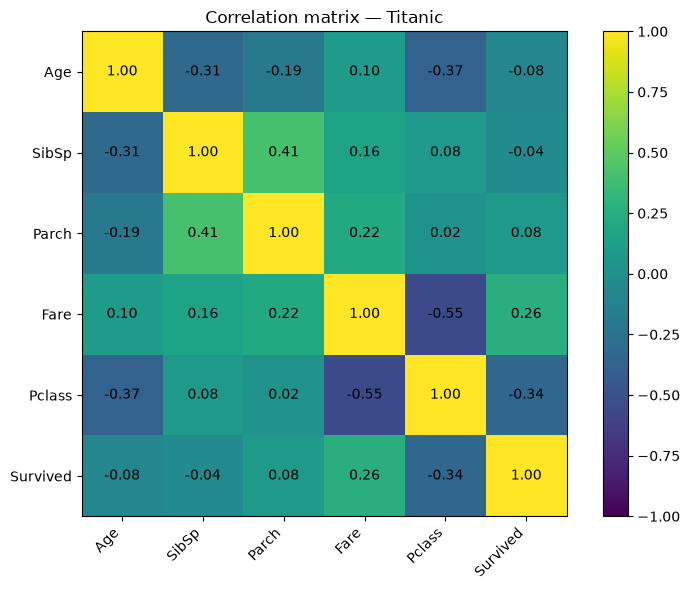


Сильно коррелирующие пары features (|r| >= 0.80):
Не обнаружены


In [983]:
# Шаг 2. Проверяю корреляции числовых признаков

import matplotlib.pyplot as plt

numeric_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Pclass",
    "Survived"
]

corr_matrix = train[numeric_columns].corr()

print("Матрица корреляций:")
print(corr_matrix.round(3))



fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))

ax.set_xticklabels(
    numeric_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(numeric_columns)



for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)

ax.set_title("Correlation matrix — Titanic")

plt.tight_layout()
plt.show()



feature_corr = train[
    ["Age", "SibSp", "Parch", "Fare", "Pclass"]
].corr().abs()

strong_pairs = []

for i in range(len(feature_corr.columns)):
    for j in range(i + 1, len(feature_corr.columns)):

        correlation = feature_corr.iloc[i, j]

        if correlation >= 0.80:
            strong_pairs.append(
                (feature_corr.columns[i],   
                 feature_corr.columns[j],
                 correlation
                )
            )

print("\nСильно коррелирующие пары features (|r| >= 0.80):")

if strong_pairs:
    for feature_1, feature_2, correlation in strong_pairs:
        print(
            f"{feature_1} ↔ {feature_2}: "
            f"{correlation:.3f}"
        )
else:
    print("Не обнаружены")

Анализ выбросов методом IQR:
feature     Q1   Q3    IQR  lower_bound  upper_bound  n_outliers  outlier_share
    Age 20.125 38.0 17.875       -6.688       64.812          11          0.015
  SibSp  0.000  1.0  1.000       -1.500        2.500          46          0.052
  Parch  0.000  0.0  0.000        0.000        0.000         213          0.239
   Fare  7.910 31.0 23.090      -26.724       65.634         116          0.130

Диапазоны значений:
Age: min=0.420, max=80.000
SibSp: min=0.000, max=8.000
Parch: min=0.000, max=6.000
Fare: min=0.000, max=512.329


/var/folders/4x/m3b0_sz90bd48sm7ct1kdt640000gn/T/ipykernel_73261/3391604196.py:73: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(train[feature].dropna(), vert=True)
/var/folders/4x/m3b0_sz90bd48sm7ct1kdt640000gn/T/ipykernel_73261/3391604196.py:73: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(train[feature].dropna(), vert=True)
/var/folders/4x/m3b0_sz90bd48sm7ct1kdt640000gn/T/ipykernel_73261/3391604196.py:73: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(train[feature].dropna(), vert=True)
/var/folders/4x/m3b0_sz90bd48sm7ct1kdt640000gn/T/ipykernel_73261/3391604196.py:73: MatplotlibDeprecationWarning: vert: bool was depre

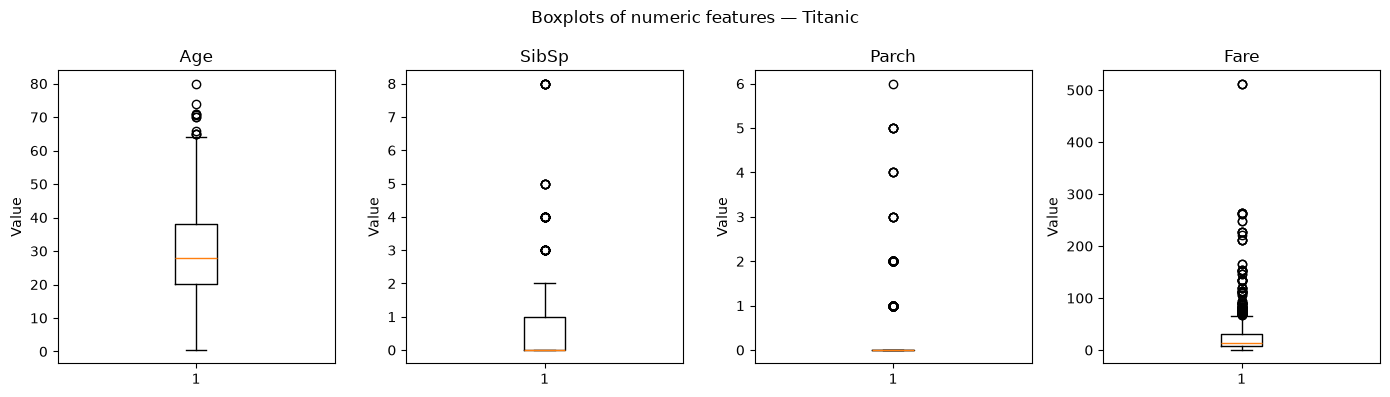

In [984]:
# Шаг 3.1. Исследую выбросы в числовых признаках

import pandas as pd
import matplotlib.pyplot as plt


numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]



outlier_results = []

for feature in numeric_features:

    series = train[feature].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = series[(series < lower_bound) | (series > upper_bound)]

    outlier_results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "n_outliers": len(outliers),
        "outlier_share": len(outliers) / len(series)
    })


outlier_df = pd.DataFrame(outlier_results)

print("Анализ выбросов методом IQR:")
print(outlier_df.round(3).to_string(index=False))



print("\nДиапазоны значений:")

for feature in numeric_features:

    print(
        f"{feature}: "
        f"min={train[feature].min():.3f}, "
        f"max={train[feature].max():.3f}"
    )



fig, axes = plt.subplots(
    nrows=1,
    ncols=len(numeric_features),
    figsize=(14, 4)
)

for ax, feature in zip(axes, numeric_features):
    ax.boxplot(train[feature].dropna(), vert=True)
    ax.set_title(feature)
    ax.set_ylabel("Value")


plt.suptitle("Boxplots of numeric features — Titanic")

plt.tight_layout()
plt.show()

In [986]:
# Вывод: Выбросы исследованы методом IQR и визуально с помощью boxplot. 
# Обнаружены экстремальные значения, особенно в Fare, SibSp и Parch. Однако они соответствуют допустимым значениям признаков; 
# IQR также некорректно интерпретирует дискретный Parch из-за IQR=0. Автоматическое удаление наблюдений не применяется.

In [985]:
# Шаг 3.2. Проверяю влияние обработки Fare на качество модели

import numpy as np

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]



baseline_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


baseline_preprocessor = ColumnTransformer([
    ("numeric", baseline_numeric_pipeline, numeric_features),
    ("categorical", Pipeline([        
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]),
        categorical_features
    )
])


# Preprocessing с log1p(Fare)

regular_numeric_features = [
    "Age",
    "SibSp",
    "Parch"
]


regular_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


fare_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])


log_fare_preprocessor = ColumnTransformer([
    ("numeric", regular_numeric_pipeline, regular_numeric_features),
    ("fare", fare_pipeline, ["Fare"]),
    ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])



def make_rf():
    return RandomForestClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features=None,
        random_state=43,
        n_jobs=-1
    )


baseline_pipeline_outliers = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", make_rf())
])


log_fare_pipeline = Pipeline([
    ("preprocessor", log_fare_preprocessor),
    ("model", make_rf())
])



cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


baseline_scores = cross_val_score(
    baseline_pipeline_outliers,
    X,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)


log_fare_scores = cross_val_score(
    log_fare_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)



print(
    f"Baseline Fare:"
    f"{baseline_scores.mean():.6f} "
    f"± {baseline_scores.std():.6f}"
)

print(
    f"log1p(Fare):"
    f"{log_fare_scores.mean():.6f}"
    f"± {log_fare_scores.std():.6f}"
)

difference = (log_fare_scores - baseline_scores)

print(
    f"\nСредняя разница:"
    f"{difference.mean():+.6f}"
)

print("Разница по folds:", np.round(difference, 6))

Baseline Fare:0.832766 ± 0.005663
log1p(Fare):0.832766± 0.005663

Средняя разница:+0.000000
Разница по folds: [0. 0. 0. 0. 0.]


In [987]:
# Вывод: экстремальные значения исследованы, явных ошибок данных не обнаружено; удалять пассажиров не стали; 
# log1p(Fare) проверили экспериментально и улучшения CV не получили. 
# Оставляем исходный Fare.

In [988]:
# Шаг 4. Подбираю гиперпараметры KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline


knn_tuning_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", KNeighborsClassifier())
])



knn_param_grid = {
    "model__n_neighbors": [
        3, 5, 7, 9, 11, 15, 21
    ],

    "model__weights": [
        "uniform",
        "distance"
    ],

    "model__metric": [
        "euclidean",
        "manhattan"
    ]
}



knn_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



knn_grid_search = GridSearchCV(
    estimator=knn_tuning_pipeline,
    param_grid=knn_param_grid,
    scoring="accuracy",
    cv=knn_cv,
    n_jobs=-1,
    return_train_score=True
)


knn_grid_search.fit(X, y)


print("Лучшие параметры:")
print(knn_grid_search.best_params_)
print(
    f"\nЛучший CV accuracy: "
    f"{knn_grid_search.best_score_:.6f}"
)



original_knn_score = 0.8070

print(
    f"\nИсходный KNN (n_neighbors=5):"
    f"≈ {original_knn_score:.4f}"
)

print(
    f"Изменение после tuning:"
    f"{knn_grid_search.best_score_ - original_knn_score:+.6f}"
)



knn_results = (
    pd.DataFrame(knn_grid_search.cv_results_)
    .sort_values(
        "mean_test_score",
        ascending=False
    )
)

print("\nTOP-10 конфигураций:")

print(
    knn_results[
        [
            "param_model__n_neighbors",
            "param_model__weights",
            "param_model__metric",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

Лучшие параметры:
{'model__metric': 'manhattan', 'model__n_neighbors': 21, 'model__weights': 'uniform'}

Лучший CV accuracy: 0.821568

Исходный KNN (n_neighbors=5):≈ 0.8070
Изменение после tuning:+0.014568

TOP-10 конфигураций:
 param_model__n_neighbors param_model__weights param_model__metric  mean_train_score  mean_test_score  std_test_score
                       21              uniform           manhattan          0.829965         0.821568        0.016586
                       21             distance           manhattan          0.980922         0.818216        0.021738
                       21              uniform           euclidean          0.829123         0.817061        0.016869
                       11              uniform           manhattan          0.836141         0.813690        0.010329
                       15              uniform           manhattan          0.833053         0.812586        0.009463
                        9              uniform           manhatt

In [989]:
# Здесь есть три полезных вывода:
# 1) 21 сосед вместо 5 говорит, что модели полезно меньше реагировать на отдельных ближайших пассажиров и принимать решение по более широкой локальной группе. 
# 2) Manhattan оказался лучше Euclidean именно на нашей обработанной выборке. 
# 3) uniform лучше distance.

In [990]:
# Шаг 5. Подбираю гиперпараметры Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd



dt_tuning_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", DecisionTreeClassifier(
            random_state=43
        )
    )
])



dt_param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10]
}



dt_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



dt_grid_search = GridSearchCV(
    estimator=dt_tuning_pipeline,
    param_grid=dt_param_grid,
    scoring="accuracy",
    cv=dt_cv,
    n_jobs=-1,
    return_train_score=True
)

dt_grid_search.fit(X, y)



print("Лучшие параметры:")
print(dt_grid_search.best_params_)

print(
    f"\nЛучший CV accuracy:"
    f"{dt_grid_search.best_score_:.6f}"
)



original_dt_score = 0.783

print(
    f"\nИсходный Decision Tree:"
    f"≈ {original_dt_score:.3f}"
)

print(
    f"Изменение после tuning:"
    f"{dt_grid_search.best_score_ - original_dt_score:+.6f}"
)



dt_results = (
    pd.DataFrame(dt_grid_search.cv_results_)
    .sort_values("mean_test_score", ascending=False)
)

print("\nTOP-10 конфигураций:")

print(
    dt_results[
        [
            "param_model__criterion",
            "param_model__max_depth",
            "param_model__min_samples_split",
            "param_model__min_samples_leaf",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .head(10)
    .to_string(index=False)
)

Лучшие параметры:
{'model__criterion': 'gini', 'model__max_depth': 8, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}

Лучший CV accuracy:0.831643

Исходный Decision Tree:≈ 0.783
Изменение после tuning:+0.048643

TOP-10 конфигураций:
param_model__criterion param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf  mean_train_score  mean_test_score  std_test_score
                  gini                      8                               2                              5          0.871493         0.831643        0.012397
                  gini                      8                               5                              5          0.871493         0.831643        0.012397
                  gini                      8                              10                              5          0.871493         0.831643        0.012397
                  gini                     10                               2                              5     

In [992]:
# Шаг 6. Начинаю работу с LightGBM
import sys

!{sys.executable} -m pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 5.8 MB/s  0:00:00m 4.5 MB/s eta 0:00:01

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [997]:
# Шаг 7.1. Устанавливаю OpenMP только из conda-forge

!/opt/miniconda3/bin/conda install \
    --override-channels \
    -c conda-forge \
    llvm-openmp \
    -y

Jupyter detected...
Retrieving notices: done
Channels:
 - conda-forge
Platform: osx-arm64
Solving environment: done

## Package Plan ##

  environment location: /opt/miniconda3

  added / updated specs:
    - llvm-openmp


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.7.22  |       hbd8a1cb_0         129 KB  conda-forge
    certifi-2026.7.22          |     pyhd8ed1ab_0         134 KB  conda-forge
    llvm-openmp-23.1.2         |       hdb3d66b_0         281 KB  conda-forge
    openssl-3.6.4              |       h55eecbc_0         3.0 MB  conda-forge
    ------------------------------------------------------------
                                           Total:         3.5 MB

The following NEW packages will be INSTALLED:

  llvm-openmp        conda-forge/osx-arm64::llvm-openmp-23.1.2-hdb3d66b_0 

The following packages will be UPDATED:

  ca-certificates    pkgs/

In [998]:
# Шаг 6.1. Проверяю LightGBM после установки OpenMP

import lightgbm as lgb

print("LightGBM успешно импортирован")
print("Версия LightGBM:", lgb.__version__)

LightGBM успешно импортирован
Версия LightGBM: 4.7.0


In [999]:
# Шаг 6.2. Обучаю baseline LightGBM

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


lgbm_baseline = LGBMClassifier(
    random_state=43,
    verbosity=-1
)



lgbm_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", lgbm_baseline)
])



lgbm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



lgbm_scores = cross_val_score(
    lgbm_pipeline,
    X,
    y,
    cv=lgbm_cv,
    scoring="accuracy",
    n_jobs=-1
)



print("LightGBM accuracy по folds:")
print(np.round(lgbm_scores, 6))

print(
    f"\nLightGBM mean CV accuracy:"
    f"{lgbm_scores.mean():.6f}"
)

print(
    f"LightGBM std:"
    f"{lgbm_scores.std():.6f}"
)

LightGBM accuracy по folds:
[0.821229 0.820225 0.820225 0.842697 0.814607]

LightGBM mean CV accuracy:0.823796
LightGBM std:0.009734


In [1000]:
# Шаг 6.3. Подбираю гиперпараметры LightGBM

from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd



lgbm_tuning_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", LGBMClassifier(        
        random_state=43,
        verbosity=-1
        )
    )
])



lgbm_param_grid = {
    "model__n_estimators": [50, 100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__num_leaves": [5, 7, 15, 31],
    "model__max_depth": [3, 4, 5, 6, -1],
    "model__min_child_samples": [10, 20, 30, 50],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0]
}



lgbm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



lgbm_search = RandomizedSearchCV(
    estimator=lgbm_tuning_pipeline,
    param_distributions=lgbm_param_grid,
    n_iter=60,
    scoring="accuracy",
    cv=lgbm_cv,
    random_state=43,
    n_jobs=-1,
    return_train_score=True
)

lgbm_search.fit(X, y)



print("Лучшие параметры:")
print(lgbm_search.best_params_)

print(
    f"\nЛучший CV accuracy:"
    f"{lgbm_search.best_score_:.6f}"
)

print(
    f"Baseline LightGBM:"
    f"{lgbm_scores.mean():.6f}"
)

print(
    f"Изменение после tuning:"
    f"{lgbm_search.best_score_ - lgbm_scores.mean():+.6f}"
)



lgbm_results = (
    pd.DataFrame(lgbm_search.cv_results_).sort_values("mean_test_score", ascending=False)
)

columns_to_show = [
    "param_model__n_estimators",
    "param_model__learning_rate",
    "param_model__num_leaves",
    "param_model__max_depth",
    "param_model__min_child_samples",
    "param_model__subsample",
    "param_model__colsample_bytree",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]

print("\nTOP-10 конфигураций:")

print(lgbm_results[
        columns_to_show
    ]
    .head(10)
    .to_string(index=False)
)

Лучшие параметры:
{'model__subsample': 0.85, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 30, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}

Лучший CV accuracy:0.838391
Baseline LightGBM:0.823796
Изменение после tuning:+0.014594

TOP-10 конфигураций:
 param_model__n_estimators  param_model__learning_rate  param_model__num_leaves  param_model__max_depth  param_model__min_child_samples  param_model__subsample  param_model__colsample_bytree  mean_train_score  mean_test_score  std_test_score
                       500                        0.03                       31                       6                              30                    0.85                           1.00          0.912740         0.838391        0.010783
                       200                        0.10                       31                       5                              30                    1.00                           0.85

In [1003]:
# Шаг 6.4. Проверяю tuned LightGBM на Repeated CV

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
import numpy as np


lgbm_tuned = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=6,
    min_child_samples=30,
    subsample=0.85,
    colsample_bytree=1.0,
    random_state=43,
    verbosity=-1
)


lgbm_tuned_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", lgbm_tuned)
])


repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)


lgbm_repeated_scores = cross_val_score(
    lgbm_tuned_pipeline,
    X,
    y,
    cv=repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)


print("Количество оценок:", len(lgbm_repeated_scores))

print(
    f"Repeated CV mean:"
    f"{lgbm_repeated_scores.mean():.6f}"
)

print(
    f"Repeated CV std:"
    f"{lgbm_repeated_scores.std():.6f}"
)

print(
    f"Min:"
    f"{lgbm_repeated_scores.min():.6f}"
)

print(
    f"Max:"
    f"{lgbm_repeated_scores.max():.6f}"
)

print(
    f"\nRandomizedSearch best CV:"
    f"{lgbm_search.best_score_:.6f}"
)

print(
    f"Разница:"
    f"{lgbm_repeated_scores.mean() - lgbm_search.best_score_:+.6f}"
)

Количество оценок: 50
Repeated CV mean:0.831218
Repeated CV std:0.025055
Min:0.758427
Max:0.876404

RandomizedSearch best CV:0.838391
Разница:-0.007173


## Stacking

Объединяю Random Forest и LightGBM и использую отдельную meta-model.

Сравнение `LogisticRegression` и `RidgeClassifier` показывает одинаковую среднюю 5-fold Accuracy — **0.836150**. У RidgeClassifier немного ниже стандартное отклонение между folds, но этого недостаточно, чтобы считать его однозначно лучшим. Эксперимент показывает, что замена meta-model сама по себе не дала прироста средней метрики.


In [1004]:
# Шаг 7.1. Создаю stacking-модель

from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier



stack_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=43,
    n_jobs=-1
)



stack_lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=6,
    min_child_samples=30,
    subsample=0.85,
    colsample_bytree=1.0,
    random_state=43,
    verbosity=-1
)



base_estimators = [
    ("rf", stack_rf),
    ("lgbm", stack_lgbm)
]



meta_model = LogisticRegression(
    max_iter=1000,
    random_state=43
)



stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_model,
    stack_method="predict_proba",
    cv=5,
    n_jobs=-1
)



stacking_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", stacking_model)
])


print("Базовые модели:")
for name, model in base_estimators:
    print(f" - {name}: {model.__class__.__name__}")

print("\nMeta-model:", meta_model.__class__.__name__)
print("\nStacking pipeline создан успешно.")

Базовые модели:
 - rf: RandomForestClassifier
 - lgbm: LGBMClassifier

Meta-model: LogisticRegression

Stacking pipeline создан успешно.


In [1005]:
# Шаг 7.2. Проверяю Stacking на тех же 5 folds

from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


stacking_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



stacking_scores = cross_val_score(
    stacking_pipeline,
    X,
    y,
    cv=stacking_cv,
    scoring="accuracy",
    n_jobs=-1
)



print("Stacking accuracy по folds:")
print(np.round(stacking_scores, 6))
print(
    f"\nStacking mean CV accuracy:"
    f"{stacking_scores.mean():.6f}"
)

print(
    f"Stacking std:"
    f"{stacking_scores.std():.6f}"
)



print("\nСравнение:")

print(
    f"Random Forest:"
    f"{0.832766:.6f}"
)

print(
    f"LightGBM baseline:"
    f"{lgbm_scores.mean():.6f}"
)

print(
    f"LightGBM tuned*:"
    f"{lgbm_search.best_score_:.6f}"
)

print(
    f"Stacking:"
    f"{stacking_scores.mean():.6f}"
)

print(
    f"\nStacking vs RF:"
    f"{stacking_scores.mean() - 0.832766:+.6f}"
)

Stacking accuracy по folds:
[0.826816 0.848315 0.825843 0.853933 0.825843]

Stacking mean CV accuracy:0.836150
Stacking std:0.012360

Сравнение:
Random Forest:0.832766
LightGBM baseline:0.823796
LightGBM tuned*:0.838391
Stacking:0.836150

Stacking vs RF:+0.003384


In [1006]:
# Шаг 7.3. Проверяю Stacking на Repeated CV

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score
)

import numpy as np


stacking_repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=43
)



stacking_repeated_scores = cross_val_score(
    stacking_pipeline,
    X,
    y,
    cv=stacking_repeated_cv,
    scoring="accuracy",
    n_jobs=-1
)



print(
    "Количество оценок:",
    len(stacking_repeated_scores)
)

print(
    f"Stacking Repeated CV mean:"
    f"{stacking_repeated_scores.mean():.6f}"
)

print(
    f"Stacking Repeated CV std:"
    f"{stacking_repeated_scores.std():.6f}"
)

print(
    f"Min:"
    f"{stacking_repeated_scores.min():.6f}"
)

print(
    f"Max:"
    f"{stacking_repeated_scores.max():.6f}"
)



print(
    f"\nStacking 5-fold CV:"
    f"{stacking_scores.mean():.6f}"
)

print(
    f"Stacking Repeated CV:"
    f"{stacking_repeated_scores.mean():.6f}"
)

print(
    f"Разница:"
    f"{stacking_repeated_scores.mean() - stacking_scores.mean():+.6f}"
)

Количество оценок: 50
Stacking Repeated CV mean:0.835031
Stacking Repeated CV std:0.026011
Min:0.752809
Max:0.887640

Stacking 5-fold CV:0.836150
Stacking Repeated CV:0.835031
Разница:-0.001119


In [1058]:
# Шаг 7.4. Сравниваю LogisticRegression и RidgeClassifier как meta-model

from sklearn.linear_model import RidgeClassifier


ridge_meta_model = RidgeClassifier(alpha=1.0)


ridge_stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=ridge_meta_model,
    cv=5,
    n_jobs=-1
)


ridge_stacking_pipeline = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", ridge_stacking_model)
])


ridge_stacking_scores = cross_val_score(
    ridge_stacking_pipeline,
    X,
    y,
    cv=stacking_cv,
    scoring="accuracy",
    n_jobs=-1
)


print("LogisticRegression meta-model:")
print(np.round(stacking_scores, 6))
print(
    f"Mean: {stacking_scores.mean():.6f}"
    f"+/- {stacking_scores.std():.6f}"
)


print("\nRidgeClassifier meta-model:")
print(np.round(ridge_stacking_scores, 6))
print(
    f"Mean: {ridge_stacking_scores.mean():.6f}"
    f"+/- {ridge_stacking_scores.std():.6f}"
)


print("\nРазница Ridge - LogisticRegression:")
print(f"{ridge_stacking_scores.mean() - stacking_scores.mean():+.6f}")

LogisticRegression meta-model:
[0.826816 0.848315 0.825843 0.853933 0.825843]
Mean: 0.836150+/- 0.012360

RidgeClassifier meta-model:
[0.826816 0.842697 0.831461 0.853933 0.825843]
Mean: 0.836150+/- 0.010719

Разница Ridge - LogisticRegression:
+0.000000


In [1007]:
# Шаг 8.1. Сравниваю один holdout с 5-fold CV

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import accuracy_score


X_train_holdout, X_valid_holdout, y_train_holdout, y_valid_holdout = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=43
    )
)



rf_holdout = clone(final_rf_pipeline)



rf_holdout.fit(
    X_train_holdout,
    y_train_holdout
)



holdout_pred = rf_holdout.predict(
    X_valid_holdout
)



holdout_accuracy = accuracy_score(
    y_valid_holdout,
    holdout_pred
)


print(
    f"Holdout 80/20 accuracy:"
    f"{holdout_accuracy:.6f}"
)

print(
    f"5-fold CV accuracy:"
    f"{0.832766:.6f}"
)

print(
    f"Разница:"
    f"{holdout_accuracy - 0.832766:+.6f}"
)

print(
    f"\nTrain size:"
    f"{len(X_train_holdout)}"
)

print(
    f"Validation size:"
    f"{len(X_valid_holdout)}"
)

Holdout 80/20 accuracy:0.826816
5-fold CV accuracy:0.832766
Разница:-0.005950

Train size:712
Validation size:179


In [1008]:
# Шаг 8.2. Создаю submission от модели, обученной только на одном train split

import pandas as pd


test_pred_holdout = rf_holdout.predict(X_test)


submission_holdout = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_pred_holdout.astype(int)
})


holdout_submission_path = (
    "../Data/submission_rf_holdout_80.csv"
)

submission_holdout.to_csv(
    holdout_submission_path,
    index=False
)



print("Размер submission:", submission_holdout.shape)

print("Пропуски:", submission_holdout.isna().sum().sum())

print("Классы:", sorted(submission_holdout["Survived"].unique()))

print(
    "Доля предсказанного Survived=1:",
    round(
        submission_holdout["Survived"].mean(),
        6
    )
)

print("\nФайл сохранён:", holdout_submission_path)

submission_holdout.head()

Размер submission: (418, 2)
Пропуски: 0
Классы: [np.int64(0), np.int64(1)]
Доля предсказанного Survived=1: 0.332536

Файл сохранён: ../Data/submission_rf_holdout_80.csv


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [1009]:
# Шаг 8.3. Сравниваю predictions RF 80% и RF 100%

import numpy as np
import pandas as pd


submission_full = pd.read_csv("../Data/submission_final_rf.csv")

pred_80 = submission_holdout["Survived"].to_numpy()
pred_100 = submission_full["Survived"].to_numpy()



different_mask = pred_80 != pred_100

n_different = different_mask.sum()

print("Различающихся predictions:", n_different)
print("Доля различий:", f"{n_different / len(pred_80):.2%}")



comparison = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "RF_80_percent": pred_80,
    "RF_100_percent": pred_100
})

different_predictions = comparison[
    comparison["RF_80_percent"]
    != comparison["RF_100_percent"]
]


print("\nКоличество строк с различиями:", len(different_predictions))

different_predictions

Различающихся predictions: 14
Доля различий: 3.35%

Количество строк с различиями: 14


,PassengerId,RF_80_percent,RF_100_percent
4,896,0,1
23,915,1,0
28,920,0,1
33,925,1,0
34,926,1,0
39,931,1,0
64,956,0,1
140,1032,1,0
153,1045,0,1
165,1057,1,0


In [ ]:
# Подготавливаю проект к воспроизводимому запуску

# Reproducibility и структура проекта

Финальный этап — перенос ключевой логики из исследовательского notebook в воспроизводимый проект.

Production-контур разделён на конфигурацию, обучение и inference. `main.py` должен позволять загрузить данные, выполнить preprocessing, оценить модель через cross-validation, обучить её на полном train, сохранить артефакт и сформировать submission.


In [1010]:
# Шаг 9.1. Проверяю структуру проекта

from pathlib import Path

project_root = Path("..")

for path in sorted(project_root.rglob("*")):
    if ".venv" in path.parts:
        continue

    if "__pycache__" in path.parts:
        continue

    relative = path.relative_to(project_root)

    depth = len(relative.parts) - 1
    indent = "    " * depth

    if path.is_dir():
        print(f"{indent}📁 {path.name}/")
    else:
        print(f"{indent}📄 {path.name}")

📄 .DS_Store
📁 .ipynb_checkpoints/
📁 Artifacts/
    📄 submission.csv
    📄 submission_from_main.csv
    📄 titanic_rf_pipeline.joblib
📁 Configs/
📁 Data/
    📄 .DS_Store
    📁 raw/
        📄 .DS_Store
        📄 gender_submission.csv
        📄 test.csv
        📄 train.csv
    📄 submission_final_rf.csv
    📄 submission_rf_holdout_80.csv
    📄 submission_rf_ticket.csv
📁 Notebooks/
    📄 .DS_Store
    📁 .ipynb_checkpoints/
        📄 01_eda-checkpoint.ipynb
        📄 untitled-checkpoint.md
    📄 01_eda.ipynb
    📁 catboost_info/
        📄 catboost_training.json
        📁 learn/
            📄 events.out.tfevents
        📄 learn_error.tsv
        📄 time_left.tsv
        📁 tmp/
    📄 untitled.md
📄 README.md
📄 main.py
📄 requirements.txt
📁 src/
    📄 inference.py
    📄 transformers.py


In [1011]:
# Шаг 9.2. Проверяю текущие production-файлы

from pathlib import Path

project_root = Path("..")

files_to_check = [
    "README.md",
    "requirements.txt",
    "main.py",
    "src/inference.py",
    "src/transformers.py",
]


for file_name in files_to_check:
    path = project_root / file_name

    print("\n" + "=" * 80)
    print(file_name)
    print("=" * 80)

    if path.exists():
        content = path.read_text(encoding="utf-8")

        print(f"Размер: {len(content)} символов")
        print(f"Строк: {len(content.splitlines())}")
        print()

        print(content)

    else:
        print("Файл не найден")


README.md
Размер: 0 символов
Строк: 0



requirements.txt
Размер: 44 символов
Строк: 5

pandas
numpy
matplotlib
scikit-learn
jupyter

main.py
Размер: 1264 символов
Строк: 58


from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


# Корень проекта Titanic
PROJECT_ROOT = Path(__file__).resolve().parent

# Пути к данным и артефактам
TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main():
    # Загружаю test
    test = pd.read_csv(TEST_PATH)

    # Сохраняю PassengerId отдельно
    passenger_ids = test["PassengerId"]

    # Оставляю признаки, которые ожидает pipeline
    X_test = test[
        [
            "Age",
            "SibSp",
            "Parch",
            "Fare",
            "Pclass",
            "Sex",
            "Embarked",
            "Ticket"
        ]
    ].copy()


In [1012]:
# Шаг 9.3. Проверяю сохранённый production pipeline

from pathlib import Path
import joblib


PROJECT_ROOT = Path("..")

MODEL_PATH = (
    PROJECT_ROOT
    / "Artifacts"
    / "titanic_rf_pipeline.joblib"
)



saved_model = joblib.load(MODEL_PATH)


print("Тип объекта:")
print(type(saved_model))

print("\nPipeline:")
print(saved_model)



print("\nШаги pipeline:")

for name, step in saved_model.named_steps.items():
    print(
        f"{name}: "
        f"{step.__class__.__name__}"
    )



if hasattr(saved_model, "feature_names_in_"):
    print("\nfeature_names_in_:")
    print(saved_model.feature_names_in_)

    print(
        "\nКоличество входных признаков:",
        len(saved_model.feature_names_in_)
    )
else:
    print(
        "\nУ сохранённой модели "
        "нет feature_names_in_"
    )



if "model" in saved_model.named_steps:
    final_model = saved_model.named_steps["model"]

    print("\nФинальная модель:")
    print(final_model)

    print("\nКласс:")
    print(final_model.__class__.__name__)

Тип объекта:
<class 'sklearn.pipeline.Pipeline'>

Pipeline:
Pipeline(steps=[('ticket_features', TicketGroupSizeTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'SibSp', 'Parch',
                                                   'Fare', 'TicketGroupSize']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                      

In [1014]:
# Шаг 9.4.1. Явно пересобираю финальный production RF

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier



numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]



numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])



categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])



production_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])



production_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=43,
    n_jobs=-1
)



production_rf_pipeline = Pipeline([
    ("preprocessor", production_preprocessor),
    ("model", production_rf)
])



print("Шаги нового production pipeline:")

for name, step in production_rf_pipeline.named_steps.items():
    print(
        f"{name}:"
        f"{step.__class__.__name__}"
    )

Шаги нового production pipeline:
preprocessor:ColumnTransformer
model:RandomForestClassifier


In [1015]:
# Шаг 9.4.2. Проверяю новый production pipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np


production_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)



production_cv_scores = cross_val_score(
    production_rf_pipeline,
    X,
    y,
    cv=production_cv,
    scoring="accuracy",
    n_jobs=-1
)



print("Production RF accuracy по folds:")
print(np.round(production_cv_scores, 6))

print(
    f"\nMean CV accuracy:"
    f"{production_cv_scores.mean():.6f}"
)

print(
    f"Std:"
    f"{production_cv_scores.std():.6f}"
)

print(
    f"\nОжидаемый результат:"
    f"{0.832766:.6f}"
)

print(
    f"Разница:"
    f"{production_cv_scores.mean() - 0.832766:+.6f}"
)

Production RF accuracy по folds:
[0.837989 0.825843 0.837079 0.837079 0.825843]

Mean CV accuracy:0.832766
Std:0.005663

Ожидаемый результат:0.832766
Разница:+0.000000


In [1017]:
# Шаг 9.4.3. Обучаю production pipeline и сравниваю с финальным submission

import pandas as pd
import numpy as np


production_rf_pipeline.fit(X, y)



production_predictions = (production_rf_pipeline.predict(X_test).astype(int))



reference_submission = pd.read_csv("../Data/submission_final_rf.csv")
reference_predictions = (reference_submission["Survived"].to_numpy())



different_mask = (
    production_predictions
    != reference_predictions
)

n_different = different_mask.sum()


print(
    "Количество predictions:",
    len(production_predictions)
)

print(
    "Различающихся predictions:",
    n_different
)

print(
    "Доля различий:",
    f"{n_different / len(production_predictions):.2%}"
)

print(
    "\nДоля Survived=1 — production:",
    f"{production_predictions.mean():.6f}"
)

print(
    "Доля Survived=1 — reference:",
    f"{reference_predictions.mean():.6f}"
)



if n_different > 0:
    comparison = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "production": production_predictions,
        "reference": reference_predictions
    })

    display(
        comparison[different_mask]
    )

else:
    print("\n✅ Predictions полностью совпадают")

Количество predictions: 418
Различающихся predictions: 0
Доля различий: 0.00%

Доля Survived=1 — production: 0.322967
Доля Survived=1 — reference: 0.322967

✅ Predictions полностью совпадают


In [1018]:
# Шаг 9.4.4. Сохраняю проверенный production pipeline

from pathlib import Path
import joblib


MODEL_PATH = (
    Path("..")
    / "Artifacts"
    / "titanic_rf_pipeline.joblib"
)



joblib.dump(production_rf_pipeline, MODEL_PATH)



loaded_production_model = joblib.load(MODEL_PATH)



print("Шаги сохранённого pipeline:")

for name, step in loaded_production_model.named_steps.items():
    print(
        f"{name}:"
        f"{step.__class__.__name__}"
    )



loaded_predictions = (loaded_production_model.predict(X_test).astype(int))
n_different_after_load = (loaded_predictions != production_predictions).sum()

print("\nРазличий после save/load:", n_different_after_load)

if n_different_after_load == 0:
    print("✅ Production artifact сохранён корректно")

Шаги сохранённого pipeline:
preprocessor:ColumnTransformer
model:RandomForestClassifier

Различий после save/load: 0
✅ Production artifact сохранён корректно


In [1019]:
# Шаг 9.5.1. Проверяю влияние кастомного threshold

import numpy as np
import pandas as pd


production_probabilities = (loaded_production_model.predict_proba(X_test)[:, 1])



pred_threshold_0484 = (production_probabilities >= 0.484).astype(int)



pred_standard = (
    loaded_production_model
    .predict(X_test)
    .astype(int)
)



threshold_difference = (pred_threshold_0484 != pred_standard)

n_threshold_difference = (threshold_difference.sum())


print(
    "Различий между predict() и threshold=0.484:",
    n_threshold_difference
)

print(
    "Доля различий:",
    f"{n_threshold_difference / len(X_test):.2%}"
)

print(
    "\nSurvived=1 через predict():",
    f"{pred_standard.mean():.6f}"
)

print(
    "Survived=1 через threshold=0.484:",
    f"{pred_threshold_0484.mean():.6f}"
)



if n_threshold_difference > 0:
    threshold_comparison = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "probability": production_probabilities,
        "predict_standard": pred_standard,
        "predict_threshold_0484": pred_threshold_0484
    })

    display(
        threshold_comparison[
            threshold_difference
        ].sort_values("probability")
    )

else:
    print("\nПорог 0.484 не изменяет predictions.")

Различий между predict() и threshold=0.484: 3
Доля различий: 0.72%

Survived=1 через predict(): 0.322967
Survived=1 через threshold=0.484: 0.330144


,PassengerId,probability,predict_standard,predict_threshold_0484
412,1304,0.486286,0,1
165,1057,0.488368,0,1
34,926,0.491648,0,1


In [1020]:
# Шаг 9.5.2. Обновляю production inference

from pathlib import Path


inference_path = (
    Path("..")
    / "src"
    / "inference.py"
)


new_inference_code = '''import pandas as pd


def predict_survival(model, data: pd.DataFrame) -> pd.DataFrame:
    """
    Predict Titanic survival classes.

    Parameters
    ----------
    model
        Fitted sklearn-compatible classification pipeline.

    data : pd.DataFrame
        Input passenger features.

    Returns
    -------
    pd.DataFrame
        DataFrame with one column, ``Survived``,
        containing binary predictions.
    """

    predictions = model.predict(data).astype(int)

    return pd.DataFrame({
        "Survived": predictions
    })
'''


inference_path.write_text(
    new_inference_code,
    encoding="utf-8"
)


print("Обновлён файл:")
print(inference_path)

print("\nНовое содержимое:\n")
print(inference_path.read_text(encoding="utf-8"))

Обновлён файл:
../src/inference.py

Новое содержимое:

import pandas as pd


def predict_survival(model, data: pd.DataFrame) -> pd.DataFrame:
    """
    Predict Titanic survival classes.

    Parameters
    ----------
    model
        Fitted sklearn-compatible classification pipeline.

    data : pd.DataFrame
        Input passenger features.

    Returns
    -------
    pd.DataFrame
        DataFrame with one column, ``Survived``,
        containing binary predictions.
    """

    predictions = model.predict(data).astype(int)

    return pd.DataFrame({
        "Survived": predictions
    })



In [1023]:
# Шаг 9.5.3. Синхронизирую main.py с новым inference.py

from pathlib import Path


main_path = Path("..") / "main.py"

main_code = '''from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


PROJECT_ROOT = Path(__file__).resolve().parent

TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main() -> None:
    """Generate Titanic predictions using the trained production pipeline."""

    test = pd.read_csv(TEST_PATH)

    passenger_ids = test["PassengerId"].copy()

    model = joblib.load(MODEL_PATH)

    predictions = predict_survival(
        model=model,
        data=test
    )

    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions["Survived"]
    })

    submission.to_csv(
        SUBMISSION_PATH,
        index=False
    )

    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Shape: {submission.shape}")


if __name__ == "__main__":
    main()
'''


main_path.write_text(main_code, encoding="utf-8")

print("Обновлён файл:")
print(main_path)

print("\nНовое содержимое:\n")
print(main_path.read_text(encoding="utf-8"))

Обновлён файл:
../main.py

Новое содержимое:

from pathlib import Path

import joblib
import pandas as pd

from src.inference import predict_survival


PROJECT_ROOT = Path(__file__).resolve().parent

TEST_PATH = PROJECT_ROOT / "Data" / "raw" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "Artifacts" / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = PROJECT_ROOT / "Artifacts" / "submission_from_main.csv"


def main() -> None:
    """Generate Titanic predictions using the trained production pipeline."""

    test = pd.read_csv(TEST_PATH)

    passenger_ids = test["PassengerId"].copy()

    model = joblib.load(MODEL_PATH)

    predictions = predict_survival(
        model=model,
        data=test
    )

    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions["Survived"]
    })

    submission.to_csv(
        SUBMISSION_PATH,
        index=False
    )

    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Shape: {submission.shape}")


if __

In [1025]:
# Шаг 9.5.4. Проверяю полный production inference

import sys
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("..").resolve()


!cd "{PROJECT_ROOT}" && "{sys.executable}" main.py



main_submission_path = (
    PROJECT_ROOT
    / "Artifacts"
    / "submission_from_main.csv"
)

main_submission = pd.read_csv(
    main_submission_path
)



reference_submission = pd.read_csv(
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)



print("\nРазмер main submission:")
print(main_submission.shape)

print("\nКолонки:")
print(main_submission.columns.tolist())

print("\nПропуски:", main_submission.isna().sum().sum())



main_predictions = (main_submission["Survived"].to_numpy())
reference_predictions = (reference_submission["Survived"].to_numpy())
n_different = (main_predictions != reference_predictions).sum()

print("\nРазличающихся predictions:", n_different)

print(
    "Доля различий:",
    f"{n_different / len(main_predictions):.2%}"
)


if n_different == 0:
    print("\n✅ main.py полностью воспроизводит submission_final_rf.csv")
else:
    print("\n❌ Есть расхождения — production-контур нужно проверить.")

Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv
Shape: (418, 2)

Размер main submission:
(418, 2)

Колонки:
['PassengerId', 'Survived']

Пропуски: 0

Различающихся predictions: 0
Доля различий: 0.00%

✅ main.py полностью воспроизводит submission_final_rf.csv


In [1026]:
# Шаг 9.6. Аудит зависимостей окружения

In [1027]:
# Шаг 9.6.1. Проверяю версии зависимостей в текущем рабочем окружении

from importlib.metadata import version, PackageNotFoundError


packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn",
    "jupyter",
    "joblib",
    "catboost",
    "lightgbm",
    "tensorflow",
]


print("Python:")
import sys
print(sys.version)

print("\nЗависимости:")

for package in packages:
    try:
        print(
            f"{package:<15}"
            f"{version(package)}"
        )
    except PackageNotFoundError:
        print(
            f"{package:<15}"
            "NOT INSTALLED"
        )

Python:
3.13.12 | packaged by Anaconda, Inc. | (main, Feb 24 2026, 16:07:20) [Clang 20.1.8 ]

Зависимости:
pandas         3.0.6
numpy          2.5.3
matplotlib     3.11.2
scikit-learn   1.9.1
jupyter        1.1.1
joblib         1.6.0
catboost       1.2.10
lightgbm       4.7.0
tensorflow     2.21.0


In [1028]:
# Шаг 9.6.2. Фиксирую зависимости проекта

from pathlib import Path


requirements_path = (
    Path("..")
    / "requirements.txt"
)


requirements = """pandas==3.0.6
numpy==2.5.3
matplotlib==3.11.2
scikit-learn==1.9.1
joblib==1.6.0
catboost==1.2.10
lightgbm==4.7.0
tensorflow==2.21.0
jupyter==1.1.1
"""


requirements_path.write_text(requirements, encoding="utf-8")


print("Обновлён файл:")
print(requirements_path)
print("\nСодержимое requirements.txt:\n")
print(requirements_path.read_text(encoding="utf-8"))

Обновлён файл:
../requirements.txt

Содержимое requirements.txt:

pandas==3.0.6
numpy==2.5.3
matplotlib==3.11.2
scikit-learn==1.9.1
joblib==1.6.0
catboost==1.2.10
lightgbm==4.7.0
tensorflow==2.21.0
jupyter==1.1.1



In [1029]:
# Шаг 9.7. Выношу конфигурацию проекта

In [1030]:
# Шаг 9.7.1. Создаю централизованную конфигурацию проекта

from pathlib import Path


config_dir = Path("..") / "Configs"
config_dir.mkdir(
    parents=True,
    exist_ok=True
)

config_path = (
    config_dir
    / "config.py"
)


config_code = '''from pathlib import Path


# Project paths
PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

MODEL_PATH = ARTIFACTS_DIR / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = ARTIFACTS_DIR / "submission_from_main.csv"


# Reproducibility
RANDOM_STATE = 43
'''


config_path.write_text(config_code, encoding="utf-8")

print("Создан файл:")
print(config_path)
print("\nСодержимое config.py:\n")
print(config_path.read_text(encoding="utf-8"))

Создан файл:
../Configs/config.py

Содержимое config.py:

from pathlib import Path


# Project paths
PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

MODEL_PATH = ARTIFACTS_DIR / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = ARTIFACTS_DIR / "submission_from_main.csv"


# Reproducibility
RANDOM_STATE = 43



In [1031]:
# Шаг 9.7.2. Подключаю централизованный config к main.py

from pathlib import Path


main_path = Path("..") / "main.py"


main_code = '''import joblib
import pandas as pd

from Configs.config import MODEL_PATH, SUBMISSION_PATH, TEST_PATH
from src.inference import predict_survival


def main() -> None:
    """Generate Titanic predictions using the trained production pipeline."""

    # Load test data
    test = pd.read_csv(TEST_PATH)

    # PassengerId is required only for the Kaggle submission
    passenger_ids = test["PassengerId"].copy()

    # Load trained production pipeline
    model = joblib.load(MODEL_PATH)

    # Generate predictions
    predictions = predict_survival(
        model=model,
        data=test
    )

    # Build Kaggle submission
    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions["Survived"]
    })

    # Save result
    submission.to_csv(
        SUBMISSION_PATH,
        index=False
    )

    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Shape: {submission.shape}")


if __name__ == "__main__":
    main()
'''


main_path.write_text(main_code, encoding="utf-8")

print("Обновлён файл:")
print(main_path)
print("\nСодержимое main.py:\n")
print(main_path.read_text(encoding="utf-8"))

Обновлён файл:
../main.py

Содержимое main.py:

import joblib
import pandas as pd

from Configs.config import MODEL_PATH, SUBMISSION_PATH, TEST_PATH
from src.inference import predict_survival


def main() -> None:
    """Generate Titanic predictions using the trained production pipeline."""

    # Load test data
    test = pd.read_csv(TEST_PATH)

    # PassengerId is required only for the Kaggle submission
    passenger_ids = test["PassengerId"].copy()

    # Load trained production pipeline
    model = joblib.load(MODEL_PATH)

    # Generate predictions
    predictions = predict_survival(
        model=model,
        data=test
    )

    # Build Kaggle submission
    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Survived": predictions["Survived"]
    })

    # Save result
    submission.to_csv(
        SUBMISSION_PATH,
        index=False
    )

    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Shape: {submission.shape}")


if __name__ == "_

In [1032]:
# Шаг 9.7.3. Проверяю production-контур после подключения config

import sys
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("..").resolve()

main_submission_path = (
    PROJECT_ROOT
    / "Artifacts"
    / "submission_from_main.csv"
)

reference_submission_path = (
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)



if main_submission_path.exists():
    main_submission_path.unlink()

print("Старый submission удалён:", not main_submission_path.exists())



exit_code = !cd "{PROJECT_ROOT}" && "{sys.executable}" main.py
print("\n".join(exit_code))



assert main_submission_path.exists(), ("main.py не создал submission_from_main.csv")

print("\n✅ Новый submission создан.")



main_submission = pd.read_csv(main_submission_path)
reference_submission = pd.read_csv(reference_submission_path)



assert main_submission.shape == (418, 2)

assert main_submission.columns.tolist() == [
    "PassengerId",
    "Survived"
]

assert main_submission.isna().sum().sum() == 0

print("Shape:", main_submission.shape)
print("Columns:", main_submission.columns.tolist())



files_identical = (main_submission.equals(reference_submission))

print("\nПолное совпадение DataFrame:", files_identical)

assert files_identical, ("Новый submission отличается от submission_final_rf.csv")

print("\n✅ config → main.py → model → inference полностью воспроизводит финальный submission")

Старый submission удалён: True
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv
Shape: (418, 2)

✅ Новый submission создан.
Shape: (418, 2)
Columns: ['PassengerId', 'Survived']

Полное совпадение DataFrame: True

✅ config → main.py → model → inference полностью воспроизводит финальный submission


In [1033]:
# Шаг 9.8. README проекта

In [1034]:
# Шаг 9.8.1. Проверяю актуальную структуру проекта

from pathlib import Path


PROJECT_ROOT = Path("..").resolve()

ignored_parts = {
    ".venv",
    "__pycache__",
    ".git",
}


def should_ignore(path: Path) -> bool:
    return any(
        part in ignored_parts
        for part in path.parts
    )


paths = sorted(
    path
    for path in PROJECT_ROOT.rglob("*")
    if not should_ignore(path)
)


for path in paths:
    relative = path.relative_to(PROJECT_ROOT)
    depth = len(relative.parts) - 1
    indent = "    " * depth

    if path.is_dir():
        print(f"{indent}{relative.name}/")
    else:
        print(f"{indent}{relative.name}")

.DS_Store
.ipynb_checkpoints/
Artifacts/
    submission.csv
    submission_from_main.csv
    titanic_rf_pipeline.joblib
Configs/
    config.py
Data/
    .DS_Store
    raw/
        .DS_Store
        gender_submission.csv
        test.csv
        train.csv
    submission_final_rf.csv
    submission_rf_holdout_80.csv
    submission_rf_ticket.csv
Notebooks/
    .DS_Store
    .ipynb_checkpoints/
        01_eda-checkpoint.ipynb
        untitled-checkpoint.md
    01_eda.ipynb
    catboost_info/
        catboost_training.json
        learn/
            events.out.tfevents
        learn_error.tsv
        time_left.tsv
        tmp/
    untitled.md
README.md
main.py
requirements.txt
src/
    inference.py
    transformers.py


In [1041]:
# Шаг 9.8.2. Записываю полный README

from pathlib import Path


readme_path = Path("..") / "README.md"


sections = [
    [
        "# Titanic — Machine Learning Classification",
        "",
        "Учебный ML-проект по задаче бинарной классификации",
        "Kaggle Titanic: Machine Learning from Disaster.",
        "",
        "Цель проекта — предсказать, выжил ли пассажир Titanic (`Survived`),",
        "используя информацию о пассажире.",
        "",
        "Проект охватывает полный ML lifecycle:",
        "EDA, preprocessing, feature engineering, cross-validation,",
        "подбор гиперпараметров, сравнение моделей, error analysis,",
        "ансамблирование, нейронные сети и production inference.",
    ],

    [
        "## Data",
        "",
        "Используются стандартные данные соревнования Titanic:",
        "",
        "- `train.csv` — обучающая выборка;",
        "- `test.csv` — тестовая выборка Kaggle;",
        "- `gender_submission.csv` — пример submission.",
        "",
        "Целевая переменная — `Survived`:",
        "",
        "- `0` — пассажир не выжил;",
        "- `1` — пассажир выжил.",
    ],

    [
        "## Validation strategy",
        "",
        "Для оценки моделей использовались:",
        "",
        "- Stratified 5-Fold Cross-Validation;",
        "- Repeated Stratified Cross-Validation;",
        "- Nested Cross-Validation;",
        "- repeated holdout validation;",
        "- GroupKFold по фамилиям;",
        "- adversarial validation.",
        "",
        "Основная метрика — `accuracy`.",
        "",
        "Основной акцент сделан на локальную валидацию и устойчивость",
        "результатов, а не на оптимизацию под Public Kaggle Leaderboard.",
    ],

    [
        "## Models",
        "",
        "В проекте исследовались:",
        "",
        "- Logistic Regression;",
        "- K-Nearest Neighbors;",
        "- Decision Tree;",
        "- Random Forest;",
        "- HistGradientBoosting;",
        "- CatBoost;",
        "- LightGBM;",
        "- stacking;",
        "- voting / averaging;",
        "- Dense Neural Networks.",
        "",
        "Для DNN дополнительно исследовались архитектура сети,",
        "Batch Normalization, Dropout, activation functions, optimizers,",
        "learning-rate scheduling, batch size и embeddings.",
    ],

    [
        "## Feature engineering",
        "",
        "Проверялись:",
        "",
        "- Title;",
        "- FamilySize;",
        "- IsChild;",
        "- RelativeFare;",
        "- TicketGroupSize;",
        "- `log1p(Fare)`;",
        "- interaction features.",
        "",
        "Также проведены анализ пропусков и выбросов,",
        "проверка constant / near-constant features,",
        "корреляционный анализ, feature ablation и error analysis.",
        "",
        "Новые признаки не добавлялись в production только ради",
        "улучшения одного validation split.",
    ],

    [
        "## Final production model",
        "",
        "Финальный production pipeline использует",
        "`RandomForestClassifier`.",
        "",
        "Основные параметры:",
        "",
        "- `n_estimators=500`;",
        "- `max_depth=8`;",
        "- `min_samples_split=5`;",
        "- `min_samples_leaf=1`;",
        "- `max_features=None`;",
        "- `random_state=43`.",
        "",
        "Числовые признаки:",
        "",
        "- Age;",
        "- SibSp;",
        "- Parch;",
        "- Fare.",
        "",
        "Preprocessing числовых признаков:",
        "",
        "- median imputation;",
        "- StandardScaler.",
        "",
        "Категориальные признаки:",
        "",
        "- Pclass;",
        "- Sex;",
        "- Embarked.",
        "",
        "Preprocessing категориальных признаков:",
        "",
        "- most-frequent imputation;",
        "- OneHotEncoder с `handle_unknown='ignore'`.",
        "",
        "Preprocessing и модель объединены в единый sklearn `Pipeline`.",
    ],

    [
        "## Validation result",
        "",
        "Финальный Random Forest на фиксированном",
        "Stratified 5-Fold CV:",
        "",
        "`0.832766 ± 0.005663`",
        "",
        "Дополнительные repeated и nested проверки использовались",
        "для оценки устойчивости и контроля selection bias.",
    ],

    [
        "## Kaggle experiments",
        "",
        "В ходе проекта были получены следующие Public Scores:",
        "",
        "- `submission_rf_ticket.csv` — `0.77990`;",
        "- `submission_from_main.csv` — исторический score `0.77751`;",
        "- `submission_final_rf.csv` — `0.77272`;",
        "- `submission_rf_holdout_80.csv` — `0.77272`.",
        "",
        "Public Leaderboard использовался как дополнительная внешняя",
        "проверка, а не как основной критерий выбора модели.",
    ],

    [
        "## Project structure",
        "",
        "```text",
        "Titanic/",
        "├── Artifacts/",
        "│   ├── titanic_rf_pipeline.joblib",
        "│   └── submission_from_main.csv",
        "├── Configs/",
        "│   └── config.py",
        "├── Data/",
        "│   ├── raw/",
        "│   │   ├── train.csv",
        "│   │   ├── test.csv",
        "│   │   └── gender_submission.csv",
        "│   ├── submission_final_rf.csv",
        "│   ├── submission_rf_holdout_80.csv",
        "│   └── submission_rf_ticket.csv",
        "├── Notebooks/",
        "│   └── 01_eda.ipynb",
        "├── src/",
        "│   └── inference.py",
        "├── main.py",
        "├── requirements.txt",
        "└── README.md",
        "```",
    ],

    [
        "## Environment",
        "",
        "Проект проверялся на:",
        "",
        "`Python 3.13.12`",
        "",
        "Версии Python-пакетов зафиксированы в `requirements.txt`.",
        "",
        "Установка зависимостей:",
        "",
        "```bash",
        "pip install -r requirements.txt",
        "```",
        "",
        "### LightGBM on macOS",
        "",
        "Для LightGBM на macOS может потребоваться OpenMP runtime.",
        "",
        "В использованном окружении:",
        "",
        "```bash",
        "conda install --override-channels -c conda-forge llvm-openmp -y",
        "```",
    ],

    [
        "## Running inference",
        "",
        "Из корневой директории проекта:",
        "",
        "```bash",
        "python main.py",
        "```",
        "",
        "`main.py`:",
        "",
        "1. загружает `Data/raw/test.csv`;",
        "2. загружает production pipeline;",
        "3. выполняет preprocessing и prediction;",
        "4. создаёт Kaggle submission.",
        "",
        "Результат:",
        "",
        "`Artifacts/submission_from_main.csv`",
    ],

    [
        "## Reproducibility",
        "",
        "Для воспроизводимости:",
        "",
        "- используется `random_state=43`;",
        "- preprocessing находится внутри sklearn Pipeline;",
        "- версии зависимостей зафиксированы;",
        "- пути централизованы в `Configs/config.py`;",
        "- production model сериализована через joblib;",
        "- inference вынесен из notebook в отдельный модуль.",
        "",
        "Production inference проверен отдельным запуском `main.py`.",
        "",
        "Полученный submission полностью совпадает с",
        "`Data/submission_final_rf.csv`:",
        "",
        "`418 / 418 predictions`.",
    ],

    [
        "## Notes",
        "",
        "При выборе финальной архитектуры основной акцент сделан на",
        "устойчивость локальной валидации, отсутствие leakage,",
        "контроль selection bias и воспроизводимость экспериментов.",
    ],
]



readme_lines = []

for section in sections:
    readme_lines.extend(section)
    readme_lines.append("")


readme_text = "\n".join(readme_lines)


readme_path.write_text(readme_text, encoding="utf-8")

saved_text = readme_path.read_text(encoding="utf-8")

print("README создан:", readme_path)
print("Количество символов:", len(saved_text))
print("Количество строк:", len(saved_text.splitlines()))
print("\nПервые 15 строк:\n")
print("\n".join(saved_text.splitlines()[:15]))

README создан: ../README.md
Количество символов: 4927
Количество строк: 233

Первые 15 строк:

# Titanic — Machine Learning Classification

Учебный ML-проект по задаче бинарной классификации
Kaggle Titanic: Machine Learning from Disaster.

Цель проекта — предсказать, выжил ли пассажир Titanic (`Survived`),
используя информацию о пассажире.

Проект охватывает полный ML lifecycle:
EDA, preprocessing, feature engineering, cross-validation,
подбор гиперпараметров, сравнение моделей, error analysis,
ансамблирование, нейронные сети и production inference.

## Data



In [1042]:
# Шаг 9.9.1 Удаляю только технический мусор

from pathlib import Path
import shutil


PROJECT_ROOT = Path("..").resolve()


targets = [
    PROJECT_ROOT / ".DS_Store",
    PROJECT_ROOT / ".ipynb_checkpoints",

    PROJECT_ROOT / "Data" / ".DS_Store",
    PROJECT_ROOT / "Data" / "raw" / ".DS_Store",

    PROJECT_ROOT / "Notebooks" / ".DS_Store",
    PROJECT_ROOT / "Notebooks" / ".ipynb_checkpoints",
    PROJECT_ROOT / "Notebooks" / "catboost_info",
    PROJECT_ROOT / "Notebooks" / "untitled.md",
]


for path in targets:

    if not path.exists():
        print(f"Уже отсутствует: {path.name}")
        continue

    if path.is_dir():
        shutil.rmtree(path)
    else:
        path.unlink()

    print("Удалено:", path.relative_to(PROJECT_ROOT))


print("\n✅ Технический cleanup завершён.")

Удалено: .DS_Store
Удалено: .ipynb_checkpoints
Удалено: Data/.DS_Store
Удалено: Data/raw/.DS_Store
Удалено: Notebooks/.DS_Store
Удалено: Notebooks/.ipynb_checkpoints
Удалено: Notebooks/catboost_info
Удалено: Notebooks/untitled.md

✅ Технический cleanup завершён.


In [1043]:
# Шаг 9.10.1 Проверяю обязательные файлы

from pathlib import Path


PROJECT_ROOT = Path("..").resolve()


required_paths = [
    "README.md",
    "requirements.txt",
    "main.py",

    "Configs/config.py",

    "src/inference.py",

    "Notebooks/01_eda.ipynb",

    "Data/raw/train.csv",
    "Data/raw/test.csv",

    "Artifacts/titanic_rf_pipeline.joblib",
]


print("Проверка обязательных файлов:\n")


all_exist = True


for relative_path in required_paths:
    path = PROJECT_ROOT / relative_path
    exists = path.exists()
    status = "✅" if exists else "❌"

    print(f"{status} {relative_path}")

    if not exists:
        all_exist = False


print()


if all_exist:
    print("✅ Все обязательные файлы проекта на месте")
else:
    print("❌ В структуре проекта отсутствуют файлы")

Проверка обязательных файлов:

✅ README.md
✅ requirements.txt
✅ main.py
✅ Configs/config.py
✅ src/inference.py
✅ Notebooks/01_eda.ipynb
✅ Data/raw/train.csv
✅ Data/raw/test.csv
✅ Artifacts/titanic_rf_pipeline.joblib

✅ Все обязательные файлы проекта на месте


In [1044]:
# Шаг 9.10.2 Финальный запуск production-проекта

import subprocess
import sys
from pathlib import Path

import pandas as pd


PROJECT_ROOT = Path("..").resolve()

output_path = (
    PROJECT_ROOT
    / "Artifacts"
    / "submission_from_main.csv"
)

reference_path = (
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)


if output_path.exists():
    output_path.unlink()



result = subprocess.run(
    [sys.executable, "main.py"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)


print("Return code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)



assert result.returncode == 0, ("main.py завершился с ошибкой.")
assert output_path.exists(), ("submission_from_main.csv не создан.")



submission = pd.read_csv(output_path)
reference = pd.read_csv(reference_path)



assert submission.shape == (418, 2)

assert submission.columns.tolist() == [
    "PassengerId",
    "Survived",
]

assert submission["PassengerId"].is_unique
assert submission["Survived"].isin([0, 1]).all()
assert submission.isna().sum().sum() == 0



assert submission.equals(reference), ("Production submission отличается от эталонного")


print("✅ main.py завершился без ошибок.")
print("✅ Новый submission создан.")
print("✅ Kaggle-схема корректна.")
print("✅ Пропусков нет.")
print("✅ PassengerId уникальны.")
print("✅ Survived содержит только 0/1.")
print("✅ Все 418 строк совпадают с submission_final_rf.csv.")

Return code: 0

STDOUT:
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv
Shape: (418, 2)

✅ main.py завершился без ошибок.
✅ Новый submission создан.
✅ Kaggle-схема корректна.
✅ Пропусков нет.
✅ PassengerId уникальны.
✅ Survived содержит только 0/1.
✅ Все 418 строк совпадают с submission_final_rf.csv.


# Финальная проверка production-кода

В заключительных шагах production pipeline приводится в соответствие с требованиями сдачи: обучение и CV вынесены в модуль, параметры централизованы в config, README синхронизирован с реальным поведением `main.py`, а код проверяется отдельным Python-процессом и end-to-end запуском.

Итоговая воспроизводимая 5-fold CV Accuracy production Random Forest: **0.832766 ± 0.005663**.


In [1046]:
# Шаг 10.1. Создаю src/training.py

from pathlib import Path


training_path = (
    Path("..")
    / "src"
    / "training.py"
)


training_code = '''import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


NUMERIC_FEATURES = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
]

CATEGORICAL_FEATURES = [
    "Pclass",
    "Sex",
    "Embarked",
]


def build_pipeline(
    n_estimators: int,
    max_depth: int,
    min_samples_split: int,
    min_samples_leaf: int,
    random_state: int,
) -> Pipeline:
    """Build the Random Forest training pipeline."""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"),),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("num",   
        numeric_pipeline,
        NUMERIC_FEATURES,
        ),
        ("cat",
        categorical_pipeline,
        CATEGORICAL_FEATURES,
        ),
    ])

    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=None,
        random_state=random_state,
        n_jobs=-1,
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])


def evaluate_pipeline(
    pipeline: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    random_state: int,
) -> np.ndarray:
    """Evaluate a pipeline using stratified cross-validation."""

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
'''


training_path.write_text(training_code, encoding="utf-8",)

print("Создан файл:")
print(training_path)
print("\nСодержимое:\n")
print(training_path.read_text(encoding="utf-8"))

Создан файл:
../src/training.py

Содержимое:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


NUMERIC_FEATURES = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
]

CATEGORICAL_FEATURES = [
    "Pclass",
    "Sex",
    "Embarked",
]


def build_pipeline(
    n_estimators: int,
    max_depth: int,
    min_samples_split: int,
    min_samples_leaf: int,
    random_state: int,
) -> Pipeline:
    """Build the Random Forest training pipeline."""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"),),
        ("enc

In [1049]:
# Шаг 10.2. Расширяю Configs/config.py

from pathlib import Path


config_path = (
    Path("..")
    / "Configs"
    / "config.py"
)


config_code = '''from pathlib import Path


# Project paths
PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

MODEL_PATH = ARTIFACTS_DIR / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = ARTIFACTS_DIR / "submission_from_main.csv"


# Reproducibility
RANDOM_STATE = 43


# Cross-validation
N_SPLITS = 5
SCORING = "accuracy"


# Model
MODEL_NAME = "random_forest"


# Random Forest hyperparameters
RF_PARAMS = {
    "n_estimators": 500,
    "max_depth": 8,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
}
'''


config_path.write_text(config_code, encoding="utf-8")

print("Обновлён файл:")
print(config_path)
print("\nСодержимое:\n")
print(config_path.read_text(encoding="utf-8"))

Обновлён файл:
../Configs/config.py

Содержимое:

from pathlib import Path


# Project paths
PROJECT_ROOT = Path(__file__).resolve().parents[1]

DATA_DIR = PROJECT_ROOT / "Data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "Artifacts"

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
TEST_PATH = RAW_DATA_DIR / "test.csv"

MODEL_PATH = ARTIFACTS_DIR / "titanic_rf_pipeline.joblib"
SUBMISSION_PATH = ARTIFACTS_DIR / "submission_from_main.csv"


# Reproducibility
RANDOM_STATE = 43


# Cross-validation
N_SPLITS = 5
SCORING = "accuracy"


# Model
MODEL_NAME = "random_forest"


# Random Forest hyperparameters
RF_PARAMS = {
    "n_estimators": 500,
    "max_depth": 8,
    "min_samples_split": 5,
    "min_samples_leaf": 1,
}



In [1050]:
# Шаг 10.3. Делаю метрику CV настраиваемой

from pathlib import Path


training_path = (
    Path("..")
    / "src"
    / "training.py"
)


text = training_path.read_text(encoding="utf-8")

old = '''def evaluate_pipeline(
    pipeline: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    random_state: int,
) -> np.ndarray:
    """Evaluate a pipeline using stratified cross-validation."""

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
'''


new = '''def evaluate_pipeline(
    pipeline: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int,
    random_state: int,
    scoring: str,
) -> np.ndarray:
    """Evaluate a pipeline using stratified cross-validation."""

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
'''


if old not in text:
    raise ValueError("Не найден ожидаемый блок evaluate_pipeline")


text = text.replace(old, new)

training_path.write_text(text, encoding="utf-8")

print("✅ evaluate_pipeline обновлена.")
print("\nНовый src/training.py:\n")
print(training_path.read_text(encoding="utf-8"))

✅ evaluate_pipeline обновлена.

Новый src/training.py:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


NUMERIC_FEATURES = [
    "Age",
    "SibSp",
    "Parch",
    "Fare",
]

CATEGORICAL_FEATURES = [
    "Pclass",
    "Sex",
    "Embarked",
]


def build_pipeline(
    n_estimators: int,
    max_depth: int,
    min_samples_split: int,
    min_samples_leaf: int,
    random_state: int,
) -> Pipeline:
    """Build the Random Forest training pipeline."""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"),),
   

In [1051]:
# Шаг 10.4. Собираю полный production pipeline в main.py

from pathlib import Path


main_path = Path("..") / "main.py"


main_code = '''import joblib
import pandas as pd

from Configs.config import (
    MODEL_NAME,
    MODEL_PATH,
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
    SUBMISSION_PATH,
    TEST_PATH,
    TRAIN_PATH,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline


def main() -> None:
    """Train, evaluate and run the Titanic production pipeline."""

    train = pd.read_csv(TRAIN_PATH)
    test = pd.read_csv(TEST_PATH)

    X = train.drop(columns=["Survived"])
    y = train["Survived"]

    if MODEL_NAME != "random_forest":
        raise ValueError(f"Unsupported MODEL_NAME: {MODEL_NAME}")

    pipeline = build_pipeline(
        random_state=RANDOM_STATE,
        **RF_PARAMS,
    )

    cv_scores = evaluate_pipeline(
        pipeline=pipeline,
        X=X,
        y=y,
        n_splits=N_SPLITS,
        random_state=RANDOM_STATE,
        scoring=SCORING,
    )

    print(f"Model: {MODEL_NAME}")
    print(f"CV scoring: {SCORING}")
    print(f"CV scores: {cv_scores}")
    print(
        f"CV mean: {cv_scores.mean():.6f}"
        f"+/- {cv_scores.std():.6f}"
    )

    pipeline.fit(X, y)

    MODEL_PATH.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    joblib.dump(
        pipeline,
        MODEL_PATH,
    )

    predictions = predict_survival(
        model=pipeline,
        data=test,
    )

    submission = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "Survived": predictions["Survived"],
    })

    submission.to_csv(
        SUBMISSION_PATH,
        index=False,
    )

    print(f"Model saved to: {MODEL_PATH}")
    print(f"Submission saved to: {SUBMISSION_PATH}")
    print(f"Submission shape: {submission.shape}")


if __name__ == "__main__":
    main()
'''


main_path.write_text(main_code, encoding="utf-8")


print("✅ main.py обновлён.")
print("\nСодержимое main.py:\n")
print(main_path.read_text(encoding="utf-8"))

✅ main.py обновлён.

Содержимое main.py:

import joblib
import pandas as pd

from Configs.config import (
    MODEL_NAME,
    MODEL_PATH,
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
    SUBMISSION_PATH,
    TEST_PATH,
    TRAIN_PATH,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline


def main() -> None:
    """Train, evaluate and run the Titanic production pipeline."""

    train = pd.read_csv(TRAIN_PATH)
    test = pd.read_csv(TEST_PATH)

    X = train.drop(columns=["Survived"])
    y = train["Survived"]

    if MODEL_NAME != "random_forest":
        raise ValueError(f"Unsupported MODEL_NAME: {MODEL_NAME}")

    pipeline = build_pipeline(
        random_state=RANDOM_STATE,
        **RF_PARAMS,
    )

    cv_scores = evaluate_pipeline(
        pipeline=pipeline,
        X=X,
        y=y,
        n_splits=N_SPLITS,
        random_state=RANDOM_STATE,
        scoring=SCORING,
    )

    print(f"Model: {MODEL_NAME}")
  

In [1054]:
# Шаг 10.5. Проверяю полный pipeline 

from pathlib import Path
import tempfile

import joblib
import pandas as pd

from Configs.config import (
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline

from importlib import reload
import src.inference as inference
reload(inference)
predict_survival = inference.predict_survival


PROJECT_ROOT = Path("..").resolve()

train_path = PROJECT_ROOT / "Data" / "raw" / "train.csv"
test_path = PROJECT_ROOT / "Data" / "raw" / "test.csv"

reference_path = (
    PROJECT_ROOT
    / "Data"
    / "submission_final_rf.csv"
)


train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

X = train.drop(columns=["Survived"])
y = train["Survived"]


pipeline = build_pipeline(
    random_state=RANDOM_STATE,
    **RF_PARAMS,
)


cv_scores = evaluate_pipeline(
    pipeline=pipeline,
    X=X,
    y=y,
    n_splits=N_SPLITS,
    random_state=RANDOM_STATE,
    scoring=SCORING,
)


print("CV scores:", cv_scores)
print(
    f"CV mean: {cv_scores.mean():.6f}"
    f"+/- {cv_scores.std():.6f}"
)


pipeline.fit(X, y)


with tempfile.TemporaryDirectory() as temp_dir:
    temp_dir = Path(temp_dir)
    temp_model_path = (temp_dir / "titanic_rf_pipeline.joblib")
    temp_submission_path = (temp_dir / "submission.csv")

    joblib.dump(
        pipeline,
        temp_model_path
    )


    loaded_pipeline = joblib.load(
        temp_model_path
    )


    predictions = predict_survival(
        model=loaded_pipeline,
        data=test
    )


    submission = pd.DataFrame({
        "PassengerId": test["PassengerId"],
        "Survived": predictions["Survived"]
    })


    submission.to_csv(temp_submission_path, index=False)


    reference = pd.read_csv(reference_path)

    
    assert temp_model_path.exists()
    assert temp_submission_path.exists()
    assert submission.shape == (418, 2)
    assert submission.isna().sum().sum() == 0
    assert submission.equals(reference)


    print("\n✅ Новая модель обучена с нуля.")
    print("✅ Модель успешно сохранена и загружена.")
    print("✅ Новый submission создан.")
    print("✅ Все 418 предсказаний совпадают с эталоном.")
    print("✅ Старые файлы проекта не изменялись.")

CV scores: [0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
CV mean: 0.832766+/- 0.005663

✅ Новая модель обучена с нуля.
✅ Модель успешно сохранена и загружена.
✅ Новый submission создан.
✅ Все 418 предсказаний совпадают с эталоном.
✅ Старые файлы проекта не изменялись.


In [1056]:
# Шаг 10.6. Проверяю production-код в чистом Python-процессе

import subprocess
import sys
from pathlib import Path


PROJECT_ROOT = Path("..").resolve()


check_code = """
import inspect

from Configs.config import (
    MODEL_NAME,
    N_SPLITS,
    RANDOM_STATE,
    RF_PARAMS,
    SCORING,
)
from src.inference import predict_survival
from src.training import build_pipeline, evaluate_pipeline


print("MODEL_NAME:", MODEL_NAME)
print("N_SPLITS:", N_SPLITS)
print("SCORING:", SCORING)
print("RANDOM_STATE:", RANDOM_STATE)
print("RF_PARAMS:", RF_PARAMS)

print("predict_survival:", inspect.signature(predict_survival))
print("build_pipeline:", inspect.signature(build_pipeline))
print("evaluate_pipeline:", inspect.signature(evaluate_pipeline))
"""


result = subprocess.run(
    [sys.executable,
     "-c",
     check_code
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
)


print("Return code:", result.returncode)

print("\nSTDOUT:")
print(result.stdout)


if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)


assert result.returncode == 0


print("✅ Production-модули корректно импортируются в чистом процессе")

Return code: 0

STDOUT:
MODEL_NAME: random_forest
N_SPLITS: 5
SCORING: accuracy
RANDOM_STATE: 43
RF_PARAMS: {'n_estimators': 500, 'max_depth': 8, 'min_samples_split': 5, 'min_samples_leaf': 1}
predict_survival: (model, data: pandas.DataFrame) -> pandas.DataFrame
build_pipeline: (n_estimators: int, max_depth: int, min_samples_split: int, min_samples_leaf: int, random_state: int) -> sklearn.pipeline.Pipeline
evaluate_pipeline: (pipeline: sklearn.pipeline.Pipeline, X: pandas.DataFrame, y: pandas.Series, n_splits: int, random_state: int, scoring: str) -> numpy.ndarray

✅ Production-модули корректно импортируются в чистом процессе


In [1059]:
# Шаг 10.7. Проверяю актуальность README после рефакторинга

from pathlib import Path


readme_path = Path("..") / "README.md"
readme_text = readme_path.read_text(encoding="utf-8")


keywords = [
    "main.py",
    "joblib",
    "cross-validation",
    "config",
    "submission",
]


for keyword in keywords:
    print(f"\n{'=' * 60}")
    print(f"Поиск: {keyword}")
    print("=" * 60)

    lines = readme_text.splitlines()

    for i, line in enumerate(lines):
        if keyword.lower() in line.lower():

            start = max(0, i - 2)
            end = min(len(lines), i + 4)

            for context_line in lines[start:end]:
                print(context_line)

            print()


Поиск: main.py
├── src/
│   └── inference.py
├── main.py
├── requirements.txt
└── README.md
```


```bash
python main.py
```

`main.py`:

```

`main.py`:

1. загружает `Data/raw/test.csv`;
2. загружает production pipeline;

- inference вынесен из notebook в отдельный модуль.

Production inference проверен отдельным запуском `main.py`.

Полученный submission полностью совпадает с
`Data/submission_final_rf.csv`:


Поиск: joblib
Titanic/
├── Artifacts/
│   ├── titanic_rf_pipeline.joblib
│   └── submission_from_main.csv
├── Configs/
│   └── config.py

- версии зависимостей зафиксированы;
- пути централизованы в `Configs/config.py`;
- production model сериализована через joblib;
- inference вынесен из notebook в отдельный модуль.

Production inference проверен отдельным запуском `main.py`.


Поиск: cross-validation

Проект охватывает полный ML lifecycle:
EDA, preprocessing, feature engineering, cross-validation,
подбор гиперпараметров, сравнение моделей, error analysis,
ансамблирование, не

In [1061]:
# Шаг 10.8. Обновляю README под текущий production pipeline

from pathlib import Path


readme_path = Path("..") / "README.md"

readme_text = readme_path.read_text(encoding="utf-8")


old_text = '''`main.py`:

1. загружает `Data/raw/test.csv`;
2. загружает production pipeline;
3. выполняет preprocessing и prediction;
4. создаёт Kaggle submission.'''


new_text = '''`main.py`:

1. загружает `Data/raw/train.csv` и `Data/raw/test.csv`;
2. создаёт preprocessing + Random Forest pipeline;
3. оценивает модель с помощью Stratified 5-Fold Cross-Validation;
4. обучает pipeline на всей обучающей выборке;
5. сохраняет обученную модель в `Artifacts/titanic_rf_pipeline.joblib`;
6. выполняет prediction для Kaggle test;
7. создаёт `Artifacts/submission_from_main.csv`.

При текущей конфигурации воспроизводимый результат cross-validation:

`accuracy = 0.832766 ± 0.005663`.'''


if old_text not in readme_text:
    raise ValueError("Устаревший блок main.py не найден в README")


readme_text = readme_text.replace(old_text, new_text)

readme_path.write_text(readme_text, encoding="utf-8")

print("✅ README обновлён.")

ValueError: Устаревший блок main.py не найден в README

In [1062]:
# Шаг 10.9. Проверяю обновлённую инструкцию запуска

from pathlib import Path


readme_path = Path("..") / "README.md"

readme_text = readme_path.read_text(encoding="utf-8")


start = readme_text.find("`main.py`:")
end = readme_text.find("## Reproducibility", start)

if start == -1:
    raise ValueError("Блок `main.py` не найден в README")

if end == -1:
    raise ValueError("Раздел Reproducibility не найден в README")

print(readme_text[start:end])

`main.py`:

1. загружает `Data/raw/train.csv` и `Data/raw/test.csv`;
2. создаёт preprocessing + Random Forest pipeline;
3. оценивает модель с помощью Stratified 5-Fold Cross-Validation;
4. обучает pipeline на всей обучающей выборке;
5. сохраняет обученную модель в `Artifacts/titanic_rf_pipeline.joblib`;
6. выполняет prediction для Kaggle test;
7. создаёт `Artifacts/submission_from_main.csv`.

При текущей конфигурации воспроизводимый результат cross-validation:

`accuracy = 0.832766 ± 0.005663`.

Результат:

`Artifacts/submission_from_main.csv`




In [1063]:
# Шаг 10.10. Проверяю production-код через compileall

import subprocess
import sys
from pathlib import Path


project_root = Path("..").resolve()


result = subprocess.run(
    [
        sys.executable,
        "-m",
        "compileall",
        "-q",
        "main.py",
        "src",
        "Configs",
    ],
    cwd=project_root,
    capture_output=True,
    text=True,
)


print("Return code:", result.returncode)

if result.stdout:
    print("\nSTDOUT:")
    print(result.stdout)

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr)


if result.returncode == 0:
    print("\n✅ Production-код компилируется без синтаксических ошибок.")
else:
    print("\n❌ Обнаружена ошибка.")

Return code: 0

✅ Production-код компилируется без синтаксических ошибок.


In [1064]:
# Шаг 10.11. Проверяю полный запуск main.py без потери старых артефактов

import shutil
import subprocess
import sys
import tempfile
from pathlib import Path


project_root = Path("..").resolve()

model_path = project_root / "Artifacts" / "titanic_rf_pipeline.joblib"
submission_path = project_root / "Artifacts" / "submission_from_main.csv"


with tempfile.TemporaryDirectory() as temp_dir:
    temp_dir = Path(temp_dir)

    model_backup = temp_dir / "titanic_rf_pipeline.joblib"
    submission_backup = temp_dir / "submission_from_main.csv"

    model_existed = model_path.exists()
    submission_existed = submission_path.exists()

    if model_existed:
        shutil.copy2(model_path, model_backup)

    if submission_existed:
        shutil.copy2(submission_path, submission_backup)

    try:

        result = subprocess.run(
            [sys.executable, "main.py"],
            cwd=project_root,
            capture_output=True,
            text=True,
        )

        print("Return code:", result.returncode)

        print("\nSTDOUT:")
        print(result.stdout)

        if result.stderr:
            print("\nSTDERR:")
            print(result.stderr)

    finally:

        if model_existed:
            shutil.copy2(model_backup, model_path)
        elif model_path.exists():
            model_path.unlink()

        if submission_existed:
            shutil.copy2(submission_backup, submission_path)
        elif submission_path.exists():
            submission_path.unlink()


print("\nСтарые артефакты восстановлены.")

Return code: 0

STDOUT:
Model: random_forest
CV scoring: accuracy
CV scores: [0.83798883 0.8258427  0.83707865 0.83707865 0.8258427 ]
CV mean: 0.832766+/- 0.005663
Model saved to: /Users/mozek/ML/Titanic/Artifacts/titanic_rf_pipeline.joblib
Submission saved to: /Users/mozek/ML/Titanic/Artifacts/submission_from_main.csv
Submission shape: (418, 2)


Старые артефакты восстановлены.


# Итог

Проект охватывает полный цикл решения задачи классификации: от EDA и preprocessing до robust validation, Deep Learning, ансамблей и production inference.

Ключевой практический вывод: более сложная модель или дополнительный feature engineering не гарантируют устойчивого улучшения. Поэтому решения оценивались не только на одном split или Kaggle Public Leaderboard, но и на повторных разбиениях и дополнительных схемах валидации.

Финальный production Random Forest воспроизводит локальную **5-fold CV Accuracy 0.832766 ± 0.005663**. Проект также содержит отдельные эксперименты с CatBoost, LightGBM, HistGradientBoosting, DNN и stacking.

XGBoost в рамках этого проекта сознательно не использовался. Для задачи Titanic регрессионные модели `LinearRegression`, `Lasso` и `ElasticNet` не применялись, поскольку целевая переменная является бинарной; соответствующие регрессионные методы относятся ко второй части общего проекта — House Prices.
